# Image Captioning: final submission

One notebook records the full experiment sequence: data preparation, 75 global-feature models plus four depth experiments, spatial attention, the teammate's region-feature experiment, frozen ResNet50/Faster R-CNN fusion, decoding selection and final test evaluation. All comments and explanations are in English.

**Default mode is a saved-results report.** Run All displays stored results and real image examples; it does not audit every JPEG again, extract features, train a network or rerun test evaluation. Original notebooks, caches and weights remain unchanged.

**Final result:** the validation-selected epoch 11 model with beam size 5 and no length normalization scored **CIDEr-D 0.99839**, BLEU-1 0.74916 and BLEU-4 0.32615 on the 5,000-image labeled test. Model and decoding were selected on validation; test metrics are reported here.

Test images come from COCO train2017, the source of the detector's pretraining data; see Section 7.

### How to read and run this notebook

Read the sections in order: **1. Data → 2. Global models → 3. Spatial attention → 4. Region features → 5. Fusion → 6. Decoding → 7. Test → 8. Analysis.** Model classes show the architecture; the longer helper cells contain the original experiment and checkpoint code. Each stage ends with saved tables or image examples.

The outputs below are the **saved historical execution**. This distributed copy groups imports and uses portable paths; it has not rerun the report or training. Scores, model definitions and stored outputs are unchanged. The original submission PDF remains an archive of the submitted work.

To rerun the report, first restore the result archive and prepared captions, then set the COCO image directory as described in [Reproducing the project](docs/REPRODUCING.md). Start Jupyter from the repository root. Keep the experiment switches in the settings cell at `False` to display results without launching training. To caption one photo, use [Final_Model_Photo.ipynb](Final_Model_Photo.ipynb); for the new experiments, use the separate fine-tuning and resolution notebooks.


In [1]:
# Standard libraries
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG",":4096:8")

import argparse
import ast
import copy
import csv
import gc
import hashlib
import html
import inspect
import io
import json
import math
import pickle
import random
import re
import shutil
import socket
import sys
import tempfile
import textwrap
import time
import unicodedata
import uuid
import zipfile
import importlib.metadata as package_metadata
from collections import Counter,defaultdict
from concurrent.futures import ThreadPoolExecutor
from contextlib import contextmanager
from datetime import datetime,timezone
from functools import partial
from pathlib import Path
from types import SimpleNamespace

# Images, tables and notebook outputs
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML,Markdown,display
from PIL import Image,ImageOps,ImageFile

# Models and training
import torch
import torch.nn as nn
import torchvision
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset,DataLoader,Subset
from torchvision import transforms
from torchvision.models import (
    resnet18,ResNet18_Weights,resnet50,ResNet50_Weights,vgg19,VGG19_Weights,
    mobilenet_v2,MobileNet_V2_Weights,efficientnet_v2_s,EfficientNet_V2_S_Weights,
)
from torchvision.models.detection import fasterrcnn_resnet50_fpn,FasterRCNN_ResNet50_FPN_Weights
from torchvision.ops import nms

# Caption metrics
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.bleu.bleu_scorer import BleuScorer
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.cider.cider_scorer import CiderScorer


In [2]:
# Open this notebook from the repository root.
PROJECT_DIR=Path.cwd().resolve()
RAW_IMAGE_ROOT=Path(os.environ.get("COCO_ROOT",PROJECT_DIR/"data/coco2017"))
REGION_CACHE_DIR = PROJECT_DIR / "cache" / "features" / "fasterrcnn_fusion_expanded_v1"
OUTPUT_ROOT = PROJECT_DIR / "experiments" / "final_fusion_v1"
PREFLIGHT_PATH = OUTPUT_ROOT / "checks" / "gpu_preflight_verification.json"
RUN_NAME = "resnet50_fasterrcnn_transformer_fusion_depth3_seed42"
WARM_START_RUN = "resnet50_transformer_depth_3_seed42"
WARM_START_SHA256 = "bff8c8c6d4a8c54205c3b8502c0ef03938d5dfc2a786379f8157eb9151f40b73"
EXTRACTION_DEADLINE_UTC=None
EPOCH_ADMISSION_DEADLINE_UTC = None
HARD_DEADLINE_UTC = None
EXTRACT_REGION_FEATURES = False
ALLOW_WEIGHT_DOWNLOAD = False
RUN_FUSION_TRAINING = False
RUN_NEW_IMAGE = False
NEW_IMAGE_PATH = None
torch.set_num_threads(4)
EXPECTED_CODE_IDENTITY = {
    "models_sha256": "727f7ac7e9659a5ce4be3dc66a30f55e6714b87a3a95162f4d0a2ee72cd6e559",
    "models_cell_ast_sha256": "aac377250db8748d6171a43d3dbb5c353a3b3f3977bb2b4314c71fd527fa9c80",
    "runtime_sha256": "ef8a816949b4c38ed44dd906168c9d54dd22378c1f83a76447ab6bf0c4d4d963",
    "runtime_cell_ast_sha256": "56dbfbfbd94403e338dad3f2a6252836a4507418c27a043d872ca04ed07355b4",
    "region_features_sha256": "880a6dbb01e34ec883cc763585f644709e651884e2f8cd24087ef647ec584929",
    "region_features_cell_ast_sha256": "12dc3ba9b3e79b75aeb6668e7e2bbf32b1fd8904ff892c4d40d29e6a978ae10f",
    "region_cache_sha256": "89a32feb28efaba14b8f42261b6cd660766d92bdb680dafebc773c33075d52c7",
    "region_cache_cell_ast_sha256": "ac087c69248d3c06baa52b1d7cc6cc591a6142af1eb23d3d6176981190790728",
    "model_runtime_implementation_id": "ff10ad1e6734bf520794d80f695041cbb6ec12695bd63d27689ffa9535fba794",
    "region_producer_code_id": "a9980e51d7cbd7567b6f1992cb99784728dc9586be4b86b03553f2b7eb0cb5a5"
}

# Report mode: change these switches only when deliberately reproducing an experiment.
NOTEBOOK_PATH=PROJECT_DIR/"AML_Final_Submission.ipynb"
RUN_DATA_PREPARATION=False
RUN_GLOBAL_FEATURE_EXTRACTION=False
RUN_BASELINE_TRAINING=False
EXTRACT_SPATIAL_FEATURES=False
RUN_SPATIAL_TRAINING=False
RUN_REGION_HANDOFF_EXTRACTION=False
RUN_FINAL_TEST=False
GLOBAL_RESULTS_DIR=PROJECT_DIR/"experiments"/"all_encoders_v5_100epochs"
SPATIAL_RESULTS_DIR=PROJECT_DIR/"experiments"/"resnet50_spatial_v1"
FUSION_RESULTS_DIR=OUTPUT_ROOT/RUN_NAME
DECODING_RESULTS_DIR=PROJECT_DIR/"experiments"/"final_fusion_decoding_v1"/"epochs11_13_decoding_search"


In [3]:
def submission_read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def submission_table(rows,columns):
    # Explicit columns keep every table readable and comparable.
    def value_text(value):
        if isinstance(value,float):
            return f"{value:.5f}"
        if value is None:
            return "-"
        return str(value)
    header="".join(f"<th>{html.escape(label)}</th>" for key,label in columns)
    body="".join("<tr>"+"".join(f"<td>{html.escape(value_text(row.get(key)))}</td>"
                                  for key,label in columns)+"</tr>" for row in rows)
    display(HTML("<div style='max-height:650px;overflow:auto'><table style='border-collapse:collapse' border='1' cellpadding='6'>"
                 +"<thead><tr>"+header+"</tr></thead><tbody>"+body+"</tbody></table></div>"))


def report_preparation(project,raw):
    project=Path(project)
    splits=submission_read_json(project/"cache/splits.json")
    checks=submission_read_json(project/"cache/holdout_validation.json")
    audit=submission_read_json(project/"cache/image_audit.json")
    vocab=submission_read_json(project/"cache/vocab.json")
    text_report=submission_read_json(project/"cache/text_report.json")
    rows=[{"split":name,"source":splits["feature_sources"][name],**counts}
          for name,counts in splits["counts"].items()]
    submission_table(rows,[("split","Project split"),("source","Original source"),("images","Images"),("captions","Human captions")])
    print("Saved strict decoding audit:",audit["checked"],"images;",len(audit["image_errors"]),"image errors.")
    print("Image IDs disjoint:",checks["no_image_id_overlap"],"| No exact duplicate overlap:",checks["no_exact_duplicate_overlap"])
    print("Duplicate audit uses file bytes and EXIF-corrected RGB pixels; near-duplicates were not checked.")
    print("Official test2017 has no public human captions and is not our local metric test.")
    print("The project test is held out from caption training. Its source is COCO train2017, also used for detector pretraining.")
    print("CNN features are cached. Caption training uses one random human caption per image per epoch; validation loss uses one fixed caption.")
    print("All original human references are used for BLEU/CIDEr-D. The vocabulary was fitted on train only.")
    print(f"Saved vocabulary: {len(vocab['id_to_token']):,} tokens, including special tokens.")
    submission_table([{"token":token,"id":vocab["token_to_id"][token]} for token in vocab["special_tokens"]],
                     [("token","Special token"),("id","Saved ID")])
    print("Caption content limit:",text_report["config"]["max_content_tokens"],"tokens; sequence limit:",
          text_report["stats"]["max_sequence_length"],"tokens including <start> and <end>.")
    print("Text normalization:",text_report["stats"]["normalization"])
    return rows


def submission_validation_examples(project,raw):
    ids=submission_read_json(Path(project)/"cache/splits.json")["ids"]["val"]
    selected=random.Random(42).sample(sorted(ids),3)
    captions=submission_read_json(Path(raw)/"annotations/captions_val2017.json")
    images={row["id"]:row for row in captions["images"]}
    references={image_id:[] for image_id in selected}
    for row in captions["annotations"]:
        if row["image_id"] in references:
            references[row["image_id"]].append(row["caption"])
    return selected,images,references


def submission_rgb(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


def submission_save_figure(figure,preview_dir,name):
    if preview_dir is not None:
        directory=Path(preview_dir)
        directory.mkdir(parents=True,exist_ok=True)
        figure.savefig(directory/name,dpi=110,bbox_inches="tight")
    plt.show()
    plt.close(figure)


def show_data_examples(project,raw,preview_dir=None):
    selected,images,references=submission_validation_examples(project,raw)
    figure,axes=plt.subplots(3,2,figsize=(16,13),gridspec_kw={"width_ratios":[1,1.5]})
    for index,image_id in enumerate(selected):
        photo=submission_rgb(Path(raw)/"val2017"/images[image_id]["file_name"])
        axes[index,0].imshow(photo)
        axes[index,0].set_title(f"Validation image {image_id} | {photo.width} x {photo.height}")
        captions="\n\n".join(textwrap.fill(f"{number}. {caption}",width=84)
                              for number,caption in enumerate(references[image_id],1))
        axes[index,1].text(0,1,"All original human captions\n\n"+captions,va="top",fontsize=10)
        axes[index,0].axis("off")
        axes[index,1].axis("off")
    figure.suptitle("Deterministic examples: three saved validation IDs, seed 42",fontsize=15)
    figure.tight_layout(rect=(0,0,1,.97))
    submission_save_figure(figure,preview_dir,"data_examples.png")

    # One landscape and one portrait, selected by dimensions rather than model output.
    ordered=sorted(images)
    padding_ids=[next(image_id for image_id in ordered if images[image_id]["width"]>images[image_id]["height"]),
                 next(image_id for image_id in ordered if images[image_id]["height"]>images[image_id]["width"])]
    figure,axes=plt.subplots(2,3,figsize=(12,8))
    color=tuple(round(value*255) for value in (.485,.456,.406))
    for index,image_id in enumerate(padding_ids):
        photo=submission_rgb(Path(raw)/"val2017"/images[image_id]["file_name"])
        contained=ImageOps.contain(photo,(224,224),method=Image.Resampling.BILINEAR)
        padded=ImageOps.pad(photo,(224,224),method=Image.Resampling.BILINEAR,color=color,centering=(.5,.5))
        for column,(image,label) in enumerate(((photo,"Original"),(contained,"Proportional resize"),(padded,"Resize + padding"))):
            axes[index,column].imshow(image)
            axes[index,column].set_title(f"{label}: {image.width} x {image.height}")
            axes[index,column].axis("off")
    figure.suptitle("Preserve the complete frame and aspect ratio; add borders to reach 224 x 224",fontsize=13)
    figure.tight_layout(rect=(0,0,1,.95))
    submission_save_figure(figure,preview_dir,"padding_examples.png")
    return selected


def report_global_models(project):
    directory=Path(project)/"experiments/all_encoders_v5_100epochs"
    rows=[submission_read_json(path) for path in sorted(directory.glob("*/summary.json"))]
    profiles={}
    for row in rows:
        key=(row["decoder"],row["variant"])
        profile={name:row.get(name) for name in ("decoder","variant","embedding_size","hidden_size","num_layers",
                                                "dropout","image_layernorm","nhead","dim_feedforward")}
        if key not in profiles:
            profiles[key]={**profile,"runs":0}
        assert all(profiles[key][name]==value for name,value in profile.items())
        profiles[key]["runs"]+=1
    print("Actual tested configurations: 75 grid runs plus 4 ResNet50 depth runs.")
    submission_table(list(profiles.values()),[("decoder","Decoder"),("variant","Profile"),("embedding_size","Embedding"),
        ("hidden_size","Hidden / D"),("num_layers","Layers"),("dropout","Dropout"),("image_layernorm","Image LayerNorm"),
        ("nhead","Heads"),("dim_feedforward","FF width"),("runs","Runs")])
    print("Common initial settings: Adam LR 0.001, batch 64, maximum 100 epochs, patience 3, gradient clip 5, seed 42.")
    print("small_hidden keeps RNN/LSTM embedding 512 with hidden 256. Transformer uses embedding/D=256, heads=8, FF=2048.")
    ranked=sorted(rows,key=lambda row:row["cider_d"],reverse=True)
    for row in ranked:
        row["gpu"]=" / ".join(device["name"] for device in row["devices"])
    submission_table(ranked,[("encoder","Encoder"),("decoder","Decoder"),("variant","Profile"),("feature_dim","Feature dim"),
        ("trainable_parameters","Trainable parameters"),("best_epoch","Best epoch"),("val_loss","Val loss"),
        ("bleu1","BLEU-1"),("bleu4","BLEU-4"),("cider_d","CIDEr-D"),("training_time","Training time"),("gpu","Device")])
    print("All 79 runs finished three non-improving epochs after their best. Times span RTX 4060 Laptop and Tesla T4 and are not isolated architecture benchmarks.")
    return ranked


def report_spatial_models(project):
    directory=Path(project)/"experiments/resnet50_spatial_v1"
    rows=[]
    for path in sorted(directory.glob("*/summary.json")):
        row=submission_read_json(path)
        status=submission_read_json(path.parent/"status.json")
        row["run_status"]=status["status"]
        rows.append(row)
    submission_table(rows,[("decoder","Decoder"),("feature_dim","Feature dim"),("embedding_size","Embedding"),
        ("hidden_size","Hidden"),("num_layers","Layers"),("dropout","Dropout"),("nhead","Heads"),
        ("dim_feedforward","Feed-forward"),("image_layernorm","Image LayerNorm"),("norm_first","Pre-norm"),
        ("trainable_parameters","Trainable parameters")])
    submission_table(rows,[("decoder","Decoder"),("best_epoch","Best epoch"),
        ("val_loss","Val loss"),("bleu1","BLEU-1"),("bleu4","BLEU-4"),("cider_d","CIDEr-D"),("run_status","Run status")])
    print("LSTM attention finished at epoch 19; best epoch 16 CIDEr-D 0.780200. The spatial Transformer was interrupted after one completed epoch.")
    print("The one-epoch Transformer result is not a converged architecture comparison. Partial CNN fine-tuning was not completed.")
    return rows


def report_stage5_received(project):
    directory=Path(project)/"experiments/stage5_received_20261115"
    rows=[]
    for variant in ("protocol","projln"):
        summary_path=next((directory/variant).glob("experiments/*/*/summary.json"))
        row=submission_read_json(summary_path)
        config=submission_read_json(summary_path.parent/"config.json")["config"]
        row["visual_layernorm"]=config.get("visual_layernorm",False)
        row["device"]=row["devices"][0]["name"]
        rows.append(row)
    submission_table(rows,[("visual_layernorm","Projection LayerNorm"),("feature_dim","Feature dim"),
        ("max_regions","Max regions"),("embedding_size","Embedding"),("hidden_size","Hidden"),
        ("num_layers","Layers"),("dropout","Dropout"),("batch_size","Batch"),
        ("learning_rate","Adam LR"),("trainable_parameters","Trainable parameters")])
    submission_table(rows,[("visual_layernorm","Projection LayerNorm"),("best_epoch","Best epoch"),
        ("epochs_completed","Finished epoch"),("val_loss","Val loss"),("bleu1","BLEU-1"),
        ("bleu4","BLEU-4"),("cider_d","CIDEr-D"),("training_time","Training time"),("device","Device")])
    print("Both runs stopped after three non-improving epochs. Full validation scores were independently recomputed and match the summaries.")
    print("The original best prediction is identical for all 5,000 images; the LayerNorm best has 2,458 distinct captions.")
    print("The LayerNorm run adds 1,024 trainable parameters. CNN weights and cached region vectors stay frozen.")
    print("Source: archived FasterRCNN_Stage5_projln.source.ipynb; model class copied directly, checkpoint tensors strictly load on CPU.")
    print("Times are active caption-training times on Tesla T4, including validation/checkpoint writes and excluding region extraction.")
    print("Complete LayerNorm training history:")
    history=submission_read_json(summary_path.parent/"history.json")
    submission_table(history,[("epoch","Epoch"),("train_loss","Train loss"),("val_loss","Val loss"),
        ("bleu1","BLEU-1"),("bleu4","BLEU-4"),("cider_d","CIDEr-D"),("epoch_seconds","Epoch seconds")])
    example=submission_read_json(summary_path.parent/"validation_best.json")["records"][0]
    print("Saved example, first validation image ID:",example["image_id"])
    print("Generated:",example["prediction"])
    for reference in example["references"]:
        print("Human:",reference)
    print("Archived model source SHA256: 91eacbcf2c5f9c688739df163043b3efd8ad643a6b8ea090e1b21376e6f1d612")
    return rows


def report_fusion(project):
    directory=Path(project)/"experiments/final_fusion_v1/resnet50_fasterrcnn_transformer_fusion_depth3_seed42"
    row=submission_read_json(directory/"summary.json")
    config=submission_read_json(directory/"config.json")["config"]
    status=submission_read_json(directory/"status.json")
    fields=("d_model","num_layers","nhead","dim_feedforward","dropout","batch_size","core_learning_rate",
            "fusion_learning_rate","grid_feature_dim","region_feature_dim","max_regions","cnn_trainable")
    submission_table([{"setting":name,"value":config[name]} for name in fields],[("setting","Setting"),("value","Actual value")])
    print("Frozen CNNs: 49 ResNet50 grid vectors + up to 36 Faster R-CNN region vectors. Decoder, fusion projections, normalization and gated cross-attention are trained.")
    print("Warm start:",config["warm_start_run"],"| Full caption train:",row["train_images"],"images.")
    print("Training status:",status["phase"],"| Best greedy checkpoint:",row["best_epoch"],"| Recorded active training:",row["training_time"])
    submission_table([row],[("best_epoch","Best greedy epoch"),("val_loss","Val loss"),("bleu1","BLEU-1"),("bleu4","BLEU-4"),("cider_d","CIDEr-D")])
    print("The user stopped training during epoch 14; this was not early stopping. Gain includes continued training and COCO detector pretraining, without a matched continued-prefix control.")
    return row


def report_decoding(project):
    directory=Path(project)/"experiments/final_fusion_decoding_v1/epochs11_13_decoding_search"
    rows=[]
    for name in ("validation_search","validation_search_epoch11"):
        comparison=submission_read_json(directory/name/"comparison.json")
        for mode,value in comparison["results"].items():
            rows.append({"epoch":comparison["snapshot_epoch"],"mode":mode,**value["scores"],"words":value["average_words"]})
        print("Epoch",comparison["snapshot_epoch"],"| full validation images:",comparison["validation_images"],
              "| unique generation seconds:",round(comparison["unique_generation_seconds"],1),
              "| active pipeline seconds:",round(comparison["active_wall_seconds"],1))
    ranked=sorted(rows,key=lambda row:row["cider_d"],reverse=True)
    submission_table(ranked,[("epoch","Checkpoint epoch"),("mode","Decoding"),("bleu1","BLEU-1"),("bleu4","BLEU-4"),
                            ("cider_d","CIDEr-D"),("words","Mean words")])
    print("Primary selection from these 32 validation settings: epoch 11, beam 5, alpha 0. All use batch 64 and AMP on the same RTX 4060 Laptop.")
    print("Each beam-width generation pass is shared across five penalties and counted only once. BLEU uses 0..1; CIDEr-D keeps its native scale.")
    return ranked


def show_prediction_comparison(project,raw,preview_dir=None):
    project=Path(project)
    selected,images,references=submission_validation_examples(project,raw)
    paths={
        "Global Transformer-prefix (3 layers)":project/"experiments/all_encoders_v5_100epochs/resnet50_transformer_depth_3_seed42/predictions/val_best.json",
        "Spatial LSTM attention (3 layers)":project/"experiments/resnet50_spatial_v1/resnet50_lstm_attention_depth3_seed42/predictions/val_best.json",
        "Fusion Transformer, epoch 11, beam 5 / alpha 0":project/"experiments/final_fusion_decoding_v1/epochs11_13_decoding_search/validation_search_epoch11/modes/beam5_alpha0/validation_predictions.json",
    }
    predictions={name:{row["image_id"]:row for row in submission_read_json(path)} for name,path in paths.items()}
    figure,axes=plt.subplots(3,2,figsize=(17,15),gridspec_kw={"width_ratios":[1,1.8]})
    for index,image_id in enumerate(selected):
        photo=submission_rgb(Path(raw)/"val2017"/images[image_id]["file_name"])
        axes[index,0].imshow(photo)
        axes[index,0].set_title(f"Validation image {image_id}")
        parts=[]
        for name,lookup in predictions.items():
            assert lookup[image_id]["references"]==references[image_id]
            parts.append(textwrap.fill(name+": "+lookup[image_id]["prediction"],width=100))
        parts.append("All original human references:")
        parts.extend(textwrap.fill(f"{number}. {caption}",width=100)
                     for number,caption in enumerate(references[image_id],1))
        axes[index,1].text(0,1,"\n\n".join(parts),va="top",fontsize=9.5)
        axes[index,0].axis("off")
        axes[index,1].axis("off")
    figure.suptitle("Same predetermined validation photos; saved predictions, no new inference",fontsize=15)
    figure.tight_layout(rect=(0,0,1,.97))
    submission_save_figure(figure,preview_dir,"prediction_comparison.png")
    print("These fixed examples illustrate object and scene errors; three photos do not summarize the full-corpus quality.")
    return selected


def report_final_test(project,raw,results_dir,preview_dir=None):
    results_dir=Path(results_dir)
    comparison=submission_read_json(results_dir/"test_comparison.json")
    assert comparison["status"]=="complete" and comparison["test_images"]==5000
    assert comparison["test_based_reselection"] is False
    primary=comparison["primary_selected_by_validation"]
    rows=[{"candidate":name,"role":row["role"],**row["scores"],
           "validation_cider_d":row["validation_scores"]["cider_d"],
           "generation_seconds":row["generation_seconds"],"metric_seconds":row["metric_seconds"]}
          for name,row in comparison["results"].items()]
    submission_table(rows,[("candidate","Fixed candidate"),("role","Role"),("bleu1","Test BLEU-1"),
        ("bleu4","Test BLEU-4"),("cider_d","Test CIDEr-D"),("validation_cider_d","Validation CIDEr-D"),
        ("generation_seconds","Generation seconds"),("metric_seconds","Scoring seconds")])
    print("Model and decoding selected on validation:",primary,"| Test metrics reported above.")
    print("The test uses the same COCO train2017 source as detector pretraining. Exact overlap with its original filtered training manifest was not reconstructed.")
    print("Device:",comparison["device"]["gpu"],"| Invocation seconds:",round(comparison["this_invocation_wall_seconds"],1))
    print(comparison["timing_note"])
    test_ids=submission_read_json(Path(project)/"cache/splits.json")["ids"]["test"]
    selected=random.Random(42).sample(sorted(test_ids),2)
    annotations=submission_read_json(Path(project)/"cache/test_captions.json")
    images={row["id"]:row for row in annotations["images"]}
    references={image_id:[] for image_id in selected}
    for row in annotations["annotations"]:
        if row["image_id"] in references:
            references[row["image_id"]].append(row["caption"])
    predictions={name:{row["image_id"]:row for row in submission_read_json(results_dir/name/"test_predictions.json")}
                 for name in comparison["results"]}
    figure,axes=plt.subplots(2,2,figsize=(17,11),gridspec_kw={"width_ratios":[1,1.8]})
    for index,image_id in enumerate(selected):
        photo=submission_rgb(Path(raw)/"train2017"/images[image_id]["file_name"])
        axes[index,0].imshow(photo)
        axes[index,0].set_title(f"Project test image {image_id}")
        parts=[]
        for name,lookup in predictions.items():
            assert lookup[image_id]["references"]==references[image_id]
            label=name+(" [fixed primary]" if name==primary else " [exploratory]")
            parts.append(textwrap.fill(label+": "+lookup[image_id]["prediction"],width=100))
        parts.append("All original human references:")
        parts.extend(textwrap.fill(f"{number}. {caption}",width=100)
                     for number,caption in enumerate(references[image_id],1))
        axes[index,1].text(0,1,"\n\n".join(parts),va="top",fontsize=9.5)
        axes[index,0].axis("off")
        axes[index,1].axis("off")
    figure.suptitle("Two deterministic test examples; saved predictions, no new inference",fontsize=15)
    figure.tight_layout(rect=(0,0,1,.97))
    submission_save_figure(figure,preview_dir,"final_test_examples.png")
    return rows


def report_learning_curves(project,preview_dir=None):
    project=Path(project)
    runs={
        "Global prefix (3 layers)":project/"experiments/all_encoders_v5_100epochs/resnet50_transformer_depth_3_seed42/history.json",
        "Spatial LSTM (3 layers)":project/"experiments/resnet50_spatial_v1/resnet50_lstm_attention_depth3_seed42/history.json",
        "Fusion Transformer (3 layers)":project/"experiments/final_fusion_v1/resnet50_fasterrcnn_transformer_fusion_depth3_seed42/history.json",
    }
    figure,axes=plt.subplots(1,2,figsize=(15,5))
    for (name,path),color in zip(runs.items(),("tab:blue","tab:orange","tab:green")):
        history=submission_read_json(path)
        epochs=[row["epoch"] for row in history]
        train=[row.get("train_loss") if row.get("train_loss") is not None else float("nan") for row in history]
        validation=[row["val_loss"] for row in history]
        scores=[row["cider_d"] for row in history]
        axes[0].plot(epochs,train,"--",color=color,label=name+" train")
        axes[0].plot(epochs,validation,color=color,label=name+" validation")
        axes[1].plot(epochs,scores,color=color,marker=".",label=name)
    axes[0].set_title("Non-padding-token cross entropy")
    axes[0].set_ylabel("Loss")
    axes[1].set_title("Full-validation greedy CIDEr-D")
    axes[1].set_ylabel("Native CIDEr-D")
    for axis in axes:
        axis.set_xlabel("Epoch within this run")
        axis.grid(alpha=.25)
        axis.legend(fontsize=8)
    figure.tight_layout()
    submission_save_figure(figure,preview_dir,"learning_curves.png")
    print("Fusion begins from a trained prefix checkpoint; its epoch axis counts the continuation stage only.")
    print("These curves show saved per-run progress. They do not isolate architecture effects or compare equal total training budgets.")


## 1. Data preparation

We use COCO2017 human captions. The saved split contains 113,287 training images, 5,000 validation images and 5,000 labeled test images held out from train2017. Official test2017 has no public captions and is not our local metric test. The same image IDs and training-only vocabulary are reused throughout. Captions use lowercase Unicode normalization and the saved regex tokenizer; `<pad>`, `<unk>`, `<start>` and `<end>` keep their actual saved IDs.

Training samples one human caption per image per epoch; validation loss uses a fixed caption, while corpus metrics keep every original reference. The saved image audit checked dimensions, decoding and exact byte/RGB duplicates. This report checks split membership against that audit without decoding all images again. It does not claim a perceptual near-duplicate search.

In [4]:
def prepare_coco_dataset(project_dir,raw_image_root,extract_features=False,force_checks=False):
    PROJECT_DIR=Path(project_dir)
    DATA_ROOT=Path(raw_image_root)
    TRAINING_ONLY=False
    FORCE_IMAGE_CHECK=force_checks
    FORCE_TEXT_PREP=force_checks
    FORCE_FEATURES=False
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    LAPTOP_ID = "A"


    TRAIN_DECODERS = ["lstm","transformer"]


    TRAIN_VARIANTS = ["depth_3","depth_4"]  # None selects all assigned variants.


    RESULTS_ROOT = PROJECT_DIR / "experiments"


    TRANSFER_DIR = PROJECT_DIR / "transfer"


    CACHE_DIR = PROJECT_DIR / "cache"


    SEED = 42


    HOLDOUT_SIZE = 5000


    BATCH_SIZE = 64


    FEATURE_BATCH_SIZE = 64


    IMAGE_SIZE = 224


    MAX_CONTENT_TOKENS = 32


    CHECK_WORKERS = 8


    TRAIN_ENCODER = "resnet50"


    RUN_EXTRA_ENCODERS = True


    MODELS_TO_EXTRACT = ["resnet18","vgg19","mobilenet_v2","efficientnet_v2_s"]


    NEW_ENCODER_SETTINGS = {
        "resnet18": {
            "builder": resnet18,
            "weights": ResNet18_Weights.IMAGENET1K_V1,
            "dim": 512,
            "batch_size": 64,
        },
        "vgg19": {
            "builder": vgg19,
            "weights": VGG19_Weights.IMAGENET1K_V1,
            "dim": 4096,
            "batch_size": 32,
        },
        "mobilenet_v2": {
            "builder": mobilenet_v2,
            "weights": MobileNet_V2_Weights.IMAGENET1K_V2,
            "dim": 1280,
            "batch_size": 64,
        },
        "efficientnet_v2_s": {
            "builder": efficientnet_v2_s,
            "weights": EfficientNet_V2_S_Weights.IMAGENET1K_V1,
            "dim": 1280,
            "batch_size": 32,
        },
    }


    FEATURE_DIMS = {
        "resnet50": 2048,
        "resnet18": 512,
        "vgg19": 4096,
        "mobilenet_v2": 1280,
        "efficientnet_v2_s": 1280,
    }


    NORM_MEAN = (0.485,0.456,0.406)


    NORM_STD = (0.229,0.224,0.225)


    PAD_COLOR = tuple(round(value * 255) for value in NORM_MEAN)


    ANNOTATION_FILES = {
        "train2017": "captions_train2017.json",
        "val2017": "captions_val2017.json",
        "test2017": "image_info_test2017.json",
    }


    TEXT_SETTINGS = {
        "version": 1,
        "min_frequency": 5,
        "max_vocab_tokens": 10000,
        "special_tokens": ["<pad>","<unk>","<start>","<end>"],
        "token_pattern": r"[^\W_]+(?:'[^\W_]+)*|[^\w\s]",
    }


    ImageFile.LOAD_TRUNCATED_IMAGES = False


    RUN_GROUP = "all_encoders_v5_100epochs"


    EXPERIMENT_DIR = RESULTS_ROOT / RUN_GROUP


    LEARNING_RATE = 0.001


    MAX_EPOCHS = 100


    PATIENCE = 3


    TRAIN_SEED = 42


    IMPLEMENTATION_ID = "4999171d257bc83ebef0d7c6126b51135172373308b4fd9d66985e71de661475"


    TRANSFORMER_IMPLEMENTATION_ID = "097d3721f9bfe2111d91345835f0cfab782ed5f1bd9a52d3263ab945cb00cc91"

    CACHE_DIR.mkdir(parents=True,exist_ok=True)


    if not TRAINING_ONLY:
        coco = {}
        for split,filename in ANNOTATION_FILES.items():
            with (DATA_ROOT / "annotations" / filename).open(encoding="utf-8") as f:
                coco[split] = json.load(f)
        images = {split: {item["id"]: item for item in data["images"]} for split,data in coco.items()}
        captions = {split: defaultdict(list) for split in ("train2017","val2017")}
        for split in captions:
            for item in coco[split]["annotations"]:
                captions[split][item["image_id"]].append(item["caption"])
        for split in coco:
            print(
                f"{split} | images: {len(images[split])} | captions: {len(coco[split].get('annotations',[]))}"
            )


    if not TRAINING_ONLY:
        sample_ids = random.Random(SEED).sample(sorted(images["val2017"]),3)
        fig,axes = plt.subplots(1,3,figsize=(16,6))
        for ax,image_id in zip(axes,sample_ids):
            path = DATA_ROOT / "val2017" / images["val2017"][image_id]["file_name"]
            with Image.open(path) as image:
                ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
            text = "\n\n".join(
                textwrap.fill(caption,width=45) for caption in captions["val2017"][image_id][:2]
            )
            ax.set_title(f"Image {image_id}")
            ax.set_xlabel(text,fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
        plt.tight_layout()
        plt.savefig(CACHE_DIR / "caption_examples.png",dpi=130,bbox_inches="tight")
        plt.show()


    if not TRAINING_ONLY:
        manifest = {}
        source_hasher = hashlib.sha256()
        source_hasher.update(str(DATA_ROOT.resolve()).encode("utf-8"))

        for split,filename in sorted(ANNOTATION_FILES.items()):
            source_hasher.update(split.encode("utf-8"))
            source_hasher.update((DATA_ROOT / "annotations" / filename).read_bytes())
            manifest[split] = {}
            with os.scandir(DATA_ROOT / split) as entries:
                for entry in entries:
                    if entry.is_file():
                        stat = entry.stat()
                        manifest[split][entry.name] = [stat.st_size,stat.st_mtime_ns]
            for filename in sorted(manifest[split]):
                record = [filename,*manifest[split][filename]]
                source_hasher.update(json.dumps(record,separators=(",",":")).encode("utf-8"))

        SOURCE_ID = source_hasher.hexdigest()
        print("Source fingerprint:",SOURCE_ID[:16])


    if not TRAINING_ONLY:
        # Complete image checking is slow. A valid cache avoids repeating the scan.
        ImageFile.LOAD_TRUNCATED_IMAGES = False
        audit_path = CACHE_DIR / "image_audit.json"

        def inspect_image(job):
            split,filename,metadata = job
            result = {
                "split": split,
                "id": metadata.get("id") if metadata else None,
                "filename": filename,
            }
            try:
                raw = (DATA_ROOT / split / filename).read_bytes()
                result["file_hash"] = hashlib.sha256(raw).hexdigest()
                if not raw:
                    raise ValueError("Empty image file")
                with Image.open(io.BytesIO(raw)) as image:
                    image.load()  # Full decoding, not just reading the JPEG header.
                    result["width"],result["height"] = image.size
                    if metadata and image.size != (metadata["width"],metadata["height"]):
                        result["size_mismatch"] = {
                            "expected": [metadata["width"],metadata["height"]],
                            "actual": list(image.size),
                        }
                    rgb = ImageOps.exif_transpose(image).convert("RGB")
                    pixel_hasher = hashlib.sha256()
                    pixel_hasher.update(f"RGB:{rgb.width}:{rgb.height}:".encode("ascii"))
                    pixel_hasher.update(rgb.tobytes())
                    result["pixel_hash"] = pixel_hasher.hexdigest()
            except Exception as error:
                result["error"] = f"{type(error).__name__}: {error}"
            return result

        audit = None
        if audit_path.exists() and not FORCE_IMAGE_CHECK:
            try:
                saved_audit = json.loads(audit_path.read_text(encoding="utf-8"))
                if (
                    saved_audit.get("schema_version") == 1
                    and saved_audit.get("source_id") == SOURCE_ID
                    and saved_audit.get("complete") is True
                ):
                    audit = saved_audit
                    print("Loaded the completed image audit from cache.")
            except (OSError,ValueError):
                print("The cache could not be read; running the full image audit.")

        if audit is None:
            audit_start = time.perf_counter()
            metadata_errors = []
            image_errors = []
            jobs = []

            def record_metadata_error(split,issue,values):
                if values:
                    metadata_errors.append(
                        {"split": split,"issue": issue,"count": len(values),"values": values}
                    )

            for split in ANNOTATION_FILES:
                image_rows = coco[split]["images"]
                caption_rows = coco[split].get("annotations",[])
                names = {row["file_name"] for row in image_rows}
                image_ids = {row["id"] for row in image_rows}
                actual_names = set(manifest[split])
                record_metadata_error(split,"missing_files",sorted(names - actual_names))
                record_metadata_error(split,"extra_files",sorted(actual_names - names))
                for field,label in [
                    ("id","duplicate_image_ids"),
                    ("file_name","duplicate_filenames"),
                ]:
                    counts = Counter(row[field] for row in image_rows)
                    record_metadata_error(
                        split,label,sorted(key for key,count in counts.items() if count > 1)
                    )
                caption_id_counts = Counter(row["id"] for row in caption_rows)
                record_metadata_error(
                    split,
                    "duplicate_caption_ids",
                    sorted(key for key,count in caption_id_counts.items() if count > 1),
                )
                record_metadata_error(
                    split,
                    "orphan_caption_ids",
                    [row["id"] for row in caption_rows if row["image_id"] not in image_ids],
                )
                record_metadata_error(
                    split,
                    "empty_caption_ids",
                    [
                        row["id"]
                        for row in caption_rows
                        if not isinstance(row.get("caption"),str) or not row["caption"].strip()
                    ],
                )
                if split != "test2017":
                    captioned_ids = {row["image_id"] for row in caption_rows}
                    record_metadata_error(
                        split,"images_without_captions",sorted(image_ids - captioned_ids)
                    )
                by_name = {row["file_name"]: row for row in image_rows}
                jobs.extend((split,name,by_name.get(name)) for name in sorted(actual_names))

            split_names = list(ANNOTATION_FILES)
            for left_index,left in enumerate(split_names):
                for right in split_names[left_index + 1 :]:
                    record_metadata_error(
                        f"{left} / {right}",
                        "overlapping_image_ids",
                        sorted(set(images[left]) & set(images[right])),
                    )
                    left_caption_ids = {row["id"] for row in coco[left].get("annotations",[])}
                    right_caption_ids = {row["id"] for row in coco[right].get("annotations",[])}
                    record_metadata_error(
                        f"{left} / {right}",
                        "overlapping_caption_ids",
                        sorted(left_caption_ids & right_caption_ids),
                    )

            file_hashes = defaultdict(list)
            pixel_hashes = defaultdict(list)
            widths = {split: [] for split in ANNOTATION_FILES}
            heights = {split: [] for split in ANNOTATION_FILES}
            orientations = {split: Counter() for split in ANNOTATION_FILES}
            checked_by_split = Counter()
            checked = 0
            print(f"Checking {len(jobs):,} files with {CHECK_WORKERS} workers...")
            with ThreadPoolExecutor(max_workers=CHECK_WORKERS) as pool:
                for start in range(0,len(jobs),1000):
                    for result in pool.map(inspect_image,jobs[start : start + 1000]):
                        split = result["split"]
                        identity = [split,result["id"]]
                        checked += 1
                        checked_by_split[split] += 1
                        if "file_hash" in result:
                            file_hashes[result["file_hash"]].append(identity)
                        if "pixel_hash" in result:
                            pixel_hashes[result["pixel_hash"]].append(identity)
                        if "error" in result:
                            image_errors.append(
                                {key: result[key] for key in ["split","id","filename","error"]}
                            )
                        else:
                            width,height = result["width"],result["height"]
                            widths[split].append(width)
                            heights[split].append(height)
                            orientation = (
                                "landscape"
                                if width > height
                                else "portrait" if height > width else "square"
                            )
                            orientations[split][orientation] += 1
                        if "size_mismatch" in result:
                            metadata_errors.append(
                                {
                                    "split": split,
                                    "issue": "image_dimensions_mismatch",
                                    "id": result["id"],
                                    "filename": result["filename"],
                                    **result["size_mismatch"],
                                }
                            )
                    if checked % 10000 == 0 or checked == len(jobs):
                        print(
                            f"Checked {checked:,}/{len(jobs):,}; image errors: {len(image_errors)}; "
                            f"elapsed: {(time.perf_counter() - audit_start) / 60:.1f} min",
                            flush=True,
                        )

            file_duplicates = sorted(
                (sorted(group,key=str) for group in file_hashes.values() if len(group) > 1),key=str
            )
            pixel_duplicates = sorted(
                (sorted(group,key=str) for group in pixel_hashes.values() if len(group) > 1),key=str
            )
            # Pixel comparison catches byte-identical files plus exact pixels in different encodings.
            train_val_duplicates = [
                group
                for group in pixel_duplicates
                if {"train2017","val2017"}.issubset({item[0] for item in group})
            ]
            train_test_duplicates = [
                group
                for group in pixel_duplicates
                if {"train2017","test2017"}.issubset({item[0] for item in group})
            ]
            size_stats = {}
            for split in ANNOTATION_FILES:
                size_stats[split] = {
                    "checked": checked_by_split[split],
                    "decoded": len(widths[split]),
                    "min_width": min(widths[split],default=None),
                    "max_width": max(widths[split],default=None),
                    "min_height": min(heights[split],default=None),
                    "max_height": max(heights[split],default=None),
                    "landscape": orientations[split]["landscape"],
                    "portrait": orientations[split]["portrait"],
                    "square": orientations[split]["square"],
                }
            audit = {
                "schema_version": 1,
                "source_id": SOURCE_ID,
                "complete": True,
                "checked": checked,
                "image_errors": image_errors,
                "metadata_errors": metadata_errors,
                "size_stats": size_stats,
                "file_duplicates": file_duplicates,
                "pixel_duplicates": pixel_duplicates,
                "train_val_duplicates": train_val_duplicates,
                "train_test_duplicates": train_test_duplicates,
                "elapsed_seconds": round(time.perf_counter() - audit_start,2),
                "method": "Full strict Pillow decoding; SHA256 of file bytes and EXIF-transposed RGB pixels with dimensions. Exact duplicates only, not perceptual near-duplicates.",
            }
            CACHE_DIR.mkdir(parents=True,exist_ok=True)
            temporary_path = audit_path.with_suffix(".tmp")
            temporary_path.write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding="utf-8")
            temporary_path.replace(audit_path)  # Write a usable cache only after the scan is complete.

        print(f"Checked images: {audit['checked']:,}")
        print("Image errors:",len(audit["image_errors"]))
        print("Metadata issues:",len(audit["metadata_errors"]))
        print("Identical-file groups:",len(audit["file_duplicates"]))
        print("Identical-pixel groups:",len(audit["pixel_duplicates"]))
        print("Train / validation duplicate groups:",len(audit["train_val_duplicates"]))
        print("Train / test duplicate groups:",len(audit["train_test_duplicates"]))


    if not TRAINING_ONLY:
        assert audit["complete"]
        assert not audit["image_errors"],"Review cache/image_audit.json: unreadable images."
        assert not audit["metadata_errors"],"Review cache/image_audit.json: metadata issues."
        assert not audit["train_val_duplicates"],"Resolve train/validation overlap before training."
        for split,row in audit["size_stats"].items():
            print(
                f"{split}: width {row['min_width']}..{row['max_width']},height {row['min_height']}..{row['max_height']}"
            )
            print(f"  landscape={row['landscape']},portrait={row['portrait']},square={row['square']}")
        print("Example exact duplicate groups:",audit["pixel_duplicates"][:3])


    if not TRAINING_ONLY:
        split_config = {
            "version": 1,
            "source_id": SOURCE_ID,
            "seed": SEED,
            "holdout_size": HOLDOUT_SIZE,
            "policy": "Sample from train2017; keep within-train exact RGB duplicate groups in training.",
        }
        duplicate_train_ids = sorted(
            {
                image_id
                for group in audit["pixel_duplicates"]
                if sum(source == "train2017" for source,image_id in group) > 1
                for source,image_id in group
                if source == "train2017"
            }
        )
        excluded_ids = set(duplicate_train_ids)
        candidates = [
            image_id for image_id in sorted(images["train2017"]) if image_id not in excluded_ids
        ]
        assert 0 < HOLDOUT_SIZE < len(candidates)
        test_ids = sorted(random.Random(SEED).sample(candidates,HOLDOUT_SIZE))
        test_id_set = set(test_ids)
        split_ids = {
            "train": sorted(set(images["train2017"]) - test_id_set),
            "val": sorted(images["val2017"]),
            "test": test_ids,
        }
        feature_sources = {"train": "train2017","val": "val2017","test": "train2017"}
        assert len(split_ids["test"]) == HOLDOUT_SIZE
        assert set(split_ids["train"]) | test_id_set == set(images["train2017"])
        assert len(split_ids["train"]) + len(split_ids["test"]) == len(images["train2017"])
        for left,right in [("train","val"),("train","test"),("val","test")]:
            assert not set(split_ids[left]) & set(split_ids[right]),"Image IDs overlap between splits."
        owners = {
            (feature_sources[name],image_id): name
            for name,ids in split_ids.items()
            for image_id in ids
        }
        for group in audit["pixel_duplicates"]:
            names = {
                owners[(source,image_id)] for source,image_id in group if (source,image_id) in owners
            }
            assert len(names) <= 1,"Exact duplicate images cross the labeled splits."
        split_captions = {
            name: {image_id: captions[feature_sources[name]][image_id] for image_id in ids}
            for name,ids in split_ids.items()
        }
        assert all(rows for groups in split_captions.values() for rows in groups.values())
        split_counts = {
            name: {
                "images": len(ids),
                "captions": sum(len(rows) for rows in split_captions[name].values()),
            }
            for name,ids in split_ids.items()
        }
        split_payload = {"config": split_config,"ids": split_ids,"feature_sources": feature_sources}
        SPLIT_ID = hashlib.sha256(
            json.dumps(split_payload,sort_keys=True,separators=(",",":")).encode()
        ).hexdigest()
        split_manifest = {
            "schema_version": 1,
            "split_id": SPLIT_ID,
            **split_payload,
            "excluded_duplicate_train_ids": duplicate_train_ids,
            "counts": split_counts,
        }
        split_path = CACHE_DIR / "splits.json"
        save_splits = True
        if split_path.exists():
            saved_splits = json.loads(split_path.read_text(encoding="utf-8"))
            if not isinstance(saved_splits,dict) or not isinstance(saved_splits.get("config"),dict):
                raise ValueError("Invalid splits.json. Review the saved split before replacing it.")
            if saved_splits["config"] == split_config:
                if saved_splits != split_manifest:
                    raise ValueError(
                        "Saved split differs from the deterministic split. Review splits.json before continuing."
                    )
                save_splits = False
        if save_splits:
            temporary = split_path.with_suffix(".tmp")
            temporary.write_text(json.dumps(split_manifest,indent=2),encoding="utf-8")
            temporary.replace(split_path)
        print("Saved split IDs." if save_splits else "Loaded the saved split IDs.")

        test_subset = {
            key: coco["train2017"][key] for key in ["info","licenses"] if key in coco["train2017"]
        }
        test_subset.update(
            images=[images["train2017"][image_id] for image_id in split_ids["test"]],
            annotations=[
                row for row in coco["train2017"]["annotations"] if row["image_id"] in test_id_set
            ],
            source_split="train2017",
            image_directory="train2017",
            split_id=SPLIT_ID,
        )
        assert len(test_subset["annotations"]) == split_counts["test"]["captions"]
        test_captions_path = CACHE_DIR / "test_captions.json"
        if (
            not test_captions_path.exists()
            or json.loads(test_captions_path.read_text(encoding="utf-8")) != test_subset
        ):
            temporary = test_captions_path.with_suffix(".tmp")
            temporary.write_text(
                json.dumps(test_subset,ensure_ascii=False,indent=2),encoding="utf-8"
            )
            temporary.replace(test_captions_path)
        for name,counts in split_counts.items():
            print(f"{name}: {counts['images']:,} images | {counts['captions']:,} original captions")
        print(
            f"Kept {len(duplicate_train_ids)} exact duplicate images in training. No exact duplicates cross the labeled splits."
        )
        print(
            "Test annotations: cache/test_captions.json. Images and feature vectors stay in their original files."
        )


    if not TRAINING_ONLY:

        def pad_image(image):
            image = ImageOps.exif_transpose(image).convert("RGB")
            return ImageOps.pad(
                image,
                (IMAGE_SIZE,IMAGE_SIZE),
                method=Image.Resampling.BILINEAR,
                color=PAD_COLOR,
                centering=(0.5,0.5),
            )

        image_transform = transforms.Compose(
            [transforms.ToTensor(),transforms.Normalize(NORM_MEAN,NORM_STD)]
        )

        padding_ids = []
        for size in [(640,480),(480,640)]:
            candidates = [
                image_id
                for image_id,info in images["val2017"].items()
                if (info["width"],info["height"]) == size
            ]
            padding_ids.append(random.Random(SEED).choice(sorted(candidates)))
        fig,axes = plt.subplots(2,2,figsize=(10,10))
        for row,image_id in enumerate(padding_ids):
            path = DATA_ROOT / "val2017" / images["val2017"][image_id]["file_name"]
            with Image.open(path) as image:
                original = ImageOps.exif_transpose(image).convert("RGB")
            padded = pad_image(original)
            content = ImageOps.contain(
                original,(IMAGE_SIZE,IMAGE_SIZE),method=Image.Resampling.BILINEAR
            )
            width,height = content.size
            left = (IMAGE_SIZE - width) // 2
            top = (IMAGE_SIZE - height) // 2
            right = IMAGE_SIZE - width - left
            bottom = IMAGE_SIZE - height - top
            assert padded.size == (IMAGE_SIZE,IMAGE_SIZE)
            axes[row,0].imshow(original)
            axes[row,0].set_title(f"Original: {original.width} x {original.height}")
            axes[row,1].imshow(padded)
            axes[row,1].set_title(f"Padded: 224 x 224 | content: {width} x {height}")
            axes[row,1].set_xlabel(f"Padding: left={left},right={right},top={top},bottom={bottom}")
            for ax in axes[row]:
                ax.set_xticks([])
                ax.set_yticks([])
            print(
                f"Image {image_id}: {original.size} -> content {content.size} -> padded {padded.size}"
            )
        plt.tight_layout()
        plt.savefig(CACHE_DIR / "padding_examples.png",dpi=130,bbox_inches="tight")
        plt.show()


    if not TRAINING_ONLY:

        def normalize_caption(text):
            text = unicodedata.normalize("NFKC",text).lower()
            text = text.translate(
                str.maketrans(
                    {
                        "\u2018": "'",
                        "\u2019": "'",
                        "\u02bc": "'",
                        "\u201c": '"',
                        "\u201d": '"',
                        "\u200b": " ",
                        "\ufeff": " ",
                    }
                )
            )
            return " ".join(text.split())

        def tokenize_caption(text):
            return tuple(re.findall(TEXT_SETTINGS["token_pattern"],normalize_caption(text)))

        text_cache_path = CACHE_DIR / "prepared.pkl"
        text_report_path = CACHE_DIR / "text_report.json"
        text_config = {
            "source_id": SOURCE_ID,
            "split_id": SPLIT_ID,
            "settings": TEXT_SETTINGS,
            "max_content_tokens": MAX_CONTENT_TOKENS,
        }
        prepared = None
        if not FORCE_TEXT_PREP and text_cache_path.exists() and text_report_path.exists():
            try:
                saved_report = json.loads(text_report_path.read_text(encoding="utf-8"))
                if saved_report.get("config") == text_config:
                    cache_bytes = text_cache_path.read_bytes()
                    if hashlib.sha256(cache_bytes).hexdigest() == saved_report.get("cache_sha256"):
                        candidate = pickle.loads(
                            cache_bytes
                        )  # Only our own cache, verified against its metadata.
                        required = {
                            "train_tokens",
                            "val_tokens",
                            "test_tokens",
                            "train_counts",
                            "val_counts",
                            "test_counts",
                            "token_to_id",
                            "id_to_token",
                            "vocab_comparison",
                            "stats",
                        }
                        if (
                            isinstance(candidate,dict)
                            and required <= candidate.keys()
                            and candidate.get("config") == text_config
                        ):
                            if all(
                                isinstance(candidate[f"{name}_tokens"],dict)
                                and sorted(candidate[f"{name}_tokens"]) == split_ids[name]
                                for name in split_ids
                            ):
                                prepared = candidate
            except (OSError,ValueError,KeyError,pickle.UnpicklingError,EOFError,TypeError):
                prepared = None

        if prepared is None:
            train_tokens = {}
            val_tokens = {}
            test_tokens = {}
            train_counts = Counter()
            val_counts = Counter()
            test_counts = Counter()
            removed_duplicates = 0
            quality_candidates = []
            bad_caption_pattern = re.compile(
                r"\b(?:i am unable to|i cannot|i can't|i do not|i don't) (?:see|view|access) (?:an? |the |this )?(?:image|picture|photo)\b|\bthere (?:is|are) no (?:image|picture|photo)s?\b|\b(?:image|picture|photo) (?:is )?(?:not available|not visible|not displayed|unavailable|missing|broken)\b"
            )
            for split,target,counts in [
                ("train",train_tokens,train_counts),
                ("val",val_tokens,val_counts),
                ("test",test_tokens,test_counts),
            ]:
                for image_id in sorted(split_captions[split]):
                    target[image_id] = []
                    seen = set()
                    for raw_caption in split_captions[split][image_id]:
                        tokens = tokenize_caption(raw_caption)
                        if not tokens:
                            raise ValueError(f"Empty caption: {split}/{image_id}")
                        if split == "train" and tokens in seen:
                            removed_duplicates += 1
                            continue
                        seen.add(tokens)
                        target[image_id].append(tokens)
                        counts.update(tokens)
                        clean = normalize_caption(raw_caption)
                        if bad_caption_pattern.search(clean):
                            quality_candidates.append(
                                {
                                    "split": split,
                                    "image_id": image_id,
                                    "caption": raw_caption,
                                    "reason": "Possible worker error; review manually.",
                                }
                            )
            ranked = sorted(train_counts.items(),key=lambda item: (-item[1],item[0]))
            regular = [word for word,count in ranked if count >= TEXT_SETTINGS["min_frequency"]][
                : TEXT_SETTINGS["max_vocab_tokens"]
            ]
            id_to_token = TEXT_SETTINGS["special_tokens"] + regular
            token_to_id = {token: index for index,token in enumerate(id_to_token)}
            if len(token_to_id) != len(id_to_token):
                raise ValueError("Duplicate vocabulary entries")
            vocab_comparison = {}
            for label,words in [
                ("5000",[word for word,count in ranked[:5000]]),
                ("10000",[word for word,count in ranked[:10000]]),
                ("all",[word for word,count in ranked]),
                ("selected",regular),
            ]:
                known = set(words)
                item = {"regular_tokens": len(words),"total_tokens": len(words) + 4}
                for split,counts,token_rows in [
                    ("train",train_counts,train_tokens),
                    ("val",val_counts,val_tokens),
                ]:
                    unknown = sum(count for token,count in counts.items() if token not in known)
                    total = sum(counts.values())
                    caption_total = sum(len(rows) for rows in token_rows.values())
                    fully_known = sum(
                        all(token in known for token in row)
                        for rows in token_rows.values()
                        for row in rows
                    )
                    item[split] = {
                        "unk_tokens": unknown,
                        "total_tokens": total,
                        "unk_rate": unknown / total,
                        "fully_known_caption_rate": fully_known / caption_total,
                    }
                vocab_comparison[label] = item
            text_stats = {
                "train_caption_duplicates_removed": removed_duplicates,
                "validation_duplicates_removed": 0,
                "test_duplicates_removed": 0,
                "vocabulary_fit_split": "project train only; held-out test IDs excluded",
                "normalization": "NFKC, lowercase, smart quotes, whitespace; keep punctuation, numbers, contractions and stopwords",
                "max_content_tokens": MAX_CONTENT_TOKENS,
                "max_sequence_length": MAX_CONTENT_TOKENS + 2,
                "quality_review_candidates": quality_candidates,
                "quality_review_count": len(quality_candidates),
                "validation_and_test_reference_policy": "All original captions retained. Use original captions for evaluation; never truncate reference captions.",
            }
            for split,token_rows,counts in [
                ("train",train_tokens,train_counts),
                ("val",val_tokens,val_counts),
                ("test",test_tokens,test_counts),
            ]:
                lengths = np.array(
                    [len(tokens) for rows in token_rows.values() for tokens in rows],dtype=np.int32
                )
                text_stats[split] = {
                    "images": len(token_rows),
                    "captions": int(len(lengths)),
                    "tokens": sum(counts.values()),
                    "unique_tokens": len(counts),
                    "length_min": int(lengths.min()),
                    "length_max": int(lengths.max()),
                    "length_mean": float(lengths.mean()),
                    "length_quantiles": {
                        str(q): int(np.quantile(lengths,q,method="higher"))
                        for q in [0.5,0.9,0.95,0.99,0.999]
                    },
                    "truncation": {
                        str(limit): {
                            "captions": int((lengths > limit).sum()),
                            "fraction": float((lengths > limit).mean()),
                        }
                        for limit in [20,MAX_CONTENT_TOKENS]
                    },
                }
            prepared = {
                "config": text_config,
                "train_tokens": train_tokens,
                "val_tokens": val_tokens,
                "test_tokens": test_tokens,
                "train_counts": train_counts,
                "val_counts": val_counts,
                "test_counts": test_counts,
                "token_to_id": token_to_id,
                "id_to_token": id_to_token,
                "vocab_comparison": vocab_comparison,
                "stats": text_stats,
            }
            CACHE_DIR.mkdir(parents=True,exist_ok=True)
            temp_cache = text_cache_path.with_suffix(".tmp")
            with temp_cache.open("wb") as handle:
                pickle.dump(prepared,handle,protocol=pickle.HIGHEST_PROTOCOL)
            os.replace(temp_cache,text_cache_path)
            saved_report = {
                "config": text_config,
                "cache_sha256": hashlib.sha256(text_cache_path.read_bytes()).hexdigest(),
                "stats": text_stats,
                "vocab_comparison": vocab_comparison,
            }
            temp_report = text_report_path.with_suffix(".tmp")
            temp_report.write_text(
                json.dumps(saved_report,ensure_ascii=False,indent=2),encoding="utf-8"
            )
            os.replace(temp_report,text_report_path)
            print("Prepared captions and saved cache.")
        else:
            print("Loaded prepared captions from cache.")

        train_tokens = prepared["train_tokens"]
        val_tokens = prepared["val_tokens"]
        test_tokens = prepared["test_tokens"]
        train_counts = prepared["train_counts"]
        val_counts = prepared["val_counts"]
        test_counts = prepared["test_counts"]
        token_to_id = prepared["token_to_id"]
        id_to_token = prepared["id_to_token"]
        vocab_comparison = prepared["vocab_comparison"]
        text_stats = prepared["stats"]
        stats = text_stats
        PAD_ID,UNK_ID,START_ID,END_ID = [
            token_to_id[token] for token in TEXT_SETTINGS["special_tokens"]
        ]
        vocab_path = CACHE_DIR / "vocab.json"
        vocab_data = {
            "token_to_id": token_to_id,
            "id_to_token": id_to_token,
            "special_tokens": TEXT_SETTINGS["special_tokens"],
            "settings": TEXT_SETTINGS,
            "source_id": SOURCE_ID,
            "split_id": SPLIT_ID,
        }
        if not vocab_path.exists() or json.loads(vocab_path.read_text(encoding="utf-8")) != vocab_data:
            temp_vocab = vocab_path.with_suffix(".tmp")
            temp_vocab.write_text(
                json.dumps(vocab_data,ensure_ascii=False,indent=2),encoding="utf-8"
            )
            os.replace(temp_vocab,vocab_path)
        print(
            f"Train: {text_stats['train']['captions']:,} captions | Val: {text_stats['val']['captions']:,} captions | Test: {text_stats['test']['captions']:,} captions | Vocabulary: {len(id_to_token):,} tokens"
        )
        for name,row in vocab_comparison.items():
            print(
                f"{name:>8}: {row['total_tokens']:>6,} tokens | validation UNK: {row['val']['unk_rate']:.3%}"
            )


    if not TRAINING_ONLY:
        example = captions["train2017"][next(iter(train_tokens))][0]
        print("Original:",example)
        print("Clean:",normalize_caption(example))
        print("Tokens:",tokenize_caption(example))
        print("Removed repeated training captions:",text_stats["train_caption_duplicates_removed"])
        print("Captions flagged for review:",text_stats["quality_review_count"])
        for item in text_stats["quality_review_candidates"][:3]:
            print(item["split"],item["image_id"],item["caption"])


    if not TRAINING_ONLY:
        print(f"{'Vocabulary':<12}{'Regular':>10}{'With special':>15}{'Train UNK':>12}{'Val UNK':>12}")
        for name in ["5000","10000","all","selected"]:
            row = vocab_comparison[name]
            print(
                f"{name:<12}{row['regular_tokens']:>10}{row['total_tokens']:>15}{row['train']['unk_rate']:>11.3%}{row['val']['unk_rate']:>11.3%}"
            )
        print(
            "Special tokens:",{token: token_to_id[token] for token in TEXT_SETTINGS["special_tokens"]}
        )

        def encode_caption(tokens):
            content = tokens[:MAX_CONTENT_TOKENS]
            return [START_ID] + [token_to_id.get(token,UNK_ID) for token in content] + [END_ID]

        example_tokens = next(iter(train_tokens.values()))[0]
        encoded = encode_caption(example_tokens)
        print("Encoded:",encoded)
        print("Decoded:",[id_to_token[index] for index in encoded])
        for split in ["train","val"]:
            row = text_stats[split]
            cut = row["truncation"][str(MAX_CONTENT_TOKENS)]
            print(
                f"{split}: median={row['length_quantiles']['0.5']},99th percentile={row['length_quantiles']['0.99']}"
            )
            print(
                f"  Captions over {MAX_CONTENT_TOKENS} tokens: {cut['captions']} ({cut['fraction']:.3%})"
            )


    if extract_features:
        if not TRAINING_ONLY:
            FEATURE_DIR = CACHE_DIR / "features"
            FEATURE_DIR.mkdir(parents=True,exist_ok=True)
            # This isolated function does not remove another stage's variables.

            FEATURE_SPEC = {
                "version": 1,
                "source_id": SOURCE_ID,
                "weights": "ResNet50_Weights.IMAGENET1K_V2",
                "output": "avgpool,fc=Identity",
                "dimensions": 2048,
                "dtype": "float32",
                "image_size": IMAGE_SIZE,
                "padding_color": list(PAD_COLOR),
                "resize": "ImageOps.pad,BILINEAR,centering=(0.5,0.5),EXIF transpose,RGB",
                "mean": list(NORM_MEAN),
                "std": list(NORM_STD),
                "compute_precision": "CUDA autocast float16" if device.type == "cuda" else "float32",
                "torch": torch.__version__,
                "torchvision": torchvision.__version__,
            }
            FEATURE_KEY = hashlib.sha256(json.dumps(FEATURE_SPEC,sort_keys=True).encode()).hexdigest()

            class FeatureImageDataset(Dataset):
                def __init__(self,split):
                    self.split = split
                    self.image_ids = sorted(images[split])

                def __len__(self):
                    return len(self.image_ids)

                def __getitem__(self,index):
                    image_id = self.image_ids[index]
                    path = DATA_ROOT / self.split / images[self.split][image_id]["file_name"]
                    with Image.open(path) as image:
                        image = image_transform(pad_image(image))
                    return image

            def load_feature_cache(split):
                feature_path = FEATURE_DIR / f"{split}.npy"
                ids_path = FEATURE_DIR / f"{split}_image_ids.json"
                meta_path = FEATURE_DIR / f"{split}_meta.json"
                if FORCE_FEATURES or not all(p.exists() for p in [feature_path,ids_path,meta_path]):
                    return None
                try:
                    meta = json.loads(meta_path.read_text(encoding="utf-8"))
                    image_ids = json.loads(ids_path.read_text(encoding="utf-8"))
                    features = np.load(feature_path,mmap_mode="r",allow_pickle=False)
                    valid = (
                        meta.get("complete") is True
                        and meta.get("cache_key") == FEATURE_KEY
                        and image_ids == sorted(images[split])
                        and features.shape == (len(image_ids),2048)
                        and features.dtype == np.float32
                        and meta.get("feature_file_bytes") == feature_path.stat().st_size
                    )
                    features._mmap.close()
                    del features
                    return meta if valid else None
                except (OSError,ValueError,KeyError,TypeError):
                    return None

            feature_timings = {}
            feature_start = time.perf_counter()
            encoder = None
            weights_sha256 = None
            new_feature_seconds = 0.0
            total_new_images = 0
            torch.set_num_threads(1)

            for split in ["train2017","val2017","test2017"]:
                load_start = time.perf_counter()
                cached = load_feature_cache(split)
                if cached is not None:
                    feature_timings[split] = {
                        **cached,
                        "loaded_from_cache": True,
                        "cache_load_seconds": time.perf_counter() - load_start,
                    }
                    print(
                        f"{split}: loaded cached vectors {tuple(cached['shape'])}; "
                        f"original extraction {cached['elapsed_seconds']:.1f}s",
                        flush=True,
                    )
                    continue

                if encoder is None:
                    model_start = time.perf_counter()
                    weight_name = "resnet50-11ad3fa6.pth"
                    weight_path = Path(torch.hub.get_dir()) / "checkpoints" / weight_name
                    if not weight_path.exists():
                        torch.hub.set_dir(str(CACHE_DIR / "models"))
                        weight_path = Path(torch.hub.get_dir()) / "checkpoints" / weight_name
                    encoder = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
                    encoder.fc = nn.Identity()
                    encoder.requires_grad_(False)
                    encoder = encoder.to(device).eval()
                    weights_sha256 = hashlib.sha256(weight_path.read_bytes()).hexdigest()
                    print(
                        f"Pretrained ResNet50 loaded in {time.perf_counter()-model_start:.1f}s",flush=True
                    )
                    print("Feature extraction device:",device,flush=True)
                    # Warm up the GPU before measuring the complete dataset pass.
                    with torch.inference_mode(),torch.autocast(
                        device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"
                    ):
                        warmup = encoder(torch.zeros(2,3,IMAGE_SIZE,IMAGE_SIZE,device=device))
                        assert warmup.shape == (2,2048) and torch.isfinite(warmup).all()
                    del warmup
                    if device.type == "cuda":
                        torch.cuda.synchronize()

                dataset = FeatureImageDataset(split)
                loader = DataLoader(
                    dataset,
                    batch_size=FEATURE_BATCH_SIZE,
                    shuffle=False,
                    num_workers=0,
                    pin_memory=device.type == "cuda",
                )
                feature_path = FEATURE_DIR / f"{split}.npy"
                partial_path = FEATURE_DIR / f"{split}.partial.npy"
                meta_path = FEATURE_DIR / f"{split}_meta.json"
                # A completed metadata file is the marker for a reusable cache.
                if meta_path.exists():
                    meta_path.unlink()
                if device.type == "cuda":
                    torch.cuda.synchronize()
                started_utc = datetime.now(timezone.utc).isoformat()
                start = time.perf_counter()
                last_progress = start
                features = np.lib.format.open_memmap(
                    partial_path,mode="w+",dtype=np.float32,shape=(len(dataset),2048)
                )
                offset = 0
                with torch.inference_mode(),torch.autocast(
                    device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"
                ):
                    for image_batch in loader:
                        vectors = encoder(image_batch.to(device,non_blocking=True))
                        if not torch.isfinite(vectors).all():
                            raise ValueError(f"Non-finite features in {split} at row {offset}")
                        count = len(vectors)
                        features[offset : offset + count] = vectors.float().cpu().numpy()
                        offset += count
                        if time.perf_counter() - last_progress >= 20 or offset == len(dataset):
                            elapsed = time.perf_counter() - start
                            progress = {
                                "status": "running",
                                "split": split,
                                "processed": offset,
                                "total": len(dataset),
                                "elapsed_seconds": elapsed,
                                "images_per_second": offset / elapsed,
                                "updated_utc": datetime.now(timezone.utc).isoformat(),
                            }
                            progress_path = FEATURE_DIR / "extraction_progress.json"
                            temporary = progress_path.with_suffix(".tmp")
                            temporary.write_text(json.dumps(progress,indent=2),encoding="utf-8")
                            temporary.replace(progress_path)
                            print(
                                f"{split}: {offset:,}/{len(dataset):,}, {elapsed:.1f}s, "
                                f"{offset/elapsed:.1f} images/s",
                                flush=True,
                            )
                            last_progress = time.perf_counter()
                assert offset == len(dataset)
                features.flush()
                del features
                if device.type == "cuda":
                    torch.cuda.synchronize()
                partial_path.replace(feature_path)
                ids_path = FEATURE_DIR / f"{split}_image_ids.json"
                ids_path.write_text(json.dumps(dataset.image_ids),encoding="utf-8")
                elapsed = time.perf_counter() - start
                meta = {
                    "complete": True,
                    "cache_key": FEATURE_KEY,
                    "config": FEATURE_SPEC,
                    "split": split,
                    "shape": [len(dataset),2048],
                    "dtype": "float32",
                    "feature_file_bytes": feature_path.stat().st_size,
                    "weights_sha256": weights_sha256,
                    "elapsed_seconds": elapsed,
                    "images_per_second": len(dataset) / elapsed,
                    "batch_size": FEATURE_BATCH_SIZE,
                    "device": str(device),
                    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
                    "started_utc": started_utc,
                    "completed_utc": datetime.now(timezone.utc).isoformat(),
                    "timing": "Image loading,resize,padding,normalization,GPU inference and saving; "
                    "excludes pretrained model loading/download and GPU warm-up",
                }
                temporary = meta_path.with_suffix(".tmp")
                temporary.write_text(json.dumps(meta,indent=2),encoding="utf-8")
                temporary.replace(meta_path)
                feature_timings[split] = {**meta,"loaded_from_cache": False}
                new_feature_seconds += elapsed
                total_new_images += len(dataset)
                print(f"Saved {split}: {meta['shape']} in {elapsed:.1f}s",flush=True)

            feature_report = {
                "complete": True,
                "splits": feature_timings,
                "total_images": sum(item["shape"][0] for item in feature_timings.values()),
                "total_original_extraction_seconds": sum(
                    item["elapsed_seconds"] for item in feature_timings.values()
                ),
                "new_images_this_run": total_new_images,
                "new_extraction_seconds": new_feature_seconds,
                "cell_wall_seconds": time.perf_counter() - feature_start,
            }
            (FEATURE_DIR / "feature_report.json").write_text(
                json.dumps(feature_report,indent=2),encoding="utf-8"
            )
            (FEATURE_DIR / "extraction_progress.json").write_text(
                json.dumps(
                    {
                        "status": "complete",
                        "processed": feature_report["total_images"],
                        "total": feature_report["total_images"],
                        "original_extraction_seconds": feature_report["total_original_extraction_seconds"],
                    },
                    indent=2,
                ),
                encoding="utf-8",
            )
            print(
                f"All vectors: {feature_report['total_images']:,} images; "
                f"original extraction time {feature_report['total_original_extraction_seconds']/60:.2f} min"
            )
            if encoder is not None:
                del encoder
                if device.type == "cuda":
                    torch.cuda.empty_cache()


        if not TRAINING_ONLY:

            def replace_feature_file(source,target):
                for attempt in range(10):
                    try:
                        source.replace(target)
                        return
                    except PermissionError:
                        if attempt == 9:
                            raise
                        time.sleep(0.2)

            def extract_encoder(name):
                settings = NEW_ENCODER_SETTINGS[name]
                dimension = settings["dim"]
                batch_size = settings["batch_size"]
                weights = settings["weights"]
                feature_dir = CACHE_DIR / "features" / name
                feature_dir.mkdir(parents=True,exist_ok=True)
                spec = {
                    "version": 1,
                    "source_id": SOURCE_ID,
                    "architecture": name,
                    "weights": f"{type(weights).__name__}.{weights.name}",
                    "output": (
                        "avgpool,classifier=Identity"
                        if name in ["mobilenet_v2","efficientnet_v2_s"]
                        else "classifier[-1]=Identity" if name == "vgg19" else "avgpool,fc=Identity"
                    ),
                    "dimensions": dimension,
                    "dtype": "float32",
                    "image_size": IMAGE_SIZE,
                    "resize": "ImageOps.pad,BILINEAR,centering=(0.5,0.5),EXIF transpose,RGB",
                    "padding_color": list(PAD_COLOR),
                    "mean": list(NORM_MEAN),
                    "std": list(NORM_STD),
                    "compute_precision": "CUDA autocast float16" if device.type == "cuda" else "float32",
                    "torch": torch.__version__,
                    "torchvision": torchvision.__version__,
                }
                cache_key = hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
                encoder = None
                weight_hash = None
                split_reports = {}
                new_images = 0
                new_seconds = 0.0
                torch.set_num_threads(1)

                for split in ["train2017","val2017","test2017"]:
                    feature_path = feature_dir / f"{split}.npy"
                    ids_path = feature_dir / f"{split}_image_ids.json"
                    meta_path = feature_dir / f"{split}_meta.json"
                    expected_ids = sorted(images[split])
                    cached = None
                    if not FORCE_FEATURES and all(
                        path.exists() for path in [feature_path,ids_path,meta_path]
                    ):
                        try:
                            meta = json.loads(meta_path.read_text(encoding="utf-8"))
                            saved_ids = json.loads(ids_path.read_text(encoding="utf-8"))
                            matrix = np.load(feature_path,mmap_mode="r",allow_pickle=False)
                            valid = (
                                meta.get("complete") is True
                                and meta.get("cache_key") == cache_key
                                and saved_ids == expected_ids
                                and matrix.shape == (len(expected_ids),dimension)
                                and matrix.dtype == np.float32
                                and feature_path.stat().st_size == meta.get("feature_file_bytes")
                            )
                            matrix._mmap.close()
                            del matrix
                            if valid:
                                cached = meta
                        except (OSError,ValueError,KeyError,TypeError,EOFError):
                            cached = None
                    if cached is not None:
                        split_reports[split] = {**cached,"loaded_from_cache": True}
                        print(
                            f"{name}/{split}: loaded {tuple(cached['shape'])}; original extraction {cached['elapsed_seconds']:.1f}s",
                            flush=True,
                        )
                        continue

                    partial_path = feature_dir / f"{split}.partial.npy"
                    checkpoint_path = feature_dir / "resume_checkpoint.json"
                    checkpoint_ids_path = feature_dir / "checkpoint_ids.json"
                    resume_offset = 0
                    previous_elapsed = 0.0
                    if not FORCE_FEATURES and partial_path.exists():
                        try:
                            checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
                            saved_ids = json.loads(checkpoint_ids_path.read_text(encoding="utf-8"))
                            valid = (
                                checkpoint.get("schema_version") == 1
                                and checkpoint.get("complete") is False
                                and checkpoint.get("encoder") == name
                                and checkpoint.get("split") == split
                                and checkpoint.get("source_id") == SOURCE_ID
                                and checkpoint.get("cache_key") == cache_key
                                and checkpoint.get("config") == spec
                                and checkpoint.get("shape") == [len(expected_ids),dimension]
                                and checkpoint.get("dtype") == "float32"
                                and checkpoint.get("total") == len(expected_ids)
                                and checkpoint.get("partial_file") == partial_path.name
                                and checkpoint.get("ids_file") == checkpoint_ids_path.name
                                and saved_ids == expected_ids
                            )
                            resume_offset = checkpoint["processed"]
                            previous_elapsed = float(checkpoint["elapsed_seconds"])
                            valid = (
                                valid
                                and isinstance(resume_offset,int)
                                and not isinstance(resume_offset,bool)
                                and 0 <= resume_offset <= len(expected_ids)
                            )
                            valid = valid and np.isfinite(previous_elapsed) and previous_elapsed >= 0
                            matrix = np.load(partial_path,mmap_mode="r",allow_pickle=False)
                            valid = (
                                valid
                                and matrix.shape == (len(expected_ids),dimension)
                                and matrix.dtype == np.float32
                            )
                            matrix._mmap.close()
                            del matrix
                            if not valid:
                                raise ValueError("Checkpoint settings do not match")
                        except (OSError,ValueError,KeyError,TypeError,EOFError) as error:
                            raise ValueError(
                                f"Cannot safely resume {name}/{split}. Review its checkpoint or set FORCE_FEATURES=True to restart."
                            ) from error
                        print(
                            f"Resuming {name}/{split} at row {resume_offset:,}; saved active time {previous_elapsed:.1f}s",
                            flush=True,
                        )
                    elif not FORCE_FEATURES and checkpoint_path.exists():
                        checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
                        if checkpoint.get("complete") is False:
                            raise ValueError(
                                f"An unfinished {name} checkpoint has no matching partial array. Review it before restarting."
                            )

                    if encoder is None:
                        filename = weights.url.rsplit("/",1)[-1]
                        local_weights = CACHE_DIR / "models" / "checkpoints" / filename
                        shared_weights = Path(torch.hub.get_dir()) / "checkpoints" / filename
                        weight_path = local_weights if local_weights.exists() else shared_weights
                        if not weight_path.exists():
                            local_weights.parent.mkdir(parents=True,exist_ok=True)
                            temporary = local_weights.with_suffix(".download")
                            print(f"Downloading pretrained {name} weights...",flush=True)
                            torch.hub.download_url_to_file(
                                weights.url,
                                str(temporary),
                                hash_prefix=filename.split("-")[-1].split(".")[0],
                                progress=False,
                            )
                            replace_feature_file(temporary,local_weights)
                            weight_path = local_weights
                        weight_hash = hashlib.sha256(weight_path.read_bytes()).hexdigest()
                        assert weight_hash.startswith(
                            filename.split("-")[-1].split(".")[0]
                        ),"Unexpected pretrained weight hash"
                        encoder = settings["builder"](weights=None)
                        encoder.load_state_dict(
                            torch.load(weight_path,map_location="cpu",weights_only=True)
                        )
                        if name == "vgg19":
                            encoder.classifier[-1] = nn.Identity()
                        elif name in ["mobilenet_v2","efficientnet_v2_s"]:
                            encoder.classifier = nn.Identity()
                        else:
                            encoder.fc = nn.Identity()
                        encoder.requires_grad_(False)
                        encoder = encoder.to(device).eval()
                        if device.type == "cuda":
                            torch.cuda.reset_peak_memory_stats()
                        with torch.inference_mode(),torch.autocast(
                            device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"
                        ):
                            warmup = encoder(torch.zeros(2,3,IMAGE_SIZE,IMAGE_SIZE,device=device))
                            assert warmup.shape == (2,dimension) and torch.isfinite(warmup).all()
                        del warmup
                        if device.type == "cuda":
                            torch.cuda.synchronize()
                        print(
                            f"{name}: frozen encoder ready on {device}; vector size={dimension},batch size={batch_size}",
                            flush=True,
                        )

                    dataset = FeatureImageDataset(split)
                    remaining = Subset(dataset,range(resume_offset,len(dataset)))
                    loader = DataLoader(
                        remaining,
                        batch_size=batch_size,
                        shuffle=False,
                        num_workers=0,
                        pin_memory=device.type == "cuda",
                    )
                    if meta_path.exists():
                        meta_path.unlink()
                    if device.type == "cuda":
                        torch.cuda.synchronize()
                    started_utc = datetime.now(timezone.utc).isoformat()
                    start = time.perf_counter()
                    last_progress = start
                    if resume_offset or (partial_path.exists() and not FORCE_FEATURES):
                        matrix = np.load(partial_path,mmap_mode="r+",allow_pickle=False)
                    else:
                        matrix = np.lib.format.open_memmap(
                            partial_path,mode="w+",dtype=np.float32,shape=(len(dataset),dimension)
                        )
                    checkpoint_ids_path.write_text(json.dumps(dataset.image_ids),encoding="utf-8")
                    offset = resume_offset

                    def save_checkpoint(status):
                        matrix.flush()
                        elapsed = previous_elapsed + time.perf_counter() - start
                        checkpoint = {
                            "schema_version": 1,
                            "status": status,
                            "complete": False,
                            "encoder": name,
                            "split": split,
                            "source_id": SOURCE_ID,
                            "cache_key": cache_key,
                            "config": spec,
                            "processed": offset,
                            "total": len(dataset),
                            "elapsed_seconds": elapsed,
                            "shape": [len(dataset),dimension],
                            "dtype": "float32",
                            "partial_file": partial_path.name,
                            "ids_file": checkpoint_ids_path.name,
                            "updated_utc": datetime.now(timezone.utc).isoformat(),
                        }
                        temporary = checkpoint_path.with_suffix(".tmp")
                        temporary.write_text(json.dumps(checkpoint,indent=2),encoding="utf-8")
                        replace_feature_file(temporary,checkpoint_path)
                        progress = {
                            "status": status,
                            "complete": False,
                            "encoder": name,
                            "split": split,
                            "processed": offset,
                            "total": len(dataset),
                            "elapsed_seconds": elapsed,
                            "images_per_second": offset / max(elapsed,0.001),
                            "updated_utc": checkpoint["updated_utc"],
                        }
                        temporary = feature_dir / "extraction_progress.tmp"
                        temporary.write_text(json.dumps(progress,indent=2),encoding="utf-8")
                        try:
                            replace_feature_file(temporary,feature_dir / "extraction_progress.json")
                        except PermissionError:
                            # The resume checkpoint above is already saved safely.
                            print(
                                "Progress display is locked; extraction continues from the saved checkpoint."
                            )
                        return elapsed

                    try:
                        save_checkpoint("running")
                        with torch.inference_mode(),torch.autocast(
                            device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"
                        ):
                            for image_batch in loader:
                                vectors = encoder(image_batch.to(device,non_blocking=True))
                                if not torch.isfinite(vectors).all():
                                    raise ValueError(f"Non-finite {name} features: {split},row {offset}")
                                count = len(vectors)
                                matrix[offset : offset + count] = vectors.float().cpu().numpy()
                                offset += count
                                if (CACHE_DIR / "pause_feature_extraction.flag").exists():
                                    raise KeyboardInterrupt("Feature extraction pause requested.")
                                if time.perf_counter() - last_progress >= 20 or offset == len(dataset):
                                    elapsed = save_checkpoint("running")
                                    print(
                                        f"{name}/{split}: {offset:,}/{len(dataset):,}, {elapsed:.1f}s, {offset/elapsed:.1f} images/s",
                                        flush=True,
                                    )
                                    last_progress = time.perf_counter()
                    except BaseException:
                        try:
                            elapsed = save_checkpoint("paused")
                            print(
                                f"Saved {name}/{split} at row {offset:,}. Run this cell later to resume.",
                                flush=True,
                            )
                        finally:
                            matrix._mmap.close()
                            vectors = None
                            image_batch = None
                            encoder = None
                            if device.type == "cuda":
                                torch.cuda.empty_cache()
                        raise
                    assert offset == len(dataset)
                    matrix.flush()
                    matrix._mmap.close()
                    del matrix
                    if device.type == "cuda":
                        torch.cuda.synchronize()
                    replace_feature_file(partial_path,feature_path)
                    ids_path.write_text(json.dumps(dataset.image_ids),encoding="utf-8")
                    elapsed = previous_elapsed + time.perf_counter() - start
                    meta = {
                        "complete": True,
                        "cache_key": cache_key,
                        "config": spec,
                        "encoder": name,
                        "split": split,
                        "shape": [len(dataset),dimension],
                        "dtype": "float32",
                        "feature_file_bytes": feature_path.stat().st_size,
                        "weights_sha256": weight_hash,
                        "elapsed_seconds": elapsed,
                        "images_per_second": len(dataset) / elapsed,
                        "batch_size": batch_size,
                        "device": str(device),
                        "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
                        "peak_gpu_memory_bytes": (
                            torch.cuda.max_memory_allocated() if device.type == "cuda" else None
                        ),
                        "started_utc": started_utc,
                        "completed_utc": datetime.now(timezone.utc).isoformat(),
                        "resumed_from_row": resume_offset,
                        "previous_active_seconds": previous_elapsed,
                        "timing": "Image loading,resize,padding,normalization,inference and saving; excludes model loading/download and warm-up",
                    }
                    temporary = meta_path.with_suffix(".tmp")
                    temporary.write_text(json.dumps(meta,indent=2),encoding="utf-8")
                    replace_feature_file(temporary,meta_path)
                    checkpoint = json.loads(checkpoint_path.read_text(encoding="utf-8"))
                    checkpoint.update(
                        status="complete",
                        complete=True,
                        processed=len(dataset),
                        elapsed_seconds=elapsed,
                        feature_file=feature_path.name,
                    )
                    temporary = checkpoint_path.with_suffix(".tmp")
                    temporary.write_text(json.dumps(checkpoint,indent=2),encoding="utf-8")
                    replace_feature_file(temporary,checkpoint_path)
                    split_reports[split] = {**meta,"loaded_from_cache": False}
                    new_images += len(dataset) - resume_offset
                    new_seconds += elapsed - previous_elapsed
                    print(f"Saved {name}/{split}: {meta['shape']} in {elapsed:.1f}s",flush=True)

                if encoder is not None:
                    del encoder
                    if device.type == "cuda":
                        torch.cuda.empty_cache()
                report = {
                    "complete": True,
                    "encoder": name,
                    "dimensions": dimension,
                    "cache_key": cache_key,
                    "splits": split_reports,
                    "total_images": sum(item["shape"][0] for item in split_reports.values()),
                    "total_original_extraction_seconds": sum(
                        item["elapsed_seconds"] for item in split_reports.values()
                    ),
                    "new_images_this_run": new_images,
                    "new_extraction_seconds": new_seconds,
                }
                (feature_dir / "feature_report.json").write_text(
                    json.dumps(report,indent=2),encoding="utf-8"
                )
                progress_path = feature_dir / "extraction_progress.json"
                temporary = progress_path.with_suffix(".tmp")
                try:
                    temporary.write_text(
                        json.dumps(
                            {
                                "status": "complete",
                                "encoder": name,
                                "processed": report["total_images"],
                                "total": report["total_images"],
                                "original_extraction_seconds": report["total_original_extraction_seconds"],
                            },
                            indent=2,
                        ),
                        encoding="utf-8",
                    )
                    replace_feature_file(temporary,progress_path)
                except PermissionError:
                    # All vectors and their completion metadata are already saved.
                    print("Final progress display is locked; saved vectors remain complete.",flush=True)

                print(
                    f"{name}: {report['total_images']:,} vectors; total extraction {report['total_original_extraction_seconds']/60:.2f} min",
                    flush=True,
                )
                return report

            new_encoder_reports = {}
            if RUN_EXTRA_ENCODERS:
                for encoder_name in MODELS_TO_EXTRACT:
                    new_encoder_reports[encoder_name] = extract_encoder(encoder_name)
            else:
                print("Extra extraction is paused. Set RUN_EXTRA_ENCODERS=True to resume saved progress.")


        if not TRAINING_ONLY:
            if TRAIN_ENCODER != "resnet50" and TRAIN_ENCODER not in new_encoder_reports:
                assert (
                    RUN_EXTRA_ENCODERS
                ),"Enable RUN_EXTRA_ENCODERS to validate or finish the selected feature cache."
                new_encoder_reports[TRAIN_ENCODER] = extract_encoder(TRAIN_ENCODER)
            all_encoder_reports = {"resnet50": feature_report,**new_encoder_reports}
            print(f"{'Encoder':<22}{'Values':>10}{'Images':>12}{'Time (min)':>14}")
            for name,report in all_encoder_reports.items():
                seconds = report["total_original_extraction_seconds"]
                print(f"{name:<22}{FEATURE_DIMS[name]:>10}{report['total_images']:>12}{seconds/60:>14.2f}")
            FEATURE_DIM = FEATURE_DIMS[TRAIN_ENCODER]
            FEATURE_DIR = CACHE_DIR / "features"
            if TRAIN_ENCODER != "resnet50":
                FEATURE_DIR = FEATURE_DIR / TRAIN_ENCODER
            for split in ["train2017","val2017"]:
                meta = json.loads((FEATURE_DIR / f"{split}_meta.json").read_text(encoding="utf-8"))
                assert meta["complete"] and meta["config"]["source_id"] == SOURCE_ID
                assert meta["shape"] == [len(images[split]),FEATURE_DIM]
            print("Training encoder:",TRAIN_ENCODER,"| feature dimension:",FEATURE_DIM)


        if not TRAINING_ONLY:
            training_config = {
                "source_id": SOURCE_ID,
                "split_id": SPLIT_ID,
                "split_file": "cache/splits.json",
                "split_sizes": {name: len(ids) for name,ids in split_ids.items()},
                "feature_sources": feature_sources,
                "test_annotation_file": "cache/test_captions.json",
                "seed": SEED,
                "batch_size": BATCH_SIZE,
                "vocab_size": len(id_to_token),
                "feature_dim": FEATURE_DIM,
                "max_content_tokens": MAX_CONTENT_TOKENS,
                "pad_id": PAD_ID,
                "unk_id": UNK_ID,
                "start_id": START_ID,
                "end_id": END_ID,
                "encoder": TRAIN_ENCODER,
                "weights": (
                    "IMAGENET1K_V2"
                    if TRAIN_ENCODER == "resnet50"
                    else NEW_ENCODER_SETTINGS[TRAIN_ENCODER]["weights"].name
                ),
                "feature_dir": FEATURE_DIR.relative_to(PROJECT_DIR).as_posix(),
                "encoder_frozen": True,
                "feature_storage": "float32",
                "cuda_feature_precision": "autocast_float16",
                "image_size": IMAGE_SIZE,
                "resize": "ImageOps.pad",
                "padding_color": list(PAD_COLOR),
                "normalization_mean": list(NORM_MEAN),
                "normalization_std": list(NORM_STD),
            }
            (CACHE_DIR / "training_config.json").write_text(
                json.dumps(training_config,indent=2),encoding="utf-8"
            )
            print("Saved training_config.json. Dataset preparation is complete.")


    return {'cache_dir':str(CACHE_DIR),'vocabulary':str(CACHE_DIR/'vocab.json')}


In [5]:
if RUN_DATA_PREPARATION:
    preparation_result=prepare_coco_dataset(PROJECT_DIR,RAW_IMAGE_ROOT,extract_features=RUN_GLOBAL_FEATURE_EXTRACTION)


Project split,Original source,Images,Human captions
train,train2017,113287,566745
val,val2017,5000,25014
test,train2017,5000,25008


Saved strict decoding audit: 163957 images; 0 image errors.
Image IDs disjoint: True | No exact duplicate overlap: True
Duplicate audit uses file bytes and EXIF-corrected RGB pixels; near-duplicates were not checked.
Official test2017 has no public human captions and is not our local metric test.
The project test is held out from caption training. Its source is COCO train2017, also used for detector pretraining.
CNN features are cached. Caption training uses one random human caption per image per epoch; validation loss uses one fixed caption.
All original human references are used for BLEU/CIDEr-D. The vocabulary was fitted on train only.
Saved vocabulary: 10,004 tokens, including special tokens.


Special token,Saved ID
<pad>,0
<unk>,1
<start>,2
<end>,3


Caption content limit: 32 tokens; sequence limit: 34 tokens including <start> and <end>.
Text normalization: NFKC, lowercase, smart quotes, whitespace; keep punctuation, numbers, contractions and stopwords


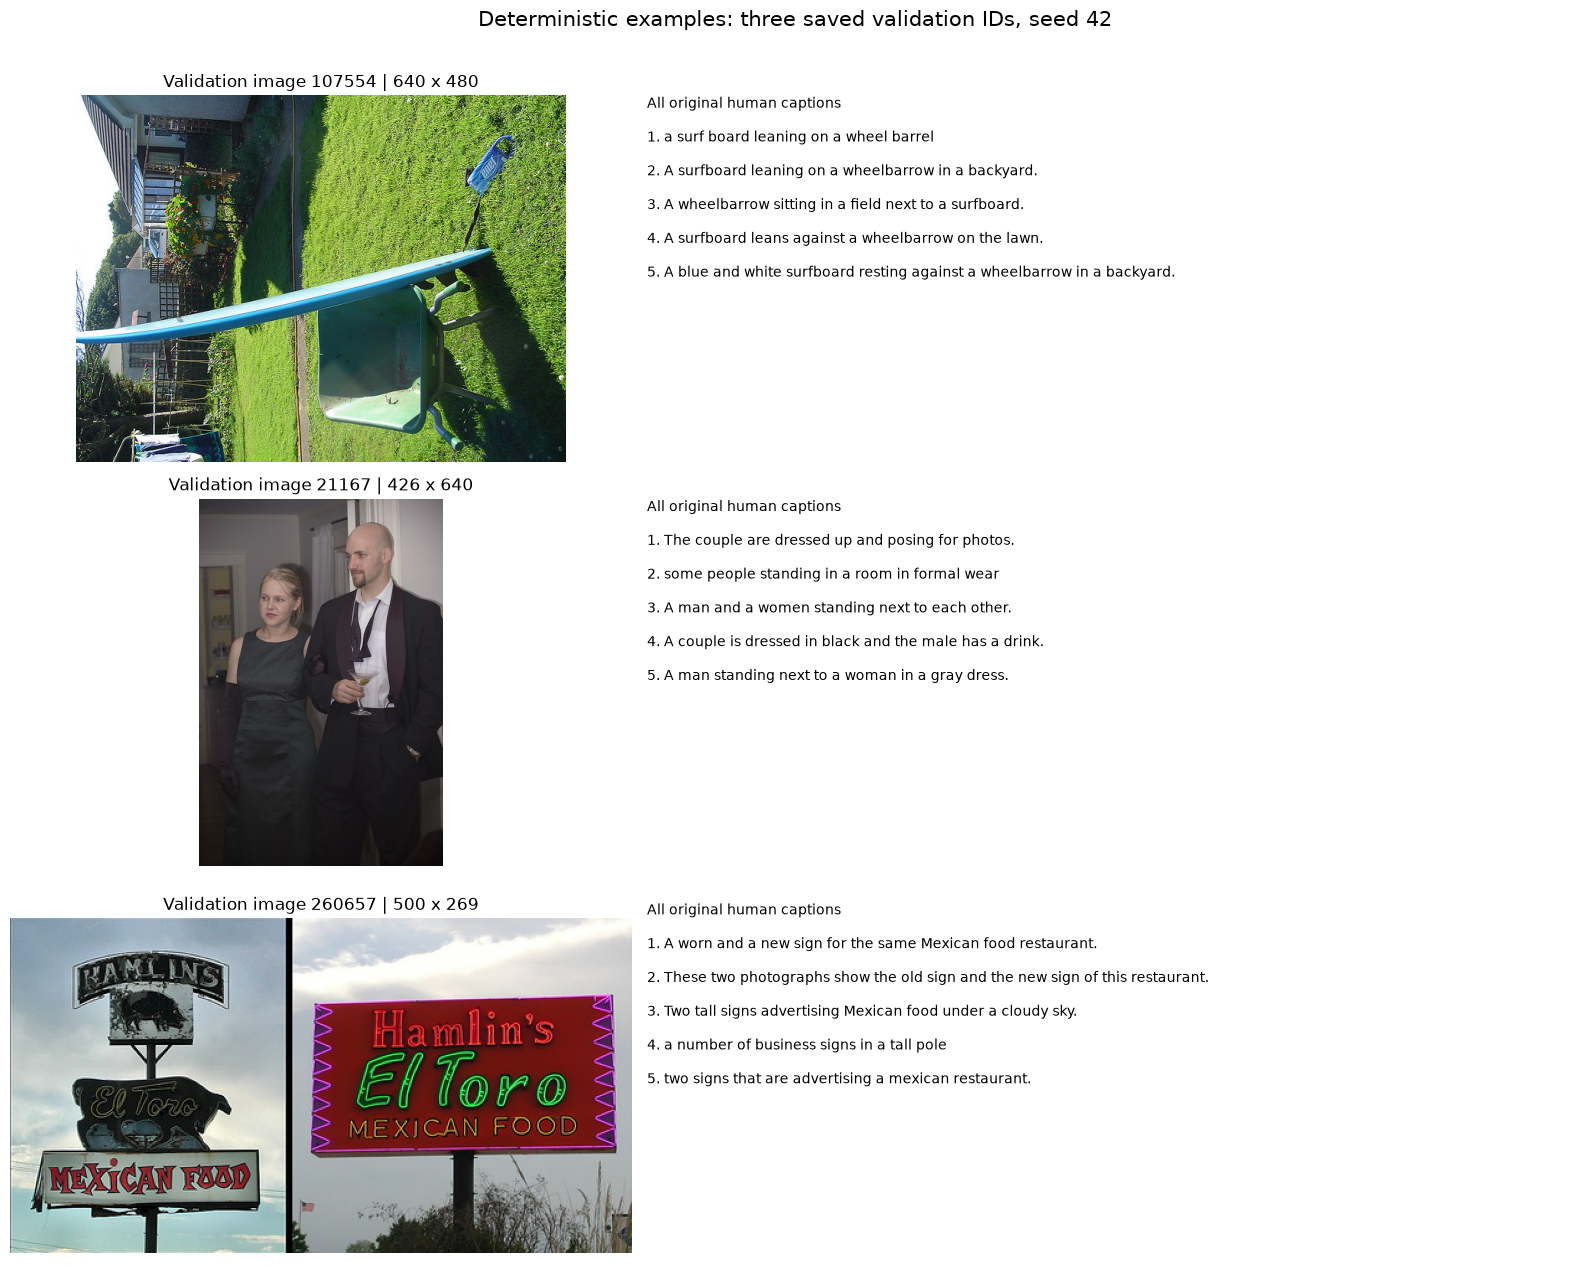

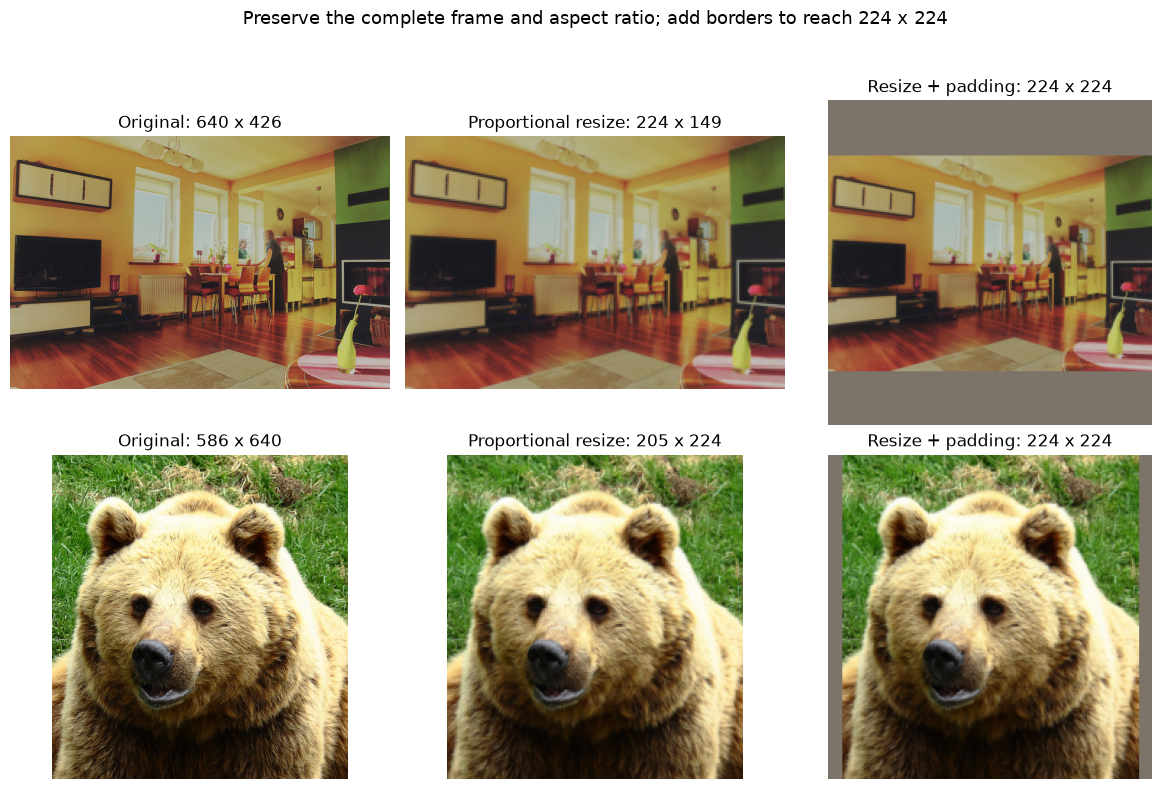

In [6]:
report_preparation(PROJECT_DIR,RAW_IMAGE_ROOT)
show_data_examples(PROJECT_DIR,RAW_IMAGE_ROOT);


## 2. Global image vectors: 75 models and four depth experiments

Five frozen CNNs were paired with RNN, LSTM and image-prefix Transformer decoders. Each pair used five profiles: baseline, smaller hidden size, two layers, higher dropout and image LayerNorm. That gives 75 runs. Four additional ResNet50 runs tested three and four layers for LSTM and Transformer.

The RNN/LSTM receive a projected image as the first recurrent step, then `<start>` and previous words. The visual step has no word target. The prefix Transformer instead receives the image as the first causal token. Adam, token-normalized cross entropy, clipping, fixed seeds, validation CIDEr-D early stopping, timers and resumable checkpoints are retained. Metrics use pycocoevalcap 1.2 with project tokenization: BLEU is 0–1 and CIDEr-D uses its native scale. These are not official leaderboard PTB-tokenized scores.

In [7]:
class CaptionDecoder(nn.Module):
    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        decoder="lstm",
        embedding_size=512,
        hidden_size=512,
        dropout=0.3,
        num_layers=1,
        image_layernorm=False,
    ):
        super().__init__()
        if decoder not in {"rnn","lstm"}:
            raise ValueError("Choose decoder='rnn' or decoder='lstm'.")

        self.decoder_type = decoder
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.pad_id = pad_id

        # Keep this trainable projection even when feature_dim is already 512.
        self.image_projection = nn.Linear(feature_dim,embedding_size)
        self.image_norm = nn.LayerNorm(embedding_size) if image_layernorm else nn.Identity()
        self.embedding = nn.Embedding(vocab_size,embedding_size,padding_idx=pad_id)
        self.embedding_dropout = nn.Dropout(dropout)

        if decoder == "rnn":
            self.recurrent = nn.RNN(
                embedding_size,
                hidden_size,
                num_layers=num_layers,
                nonlinearity="tanh",
                batch_first=True,
                bidirectional=False,
                dropout=0,
            )
        else:
            self.recurrent = nn.LSTM(
                embedding_size,
                hidden_size,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=False,
                dropout=0,
            )

        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size,vocab_size)

    def image_state(self,features):
        image_step = self.image_norm(self.image_projection(features)).unsqueeze(1)

        hidden = image_step.new_zeros(self.num_layers,len(features),self.hidden_size)
        initial = (hidden,torch.zeros_like(hidden)) if self.decoder_type == "lstm" else hidden

        # The visual output is discarded. Only the resulting state is retained.
        _,state = self.recurrent(image_step,initial)
        return state

    def forward(self,features,input_ids):
        state = self.image_state(features)

        words = self.embedding_dropout(self.embedding(input_ids))
        outputs,_ = self.recurrent(words,state)

        return self.output(self.output_dropout(outputs))

    @torch.no_grad()
    def greedy(self,features,start_id,end_id,max_steps=33):
        if max_steps < 1:
            raise ValueError("max_steps must be positive.")

        was_training = self.training
        self.eval()
        try:
            state = self.image_state(features)
            current = torch.full(
                (len(features),1),start_id,dtype=torch.long,device=features.device
            )
            finished = torch.zeros(len(features),dtype=torch.bool,device=features.device)
            predictions = [[] for _ in range(len(features))]

            for _ in range(max_steps):
                words = self.embedding_dropout(self.embedding(current))
                outputs,state = self.recurrent(words,state)
                logits = self.output(self.output_dropout(outputs[:,0]))

                # These control tokens must not appear inside a generated caption.
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)

                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)

                finished |= next_ids.eq(end_id)
                if finished.all():
                    break

                # Only a predicted token is fed back; references are never used here.
                current = next_ids.unsqueeze(1)

            return predictions
        finally:
            self.train(was_training)


In [8]:
class CaptionTransformer(nn.Module):
    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        d_model=512,
        num_layers=1,
        nhead=8,
        dim_feedforward=2048,
        dropout=0.3,
        image_layernorm=False,
        max_positions=34,
    ):
        super().__init__()
        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead.")
        if num_layers < 1 or max_positions < 2:
            raise ValueError("Use at least one layer and two positions.")

        self.decoder_type = "transformer"
        self.d_model = d_model
        self.hidden_size = d_model
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.max_positions = max_positions

        self.image_projection = nn.Linear(feature_dim,d_model)
        self.image_norm = nn.LayerNorm(d_model) if image_layernorm else nn.Identity()
        self.embedding = nn.Embedding(vocab_size,d_model,padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_positions,d_model)
        self.embedding_dropout = nn.Dropout(dropout)

        # Each block is constructed separately, so stacked layers start independently.
        # A causal mask makes these self-attention blocks an autoregressive decoder.
        self.layers = nn.ModuleList(
            [
                nn.TransformerEncoderLayer(
                    d_model=d_model,
                    nhead=nhead,
                    dim_feedforward=dim_feedforward,
                    dropout=dropout,
                    activation="relu",
                    batch_first=True,
                    norm_first=True,
                )
                for _ in range(num_layers)
            ]
        )
        self.final_norm = nn.LayerNorm(d_model)
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model,vocab_size)

        nn.init.normal_(self.embedding.weight,mean=0.0,std=0.02)
        nn.init.normal_(self.position_embedding.weight,mean=0.0,std=0.02)
        with torch.no_grad():
            self.embedding.weight[pad_id].zero_()

    def forward(self,features,input_ids):
        if features.ndim != 2 or input_ids.ndim != 2:
            raise ValueError("Expected feature and token batches with two dimensions.")
        if len(features) != len(input_ids) or input_ids.shape[1] < 1:
            raise ValueError("Each image needs a nonempty input token sequence.")

        image_token = self.image_norm(self.image_projection(features)).unsqueeze(1)
        words = self.embedding(input_ids) * self.d_model**0.5
        tokens = torch.cat([image_token,words],dim=1)
        length = tokens.shape[1]
        if length > self.max_positions:
            raise ValueError("The image prefix and input words exceed max_positions.")

        positions = torch.arange(length,device=input_ids.device)
        tokens = self.embedding_dropout(tokens + self.position_embedding(positions).unsqueeze(0))

        # True means blocked. No token can read a future token.
        causal_mask = torch.triu(
            torch.ones(length,length,dtype=torch.bool,device=input_ids.device),diagonal=1
        )
        # The image prefix is always visible; padded caption positions are never keys.
        image_is_padding = torch.zeros(len(input_ids),1,dtype=torch.bool,device=input_ids.device)
        padding_mask = torch.cat([image_is_padding,input_ids.eq(self.pad_id)],dim=1)

        for layer in self.layers:
            tokens = layer(tokens,src_mask=causal_mask,src_key_padding_mask=padding_mask)

        # The image token conditions the words but has no word-prediction target.
        word_outputs = self.final_norm(tokens[:,1:])
        return self.output(self.output_dropout(word_outputs))

    @torch.no_grad()
    def greedy(self,features,start_id,end_id,max_steps=33):
        if not 1 <= max_steps < self.max_positions:
            raise ValueError(
                "max_steps must fit the learned positions, including the image prefix."
            )

        was_training = self.training
        self.eval()
        try:
            prefix = torch.full(
                (len(features),1),start_id,dtype=torch.long,device=features.device
            )
            finished = torch.zeros(len(features),dtype=torch.bool,device=features.device)
            predictions = [[] for _ in range(len(features))]

            for _ in range(max_steps):
                # Recompute the short generated prefix; no ground-truth words are supplied.
                logits = self(features,prefix)[:,-1]
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)

                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                prefix = torch.cat([prefix,next_ids.unsqueeze(1)],dim=1)
            return predictions
        finally:
            self.train(was_training)


The training helpers below are grouped in `baseline` so their names cannot be overwritten by later experiments. Their model and optimizer logic is retained from the original notebook. Creating this namespace does not create a network or load feature arrays.

In [9]:
def make_baseline_stage(project_dir,raw_image_root):
    PROJECT_DIR=Path(project_dir)
    DATA_ROOT=Path(raw_image_root)
    TRAINING_ONLY=True
    RUN_TRAINING=False
    RUN_PREFLIGHT=False
    RUN_FINAL_TEST=False
    device=torch.device('cpu')
    LAPTOP_ID = "A"


    TRAIN_DECODERS = ["rnn","lstm","transformer"]


    TRAIN_VARIANTS = ["depth_3","depth_4"]  # None selects all assigned variants.


    RESULTS_ROOT = PROJECT_DIR / "experiments"


    TRANSFER_DIR = PROJECT_DIR / "transfer"


    CACHE_DIR = PROJECT_DIR / "cache"


    SEED = 42


    HOLDOUT_SIZE = 5000


    BATCH_SIZE = 64


    FEATURE_BATCH_SIZE = 64


    IMAGE_SIZE = 224


    MAX_CONTENT_TOKENS = 32


    CHECK_WORKERS = 8


    FORCE_IMAGE_CHECK = False


    FORCE_TEXT_PREP = False


    FORCE_FEATURES = False


    TRAIN_ENCODER = "resnet50"


    RUN_EXTRA_ENCODERS = True


    MODELS_TO_EXTRACT = ["resnet18","vgg19","mobilenet_v2","efficientnet_v2_s"]


    NEW_ENCODER_SETTINGS = {
        "resnet18": {
            "builder": resnet18,
            "weights": ResNet18_Weights.IMAGENET1K_V1,
            "dim": 512,
            "batch_size": 64,
        },
        "vgg19": {
            "builder": vgg19,
            "weights": VGG19_Weights.IMAGENET1K_V1,
            "dim": 4096,
            "batch_size": 32,
        },
        "mobilenet_v2": {
            "builder": mobilenet_v2,
            "weights": MobileNet_V2_Weights.IMAGENET1K_V2,
            "dim": 1280,
            "batch_size": 64,
        },
        "efficientnet_v2_s": {
            "builder": efficientnet_v2_s,
            "weights": EfficientNet_V2_S_Weights.IMAGENET1K_V1,
            "dim": 1280,
            "batch_size": 32,
        },
    }


    FEATURE_DIMS = {
        "resnet50": 2048,
        "resnet18": 512,
        "vgg19": 4096,
        "mobilenet_v2": 1280,
        "efficientnet_v2_s": 1280,
    }


    NORM_MEAN = (0.485,0.456,0.406)


    NORM_STD = (0.229,0.224,0.225)


    PAD_COLOR = tuple(round(value * 255) for value in NORM_MEAN)


    ANNOTATION_FILES = {
        "train2017": "captions_train2017.json",
        "val2017": "captions_val2017.json",
        "test2017": "image_info_test2017.json",
    }


    TEXT_SETTINGS = {
        "version": 1,
        "min_frequency": 5,
        "max_vocab_tokens": 10000,
        "special_tokens": ["<pad>","<unk>","<start>","<end>"],
        "token_pattern": r"[^\W_]+(?:'[^\W_]+)*|[^\w\s]",
    }


    ImageFile.LOAD_TRUNCATED_IMAGES = False


    RUN_GROUP = "all_encoders_v5_100epochs"


    EXPERIMENT_DIR = RESULTS_ROOT / RUN_GROUP


    LEARNING_RATE = 0.001


    MAX_EPOCHS = 100


    PATIENCE = 3


    TRAIN_SEED = 42


    IMPLEMENTATION_ID = "4999171d257bc83ebef0d7c6126b51135172373308b4fd9d66985e71de661475"


    TRANSFORMER_IMPLEMENTATION_ID = "097d3721f9bfe2111d91345835f0cfab782ed5f1bd9a52d3263ab945cb00cc91"

    def load_prepared_data(project_dir,data_root=None):
        project_dir = Path(project_dir)
        data_root = Path(data_root) if data_root is not None else project_dir / "data" / "coco2017"
        for source in ["train2017","val2017"]:
            annotation_path = data_root / "annotations" / f"captions_{source}.json"
            if not annotation_path.is_file():
                raise FileNotFoundError(
                    f"Missing {annotation_path}. Extract the shared training-data bundle beside "
                    "FinalAML.ipynb, or set DATA_ROOT to your existing COCO folder. "
                    "Raw photos are not required for training from saved vectors."
                )
        cache = project_dir / "cache"
        required = [
            "splits.json",
            "prepared.pkl",
            "text_report.json",
            "vocab.json",
            "image_audit.json",
            "test_captions.json",
        ]
        missing = [name for name in required if not (cache / name).is_file()]
        if missing:
            raise FileNotFoundError(
                f"Missing prepared files: {missing}. Extract the shared training-data bundle into PROJECT_DIR. "
                "For a new dataset, run this notebook with TRAINING_ONLY=False to prepare it."
            )

        # Load saved preparation results, then verify their versions agree.
        split_bytes = (cache / "splits.json").read_bytes()
        vocab_bytes = (cache / "vocab.json").read_bytes()
        prepared_bytes = (cache / "prepared.pkl").read_bytes()
        split_file = json.loads(split_bytes)
        vocab = json.loads(vocab_bytes)
        report = json.loads((cache / "text_report.json").read_text(encoding="utf-8"))
        audit = json.loads((cache / "image_audit.json").read_text(encoding="utf-8"))

        prepared_sha = hashlib.sha256(prepared_bytes).hexdigest()
        assert (
            prepared_sha == report["cache_sha256"]
        ),"Prepared caption cache changed. Rerun preparation."
        prepared = pickle.loads(
            prepared_bytes
        )  # This is our own cache, checked against its saved hash.
        del prepared_bytes

        split_ids = split_file["ids"]
        sources = split_file["feature_sources"]
        assert set(split_ids) == {"train","val","test"}
        assert sources == {
            "train": "train2017",
            "val": "val2017",
            "test": "train2017",
        },"Use the saved labeled split, not official test2017."
        payload = {"config": split_file["config"],"ids": split_ids,"feature_sources": sources}
        split_id = hashlib.sha256(
            json.dumps(payload,sort_keys=True,separators=(",",":")).encode()
        ).hexdigest()
        assert split_id == split_file["split_id"] == prepared["config"]["split_id"] == vocab["split_id"]

        source_id = split_file["config"]["source_id"]
        assert source_id == prepared["config"]["source_id"] == vocab["source_id"] == audit["source_id"]
        assert prepared["config"] == report["config"]
        assert audit["complete"] and not audit["image_errors"] and not audit["metadata_errors"]
        assert (
            prepared["token_to_id"] == vocab["token_to_id"]
            and prepared["id_to_token"] == vocab["id_to_token"]
        )
        assert vocab["token_to_id"] == {word: index for index,word in enumerate(vocab["id_to_token"])}

        ids = {
            name: vocab["token_to_id"][token]
            for name,token in [
                ("pad","<pad>"),
                ("unk","<unk>"),
                ("start","<start>"),
                ("end","<end>"),
            ]
        }
        assert len(set(ids.values())) == 4

        # One photograph and its exact duplicates must stay in one labeled split.
        sets = {name: set(values) for name,values in split_ids.items()}
        for name,values in split_ids.items():
            assert values == sorted(sets[name]) and values,f"Invalid or repeated IDs in {name}."
        for left,right in [("train","val"),("train","test"),("val","test")]:
            assert not sets[left] & sets[right],f"Image overlap: {left}/{right}."
        assert len(sets["test"]) == split_file["config"]["holdout_size"]

        owners = {
            (sources[name],image_id): name for name,values in sets.items() for image_id in values
        }
        for group in audit["pixel_duplicates"] + audit["file_duplicates"]:
            assigned = {owners[tuple(item)] for item in group if tuple(item) in owners}
            assert len(assigned) <= 1,"Exact duplicate photos cross the labeled splits."

        # Keep the original human references for evaluation.
        raw_by_source = {}
        source_image_ids = {}
        annotation_hashes = {}

        for source in ["train2017","val2017"]:
            annotation_bytes = (data_root / "annotations" / f"captions_{source}.json").read_bytes()
            annotation_hashes[source] = hashlib.sha256(annotation_bytes).hexdigest()
            annotation = json.loads(annotation_bytes)
            source_image_ids[source] = sorted(row["id"] for row in annotation["images"])
            assert len(source_image_ids[source]) == len(set(source_image_ids[source]))

            raw_by_source[source] = defaultdict(list)
            for row in annotation["annotations"]:
                assert (
                    isinstance(row["caption"],str) and row["caption"].strip()
                ),"Empty human reference."
                raw_by_source[source][row["image_id"]].append(row["caption"])
            assert set(raw_by_source[source]) == set(
                source_image_ids[source]
            ),"Missing human descriptions."

            if source == "train2017":
                saved_test = json.loads((cache / "test_captions.json").read_text(encoding="utf-8"))
                assert saved_test["split_id"] == split_id
                expected_test = [
                    row for row in annotation["annotations"] if row["image_id"] in sets["test"]
                ]
                assert (
                    saved_test["annotations"] == expected_test
                ),"Saved test references differ from the original human captions."
            del annotation_bytes,annotation

        assert sets["train"] | sets["test"] == set(source_image_ids["train2017"])
        assert sets["val"] == set(source_image_ids["val2017"])

        references = {
            name: {image_id: raw_by_source[sources[name]][image_id] for image_id in values}
            for name,values in split_ids.items()
        }
        tokens = {name: prepared[f"{name}_tokens"] for name in split_ids}
        for name,values in tokens.items():
            assert sorted(values) == split_ids[name]
            assert all(
                rows and all(row for row in rows) for rows in values.values()
            ),"Empty tokenized caption."
            if name != "train":
                assert all(
                    len(rows) == len(references[name][image_id]) for image_id,rows in values.items()
                ),"Evaluation references were dropped."

        # Test and validation captions must not contribute to the vocabulary.
        train_counts = Counter(
            token for rows in tokens["train"].values() for row in rows for token in row
        )
        assert train_counts == prepared["train_counts"]
        settings = prepared["config"]["settings"]
        regular = [
            token
            for token,count in sorted(train_counts.items(),key=lambda row: (-row[1],row[0]))
            if count >= settings["min_frequency"]
        ][: settings["max_vocab_tokens"]]
        assert (
            vocab["id_to_token"] == settings["special_tokens"] + regular
        ),"Vocabulary must be fitted on training captions only."

        data = {
            "project_dir": project_dir,
            "data_root": data_root,
            "split_ids": split_ids,
            "feature_sources": sources,
            "tokens": tokens,
            "references": references,
            "source_image_ids": source_image_ids,
            "token_to_id": vocab["token_to_id"],
            "id_to_token": vocab["id_to_token"],
            "ids": ids,
            "max_content_tokens": prepared["config"]["max_content_tokens"],
            "text_settings": settings,
            "provenance": {
                "source_id": source_id,
                "split_id": split_id,
                "prepared_sha256": prepared_sha,
                "vocab_sha256": hashlib.sha256(vocab_bytes).hexdigest(),
                "splits_sha256": hashlib.sha256(split_bytes).hexdigest(),
                "annotations_sha256": annotation_hashes,
            },
        }

        data["feature_files"] = {}
        for encoder in FEATURE_DIMS:
            data["feature_files"][encoder] = validate_feature_files(data,encoder)
        data["provenance"]["feature_cache_keys"] = {
            encoder: {source: entry["cache_key"] for source,entry in files.items()}
            for encoder,files in data["feature_files"].items()
        }

        print(
            "Verified disjoint labeled splits:",
            {name: len(values) for name,values in split_ids.items()},
        )
        print("Vocabulary:",len(data["id_to_token"]),"| special IDs:",ids)
        return data


    def validate_feature_files(data,encoder):
        if encoder not in FEATURE_DIMS:
            raise ValueError("Choose an encoder listed in FEATURE_DIMS.")

        directory = data["project_dir"] / "cache" / "features"
        if encoder != "resnet50":
            directory = directory / encoder

        files = {}
        for source in sorted(set(data["feature_sources"].values())):
            path = directory / f"{source}.npy"
            meta = json.loads((directory / f"{source}_meta.json").read_text(encoding="utf-8"))
            image_ids = json.loads((directory / f"{source}_image_ids.json").read_text(encoding="utf-8"))
            expected_shape = [len(data["source_image_ids"][source]),FEATURE_DIMS[encoder]]

            assert meta["complete"] and meta["config"]["source_id"] == data["provenance"]["source_id"]
            assert (
                hashlib.sha256(json.dumps(meta["config"],sort_keys=True).encode()).hexdigest()
                == meta["cache_key"]
            )
            assert image_ids == data["source_image_ids"][source] and meta["shape"] == expected_shape
            assert meta["dtype"] == "float32" and path.stat().st_size == meta["feature_file_bytes"]

            # Read the array header without loading all vectors into RAM.
            matrix = np.load(path,mmap_mode="r",allow_pickle=False)
            try:
                assert list(matrix.shape) == expected_shape and matrix.dtype == np.float32
            finally:
                matrix._mmap.close()

            files[source] = {
                "path": path,
                "image_ids": image_ids,
                "cache_key": meta["cache_key"],
                "shape": expected_shape,
            }
        return files


    class CachedCaptionDataset(Dataset):
        def __init__(self,data,encoder,split,seed=42):
            if split not in ["train","val","test"]:
                raise ValueError("Use the project's train, val or labeled test.")

            self.data = data
            self.encoder = encoder
            self.split = split
            self.seed = seed
            self.image_ids = data["split_ids"][split]
            self.feature_dim = FEATURE_DIMS[encoder]

            source = data["feature_sources"][split]
            saved = data["feature_files"][encoder][source]
            self.features = np.load(saved["path"],mmap_mode="r",allow_pickle=False)
            self.feature_rows = {image_id: index for index,image_id in enumerate(saved["image_ids"])}
            self.set_epoch(0)

        def set_epoch(self,epoch):
            self.epoch = int(epoch)

            # A private RNG keeps caption selection independent of model dropout.
            rng = random.Random(self.seed + self.epoch)
            self.caption_choices = [
                (
                    rng.randrange(len(self.data["tokens"][self.split][image_id]))
                    if self.split == "train"
                    else 0
                )
                for image_id in self.image_ids
            ]

        def __len__(self):
            return len(self.image_ids)

        def __getitem__(self,index):
            image_id = self.image_ids[index]
            tokens = self.data["tokens"][self.split][image_id][self.caption_choices[index]]

            ids = self.data["ids"]
            caption = (
                [ids["start"]]
                + [
                    self.data["token_to_id"].get(token,ids["unk"])
                    for token in tokens[: self.data["max_content_tokens"]]
                ]
                + [ids["end"]]
            )

            vector = torch.from_numpy(self.features[self.feature_rows[image_id]].copy())
            return {
                "features": vector,
                "caption": torch.tensor(caption,dtype=torch.long),
                "image_id": image_id,
                "references": self.data["references"][self.split][image_id],
            }

        def close(self):
            if self.features is not None:
                self.features._mmap.close()
                self.features = None


    def cached_caption_collate(batch,pad_id):
        captions = [item["caption"] for item in batch]

        return {
            "features": torch.stack([item["features"] for item in batch]),
            "captions": pad_sequence(captions,batch_first=True,padding_value=pad_id),
            "lengths": torch.tensor([len(caption) for caption in captions],dtype=torch.long),
            "image_ids": [item["image_id"] for item in batch],
            "references": [item["references"] for item in batch],
        }


    def tokens_to_text(token_ids,id_to_token):
        skipped = {"<pad>","<start>","<end>"}
        return " ".join(
            id_to_token[int(index)] for index in token_ids if id_to_token[int(index)] not in skipped
        )


    def check_caption_shift(caption_ids,ids):
        # Example: <start> a cat <end> -> inputs <start> a cat; targets a cat <end>.
        values = [int(value) for value in caption_ids if int(value) != ids["pad"]]
        assert len(values) >= 2 and values[0] == ids["start"] and values[-1] == ids["end"]

        inputs = values[:-1]
        targets = values[1:]
        assert len(inputs) == len(targets) == len(values) - 1
        assert inputs[0] == ids["start"] and targets[-1] == ids["end"]

        return {"caption": values,"input": inputs,"target": targets,"text_length": len(values) - 1}


    def smoke_model_check(batch,data,config,device):
        model = build_model(data,config,device)
        ids = data["ids"]
        vocab_size = len(data["id_to_token"])
        feature_dim = FEATURE_DIMS[config["encoder"]]
        features = batch["features"].to(device)
        captions = batch["captions"].to(device)

        inputs = captions[:,:-1]
        targets = captions[:,1:]
        token_count = int(targets.ne(ids["pad"]).sum())
        assert token_count > 0

        transformer_checks = None
        if config["decoder"] == "transformer":
            transformer_checks = check_transformer_masks(model,features,ids)
        else:
            with torch.no_grad():
                state = model.image_state(features)
                expected_state = (config["num_layers"],len(features),config["hidden_size"])
                if config["decoder"] == "lstm":
                    assert state[0].shape == state[1].shape == expected_state
                else:
                    assert state.shape == expected_state

        logits = model(features,inputs)
        assert logits.shape == (*targets.shape,vocab_size) and torch.isfinite(logits).all()
        criterion = nn.CrossEntropyLoss(ignore_index=ids["pad"],reduction="sum")
        loss = criterion(logits.reshape(-1,vocab_size),targets.reshape(-1)) / token_count

        loss.backward()
        for name,parameter in model.named_parameters():
            assert parameter.grad is not None,f"Missing gradient: {name}"
            assert torch.isfinite(parameter.grad).all(),f"Invalid gradient: {name}"
        assert model.embedding.weight.grad[ids["pad"]].eq(0).all()
        assert model.image_projection.weight.grad.abs().sum() > 0
        if config["image_layernorm"]:
            assert model.image_norm.weight.grad.abs().sum() > 0
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(),5.0)

        generated = model.greedy(features[:2],ids["start"],ids["end"],max_steps=8)
        assert all(
            ids["pad"] not in row and ids["start"] not in row and ids["end"] not in row
            for row in generated
        )

        result = {
            "decoder": config["decoder"],
            "variant": config["variant"],
            "hidden_size": config["hidden_size"],
            "num_layers": config["num_layers"],
            "image_layernorm": config["image_layernorm"],
            "feature_dim": feature_dim,
            "batch_size": len(features),
            "loss": float(loss.detach()),
            "target_tokens": token_count,
            "gradient_norm_before_clip": float(grad_norm),
            "trainable_parameters": sum(
                parameter.numel() for parameter in model.parameters() if parameter.requires_grad
            ),
            "output_shape": list(logits.shape),
            "generation_lengths": [len(row) for row in generated],
            "transformer_checks": transformer_checks,
            "passed": True,
        }
        del model,logits,loss,features,captions
        return result


    def overfit_small_set(batch,data,config,device):
        # Keep the experiment's architecture; disable dropout only for this wiring check.
        test_config = dict(config)
        test_config["dropout"] = 0.0
        model = build_model(data,test_config,device)
        ids = data["ids"]
        vocab_size = len(data["id_to_token"])
        feature_dim = FEATURE_DIMS[config["encoder"]]
        max_steps = config["overfit_steps"]
        learning_rate = config["learning_rate"]
        target_loss = config["overfit_target_loss"]
        optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)
        criterion = nn.CrossEntropyLoss(ignore_index=ids["pad"],reduction="sum")

        features = batch["features"].to(device)
        captions = batch["captions"].to(device)

        inputs = captions[:,:-1]
        targets = captions[:,1:]
        token_count = int(targets.ne(ids["pad"]).sum())
        assert token_count > 0 and max_steps > 0

        references = []
        for row in captions.tolist():
            references.append(
                [token for token in row if token not in {ids["pad"],ids["start"],ids["end"]}]
            )

        start = time.perf_counter()
        initial_loss = None
        checks = []
        passed = False

        for step in range(1,max_steps + 1):
            model.train()
            optimizer.zero_grad(set_to_none=True)

            logits = model(features,inputs)
            loss = criterion(logits.reshape(-1,vocab_size),targets.reshape(-1)) / token_count
            assert torch.isfinite(loss),"Non-finite small-set loss."
            if initial_loss is None:
                initial_loss = float(loss.detach())

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.0)
            optimizer.step()

            if step % 25 == 0 or step == max_steps:
                model.eval()
                with torch.no_grad():
                    logits = model(features,inputs)
                    checked_loss = float(
                        criterion(logits.reshape(-1,vocab_size),targets.reshape(-1)) / token_count
                    )
                    mask = targets.ne(ids["pad"])
                    token_accuracy = float(logits.argmax(-1).eq(targets)[mask].float().mean())

                generated = model.greedy(
                    features,ids["start"],ids["end"],max_steps=captions.shape[1] - 1
                )
                exact = sum(
                    prediction == reference for prediction,reference in zip(generated,references)
                ) / len(references)

                checks.append(
                    {
                        "step": step,
                        "loss": checked_loss,
                        "teacher_forced_token_accuracy": token_accuracy,
                        "greedy_exact_match": exact,
                    }
                )
                print(
                    f"{config['decoder']} / {config['variant']} small-set step {step}: "
                    f"loss={checked_loss:.4f}, token accuracy={token_accuracy:.1%}, greedy exact={exact:.1%}",
                    flush=True,
                )
                if checked_loss <= target_loss and exact == 1.0:
                    passed = True
                    break

        if device.type == "cuda":
            torch.cuda.synchronize(device)

        result = {
            "decoder": config["decoder"],
            "variant": config["variant"],
            "hidden_size": config["hidden_size"],
            "num_layers": config["num_layers"],
            "image_layernorm": config["image_layernorm"],
            "feature_dim": feature_dim,
            "images": len(features),
            "dropout": 0,
            "learning_rate": learning_rate,
            "steps": step,
            "initial_loss": initial_loss,
            "final_loss": checks[-1]["loss"],
            "greedy_exact_match": checks[-1]["greedy_exact_match"],
            "teacher_forced_token_accuracy": checks[-1]["teacher_forced_token_accuracy"],
            "elapsed_seconds": time.perf_counter() - start,
            "passed": passed,
            "checks": checks,
            "note": "This temporary model is discarded. Re-seed and create a new model for the real experiment.",
        }
        del model,optimizer,logits,loss,features,captions
        return result


    @torch.no_grad()
    def check_transformer_masks(model,features,ids):
        # Test the actual temporary model before using a fresh one for training.
        was_training = model.training
        model.eval()
        try:
            words = [
                index for index in range(model.embedding.num_embeddings) if index not in ids.values()
            ][:3]
            assert len(words) == 3 and model.max_positions >= 7
            features = features[:2]
            probe = torch.tensor([ids["start"],*words],device=features.device).repeat(
                len(features),1
            )
            original = model(features,probe)
            tolerance = 0.005 if original.dtype in [torch.float16,torch.bfloat16] else 1e-5

            future_changed = probe.clone()
            future_changed[:,2:] = probe[:,2:].flip(1)
            changed = model(features,future_changed)
            assert torch.allclose(
                original[:,:2],changed[:,:2],atol=tolerance,rtol=tolerance
            ),"Future tokens leaked into earlier predictions."

            padded = torch.cat(
                [probe,torch.full((len(probe),2),ids["pad"],device=probe.device)],dim=1
            )
            assert torch.allclose(
                original,model(features,padded)[:,:4],atol=tolerance,rtol=tolerance
            ),"Right padding changed valid predictions."

            # An internal PAD tests key masking independently of the causal mask.
            internal_pad = probe.clone()
            internal_pad[:,1] = ids["pad"]
            before = model(features,internal_pad)[:,[0,2,3]]
            saved_pad = model.embedding.weight[ids["pad"]].clone()
            try:
                model.embedding.weight[ids["pad"]].copy_(
                    torch.linspace(-4,4,model.d_model,device=features.device)
                )
                after = model(features,internal_pad)[:,[0,2,3]]
                assert torch.allclose(
                    before,after,atol=tolerance,rtol=tolerance
                ),"A masked PAD token influenced valid predictions."
            finally:
                model.embedding.weight[ids["pad"]].copy_(saved_pad)

            other_features = torch.zeros_like(features)
            if torch.equal(other_features,features):
                other_features = torch.ones_like(features)
            other_logits = model(other_features,probe)
            assert (
                original - other_logits
            ).abs().max() > 1e-6,"Predictions do not depend on the image."

            if len(model.layers) > 1:
                first = model.layers[0].linear1.weight
                second = model.layers[1].linear1.weight
                assert first.data_ptr() != second.data_ptr() and not torch.equal(first,second)

            return {
                "causal_mask": True,
                "padding_mask": True,
                "image_conditioning": True,
                "independent_stacked_layers": True,
                "passed": True,
            }
        finally:
            model.train(was_training)


    class MetricEvaluator:
        def __init__(self,settings):
            version = package_metadata.version("pycocoevalcap")
            if version != "1.2":
                raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
            self.token_pattern = settings["token_pattern"]
            re.compile(self.token_pattern)
            self.metadata = {
                "package": "pycocoevalcap",
                "version": version,
                "bleu": {
                    "implementation": "Bleu(4)",
                    "aggregation": "corpus",
                    "scale": "0..1; no multiplication by 100",
                },
                "cider_d": {
                    "implementation": "Cider(n=4,sigma=6.0)",
                    "ngrams": 4,
                    "sigma": 6.0,
                    "scale": "native score, including the implementation's factor 10; no extra multiplication",
                    "document_frequency": "all reference sets in the evaluated split",
                },
                "tokenization": {
                    "name": "project_regex_v1",
                    "normalization": "NFKC,lowercase,smart quotes,whitespace",
                    "token_pattern": self.token_pattern,
                    "reference_vocabulary_mapping": False,
                    "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
                },
                "source_sha256": {
                    name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                    for name,cls in [
                        ("bleu",Bleu),
                        ("bleu_scorer",BleuScorer),
                        ("cider",Cider),
                        ("cider_scorer",CiderScorer),
                    ]
                },
            }

        def tokenize(self,text):
            text = unicodedata.normalize("NFKC",text).lower()
            text = text.translate(
                str.maketrans(
                    {
                        "\u2018": "'",
                        "\u2019": "'",
                        "\u02bc": "'",
                        "\u201c": '"',
                        "\u201d": '"',
                        "\u200b": " ",
                        "\ufeff": " ",
                    }
                )
            )
            text = " ".join(text.split())
            return " ".join(re.findall(self.token_pattern,text))

        def score(self,records,expected_ids=None):
            # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
            if len(records) < 2:
                raise ValueError("CIDEr-D needs a corpus with at least two images.")
            gts = {}
            res = {}
            for item in records:
                image_id = int(item["image_id"])
                if image_id in gts:
                    raise ValueError(f"Duplicate prediction for image {image_id}")
                references = item["references"]
                if not isinstance(references,list) or not references:
                    raise ValueError(f"Missing human references for image {image_id}")
                if not all(isinstance(text,str) and text.strip() for text in references):
                    raise ValueError(f"Empty or invalid human reference for image {image_id}")
                if not isinstance(item["prediction"],str):
                    raise TypeError("Each prediction must be a string.")
                gts[image_id] = [self.tokenize(text) for text in references]
                if not all(gts[image_id]):
                    raise ValueError(f"A reference has no tokens for image {image_id}")
                res[image_id] = [self.tokenize(item["prediction"])]
            if expected_ids is not None:
                expected = [int(image_id) for image_id in expected_ids]
                if len(expected) != len(set(expected)) or set(gts) != set(expected):
                    raise ValueError("Predictions do not cover exactly the requested evaluation split.")
            bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
            cider_d,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
            scores = {"bleu1": float(bleu[0]),"bleu4": float(bleu[3]),"cider_d": float(cider_d)}
            if not all(np.isfinite(value) for value in scores.values()):
                raise ValueError("The metric implementation returned a non-finite score.")
            return scores


    def check_metrics(evaluator):
        # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
        sentences = [
            "A red bus drives down the road.",
            "Two cats sleep on the green sofa.",
            "A woman holds a yellow umbrella.",
        ]
        records = [
            {"image_id": index,"prediction": text,"references": [text,text]}
            for index,text in enumerate(sentences)
        ]
        exact = evaluator.score(records,expected_ids=range(len(records)))
        assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
        assert abs(exact["cider_d"] - 10) < 1e-6
        unrelated = [
            {**row,"prediction": "unrelated vocabulary never matches anything"} for row in records
        ]
        poor = evaluator.score(unrelated)
        assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
        empty = evaluator.score([{**row,"prediction": ""} for row in records])
        assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
        # These are library corpus scores, not sentence scores averaged by our code.
        gts = {
            row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
        }
        res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
        direct_bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
        direct_cider,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
        assert exact == {
            "bleu1": float(direct_bleu[0]),
            "bleu4": float(direct_bleu[3]),
            "cider_d": float(direct_cider),
        }
        try:
            evaluator.score(records,expected_ids=[0,1,99])
        except ValueError:
            pass
        else:
            raise AssertionError("Incomplete evaluation corpus was accepted.")
        print(
            "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
        )
        return {"exact": exact,"unrelated": poor,"empty_predictions": empty}


    MODEL_VARIANTS = {
        "baseline": {"hidden_size": 512,"num_layers": 1,"dropout": 0.3,"image_layernorm": False},
        "small_hidden": {"hidden_size": 256,"num_layers": 1,"dropout": 0.3,"image_layernorm": False},
        "stacked": {"hidden_size": 512,"num_layers": 2,"dropout": 0.3,"image_layernorm": False},
        "high_dropout": {"hidden_size": 512,"num_layers": 1,"dropout": 0.5,"image_layernorm": False},
        "image_layernorm": {
            "hidden_size": 512,
            "num_layers": 1,
            "dropout": 0.3,
            "image_layernorm": True,
        },
    }


    TRANSFORMER_VARIANTS = {
        "baseline": {"hidden_size": 512,"num_layers": 1,"dropout": 0.3,"image_layernorm": False},
        "small_hidden": {"hidden_size": 256,"num_layers": 1,"dropout": 0.3,"image_layernorm": False},
        "stacked": {"hidden_size": 512,"num_layers": 2,"dropout": 0.3,"image_layernorm": False},
        "high_dropout": {"hidden_size": 512,"num_layers": 1,"dropout": 0.5,"image_layernorm": False},
        "image_layernorm": {
            "hidden_size": 512,
            "num_layers": 1,
            "dropout": 0.3,
            "image_layernorm": True,
        },
    }


    DEPTH_VARIANTS = {
        "depth_3": {"hidden_size": 512,"num_layers": 3,"dropout": 0.3,"image_layernorm": False},
        "depth_4": {"hidden_size": 512,"num_layers": 4,"dropout": 0.3,"image_layernorm": False},
    }


    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True,warn_only=True)


    def make_recurrent_config(encoder="resnet50",decoder="lstm",variant="baseline",**changes):
        if variant in DEPTH_VARIANTS:
            if encoder != "resnet50" or decoder != "lstm":
                raise ValueError("Depth variants require ResNet50 with LSTM or Transformer.")
            settings = DEPTH_VARIANTS[variant]
        elif variant in MODEL_VARIANTS:
            settings = MODEL_VARIANTS[variant]
        else:
            raise ValueError(f"Unknown model variant: {variant}")

        config = {
            "encoder": encoder,
            "decoder": decoder,
            "variant": variant,
            "seed": TRAIN_SEED,
            "embedding_size": 512,
            **settings,
            # Keep this at zero even for stacked: only layer count changes in that variant.
            "recurrent_dropout": 0.0,
            "learning_rate": LEARNING_RATE,
            "batch_size": BATCH_SIZE,
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE,
            "gradient_clip": 5.0,
            "amp": True,
            "max_generation_steps": 33,
            "checkpoint_every_batches": 200,
            "print_every_batches": 100,
            "overfit_images": 4,
            # Deeper models may need more steps in the temporary four-image check.
            "overfit_steps": 2000 if variant in DEPTH_VARIANTS else 200,
            "overfit_target_loss": 0.1,
            "run_name": None,
        }
        unknown = set(changes) - set(config)
        if unknown:
            raise ValueError(f"Unknown settings: {unknown}")
        config.update(changes)
        if variant in DEPTH_VARIANTS and (
            config["encoder"] != "resnet50" or config["decoder"] != "lstm"
        ):
            raise ValueError("Recurrent depth variants require ResNet50 with LSTM.")
        assert config["encoder"] in FEATURE_DIMS and config["decoder"] in ["rnn","lstm"]
        assert config["embedding_size"] == 512 and config["recurrent_dropout"] == 0
        for setting,expected in settings.items():
            assert config[setting] == expected,f"{setting} does not match variant {variant}."
        for name in ["max_epochs","batch_size","patience"]:
            value = config[name]
            if type(value) is not int or value < 1:
                raise ValueError(f"{name} must be a positive integer, got {value!r}.")
        assert config["checkpoint_every_batches"] > 0 and config["print_every_batches"] > 0
        if config["run_name"] is None:
            config["run_name"] = (
                f"{config['encoder']}_{config['decoder']}_{variant}_seed{config['seed']}"
            )
        return config


    def make_transformer_config(encoder="resnet50",variant="baseline",**changes):
        if variant in DEPTH_VARIANTS:
            if encoder != "resnet50":
                raise ValueError("Transformer depth variants require ResNet50.")
            settings = DEPTH_VARIANTS[variant]
        elif variant in TRANSFORMER_VARIANTS:
            settings = TRANSFORMER_VARIANTS[variant]
        else:
            raise ValueError(f"Unknown Transformer variant: {variant}")
        width = settings["hidden_size"]
        architecture = {
            "decoder": "transformer",
            "architecture": "image_prefix_causal",
            "position_encoding": "learned",
            "embedding_size": width,
            "d_model": width,
            **settings,
            "nhead": 8,
            "dim_feedforward": 2048,
            "max_positions": 34,
            "norm_first": True,
        }
        config = {
            "encoder": encoder,
            "variant": variant,
            "seed": TRAIN_SEED,
            **architecture,
            "learning_rate": LEARNING_RATE,
            "batch_size": BATCH_SIZE,
            "max_epochs": MAX_EPOCHS,
            "patience": PATIENCE,
            "gradient_clip": 5.0,
            "amp": True,
            "max_generation_steps": 33,
            "checkpoint_every_batches": 200,
            "print_every_batches": 100,
            "overfit_images": 4,
            "overfit_steps": 2000 if variant in DEPTH_VARIANTS else 200,
            "overfit_target_loss": 0.1,
            "run_name": None,
        }
        unknown = set(changes) - set(config)
        if unknown:
            raise ValueError(f"Unknown settings: {unknown}")
        config.update(changes)
        if variant in DEPTH_VARIANTS and config["encoder"] != "resnet50":
            raise ValueError("Transformer depth variants require ResNet50.")
        if config["encoder"] not in FEATURE_DIMS:
            raise ValueError(f"Unknown encoder: {config['encoder']}")
        for name,expected in architecture.items():
            if config[name] != expected:
                raise ValueError(f"{name} does not match Transformer variant {variant}.")
        for name in [
            "max_epochs",
            "batch_size",
            "patience",
            "max_generation_steps",
            "checkpoint_every_batches",
            "print_every_batches",
            "overfit_images",
            "overfit_steps",
        ]:
            value = config[name]
            if type(value) is not int or value < 1:
                raise ValueError(f"{name} must be a positive integer, got {value!r}.")
        if config["max_generation_steps"] >= config["max_positions"]:
            raise ValueError("max_generation_steps must leave one position for the image prefix.")
        if config["run_name"] is None:
            config["run_name"] = f"{config['encoder']}_transformer_{variant}_seed{config['seed']}"
        return config


    def make_config(encoder="resnet50",decoder="lstm",variant="baseline",**changes):
        if decoder == "transformer":
            return make_transformer_config(encoder,variant,**changes)
        return make_recurrent_config(encoder,decoder,variant,**changes)


    def implementation_for(config):
        if config["decoder"] == "transformer":
            return TRANSFORMER_IMPLEMENTATION_ID
        return IMPLEMENTATION_ID


    def build_model(data,config,device):
        if config["decoder"] == "transformer":
            return CaptionTransformer(
                FEATURE_DIMS[config["encoder"]],
                len(data["id_to_token"]),
                data["ids"]["pad"],
                d_model=config["d_model"],
                num_layers=config["num_layers"],
                nhead=config["nhead"],
                dim_feedforward=config["dim_feedforward"],
                dropout=config["dropout"],
                image_layernorm=config["image_layernorm"],
                max_positions=config["max_positions"],
            ).to(device)
        return CaptionDecoder(
            FEATURE_DIMS[config["encoder"]],
            len(data["id_to_token"]),
            data["ids"]["pad"],
            decoder=config["decoder"],
            embedding_size=config["embedding_size"],
            hidden_size=config["hidden_size"],
            dropout=config["dropout"],
            num_layers=config["num_layers"],
            image_layernorm=config["image_layernorm"],
        ).to(device)


    def device_details(device):
        return {
            "device": str(device),
            "name": torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
            "torch": torch.__version__,
            "cuda_runtime": torch.version.cuda,
        }


    def format_time(seconds):
        seconds = max(0,int(round(seconds)))
        hours,remainder = divmod(seconds,3600)
        minutes,seconds = divmod(remainder,60)
        return f"{hours:02d}:{minutes:02d}:{seconds:02d}"


    def save_weights(path,model):
        # Plain weights for inference. Resume training with the full best.pt/last.pt checkpoint.
        path = Path(path)
        temporary = path.with_suffix(".pt.tmp")
        torch.save(model.state_dict(),temporary)
        temporary.replace(path)


    def save_json(path,value):
        path = Path(path)
        path.parent.mkdir(parents=True,exist_ok=True)
        temporary = path.with_suffix(path.suffix + ".tmp")
        temporary.write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding="utf-8")
        temporary.replace(path)


    def rng_state():
        return {
            "python": random.getstate(),
            "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        }


    def restore_rng(state):
        random.setstate(state["python"])
        np.random.set_state(state["numpy"])
        torch.set_rng_state(state["torch"])
        if torch.cuda.is_available() and state["cuda"] is not None:
            torch.cuda.set_rng_state_all(state["cuda"])


    def experiment_identity(data,config,evaluator):
        return {
            "implementation": implementation_for(config),
            "config": config,
            "data": data["provenance"],
            "metrics": evaluator.metadata,
            "feature_dim": FEATURE_DIMS[config["encoder"]],
            "split_sizes": {name: len(values) for name,values in data["split_ids"].items()},
        }


    def make_loader(dataset,batch_size,indices=None,seed=42):
        selected = dataset if indices is None else Subset(dataset,indices)
        # Its private generator does not consume the model's RNG when an iterator starts.
        return DataLoader(
            selected,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            collate_fn=partial(cached_caption_collate,pad_id=dataset.data["ids"]["pad"]),
            pin_memory=torch.cuda.is_available(),
            generator=torch.Generator().manual_seed(seed),
        )


    def training_order(size,seed,epoch):
        return torch.randperm(size,generator=torch.Generator().manual_seed(seed + epoch)).tolist()


    def run_preflight(data,config,device,check_dir):
        check_dir = Path(check_dir)
        identity = {
            "implementation": implementation_for(config),
            "config": config,
            "data": data["provenance"],
            "device": device_details(device),
        }
        key = hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()
        path = (
            check_dir / f"{config['encoder']}_{config['decoder']}_{config['variant']}_{key[:12]}.json"
        )
        if path.exists():
            saved = json.loads(path.read_text(encoding="utf-8"))
            if saved["identity"] == identity and saved["passed"]:
                print("Loaded successful batch/backward/greedy and small-set checks.")
                return saved
        seed_everything(config["seed"])
        dataset = CachedCaptionDataset(data,config["encoder"],"train",config["seed"])
        try:
            batch = next(iter(make_loader(dataset,config["batch_size"],seed=config["seed"])))
            smoke = smoke_model_check(batch,data,config,device)
            # A short fixed caption per image makes this a quick wiring check, not an experiment.
            chosen = [
                index
                for index,image_id in enumerate(dataset.image_ids)
                if len(data["tokens"]["train"][image_id][0]) <= 12
            ][: config["overfit_images"]]
            assert len(chosen) == config["overfit_images"]
            dataset.caption_choices = [0] * len(dataset)
            tiny = next(iter(make_loader(dataset,len(chosen),chosen,seed=config["seed"])))
            seed_everything(config["seed"])
            overfit = overfit_small_set(tiny,data,config,device)
            result = {
                "identity": identity,
                "smoke": smoke,
                "overfit": overfit,
                "image_ids": tiny["image_ids"],
                "passed": bool(smoke["passed"] and overfit["passed"]),
            }
            save_json(path,result)
            if not result["passed"]:
                raise RuntimeError(
                    "Small-set memorization did not pass. Inspect its saved report before full training."
                )
            return result
        finally:
            dataset.close()


    @torch.no_grad()
    def evaluate_model(model,dataset,data,config,device,evaluator):
        if dataset.split not in ["val","test"]:
            raise ValueError("Evaluation uses validation or the labeled test.")
        model.eval()

        criterion = nn.CrossEntropyLoss(ignore_index=data["ids"]["pad"],reduction="sum")
        total_loss = 0.0
        total_tokens = 0
        records = []
        amp_enabled = config["amp"] and device.type == "cuda"
        for batch in make_loader(dataset,config["batch_size"],seed=config["seed"]):
            features = batch["features"].to(device,non_blocking=True)
            captions = batch["captions"].to(device,non_blocking=True)
            targets = captions[:,1:]

            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=amp_enabled):
                logits = model(features,captions[:,:-1])
                loss_sum = criterion(logits.reshape(-1,len(data["id_to_token"])),targets.reshape(-1))
                predicted = model.greedy(
                    features,data["ids"]["start"],data["ids"]["end"],config["max_generation_steps"]
                )

            total_loss += float(loss_sum)
            total_tokens += int(targets.ne(data["ids"]["pad"]).sum())
            for image_id,token_ids,references in zip(
                batch["image_ids"],predicted,batch["references"]
            ):
                records.append(
                    {
                        "image_id": image_id,
                        "prediction": tokens_to_text(token_ids,data["id_to_token"]),
                        "token_ids": token_ids,
                        "references": references,
                    }
                )
        assert total_tokens > 0 and len(records) == len(dataset)
        scores = evaluator.score(records,expected_ids=data["split_ids"][dataset.split])
        return {"loss": total_loss / total_tokens,**scores},records


    def write_checkpoint(path,model,optimizer,scaler,state,identity):
        # Call only between complete optimizer steps. An interrupted temporary write is ignored.
        checkpoint = {
            "format_version": 1,
            "identity": identity,
            "state": state,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "rng": rng_state(),
            "order_seed": identity["config"]["seed"] + state["epoch"],
            "caption_seed": identity["config"]["seed"] + state["epoch"],
        }
        path = Path(path)
        temporary = path.with_suffix(".pt.tmp")
        torch.save(checkpoint,temporary)
        temporary.replace(path)
        save_weights(path.with_name(path.stem + "_weights.pt"),model)


    def load_checkpoint(path,model,optimizer,scaler,identity):
        # Load only this project's own checkpoints: they contain Python/NumPy RNG states.
        checkpoint = torch.load(path,map_location="cpu",weights_only=False)
        assert checkpoint["format_version"] == 1
        if checkpoint["identity"] != identity:
            raise ValueError(
                "Checkpoint settings/data/metric version differ. Restore the same settings or choose a new run_name."
            )
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        if checkpoint["scaler"]:
            scaler.load_state_dict(checkpoint["scaler"])
        elif scaler.is_enabled():
            print(
                "The previous run used no AMP scaler; starting a fresh CUDA scaler after the device change."
            )
        restore_rng(checkpoint["rng"])
        return checkpoint["state"]


    def save_experiment_summary(folder,config,state,parameter_count):
        if state["best_record"] is None:
            return
        row = state["best_record"]
        summary = {
            "encoder": config["encoder"],
            "decoder": config["decoder"],
            **{
                key: config[key]
                for key in [
                    "variant",
                    "embedding_size",
                    "hidden_size",
                    "num_layers",
                    "dropout",
                    "image_layernorm",
                    "seed",
                ]
            },
            **{
                key: config.get(key)
                for key in [
                    "d_model",
                    "nhead",
                    "dim_feedforward",
                    "max_positions",
                    "norm_first",
                    "position_encoding",
                ]
            },
            "feature_dim": FEATURE_DIMS[config["encoder"]],
            "trainable_parameters": parameter_count,
            "best_epoch": state["best_epoch"],
            "val_loss": row["val_loss"],
            "bleu1": row["bleu1"],
            "bleu4": row["bleu4"],
            "cider_d": row["cider_d"],
            "training_seconds": state["training_seconds"],
            "training_time": format_time(state["training_seconds"]),
            "devices": state["devices"],
            "status": state["phase"],
        }
        save_json(folder / "summary.json",summary)


    def run_experiment(
        data,config,evaluator,device,output_root,resume=True,_after_checkpoint=None
    ):
        output_root = Path(output_root)
        name = (
            config["run_name"]
            or f"{config['encoder']}_{config['decoder']}_{config['variant']}_seed{config['seed']}"
        )
        if Path(name).name != name or name in [".",".."]:
            raise ValueError("run_name must be a single folder name.")
        folder = output_root / name
        folder.mkdir(parents=True,exist_ok=True)
        identity = experiment_identity(data,config,evaluator)
        if (folder / "config.json").exists():
            if json.loads((folder / "config.json").read_text(encoding="utf-8")) != identity:
                raise ValueError("Existing experiment has different settings. Use a new run_name.")
            if (folder / "last.pt").exists() and not resume:
                raise ValueError(
                    "This experiment already exists. Set resume=True or use a new run_name."
                )
        save_json(folder / "config.json",identity)
        save_json(
            folder / "vocabulary.json",
            {
                "id_to_token": data["id_to_token"],
                "token_to_id": data["token_to_id"],
                "source_sha256": data["provenance"]["vocab_sha256"],
            },
        )
        run_preflight(data,config,device,output_root / "checks")
        # Never train the small-set model. Reset RNG and construct a fresh main model.
        seed_everything(config["seed"])
        model = build_model(data,config,device)
        optimizer = torch.optim.Adam(model.parameters(),lr=config["learning_rate"])
        amp_enabled = config["amp"] and device.type == "cuda"
        scaler = torch.amp.GradScaler("cuda",enabled=amp_enabled)
        criterion = nn.CrossEntropyLoss(ignore_index=data["ids"]["pad"],reduction="sum")
        parameter_count = sum(
            parameter.numel() for parameter in model.parameters() if parameter.requires_grad
        )
        # Reserve room for full best/last checkpoints, plain weights, and temporary writes.
        required_bytes = parameter_count * 4 * 10 + 128 * 1024**2
        if shutil.disk_usage(folder).free < required_bytes:
            raise OSError(
                f"Not enough free space for this run. Free at least {required_bytes / 1024**3:.2f} GiB or move RESULTS_ROOT."
            )
        details = device_details(device)
        state = {
            "epoch": 1,
            "next_index": 0,
            "phase": "train",
            "train_loss_sum": 0.0,
            "train_token_count": 0,
            "best_score": -float("inf"),
            "best_epoch": None,
            "best_record": None,
            "bad_epochs": 0,
            "history": [],
            "training_seconds": 0.0,
            "epoch_seconds": 0.0,
            "devices": [details],
        }
        if (folder / "last.pt").exists():
            state = load_checkpoint(folder / "last.pt",model,optimizer,scaler,identity)
            if details not in state["devices"]:
                state["devices"].append(details)
                print(
                    "Device changed on resume. Timing combines devices; do not compare it as an architecture-only effect."
                )
            print(
                f"Resuming epoch {state['epoch']}, next image index {state['next_index']}, phase {state['phase']}."
            )
        else:
            write_checkpoint(folder / "last.pt",model,optimizer,scaler,state,identity)
        if state["phase"] == "finished":
            # The checkpoint is authoritative if interruption happened between its write and the JSON files.
            save_json(folder / "history.json",state["history"])
            save_experiment_summary(folder,config,state,parameter_count)
            save_json(folder / "status.json",{"status": "finished","epoch": state["epoch"]})
            save_weights(folder / "last_weights.pt",model)
            print(
                f"Experiment is already complete. Total active time: {format_time(state['training_seconds'])}"
            )
            return json.loads((folder / "summary.json").read_text(encoding="utf-8"))
        train_data = CachedCaptionDataset(data,config["encoder"],"train",config["seed"])
        val_data = CachedCaptionDataset(data,config["encoder"],"val",config["seed"])
        previous_seconds = state["training_seconds"]
        run_started = time.perf_counter()
        epoch_started = run_started
        previous_epoch_seconds = state["epoch_seconds"]

        def commit():
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            state["training_seconds"] = previous_seconds + time.perf_counter() - run_started
            state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
            if state["phase"] in ["epoch_done","finished"] and state["history"]:
                state["history"][-1]["epoch_seconds"] = state["epoch_seconds"]
            write_checkpoint(folder / "last.pt",model,optimizer,scaler,state,identity)
            save_json(folder / "history.json",state["history"])
            save_experiment_summary(folder,config,state,parameter_count)

        try:
            while state["epoch"] <= config["max_epochs"]:
                epoch = state["epoch"]
                if state["phase"] == "epoch_done":
                    state.update(
                        epoch=epoch + 1,
                        next_index=0,
                        phase="train",
                        train_loss_sum=0.0,
                        train_token_count=0,
                        epoch_seconds=0.0,
                    )
                    continue

                epoch_started = time.perf_counter()
                previous_epoch_seconds = state["epoch_seconds"]
                starting_index = state["next_index"]
                print(
                    f"Epoch {epoch}/{config['max_epochs']} | {config['encoder']} + {config['decoder']} + {config['variant']} | active total {format_time(state['training_seconds'])}",
                    flush=True,
                )

                train_data.set_epoch(epoch)
                order = training_order(len(train_data),config["seed"],epoch)
                model.train()

                for batch in make_loader(
                    train_data,
                    config["batch_size"],
                    order[state["next_index"] :],
                    config["seed"] + epoch,
                ):
                    # 1. Move a batch to the device and shift captions by one token.
                    features = batch["features"].to(device,non_blocking=True)
                    captions = batch["captions"].to(device,non_blocking=True)
                    targets = captions[:,1:]
                    count = int(targets.ne(data["ids"]["pad"]).sum())

                    # 2. Teacher forcing: predict the next word from previous words.
                    optimizer.zero_grad(set_to_none=True)
                    with torch.autocast(
                        device_type=device.type,dtype=torch.float16,enabled=amp_enabled
                    ):
                        logits = model(features,captions[:,:-1])
                        loss_sum = criterion(
                            logits.reshape(-1,len(data["id_to_token"])),targets.reshape(-1)
                        )
                        loss = loss_sum / count
                    if not torch.isfinite(loss):
                        raise FloatingPointError(
                            "Non-finite training loss. Resume the last committed checkpoint after diagnosing it."
                        )

                    # 3. Backpropagation, unscale, clipping and optimizer update.
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(),config["gradient_clip"])
                    scaler.step(optimizer)
                    scaler.update()

                    # 4. Accumulate loss by valid tokens and record completed images.
                    state["train_loss_sum"] += float(loss_sum.detach())
                    state["train_token_count"] += count
                    state["next_index"] += len(batch["image_ids"])
                    batch_number = (state["next_index"] + config["batch_size"] - 1) // config[
                        "batch_size"
                    ]
                    if batch_number % config["print_every_batches"] == 0:
                        segment_seconds = time.perf_counter() - epoch_started
                        images_done = state["next_index"] - starting_index
                        eta_seconds = (
                            segment_seconds
                            * (len(train_data) - state["next_index"])
                            / max(images_done,1)
                        )
                        epoch_elapsed = previous_epoch_seconds + segment_seconds
                        total_elapsed = previous_seconds + time.perf_counter() - run_started
                        train_loss = state["train_loss_sum"] / state["train_token_count"]
                        print(
                            f"  {state['next_index']:,}/{len(train_data):,} images | loss {train_loss:.4f} | epoch {format_time(epoch_elapsed)} | total {format_time(total_elapsed)} | train ETA {format_time(eta_seconds)}",
                            flush=True,
                        )

                    if batch_number % config["checkpoint_every_batches"] == 0:
                        commit()
                        if (
                            _after_checkpoint is not None
                        ):  # Used only by the interruption/resume verification script.
                            _after_checkpoint(state)
                assert state["next_index"] == len(train_data)
                state["phase"] = "evaluate"
                commit()

                print(
                    f"  Training pass finished in {format_time(state['epoch_seconds'])}. Validating all {len(val_data):,} images...",
                    flush=True,
                )
                validation_started = time.perf_counter()
                scores,predictions = evaluate_model(model,val_data,data,config,device,evaluator)
                validation_seconds = time.perf_counter() - validation_started
                epoch_seconds = previous_epoch_seconds + time.perf_counter() - epoch_started
                row = {
                    "epoch": epoch,
                    "train_loss": state["train_loss_sum"] / state["train_token_count"],
                    "val_loss": scores["loss"],
                    "bleu1": scores["bleu1"],
                    "bleu4": scores["bleu4"],
                    "cider_d": scores["cider_d"],
                    "epoch_seconds": epoch_seconds,
                    "validation_seconds": validation_seconds,
                }
                state["history"].append(row)
                prediction_path = folder / "predictions" / f"val_epoch_{epoch:02d}.json"
                save_json(prediction_path,predictions)
                improved = scores["cider_d"] > state["best_score"]
                if improved:
                    state.update(
                        best_score=scores["cider_d"],best_epoch=epoch,best_record=row,bad_epochs=0
                    )
                else:
                    state["bad_epochs"] += 1
                done = state["bad_epochs"] >= config["patience"] or epoch >= config["max_epochs"]
                state["phase"] = "finished" if done else "epoch_done"
                if device.type == "cuda":
                    torch.cuda.synchronize(device)
                state["training_seconds"] = previous_seconds + time.perf_counter() - run_started
                state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
                if improved:
                    write_checkpoint(folder / "best.pt",model,optimizer,scaler,state,identity)
                    save_json(folder / "predictions" / "val_best.json",predictions)
                commit()
                print(
                    f"Epoch {epoch} done | train {row['train_loss']:.4f} | val {row['val_loss']:.4f} | BLEU-1 {row['bleu1']:.4f} | BLEU-4 {row['bleu4']:.4f} | CIDEr-D {row['cider_d']:.4f} | patience {state['bad_epochs']}/{config['patience']}",
                    flush=True,
                )
                print(
                    f"  Epoch time {format_time(state['epoch_seconds'])} | validation {format_time(validation_seconds)} | total active time {format_time(state['training_seconds'])}",
                    flush=True,
                )
                print(f"  Saved: {folder/'last.pt'} and last_weights.pt",flush=True)
                if improved:
                    print("  New best model saved: best.pt and best_weights.pt",flush=True)
                if done:
                    break
            save_json(folder / "status.json",{"status": "finished","epoch": state["epoch"]})
            print(
                f"Finished {config['encoder']} + {config['decoder']} + {config['variant']} in {format_time(state['training_seconds'])}. Best epoch: {state['best_epoch']}",
                flush=True,
            )
            return json.loads((folder / "summary.json").read_text(encoding="utf-8"))
        except BaseException:
            # An interruption may happen inside optimizer.step. Never save that unsafe partial state.
            # last.pt always contains a completed step; resume may repeat work after that checkpoint.
            save_json(
                folder / "status.json",
                {
                    "status": "interrupted",
                    "resume_from": "last.pt",
                    "note": "Resume the latest committed checkpoint. Later uncommitted batches may run again.",
                },
            )
            print(
                f"Stopped. Resume with the same config and resume=True. Checkpoint: {folder/'last.pt'}",
                flush=True,
            )
            raise
        finally:
            train_data.close()
            val_data.close()


    def evaluate_final_test(data,experiment_dir,evaluator,device):
        folder = Path(experiment_dir)
        saved = torch.load(folder / "best.pt",map_location="cpu",weights_only=False)
        config = saved["identity"]["config"]
        assert saved["identity"] == experiment_identity(data,config,evaluator)
        model = build_model(data,config,device)
        model.load_state_dict(saved["model"])
        dataset = CachedCaptionDataset(data,config["encoder"],"test",config["seed"])
        try:
            scores,predictions = evaluate_model(model,dataset,data,config,device,evaluator)
            save_json(folder / "predictions" / "test_best.json",predictions)
            save_json(
                folder / "test_metrics.json",
                {
                    "best_epoch": saved["state"]["best_epoch"],
                    "scores": scores,
                    "images": len(dataset),
                    "device": device_details(device),
                    "metrics": evaluator.metadata,
                },
            )
            return scores
        finally:
            dataset.close()


    def compare_experiments(output_root,expected_configs,assignments):
        if not expected_configs:
            print("No valid experiment plan. Fix Settings and rerun B6 before comparing results.")
            return []
        output_root = Path(output_root)
        known = {config["run_name"] for config in expected_configs}
        found = {path.parent.name for path in output_root.glob("*/summary.json")}
        assert found <= known,f"Unexpected runs in this group: {found - known}"
        rows = []

        for config in expected_configs:
            name = config["run_name"]
            folder = output_root / name
            row = {
                "run": name,
                "assigned_laptop": assignments[name],
                **{
                    key: config[key]
                    for key in [
                        "encoder",
                        "decoder",
                        "variant",
                        "embedding_size",
                        "hidden_size",
                        "num_layers",
                        "dropout",
                        "image_layernorm",
                        "seed",
                    ]
                },
                **{
                    key: config.get(key)
                    for key in [
                        "d_model",
                        "nhead",
                        "dim_feedforward",
                        "max_positions",
                        "norm_first",
                        "position_encoding",
                    ]
                },
                "feature_dim": FEATURE_DIMS[config["encoder"]],
                "trainable_parameters": None,
                "best_epoch": None,
                "val_loss": None,
                "bleu1": None,
                "bleu4": None,
                "cider_d": None,
                "training_minutes": None,
                "training_time": None,
                "device": None,
                "status": "pending",
            }
            if (folder / "config.json").exists():
                saved = json.loads((folder / "config.json").read_text(encoding="utf-8"))
                assert saved["config"] == config,f"Different configuration in {name}"
                assert saved["implementation"] == implementation_for(
                    config
                ),f"Different code in {name}"
                row["status"] = "started"

            if (folder / "summary.json").exists():
                summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
                for key in [
                    "trainable_parameters",
                    "best_epoch",
                    "val_loss",
                    "bleu1",
                    "bleu4",
                    "cider_d",
                    "status",
                ]:
                    row[key] = summary[key]
                row["training_minutes"] = summary["training_seconds"] / 60
                row["training_time"] = format_time(summary["training_seconds"])
                row["device"] = "; ".join(item["name"] for item in summary["devices"])

            if (folder / "status.json").exists():
                status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
                row["status"] = status["status"]
            rows.append(row)

        output_root.mkdir(parents=True,exist_ok=True)
        with (output_root / "comparison.csv").open("w",newline="",encoding="utf-8") as stream:
            writer = csv.DictWriter(stream,fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

        columns = [
            "encoder",
            "decoder",
            "variant",
            "assigned_laptop",
            "feature_dim",
            "trainable_parameters",
            "best_epoch",
            "val_loss",
            "bleu1",
            "bleu4",
            "cider_d",
            "training_time",
            "device",
            "status",
        ]
        lines = ["|" + "|".join(columns) + "|","|" + "|".join(["---"] * len(columns)) + "|"]
        for row in rows:
            values = []
            for column in columns:
                value = row[column]
                values.append(
                    "" if value is None else f"{value:.4f}" if isinstance(value,float) else str(value)
                )
            lines.append("|" + "|".join(values) + "|")
        display(Markdown("\n".join(lines)))
        finished = [row for row in rows if row["status"] == "finished" and row["cider_d"] is not None]
        print(
            f"Completed: {len(finished)}/{len(rows)}. Blank scores mean the run has not produced a result."
        )
        if finished:
            best = max(finished,key=lambda row: row["cider_d"])
            print("Best completed validation run:",best["run"],"| CIDEr-D:",best["cider_d"])
        return rows


    def make_experiment_plan(laptop_id):
        if laptop_id not in ["A","B"]:
            raise ValueError("Choose laptop A or B.")
        all_configs = []
        assignments = {}

        # Preserve the original 25/25 recurrent assignment exactly.
        for encoder_index,encoder in enumerate(FEATURE_DIMS):
            for variant_index,variant in enumerate(MODEL_VARIANTS):
                for decoder_index,decoder in enumerate(["lstm","rnn"]):
                    config = make_config(encoder,decoder,variant)
                    owner = "A" if (encoder_index + variant_index + decoder_index) % 2 == 0 else "B"
                    all_configs.append(config)
                    assignments[config["run_name"]] = owner

        # Laptop A runs all 25 new Transformers; B finishes its original recurrent runs.
        for encoder in FEATURE_DIMS:
            for variant in TRANSFORMER_VARIANTS:
                config = make_config(encoder,"transformer",variant)
                all_configs.append(config)
                assignments[config["run_name"]] = "A"

        # Compare depths 1/2/3/4 for ResNet50 using baseline, stacked and these extra runs.
        for decoder in ["lstm","transformer"]:
            for variant in DEPTH_VARIANTS:
                config = make_config("resnet50",decoder,variant)
                all_configs.append(config)
                assignments[config["run_name"]] = "A"

        assert len(all_configs) == len(assignments) == 79
        assert Counter(assignments.values()) == {"A": 54,"B": 25}
        assert Counter(config["decoder"] for config in all_configs) == {
            "lstm": 27,
            "rnn": 25,
            "transformer": 27,
        }
        assigned_configs = [
            config for config in all_configs if assignments[config["run_name"]] == laptop_id
        ]
        plan = {
            "implementation": IMPLEMENTATION_ID,
            "implementation_by_decoder": {
                "rnn": IMPLEMENTATION_ID,
                "lstm": IMPLEMENTATION_ID,
                "transformer": TRANSFORMER_IMPLEMENTATION_ID,
            },
            "group": RUN_GROUP,
            "runs": [
                {"laptop": assignments[config["run_name"]],"config": config} for config in all_configs
            ],
        }
        return all_configs,assignments,assigned_configs,plan

    return SimpleNamespace(
        load_prepared_data=load_prepared_data,
        CachedCaptionDataset=CachedCaptionDataset,
        CaptionDecoder=CaptionDecoder,
        CaptionTransformer=CaptionTransformer,
        MetricEvaluator=MetricEvaluator,
        make_config=make_config,
        build_model=build_model,
        make_experiment_plan=make_experiment_plan,
        run_experiment=run_experiment,
        evaluate_final_test=evaluate_final_test,
        compare_experiments=compare_experiments,
        MODEL_VARIANTS=MODEL_VARIANTS,
        TRANSFORMER_VARIANTS=TRANSFORMER_VARIANTS,
        DEPTH_VARIANTS=DEPTH_VARIANTS,
        EXPERIMENT_DIR=EXPERIMENT_DIR,
    )


In [10]:
baseline=make_baseline_stage(PROJECT_DIR,RAW_IMAGE_ROOT)
if RUN_BASELINE_TRAINING:
    baseline_data=baseline.load_prepared_data(PROJECT_DIR,RAW_IMAGE_ROOT)
    baseline_evaluator=baseline.MetricEvaluator(baseline_data["text_settings"])
    baseline_device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    baseline_configs=[
        baseline.make_config("resnet50","lstm","depth_3"),
        baseline.make_config("resnet50","transformer","depth_3"),
    ]
    for baseline_config in baseline_configs:
        baseline.run_experiment(baseline_data,baseline_config,baseline_evaluator,baseline_device,GLOBAL_RESULTS_DIR,resume=True)
report_global_models(PROJECT_DIR);


Actual tested configurations: 75 grid runs plus 4 ResNet50 depth runs.


Decoder,Profile,Embedding,Hidden / D,Layers,Dropout,Image LayerNorm,Heads,FF width,Runs
lstm,baseline,512,512,1,0.30000,False,-,-,5
lstm,high_dropout,512,512,1,0.50000,False,-,-,5
lstm,image_layernorm,512,512,1,0.30000,True,-,-,5
lstm,small_hidden,512,256,1,0.30000,False,-,-,5
lstm,stacked,512,512,2,0.30000,False,-,-,5
rnn,baseline,512,512,1,0.30000,False,-,-,5
rnn,high_dropout,512,512,1,0.50000,False,-,-,5
rnn,image_layernorm,512,512,1,0.30000,True,-,-,5
rnn,small_hidden,512,256,1,0.30000,False,-,-,5
rnn,stacked,512,512,2,0.30000,False,-,-,5


Common initial settings: Adam LR 0.001, batch 64, maximum 100 epochs, patience 3, gradient clip 5, seed 42.
small_hidden keeps RNN/LSTM embedding 512 with hidden 256. Transformer uses embedding/D=256, heads=8, FF=2048.


Encoder,Decoder,Profile,Feature dim,Trainable parameters,Best epoch,Val loss,BLEU-1,BLEU-4,CIDEr-D,Training time,Device
resnet50,transformer,depth_3,2048,20778772,21,2.07300,0.71490,0.26326,0.85780,00:40:49,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,transformer,depth_4,2048,23931156,16,2.12688,0.71966,0.25765,0.83873,00:38:59,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,transformer,stacked,2048,17626388,5,2.25053,0.71466,0.24926,0.80854,00:11:26,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,lstm,depth_3,2048,17606932,22,2.12226,0.70992,0.25147,0.80810,00:36:41,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,transformer,baseline,2048,14474004,6,2.27637,0.70814,0.25307,0.80470,00:10:53,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,lstm,stacked,2048,15505684,11,2.16442,0.70776,0.24969,0.80468,00:25:21,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,transformer,small_hidden,2048,6980884,16,2.24907,0.71120,0.24807,0.79918,00:18:16,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,transformer,image_layernorm,2048,14475028,6,2.27842,0.69488,0.24607,0.79614,00:10:25,NVIDIA GeForce RTX 4060 Laptop GPU
resnet50,lstm,image_layernorm,2048,13405460,5,2.24298,0.70900,0.24949,0.79127,00:10:43,NVIDIA GeForce RTX 4060 Laptop GPU
efficientnet_v2_s,lstm,image_layernorm,1280,13012244,16,2.17537,0.70219,0.24082,0.78600,00:18:13,NVIDIA GeForce RTX 4060 Laptop GPU


All 79 runs finished three non-improving epochs after their best. Times span RTX 4060 Laptop and Tesla T4 and are not isolated architecture benchmarks.


## 3. Spatial attention

Frozen ResNet50 layer4 produces `[B,2048,7,7]`, reshaped to 49 vectors per image. The LSTM uses additive attention over those locations; the cross-attention Transformer uses them as visual memory with row/column positions. Both use three layers and width 512. A cached global average vector cannot recover these spatial locations.

The local LSTM finished at epoch 19, with its best validation result at epoch 16. The cross-attention Transformer was interrupted after only one completed epoch, so its low stored score is not evidence about a fully trained architecture. The successful global-vector controls remain separate. CNN fine-tuning was not completed in this submission.

In [11]:
class CaptionSpatialLSTM(nn.Module):
    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        embedding_size=512,
        hidden_size=512,
        num_layers=3,
        dropout=0.3,
        grid_size=7,
    ):
        super().__init__()
        if embedding_size != hidden_size:
            raise ValueError("This model uses equal embedding and hidden sizes.")
        if num_layers < 1 or grid_size < 1:
            raise ValueError("Use at least one layer and a positive grid size.")

        self.decoder_type = "lstm_attention"
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.grid_size = grid_size

        self.image_projection = nn.Linear(feature_dim,hidden_size)
        self.embedding = nn.Embedding(vocab_size,embedding_size,padding_idx=pad_id)
        self.embedding_dropout = nn.Dropout(dropout)

        # Additive attention combines each image location with the previous hidden state.
        self.attention_visual = nn.Linear(hidden_size,hidden_size)
        self.attention_hidden = nn.Linear(hidden_size,hidden_size,bias=False)
        self.attention_score = nn.Linear(hidden_size,1,bias=False)
        self.input_fusion = nn.Linear(embedding_size + hidden_size,embedding_size)
        self.recurrent = nn.LSTM(
            embedding_size,
            hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=False,
            dropout=0,
        )
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size,vocab_size)

    def project_image(self,features):
        if features.ndim != 3 or features.shape[1] != self.grid_size**2:
            raise ValueError(
                "Expected spatial features with shape [batch, grid_size**2, feature_dim]."
            )
        if features.shape[2] != self.image_projection.in_features:
            raise ValueError("The cached feature dimension does not match the model.")
        return self.image_projection(features)

    def initial_state(self,visual):
        hidden = visual.new_zeros(self.num_layers,len(visual),self.hidden_size)
        initial = (hidden,torch.zeros_like(hidden))
        # Start from zeros, then process the mean image as a separate visual step.
        image_step = visual.mean(dim=1).unsqueeze(1)
        _,state = self.recurrent(image_step,initial)
        return state

    def image_state(self,features):
        return self.initial_state(self.project_image(features))

    def word_step(self,token_ids,visual,visual_keys,state):
        query = self.attention_hidden(state[0][-1]).unsqueeze(1)
        scores = self.attention_score(torch.tanh(visual_keys + query)).squeeze(-1)
        # All 49 positions remain available, including image-padding regions.
        attention = torch.softmax(scores,dim=1)
        context = torch.sum(visual * attention.unsqueeze(-1),dim=1)

        word = self.embedding_dropout(self.embedding(token_ids))
        recurrent_input = self.input_fusion(torch.cat([word,context],dim=-1))
        output,state = self.recurrent(recurrent_input.unsqueeze(1),state)
        logits = self.output(self.output_dropout(output[:,0]))
        return logits,state,attention

    def forward_with_attention(self,features,input_ids):
        if input_ids.ndim != 2 or input_ids.shape[1] < 1 or len(features) != len(input_ids):
            raise ValueError("Each image needs a nonempty input token sequence.")
        visual = self.project_image(features)
        visual_keys = self.attention_visual(visual)
        state = self.initial_state(visual)
        logits = []
        attention = []

        # Input: <start> and previous words. Each output predicts the next word.
        # The visual step above has no word target and is excluded from these outputs.
        for token_ids in input_ids.unbind(dim=1):
            next_logits,state,weights = self.word_step(token_ids,visual,visual_keys,state)
            logits.append(next_logits)
            attention.append(weights)
        return torch.stack(logits,dim=1),torch.stack(attention,dim=1)

    def forward(self,features,input_ids):
        logits,_ = self.forward_with_attention(features,input_ids)
        return logits

    @torch.no_grad()
    def greedy(self,features,start_id,end_id,max_steps=33):
        if max_steps < 1:
            raise ValueError("max_steps must be positive.")
        was_training = self.training
        self.eval()
        try:
            visual = self.project_image(features)
            visual_keys = self.attention_visual(visual)
            state = self.initial_state(visual)
            current = torch.full(
                (len(features),),start_id,dtype=torch.long,device=features.device
            )
            finished = torch.zeros(len(features),dtype=torch.bool,device=features.device)
            predictions = [[] for _ in range(len(features))]

            for _ in range(max_steps):
                logits,state,_ = self.word_step(current,visual,visual_keys,state)
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)
                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                # Keep both LSTM states and feed back only the generated token.
                current = next_ids
            return predictions
        finally:
            self.train(was_training)


class CaptionSpatialTransformer(nn.Module):
    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        d_model=512,
        num_layers=3,
        nhead=8,
        dim_feedforward=2048,
        dropout=0.3,
        grid_size=7,
        max_positions=34,
    ):
        super().__init__()
        if d_model % nhead != 0:
            raise ValueError("d_model must be divisible by nhead.")
        if num_layers < 1 or grid_size < 1 or max_positions < 1:
            raise ValueError("Use positive layer, grid and position counts.")

        self.decoder_type = "transformer_cross_attention"
        self.d_model = d_model
        self.hidden_size = d_model
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.grid_size = grid_size
        self.max_positions = max_positions

        self.image_projection = nn.Linear(feature_dim,d_model)
        self.row_embedding = nn.Embedding(grid_size,d_model)
        self.column_embedding = nn.Embedding(grid_size,d_model)
        self.embedding = nn.Embedding(vocab_size,d_model,padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_positions,d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        # Construct each block independently instead of copying one initialized block.
        self.layers = nn.ModuleList(
            [
                nn.TransformerDecoderLayer(
                    d_model=d_model,
                    nhead=nhead,
                    dim_feedforward=dim_feedforward,
                    dropout=dropout,
                    activation="relu",
                    batch_first=True,
                    norm_first=True,
                )
                for _ in range(num_layers)
            ]
        )
        self.final_norm = nn.LayerNorm(d_model)
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model,vocab_size)

        for embedding in [
            self.embedding,
            self.position_embedding,
            self.row_embedding,
            self.column_embedding,
        ]:
            nn.init.normal_(embedding.weight,mean=0.0,std=0.02)
        with torch.no_grad():
            self.embedding.weight[pad_id].zero_()

    def prepare_memory(self,features):
        if features.ndim != 3 or features.shape[1] != self.grid_size**2:
            raise ValueError(
                "Expected spatial features with shape [batch, grid_size**2, feature_dim]."
            )
        if features.shape[2] != self.image_projection.in_features:
            raise ValueError("The cached feature dimension does not match the model.")
        # flatten(2).transpose(1, 2) stores the original CNN grid in row-major order.
        positions = torch.arange(self.grid_size**2,device=features.device)
        rows = positions // self.grid_size
        columns = positions % self.grid_size
        visual_positions = self.row_embedding(rows) + self.column_embedding(columns)
        return self.image_projection(features) + visual_positions.unsqueeze(0)

    def decode_memory(self,memory,input_ids):
        if input_ids.ndim != 2 or input_ids.shape[1] < 1 or len(memory) != len(input_ids):
            raise ValueError("Each image needs a nonempty input token sequence.")
        length = input_ids.shape[1]
        if length > self.max_positions:
            raise ValueError("The input words exceed max_positions.")
        positions = torch.arange(length,device=input_ids.device)
        tokens = self.embedding(input_ids) * self.d_model**0.5
        tokens = self.embedding_dropout(tokens + self.position_embedding(positions).unsqueeze(0))
        causal_mask = torch.triu(
            torch.ones(length,length,dtype=torch.bool,device=input_ids.device),diagonal=1
        )
        padding_mask = input_ids.eq(self.pad_id)
        for layer in self.layers:
            # Only text is causal. Every word can attend to every visual location.
            tokens = layer(tokens,memory,tgt_mask=causal_mask,tgt_key_padding_mask=padding_mask)
        return self.output(self.output_dropout(self.final_norm(tokens)))

    def forward(self,features,input_ids):
        # There is no image token in the text sequence, so every output has a word target.
        return self.decode_memory(self.prepare_memory(features),input_ids)

    @torch.no_grad()
    def greedy(self,features,start_id,end_id,max_steps=33):
        if not 1 <= max_steps <= self.max_positions:
            raise ValueError("max_steps must fit the learned word positions.")
        was_training = self.training
        self.eval()
        try:
            # The image memory is unchanged during generation and is prepared only once.
            memory = self.prepare_memory(features)
            prefix = torch.full(
                (len(features),1),start_id,dtype=torch.long,device=features.device
            )
            finished = torch.zeros(len(features),dtype=torch.bool,device=features.device)
            predictions = [[] for _ in range(len(features))]
            for _ in range(max_steps):
                logits = self.decode_memory(memory,prefix)[:,-1]
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)
                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                prefix = torch.cat([prefix,next_ids.unsqueeze(1)],dim=1)
            return predictions
        finally:
            self.train(was_training)


In [12]:
def make_spatial_stage(project_dir,raw_image_root):
    PROJECT_DIR=Path(project_dir)
    DATA_ROOT=Path(raw_image_root)
    device=torch.device('cpu')
    EXTRACT_SPATIAL_FEATURES = False


    RUN_PREFLIGHT = False


    RUN_SPATIAL_TRAINING = False


    SPATIAL_DECODERS = ["lstm_attention"]


    FEATURE_BATCH_SIZE = 64


    TRAIN_BATCH_SIZE = 64


    RESULTS_ROOT = PROJECT_DIR / "experiments"


    GLOBAL_EXPERIMENT_DIR = RESULTS_ROOT / "all_encoders_v5_100epochs"


    SPATIAL_EXPERIMENT_DIR = RESULTS_ROOT / "resnet50_spatial_v1"


    CONTROL_RUNS = {
        "lstm_attention": "resnet50_lstm_depth_3_seed42",
        "transformer_cross_attention": "resnet50_transformer_depth_3_seed42",
    }


    FEATURE_DIMS = {
        "resnet50": 2048,
        "resnet18": 512,
        "vgg19": 4096,
        "mobilenet_v2": 1280,
        "efficientnet_v2_s": 1280,
    }


    SEED = 42


    ImageFile.LOAD_TRUNCATED_IMAGES = False


    SPATIAL_IMPLEMENTATION_ID = "14c0b8e5e3b96f7bb8041805eecb6266695c146ab8dc3cad7887e3bb392046a4"

    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True,warn_only=True)


    def device_details(device):
        return {
            "device": str(device),
            "name": torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
            "torch": torch.__version__,
            "cuda_runtime": torch.version.cuda,
        }


    def format_time(seconds):
        seconds = max(0,int(round(seconds)))
        hours,remainder = divmod(seconds,3600)
        minutes,seconds = divmod(remainder,60)
        return f"{hours:02d}:{minutes:02d}:{seconds:02d}"


    def save_weights(path,model):
        # Plain weights for inference. Resume training with the full best.pt/last.pt checkpoint.
        path = Path(path)
        temporary = path.with_suffix(".pt.tmp")
        torch.save(model.state_dict(),temporary)
        temporary.replace(path)


    def save_json(path,value):
        path = Path(path)
        path.parent.mkdir(parents=True,exist_ok=True)
        temporary = path.with_suffix(path.suffix + ".tmp")
        temporary.write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding="utf-8")
        temporary.replace(path)


    def rng_state():
        return {
            "python": random.getstate(),
            "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        }


    def restore_rng(state):
        random.setstate(state["python"])
        np.random.set_state(state["numpy"])
        torch.set_rng_state(state["torch"])
        if torch.cuda.is_available() and state["cuda"] is not None:
            torch.cuda.set_rng_state_all(state["cuda"])


    def experiment_identity(data,config,evaluator):
        return {
            "implementation": implementation_for(config),
            "config": config,
            "data": data["provenance"],
            "metrics": evaluator.metadata,
            "feature_dim": FEATURE_DIMS[config["encoder"]],
            "split_sizes": {name: len(values) for name,values in data["split_ids"].items()},
        }


    def make_loader(dataset,batch_size,indices=None,seed=42):
        selected = dataset if indices is None else Subset(dataset,indices)
        # Its private generator does not consume the model's RNG when an iterator starts.
        return DataLoader(
            selected,
            batch_size=batch_size,
            shuffle=False,
            num_workers=0,
            collate_fn=partial(cached_caption_collate,pad_id=dataset.data["ids"]["pad"]),
            pin_memory=torch.cuda.is_available(),
            generator=torch.Generator().manual_seed(seed),
        )


    def training_order(size,seed,epoch):
        return torch.randperm(size,generator=torch.Generator().manual_seed(seed + epoch)).tolist()


    def analyze_global_results():
        source = Path(GLOBAL_EXPERIMENT_DIR)
        output = Path(SPATIAL_EXPERIMENT_DIR) / "analysis"
        if output.resolve().is_relative_to(source.resolve()):
            raise ValueError(
                "Save analysis in the new spatial experiment group, outside the original runs."
            )

        plan = json.loads((source / "experiment_plan.json").read_text(encoding="utf-8"))
        planned = [item["config"] for item in plan["runs"]]
        assert len(planned) == len({config["run_name"] for config in planned}) == 79
        required = [
            "config.json",
            "summary.json",
            "history.json",
            "status.json",
            "vocabulary.json",
            "best.pt",
            "last.pt",
            "best_weights.pt",
            "last_weights.pt",
            "predictions/val_best.json",
        ]
        rows = []
        protocol = None
        for config in planned:
            name = config["run_name"]
            folder = source / name
            for filename in required:
                path = folder / filename
                assert path.is_file() and path.stat().st_size > 0,f"Missing or empty file: {path}"
            identity = json.loads((folder / "config.json").read_text(encoding="utf-8"))
            summary = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
            history = json.loads((folder / "history.json").read_text(encoding="utf-8"))
            status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
            assert identity["config"] == config,f"Configuration mismatch: {name}"
            assert identity["implementation"] == plan["implementation_by_decoder"][config["decoder"]]
            current_protocol = {key: identity[key] for key in ["data","metrics","split_sizes"]}
            if protocol is None:
                protocol = current_protocol
            assert current_protocol == protocol,f"Data or metric protocol mismatch: {name}"
            assert status["status"] == summary["status"] == "finished",f"Unfinished run: {name}"
            assert [record["epoch"] for record in history] == list(range(1,len(history) + 1))
            assert all(
                np.isfinite(record[key])
                for record in history
                for key in ["train_loss","val_loss","bleu1","bleu4","cider_d"]
            )
            best = max(history,key=lambda record: record["cider_d"])
            assert summary["best_epoch"] == best["epoch"],f"Best epoch mismatch: {name}"
            assert all(summary[key] == best[key] for key in ["val_loss","bleu1","bleu4","cider_d"])
            best_score,bad_epochs = float("-inf"),0
            for record in history:
                if record["cider_d"] > best_score:
                    best_score,bad_epochs = record["cider_d"],0
                else:
                    bad_epochs += 1
                assert record["epoch"] == len(history) or bad_epochs < config["patience"]
            assert bad_epochs == config["patience"] == 3
            assert status["epoch"] == len(history) == best["epoch"] + 3 < config["max_epochs"]
            rows.append({"run": name,"config": config,"summary": summary,"history": history})

        winners = [
            max(
                [row for row in rows if row["config"]["decoder"] == decoder],
                key=lambda row: row["summary"]["cider_d"],
            )
            for decoder in ["rnn","lstm","transformer"]
        ]
        lines = [
            "| Decoder | Best run | CIDEr-D | BLEU-1 | BLEU-4 | Best / stop epoch | Time |",
            "|---|---|---:|---:|---:|---:|---|",
        ]
        for row in winners:
            score = row["summary"]
            lines.append(
                f"|{row['config']['decoder']}|{row['run']}|{score['cider_d']:.4f}|"
                f"{score['bleu1']:.4f}|{score['bleu4']:.4f}|"
                f"{score['best_epoch']} / {len(row['history'])}|{score['training_time']}|"
            )
        display(Markdown("### Best saved model in each decoder family\n\n" + "\n".join(lines)))

        depths = [
            row
            for row in rows
            if row["config"]["encoder"] == "resnet50"
            and row["config"]["decoder"] in ["lstm","transformer"]
            and row["config"]["variant"] in ["baseline","stacked","depth_3","depth_4"]
        ]
        depths.sort(key=lambda row: (row["config"]["decoder"],row["config"]["num_layers"]))
        assert len(depths) == 8
        lines = [
            "| Decoder | Layers | Parameters | Val loss | CIDEr-D | BLEU-1 | BLEU-4 | Best / stop | Time |",
            "|---|---:|---:|---:|---:|---:|---:|---:|---|",
        ]
        for row in depths:
            config,score = row["config"],row["summary"]
            lines.append(
                f"|{config['decoder']}|{config['num_layers']}|{score['trainable_parameters']:,}|"
                f"{score['val_loss']:.4f}|{score['cider_d']:.4f}|{score['bleu1']:.4f}|"
                f"{score['bleu4']:.4f}|{score['best_epoch']} / {len(row['history'])}|"
                f"{score['training_time']}|"
            )
        display(Markdown("### ResNet50: compare 1, 2, 3 and 4 layers\n\n" + "\n".join(lines)))

        output.mkdir(parents=True,exist_ok=True)
        fig,ax = plt.subplots(figsize=(7,4))
        for decoder in ["lstm","transformer"]:
            selected = [row for row in depths if row["config"]["decoder"] == decoder]
            ax.plot(
                [row["config"]["num_layers"] for row in selected],
                [row["summary"]["cider_d"] for row in selected],
                marker="o",
                label=decoder.upper(),
            )
        ax.set(
            xlabel="Number of layers",ylabel="Validation CIDEr-D",title="ResNet50 depth comparison"
        )
        ax.set_xticks([1,2,3,4])
        ax.legend()
        ax.grid(alpha=0.2)
        fig.tight_layout()
        fig.savefig(output / "global_depth_cider.png",dpi=150,bbox_inches="tight")
        plt.show()

        fig,axes = plt.subplots(2,3,figsize=(16,8),squeeze=False)
        metrics = [
            ("train_loss","Training loss"),
            ("val_loss","Validation loss"),
            ("cider_d","Validation CIDEr-D"),
        ]
        for index,decoder in enumerate(["lstm","transformer"]):
            selected = [row for row in depths if row["config"]["decoder"] == decoder]
            for column,(metric,label) in enumerate(metrics):
                ax = axes[index,column]
                for row in selected:
                    history,score = row["history"],row["summary"]
                    (line,) = ax.plot(
                        [record["epoch"] for record in history],
                        [record[metric] for record in history],
                        label=f"{row['config']['num_layers']} layers",
                    )
                    if metric == "cider_d":
                        ax.scatter(score["best_epoch"],score[metric],color=line.get_color(),s=25)
                ax.set(title=f"{decoder.upper()}: {label}",xlabel="Epoch",ylabel=label)
                ax.legend()
                ax.grid(alpha=0.2)
        fig.tight_layout()
        fig.savefig(output / "global_depth_learning_curves.png",dpi=150,bbox_inches="tight")
        plt.show()

        findings = []
        deltas = {}
        for decoder in ["lstm","transformer"]:
            selected = {
                row["config"]["num_layers"]: row["summary"]
                for row in depths
                if row["config"]["decoder"] == decoder
            }
            deltas[decoder] = {}
            for before,after in [(2,3),(3,4)]:
                change = {
                    key: selected[after][key] - selected[before][key]
                    for key in ["cider_d","bleu1","bleu4","training_seconds"]
                }
                deltas[decoder][f"{after}_minus_{before}_layers"] = change
                findings.append(
                    f"{decoder.upper()}, {after} vs {before} layers: "
                    f"CIDEr-D {change['cider_d']:+.4f}, BLEU-4 {change['bleu4']:+.4f}."
                )
        devices = sorted({device["name"] for row in rows for device in row["summary"]["devices"]})
        findings.append("Recorded devices across the 79 runs: " + "; ".join(devices) + ".")
        findings.append(
            "Each configuration uses one seed. Small score differences do not establish a reliable advantage."
        )
        improving_loss = sum(
            row["history"][-1]["val_loss"] < row["summary"]["val_loss"] for row in depths
        )
        findings.append(
            f"In {improving_loss} of the 8 depth runs, validation loss was lower at stopping than at the best CIDEr-D epoch. Early stopping follows independently generated captions, so lower teacher-forced loss alone does not keep a run going."
        )
        findings.append(
            "These are the best depths under this fixed training and stopping protocol, not evidence that deeper models can never improve. The curves alone do not establish overfitting as the reason for the four-layer regressions."
        )
        findings.append(
            "Times include training, validation and checkpoint writing. Different devices and stopping epochs affect totals."
        )
        findings.append(
            "This checks saved JSON records and file presence. Metrics are not recomputed and checkpoint tensors are not loaded."
        )
        display(Markdown("### Findings\n\n" + "\n".join("- " + text for text in findings)))
        report = {
            "source_group": str(source),
            "verified_runs": len(rows),
            "protocol": protocol,
            "best_by_decoder": {row["config"]["decoder"]: row["run"] for row in winners},
            "depth_deltas": deltas,
            "findings": findings,
            "runs": rows,
        }
        (output / "global_results_analysis.json").write_text(
            json.dumps(report,indent=2),encoding="utf-8"
        )
        print(f"Loaded {len(rows)} completed global-vector runs. Analysis saved to: {output}")
        return rows


    def load_prepared_data(project_dir,data_root=None):
        project_dir = Path(project_dir)
        data_root = Path(data_root) if data_root is not None else project_dir / "data" / "coco2017"
        for source in ["train2017","val2017"]:
            annotation_path = data_root / "annotations" / f"captions_{source}.json"
            if not annotation_path.is_file():
                raise FileNotFoundError(
                    f"Missing {annotation_path}. Extract the shared training-data bundle beside "
                    "FinalAML.ipynb, or set DATA_ROOT to your existing COCO folder. "
                    "Raw photos are not required for training from saved vectors."
                )
        cache = project_dir / "cache"
        required = [
            "splits.json",
            "prepared.pkl",
            "text_report.json",
            "vocab.json",
            "image_audit.json",
            "test_captions.json",
        ]
        missing = [name for name in required if not (cache / name).is_file()]
        if missing:
            raise FileNotFoundError(
                f"Missing prepared files: {missing}. Extract the shared training-data bundle into PROJECT_DIR. "
                "For a new dataset, run this notebook with TRAINING_ONLY=False to prepare it."
            )

        # Load saved preparation results, then verify their versions agree.
        split_bytes = (cache / "splits.json").read_bytes()
        vocab_bytes = (cache / "vocab.json").read_bytes()
        prepared_bytes = (cache / "prepared.pkl").read_bytes()
        split_file = json.loads(split_bytes)
        vocab = json.loads(vocab_bytes)
        report = json.loads((cache / "text_report.json").read_text(encoding="utf-8"))
        audit = json.loads((cache / "image_audit.json").read_text(encoding="utf-8"))

        prepared_sha = hashlib.sha256(prepared_bytes).hexdigest()
        assert (
            prepared_sha == report["cache_sha256"]
        ),"Prepared caption cache changed. Rerun preparation."
        prepared = pickle.loads(
            prepared_bytes
        )  # This is our own cache, checked against its saved hash.
        del prepared_bytes

        split_ids = split_file["ids"]
        sources = split_file["feature_sources"]
        assert set(split_ids) == {"train","val","test"}
        assert sources == {
            "train": "train2017",
            "val": "val2017",
            "test": "train2017",
        },"Use the saved labeled split, not official test2017."
        payload = {"config": split_file["config"],"ids": split_ids,"feature_sources": sources}
        split_id = hashlib.sha256(
            json.dumps(payload,sort_keys=True,separators=(",",":")).encode()
        ).hexdigest()
        assert split_id == split_file["split_id"] == prepared["config"]["split_id"] == vocab["split_id"]

        source_id = split_file["config"]["source_id"]
        assert source_id == prepared["config"]["source_id"] == vocab["source_id"] == audit["source_id"]
        assert prepared["config"] == report["config"]
        assert audit["complete"] and not audit["image_errors"] and not audit["metadata_errors"]
        assert (
            prepared["token_to_id"] == vocab["token_to_id"]
            and prepared["id_to_token"] == vocab["id_to_token"]
        )
        assert vocab["token_to_id"] == {word: index for index,word in enumerate(vocab["id_to_token"])}

        ids = {
            name: vocab["token_to_id"][token]
            for name,token in [
                ("pad","<pad>"),
                ("unk","<unk>"),
                ("start","<start>"),
                ("end","<end>"),
            ]
        }
        assert len(set(ids.values())) == 4

        # One photograph and its exact duplicates must stay in one labeled split.
        sets = {name: set(values) for name,values in split_ids.items()}
        for name,values in split_ids.items():
            assert values == sorted(sets[name]) and values,f"Invalid or repeated IDs in {name}."
        for left,right in [("train","val"),("train","test"),("val","test")]:
            assert not sets[left] & sets[right],f"Image overlap: {left}/{right}."
        assert len(sets["test"]) == split_file["config"]["holdout_size"]

        owners = {
            (sources[name],image_id): name for name,values in sets.items() for image_id in values
        }
        for group in audit["pixel_duplicates"] + audit["file_duplicates"]:
            assigned = {owners[tuple(item)] for item in group if tuple(item) in owners}
            assert len(assigned) <= 1,"Exact duplicate photos cross the labeled splits."

        # Keep the original human references for evaluation.
        raw_by_source = {}
        source_image_ids = {}
        annotation_hashes = {}

        for source in ["train2017","val2017"]:
            annotation_bytes = (data_root / "annotations" / f"captions_{source}.json").read_bytes()
            annotation_hashes[source] = hashlib.sha256(annotation_bytes).hexdigest()
            annotation = json.loads(annotation_bytes)
            source_image_ids[source] = sorted(row["id"] for row in annotation["images"])
            assert len(source_image_ids[source]) == len(set(source_image_ids[source]))

            raw_by_source[source] = defaultdict(list)
            for row in annotation["annotations"]:
                assert (
                    isinstance(row["caption"],str) and row["caption"].strip()
                ),"Empty human reference."
                raw_by_source[source][row["image_id"]].append(row["caption"])
            assert set(raw_by_source[source]) == set(
                source_image_ids[source]
            ),"Missing human descriptions."

            if source == "train2017":
                saved_test = json.loads((cache / "test_captions.json").read_text(encoding="utf-8"))
                assert saved_test["split_id"] == split_id
                expected_test = [
                    row for row in annotation["annotations"] if row["image_id"] in sets["test"]
                ]
                assert (
                    saved_test["annotations"] == expected_test
                ),"Saved test references differ from the original human captions."
            del annotation_bytes,annotation

        assert sets["train"] | sets["test"] == set(source_image_ids["train2017"])
        assert sets["val"] == set(source_image_ids["val2017"])

        references = {
            name: {image_id: raw_by_source[sources[name]][image_id] for image_id in values}
            for name,values in split_ids.items()
        }
        tokens = {name: prepared[f"{name}_tokens"] for name in split_ids}
        for name,values in tokens.items():
            assert sorted(values) == split_ids[name]
            assert all(
                rows and all(row for row in rows) for rows in values.values()
            ),"Empty tokenized caption."
            if name != "train":
                assert all(
                    len(rows) == len(references[name][image_id]) for image_id,rows in values.items()
                ),"Evaluation references were dropped."

        # Test and validation captions must not contribute to the vocabulary.
        train_counts = Counter(
            token for rows in tokens["train"].values() for row in rows for token in row
        )
        assert train_counts == prepared["train_counts"]
        settings = prepared["config"]["settings"]
        regular = [
            token
            for token,count in sorted(train_counts.items(),key=lambda row: (-row[1],row[0]))
            if count >= settings["min_frequency"]
        ][: settings["max_vocab_tokens"]]
        assert (
            vocab["id_to_token"] == settings["special_tokens"] + regular
        ),"Vocabulary must be fitted on training captions only."

        data = {
            "project_dir": project_dir,
            "data_root": data_root,
            "split_ids": split_ids,
            "feature_sources": sources,
            "tokens": tokens,
            "references": references,
            "source_image_ids": source_image_ids,
            "token_to_id": vocab["token_to_id"],
            "id_to_token": vocab["id_to_token"],
            "ids": ids,
            "max_content_tokens": prepared["config"]["max_content_tokens"],
            "text_settings": settings,
            "provenance": {
                "source_id": source_id,
                "split_id": split_id,
                "prepared_sha256": prepared_sha,
                "vocab_sha256": hashlib.sha256(vocab_bytes).hexdigest(),
                "splits_sha256": hashlib.sha256(split_bytes).hexdigest(),
                "annotations_sha256": annotation_hashes,
            },
        }

        data["feature_files"] = {}
        for encoder in FEATURE_DIMS:
            data["feature_files"][encoder] = validate_feature_files(data,encoder)
        data["provenance"]["feature_cache_keys"] = {
            encoder: {source: entry["cache_key"] for source,entry in files.items()}
            for encoder,files in data["feature_files"].items()
        }

        print(
            "Verified disjoint labeled splits:",
            {name: len(values) for name,values in split_ids.items()},
        )
        print("Vocabulary:",len(data["id_to_token"]),"| special IDs:",ids)
        return data


    def validate_feature_files(data,encoder):
        if encoder not in FEATURE_DIMS:
            raise ValueError("Choose an encoder listed in FEATURE_DIMS.")

        directory = data["project_dir"] / "cache" / "features"
        if encoder != "resnet50":
            directory = directory / encoder

        files = {}
        for source in sorted(set(data["feature_sources"].values())):
            path = directory / f"{source}.npy"
            meta = json.loads((directory / f"{source}_meta.json").read_text(encoding="utf-8"))
            image_ids = json.loads((directory / f"{source}_image_ids.json").read_text(encoding="utf-8"))
            expected_shape = [len(data["source_image_ids"][source]),FEATURE_DIMS[encoder]]

            assert meta["complete"] and meta["config"]["source_id"] == data["provenance"]["source_id"]
            assert (
                hashlib.sha256(json.dumps(meta["config"],sort_keys=True).encode()).hexdigest()
                == meta["cache_key"]
            )
            assert image_ids == data["source_image_ids"][source] and meta["shape"] == expected_shape
            assert meta["dtype"] == "float32" and path.stat().st_size == meta["feature_file_bytes"]

            # Read the array header without loading all vectors into RAM.
            matrix = np.load(path,mmap_mode="r",allow_pickle=False)
            try:
                assert list(matrix.shape) == expected_shape and matrix.dtype == np.float32
            finally:
                matrix._mmap.close()

            files[source] = {
                "path": path,
                "image_ids": image_ids,
                "cache_key": meta["cache_key"],
                "shape": expected_shape,
            }
        return files


    class CachedCaptionDataset(Dataset):
        def __init__(self,data,encoder,split,seed=42):
            if split not in ["train","val","test"]:
                raise ValueError("Use the project's train, val or labeled test.")

            self.data = data
            self.encoder = encoder
            self.split = split
            self.seed = seed
            self.image_ids = data["split_ids"][split]
            self.feature_dim = FEATURE_DIMS[encoder]

            source = data["feature_sources"][split]
            saved = data["feature_files"][encoder][source]
            self.features = np.load(saved["path"],mmap_mode="r",allow_pickle=False)
            self.feature_rows = {image_id: index for index,image_id in enumerate(saved["image_ids"])}
            self.set_epoch(0)

        def set_epoch(self,epoch):
            self.epoch = int(epoch)

            # A private RNG keeps caption selection independent of model dropout.
            rng = random.Random(self.seed + self.epoch)
            self.caption_choices = [
                (
                    rng.randrange(len(self.data["tokens"][self.split][image_id]))
                    if self.split == "train"
                    else 0
                )
                for image_id in self.image_ids
            ]

        def __len__(self):
            return len(self.image_ids)

        def __getitem__(self,index):
            image_id = self.image_ids[index]
            tokens = self.data["tokens"][self.split][image_id][self.caption_choices[index]]

            ids = self.data["ids"]
            caption = (
                [ids["start"]]
                + [
                    self.data["token_to_id"].get(token,ids["unk"])
                    for token in tokens[: self.data["max_content_tokens"]]
                ]
                + [ids["end"]]
            )

            # Float16 disk storage becomes float32 input; AMP controls training compute.
            vector = torch.from_numpy(self.features[self.feature_rows[image_id]].copy()).float()
            return {
                "features": vector,
                "caption": torch.tensor(caption,dtype=torch.long),
                "image_id": image_id,
                "references": self.data["references"][self.split][image_id],
            }

        def close(self):
            if self.features is not None:
                self.features._mmap.close()
                self.features = None


    def cached_caption_collate(batch,pad_id):
        captions = [item["caption"] for item in batch]

        return {
            "features": torch.stack([item["features"] for item in batch]),
            "captions": pad_sequence(captions,batch_first=True,padding_value=pad_id),
            "lengths": torch.tensor([len(caption) for caption in captions],dtype=torch.long),
            "image_ids": [item["image_id"] for item in batch],
            "references": [item["references"] for item in batch],
        }


    SPATIAL_CACHE_NAME = "resnet50_spatial_v1"


    SPATIAL_SHAPE = (49,2048)


    SPATIAL_DTYPE = np.dtype("float16")


    SPATIAL_MEAN_RTOL = 0.005


    SPATIAL_MEAN_ATOL = 0.005


    SPATIAL_IMAGE_WORKERS = 8


    def spatial_cache_directory(data):
        return Path(data["project_dir"]) / "cache" / "features" / SPATIAL_CACHE_NAME


    def spatial_cache_spec(data):
        """Reuse the existing frozen ResNet50 weights, pixel preparation and precision."""
        global_dir = Path(data["project_dir"]) / "cache" / "features"
        global_meta = {
            source: json.loads((global_dir / f"{source}_meta.json").read_text(encoding="utf-8"))
            for source in ["train2017","val2017"]
        }
        reference = global_meta["train2017"]
        keys = ["weights","image_size","resize","padding_color","mean","std","compute_precision"]
        for source,meta in global_meta.items():
            assert meta["complete"] and meta["config"]["source_id"] == data["provenance"]["source_id"]
            assert all(meta["config"][key] == reference["config"][key] for key in keys)
            assert meta["weights_sha256"] == reference["weights_sha256"]
            ids = json.loads((global_dir / f"{source}_image_ids.json").read_text(encoding="utf-8"))
            assert ids == data["source_image_ids"][source],"Global feature row order changed."
        original = reference["config"]
        assert original["weights"] == "ResNet50_Weights.IMAGENET1K_V2"
        assert original["image_size"] == 224
        assert original["resize"] == "ImageOps.pad,BILINEAR,centering=(0.5,0.5),EXIF transpose,RGB"
        assert (
            original["compute_precision"] == "CUDA autocast float16"
        ),"This spatial cache matches the CUDA global cache."
        return {
            "version": 1,
            "source_id": data["provenance"]["source_id"],
            "encoder": "resnet50",
            "weights": original["weights"],
            "weights_sha256": reference["weights_sha256"],
            "layer": "layer4 output, before avgpool and fc",
            "shape_per_image": list(SPATIAL_SHAPE),
            "tensor_order": "NCHW -> flatten H,W in row-major order -> N,49,2048",
            "storage_dtype": "float16",
            "cnn_frozen": True,
            "cnn_eval": True,
            **{key: original[key] for key in keys if key != "weights"},
            "global_cache_keys": {source: meta["cache_key"] for source,meta in global_meta.items()},
            "mean_check": {"rtol": SPATIAL_MEAN_RTOL,"atol": SPATIAL_MEAN_ATOL},
        }


    def _spatial_key(spec):
        return hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()


    def _spatial_write_json(path,value):
        """A reader sees either the previous complete JSON or the next complete JSON."""
        temporary = path.with_suffix(".tmp")
        with temporary.open("w",encoding="utf-8") as handle:
            json.dump(value,handle,indent=2)
            handle.flush()
            os.fsync(handle.fileno())
        for attempt in range(10):
            try:
                temporary.replace(path)
                return
            except PermissionError:
                if attempt == 9:
                    raise
                time.sleep(0.2)


    def _spatial_paths(directory,source):
        return {
            "array": directory / f"{source}.npy",
            "partial": directory / f"{source}.partial.npy",
            "ids": directory / f"{source}_image_ids.json",
            "meta": directory / f"{source}_meta.json",
            "progress": directory / f"{source}_progress.json",
        }


    def _spatial_check_header(path,shape):
        matrix = np.load(path,mmap_mode="r",allow_pickle=False)
        try:
            assert list(matrix.shape) == shape and matrix.dtype == SPATIAL_DTYPE
            expected_bytes = matrix.offset + int(np.prod(shape)) * SPATIAL_DTYPE.itemsize
            assert path.stat().st_size == expected_bytes,"Incomplete or unexpected array size."
        finally:
            matrix._mmap.close()


    def _spatial_state(data,source,spec):
        """Never overwrite an incompatible cache or guess how many rows were committed."""
        directory = spatial_cache_directory(data)
        paths = _spatial_paths(directory,source)
        ids = data["source_image_ids"][source]
        shape = [len(ids),*SPATIAL_SHAPE]
        key = _spatial_key(spec)
        if paths["ids"].exists():
            assert (
                json.loads(paths["ids"].read_text(encoding="utf-8")) == ids
            ),"Spatial image IDs differ."
        if paths["meta"].exists():
            meta = json.loads(paths["meta"].read_text(encoding="utf-8"))
            assert meta["complete"] and meta["config"] == spec and meta["cache_key"] == key
            assert meta["source"] == source and meta["shape"] == shape and meta["dtype"] == "float16"
            assert paths["array"].exists() and paths["ids"].exists() and not paths["partial"].exists()
            _spatial_check_header(paths["array"],shape)
            assert paths["array"].stat().st_size == meta["feature_file_bytes"]
            return {"status": "complete","processed": len(ids),"meta": meta,"paths": paths}
        if paths["progress"].exists():
            progress = json.loads(paths["progress"].read_text(encoding="utf-8"))
            assert (
                progress["config"] == spec
                and progress["cache_key"] == key
                and progress["source"] == source
            )
            assert (
                progress["shape"] == shape and progress["dtype"] == "float16" and paths["ids"].exists()
            )
            count = progress["processed"]
            assert isinstance(count,int) and not isinstance(count,bool) and 0 <= count <= len(ids)
            assert np.isfinite(progress["elapsed_seconds"]) and progress["elapsed_seconds"] >= 0
            assert progress["status"] in ["running","paused","ready"]
            if paths["array"].exists():
                # Recovery after array rename but before completion metadata was written.
                assert (
                    progress["status"] == "ready"
                    and count == len(ids)
                    and not paths["partial"].exists()
                )
                _spatial_check_header(paths["array"],shape)
                return {"status": "ready","processed": count,"progress": progress,"paths": paths}
            assert paths["partial"].exists(),"Checkpoint has no matching partial array."
            _spatial_check_header(paths["partial"],shape)
            return {"status": "partial","processed": count,"progress": progress,"paths": paths}
        if paths["array"].exists() or paths["partial"].exists():
            raise ValueError(
                f"Uncommitted spatial file for {source}. Review {directory}; no existing file will be overwritten."
            )
        return {"status": "new","processed": 0,"paths": paths}


    def spatial_cache_plan(data,reserve_gib=2):
        """Read-only: estimate space and show which original splits need extraction."""
        spec = spatial_cache_spec(data)
        states = {source: _spatial_state(data,source,spec) for source in ["train2017","val2017"]}
        bytes_per_image = int(np.prod(SPATIAL_SHAPE)) * SPATIAL_DTYPE.itemsize
        total_bytes = sum(
            len(data["source_image_ids"][source]) * bytes_per_image + 128 for source in states
        )
        remaining_bytes = sum(
            (len(data["source_image_ids"][source]) - state["processed"]) * bytes_per_image
            for source,state in states.items()
            if state["status"] not in ["complete","ready"]
        )
        additional_bytes = 0
        allocation_notes = {}
        for source,state in states.items():
            expected_bytes = len(data["source_image_ids"][source]) * bytes_per_image + 128
            if state["status"] == "new":
                extra = expected_bytes
                note = "New array: reserve its full file size."
            elif state["status"] == "partial":
                info = state["paths"]["partial"].stat()
                if hasattr(info,"st_blocks"):
                    extra = max(0,expected_bytes - info.st_blocks * 512)
                    note = "Use the difference between logical size and allocated filesystem blocks."
                elif (
                    os.name == "nt"
                    and hasattr(info,"st_file_attributes")
                    and not info.st_file_attributes & (0x200 | 0x800)
                ):
                    # 0x200 is SPARSE_FILE; 0x800 is COMPRESSED. Normal Windows arrays
                    # already reserve their full validated size when open_memmap creates them.
                    extra = max(0,expected_bytes - info.st_size)
                    note = "Ordinary full-size Windows file: its storage is already reserved."
                else:
                    extra = (
                        len(data["source_image_ids"][source]) - state["processed"]
                    ) * bytes_per_image
                    note = "Sparse/compressed or unknown allocation: conservatively reserve uncommitted rows."
            else:
                extra = 0
                note = "Complete or ready array: no additional allocation."
            additional_bytes += extra
            allocation_notes[source] = {"additional_bytes": extra,"reason": note}
        free_bytes = shutil.disk_usage(Path(data["project_dir"])).free
        reserve_bytes = int(reserve_gib * 1024**3)
        required_free = additional_bytes + reserve_bytes if remaining_bytes else 0
        return {
            "cache_dir": str(spatial_cache_directory(data)),
            "shape_per_image": list(SPATIAL_SHAPE),
            "dtype": "float16",
            "total_bytes": total_bytes,
            "total_gib": total_bytes / 1024**3,
            "remaining_bytes": remaining_bytes,
            "free_bytes": free_bytes,
            "additional_allocation_bytes": additional_bytes,
            "allocation_notes": allocation_notes,
            "required_free_bytes": required_free,
            "enough_space": free_bytes >= required_free,
            "sources": {
                source: {
                    "status": state["status"],
                    "processed": state["processed"],
                    "total": len(data["source_image_ids"][source]),
                }
                for source,state in states.items()
            },
            "space_note": "Free-space check counts new allocation plus reserve, not already reserved ordinary Windows partial files.",
        }


    def load_spatial_feature_files(data,require_complete=True):
        """Read headers/metadata only; never load the complete spatial array into RAM."""
        spec = spatial_cache_spec(data)
        files = {}
        for source in ["train2017","val2017"]:
            state = _spatial_state(data,source,spec)
            if state["status"] != "complete":
                if require_complete:
                    raise FileNotFoundError(
                        f"Spatial {source} cache is {state['status']}. Run the explicit extraction cell first."
                    )
                continue
            files[source] = {
                "path": state["paths"]["array"],
                "image_ids": data["source_image_ids"][source],
                "cache_key": _spatial_key(spec),
                "shape": state["meta"]["shape"],
                "dtype": "float16",
                "meta": state["meta"],
            }
        return files


    def _spatial_image_records(data,source,photo_root):
        annotation = json.loads(
            (Path(data["data_root"]) / "annotations" / f"captions_{source}.json").read_text(
                encoding="utf-8"
            )
        )
        by_id = {row["id"]: row for row in annotation["images"]}
        assert sorted(by_id) == data["source_image_ids"][source]
        records = [by_id[image_id] for image_id in data["source_image_ids"][source]]
        directory = Path(photo_root) / source
        if not directory.is_dir():
            raise FileNotFoundError(f"Spatial extraction needs the original JPEGs: {directory}")
        available = {entry.name for entry in os.scandir(directory) if entry.is_file()}
        missing = [row["file_name"] for row in records if row["file_name"] not in available]
        if missing:
            raise FileNotFoundError(f"{source}: {len(missing)} photos missing; first: {missing[:3]}")
        assert all(Path(row["file_name"]).name == row["file_name"] for row in records)
        return records


    def resolve_spatial_photo_root(data,photo_root=None):
        """Training bundles can contain annotations without the original JPEG folders."""
        candidates = (
            [Path(photo_root)]
            if photo_root is not None
            else [
                Path(data["data_root"]),
                Path(data["project_dir"]) / "data" / "coco2017",
                Path.home() / "Downloads" / "MSCOCO" / "coco2017",
            ]
        )
        failures = []
        checked = set()
        for candidate in candidates:
            if str(candidate.resolve()) in checked:
                continue
            checked.add(str(candidate.resolve()))
            if not all((candidate / source).is_dir() for source in ["train2017","val2017"]):
                failures.append(f"{candidate}: train2017/val2017 JPEG folders are missing")
                continue
            try:
                for source in ["train2017","val2017"]:
                    _spatial_image_records(data,source,candidate)
                return candidate
            except FileNotFoundError as error:
                failures.append(str(error))
        raise FileNotFoundError(
            "Original photos are required for spatial extraction. Set photo_root to the full COCO folder. "
            + "; ".join(failures)
        )


    class SpatialImageDataset(Dataset):
        def __init__(self,photo_root,source,records,spec,start=0):
            self.directory = Path(photo_root) / source
            self.records = records[start:]
            self.spec = spec
            self.transform = transforms.Compose(
                [transforms.ToTensor(),transforms.Normalize(spec["mean"],spec["std"])]
            )

        def __len__(self):
            return len(self.records)

        def __getitem__(self,index):
            with Image.open(self.directory / self.records[index]["file_name"]) as image:
                image = ImageOps.exif_transpose(image).convert("RGB")
                image = ImageOps.pad(
                    image,
                    (224,224),
                    method=Image.Resampling.BILINEAR,
                    color=tuple(self.spec["padding_color"]),
                    centering=(0.5,0.5),
                )
                return self.transform(image)


    def _spatial_image_batches(dataset,batch_size,pin_memory=False,workers=SPATIAL_IMAGE_WORKERS):
        """Threads decode the next ordered batch; no Windows worker processes are needed."""
        with ThreadPoolExecutor(max_workers=workers) as pool:
            for start in range(0,len(dataset),batch_size):
                indices = range(start,min(start + batch_size,len(dataset)))
                images = list(pool.map(dataset.__getitem__,indices))
                batch = torch.stack(images)
                yield batch.pin_memory() if pin_memory else batch


    def _spatial_mean_check(regions,global_vectors):
        pooled = np.asarray(regions,dtype=np.float32).mean(axis=1)
        expected = np.asarray(global_vectors,dtype=np.float32)
        difference = pooled - expected
        check = {
            "images": len(pooled),
            "max_absolute_error": float(np.abs(difference).max()),
            "relative_l2_error": float(
                np.linalg.norm(difference) / max(np.linalg.norm(expected),1e-12)
            ),
            "rtol": SPATIAL_MEAN_RTOL,
            "atol": SPATIAL_MEAN_ATOL,
        }
        if not np.allclose(pooled,expected,rtol=SPATIAL_MEAN_RTOL,atol=SPATIAL_MEAN_ATOL):
            raise ValueError(f"Spatial mean does not match the saved global vectors: {check}")
        check["passed"] = True
        return check


    def validate_spatial_means(data):
        files = load_spatial_feature_files(data)
        checks = {}
        for source,saved in files.items():
            spatial = np.load(saved["path"],mmap_mode="r",allow_pickle=False)
            global_vectors = np.load(
                Path(data["project_dir"]) / "cache" / "features" / f"{source}.npy",
                mmap_mode="r",
                allow_pickle=False,
            )
            try:
                rows = sorted({0,len(spatial) // 2,len(spatial) - 1})
                checks[source] = {
                    "rows": rows,
                    **_spatial_mean_check(spatial[rows],global_vectors[rows]),
                }
            finally:
                spatial._mmap.close()
                global_vectors._mmap.close()
        return checks


    def _spatial_complete_metadata(paths,progress,spec,source):
        if paths["partial"].exists():
            paths["partial"].replace(paths["array"])
        _spatial_check_header(paths["array"],progress["shape"])
        meta = {
            **progress,
            "status": "complete",
            "complete": True,
            "source": source,
            "config": spec,
            "feature_file_bytes": paths["array"].stat().st_size,
            "completed_utc": datetime.now(timezone.utc).isoformat(),
        }
        _spatial_write_json(paths["meta"],meta)
        return meta


    def _extract_spatial_source(data,source,records,photo_root,encoder,device,spec,batch_size):
        state = _spatial_state(data,source,spec)
        if state["status"] == "complete":
            return state["meta"]
        paths = state["paths"]
        if state["status"] == "ready":
            return _spatial_complete_metadata(paths,state["progress"],spec,source)
        ids = data["source_image_ids"][source]
        offset = state["processed"]
        old_progress = state.get("progress",{})
        previous_seconds = float(old_progress.get("elapsed_seconds",0))
        first_started = old_progress.get("started_utc",datetime.now(timezone.utc).isoformat())
        checks = old_progress.get("mean_checks",[])
        resumed_from = offset
        _spatial_write_json(paths["ids"],ids)
        dataset = SpatialImageDataset(photo_root,source,records,spec,start=offset)
        batches = _spatial_image_batches(dataset,batch_size,pin_memory=device.type == "cuda")
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        matrix = (
            np.load(paths["partial"],mmap_mode="r+",allow_pickle=False)
            if state["status"] == "partial"
            else np.lib.format.open_memmap(
                paths["partial"],mode="w+",dtype=SPATIAL_DTYPE,shape=(len(ids),*SPATIAL_SHAPE)
            )
        )
        global_vectors = np.load(
            Path(data["project_dir"]) / "cache" / "features" / f"{source}.npy",
            mmap_mode="r",
            allow_pickle=False,
        )

        def save_progress(status):
            # Flush vectors BEFORE advancing the durable committed-row counter.
            matrix.flush()
            elapsed = previous_seconds + time.perf_counter() - start
            progress = {
                "schema_version": 1,
                "status": status,
                "complete": False,
                "source": source,
                "cache_key": _spatial_key(spec),
                "config": spec,
                "processed": offset,
                "total": len(ids),
                "shape": [len(ids),*SPATIAL_SHAPE],
                "dtype": "float16",
                "elapsed_seconds": elapsed,
                "started_utc": first_started,
                "updated_utc": datetime.now(timezone.utc).isoformat(),
                "resumed_from_row": resumed_from,
                "batch_size": batch_size,
                "device": str(device),
                "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                "producer": {
                    "torch": torch.__version__,
                    "torchvision": torchvision.__version__,
                    "image_workers": SPATIAL_IMAGE_WORKERS,
                },
                "mean_checks": checks,
                "timing": "Active image reading, padding, normalization, inference, validation and saving; pauses, model loading and warm-up excluded.",
            }
            _spatial_write_json(paths["progress"],progress)
            return progress

        try:
            save_progress("running")
            last_save = time.perf_counter()
            checked_this_run = False
            with torch.inference_mode():
                for image_batch in batches:
                    with torch.autocast(
                        device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"
                    ):
                        grid = encoder(image_batch.to(device,non_blocking=True))
                    assert grid.shape[1:] == (2048,7,7)
                    regions = grid.flatten(2).transpose(1,2).contiguous()
                    assert torch.isfinite(
                        regions
                    ).all(),f"Non-finite spatial features at {source}/{offset}."
                    values = regions.to(dtype=torch.float16).cpu().numpy()
                    assert np.isfinite(values).all() and np.any(values != 0,axis=(1,2)).all()
                    if not checked_this_run:
                        count = min(8,len(values))
                        checks.append(
                            {
                                "first_row": offset,
                                **_spatial_mean_check(
                                    values[:count],global_vectors[offset : offset + count]
                                ),
                            }
                        )
                        checked_this_run = True
                    matrix[offset : offset + len(values)] = values
                    offset += len(values)
                    if time.perf_counter() - last_save >= 20 or offset == len(ids):
                        progress = save_progress("running")
                        print(
                            f"Spatial {source}: {offset:,}/{len(ids):,}, active {progress['elapsed_seconds']/60:.2f} min",
                            flush=True,
                        )
                        last_save = time.perf_counter()
            assert offset == len(ids)
            progress = save_progress("ready")
        except BaseException:
            save_progress("paused")
            raise
        finally:
            matrix._mmap.close()
            global_vectors._mmap.close()
        return _spatial_complete_metadata(paths,progress,spec,source)


    def extract_resnet50_spatial(data,device,batch_size=64,photo_root=None,resume=True):
        """Explicitly run once; completed sources are reused and partial sources resume."""
        device = torch.device(device)
        if device.type != "cuda":
            raise ValueError(
                "Use CUDA for production spatial extraction to match the saved global features' autocast precision."
            )
        assert isinstance(batch_size,int) and batch_size > 0
        spec = spatial_cache_spec(data)
        plan = spatial_cache_plan(data)
        print(json.dumps(plan,indent=2),flush=True)
        if not plan["enough_space"]:
            raise OSError(
                f"Need about {plan['required_free_bytes']/1024**3:.2f} GiB free including reserve; have {plan['free_bytes']/1024**3:.2f} GiB."
            )
        unfinished = [source for source,row in plan["sources"].items() if row["status"] != "complete"]
        if not resume and any(plan["sources"][source]["status"] != "new" for source in unfinished):
            raise ValueError(
                "A partial spatial cache exists. Set resume=True; completed or partial arrays are never overwritten."
            )
        if not unfinished:
            return {
                "files": load_spatial_feature_files(data),
                "mean_validation": validate_spatial_means(data),
            }
        photo_root = resolve_spatial_photo_root(data,photo_root)
        records = {source: _spatial_image_records(data,source,photo_root) for source in unfinished}
        weight_name = "resnet50-11ad3fa6.pth"
        candidates = [
            Path(data["project_dir"]) / "cache" / "models" / "checkpoints" / weight_name,
            Path(torch.hub.get_dir()) / "checkpoints" / weight_name,
            Path.home() / ".cache" / "torch" / "hub" / "checkpoints" / weight_name,
        ]
        weight_path = next((path for path in candidates if path.is_file()),None)
        if weight_path is None:
            raise FileNotFoundError(f"The already-used pretrained weights are missing: {weight_name}")
        assert (
            hashlib.sha256(weight_path.read_bytes()).hexdigest() == spec["weights_sha256"]
        ),"Pretrained weights differ from the global cache."
        directory = spatial_cache_directory(data)
        directory.mkdir(parents=True,exist_ok=True)
        old_threads = torch.get_num_threads()
        encoder = None
        try:
            torch.set_num_threads(1)
            backbone = resnet50(weights=None)
            backbone.load_state_dict(torch.load(weight_path,map_location="cpu",weights_only=True))
            encoder = (
                nn.Sequential(*list(backbone.children())[:-2]).requires_grad_(False).to(device).eval()
            )
            del backbone
            with torch.inference_mode(),torch.autocast(device_type="cuda",dtype=torch.float16):
                warmup = encoder(torch.zeros(2,3,224,224,device=device))
                assert warmup.shape == (2,2048,7,7) and torch.isfinite(warmup).all()
            del warmup
            torch.cuda.synchronize()
            for source in unfinished:
                _extract_spatial_source(
                    data,source,records[source],photo_root,encoder,device,spec,batch_size
                )
        finally:
            del encoder
            torch.set_num_threads(old_threads)
            torch.cuda.empty_cache()
        files = load_spatial_feature_files(data)
        mean_validation = validate_spatial_means(data)
        report = {
            "complete": True,
            "cache_key": _spatial_key(spec),
            "config": spec,
            "total_images": sum(len(item["image_ids"]) for item in files.values()),
            "total_active_seconds": sum(item["meta"]["elapsed_seconds"] for item in files.values()),
            "splits": {source: item["meta"] for source,item in files.items()},
            "mean_validation": mean_validation,
        }
        _spatial_write_json(directory / "feature_report.json",report)
        print(
            f"Spatial cache complete: {report['total_images']:,} images, {report['total_active_seconds']/60:.2f} active min."
        )
        return {"files": files,"mean_validation": mean_validation,"report": report}


    def validate_spatial_architecture(config):
        # These fields describe the existing architecture/cache, not optional layers.
        # Validate again when building, because a caller can edit a config dictionary.
        decoder = config["decoder"]
        if decoder not in CONTROL_RUNS:
            raise ValueError("Choose lstm_attention or transformer_cross_attention.")
        fixed = {
            "image_layernorm": False,
            "recurrent_dropout": 0.0,
            "feature_dim": 2048,
            "feature_storage": "float16",
            "image_initialization": (
                "mean visual step" if decoder == "lstm_attention" else "cross-attention memory"
            ),
            "attention": "additive" if decoder == "lstm_attention" else "multihead cross-attention",
        }
        if decoder == "transformer_cross_attention":
            fixed.update(
                d_model=512,
                norm_first=True,
                position_encoding="learned text and visual row/column",
            )
        for key,expected in fixed.items():
            requested = config.get(key)
            wrong_type = isinstance(expected,bool) and type(requested) is not bool
            if wrong_type or requested != expected:
                raise ValueError(
                    f"{key} is fixed at {expected!r} for this architecture. "
                    "Changing it requires a new model version and separate results."
                )


    def make_spatial_config(decoder,**changes):
        if decoder not in CONTROL_RUNS:
            raise ValueError("Choose lstm_attention or transformer_cross_attention.")
        config = {
            "encoder": "resnet50",
            "decoder": decoder,
            "variant": "spatial_depth_3",
            "control_run": CONTROL_RUNS[decoder],
            "seed": 42,
            "embedding_size": 512,
            "hidden_size": 512,
            "num_layers": 3,
            "dropout": 0.3,
            "image_layernorm": False,
            "recurrent_dropout": 0.0,
            "grid_size": 7,
            "visual_tokens": 49,
            "feature_dim": 2048,
            "feature_storage": "float16",
            "image_initialization": (
                "mean visual step" if decoder == "lstm_attention" else "cross-attention memory"
            ),
            "attention": "additive" if decoder == "lstm_attention" else "multihead cross-attention",
            "learning_rate": 0.001,
            "batch_size": TRAIN_BATCH_SIZE,
            "max_epochs": 100,
            "patience": 3,
            "gradient_clip": 5.0,
            "amp": True,
            "max_generation_steps": 33,
            "checkpoint_every_batches": 200,
            "print_every_batches": 100,
            "overfit_images": 4,
            "overfit_steps": 2000,
            "overfit_target_loss": 0.1,
            "run_name": f"resnet50_{decoder}_depth3_seed42",
        }
        if decoder == "transformer_cross_attention":
            config.update(
                d_model=512,
                nhead=8,
                dim_feedforward=2048,
                max_positions=34,
                norm_first=True,
                position_encoding="learned text and visual row/column",
            )
        if set(changes) - set(config):
            raise ValueError("Unknown configuration setting.")

        config.update(changes)
        validate_spatial_architecture(config)
        assert config["decoder"] == decoder and config["encoder"] == "resnet50"
        assert config["embedding_size"] == config["hidden_size"] == 512
        assert config["num_layers"] == 3 and config["dropout"] == 0.3
        assert config["grid_size"] == 7 and config["visual_tokens"] == 49
        assert config["control_run"] == CONTROL_RUNS[decoder]
        for key in [
            "batch_size",
            "max_epochs",
            "patience",
            "checkpoint_every_batches",
            "overfit_steps",
        ]:
            assert type(config[key]) is int and config[key] > 0
        return config


    def build_model(data,config,device):
        validate_spatial_architecture(config)
        common = {
            "feature_dim": 2048,
            "vocab_size": len(data["id_to_token"]),
            "pad_id": data["ids"]["pad"],
            "num_layers": config["num_layers"],
            "dropout": config["dropout"],
            "grid_size": config["grid_size"],
        }
        if config["decoder"] == "lstm_attention":
            model = CaptionSpatialLSTM(**common,embedding_size=512,hidden_size=512)
        elif config["decoder"] == "transformer_cross_attention":
            model = CaptionSpatialTransformer(
                **common,
                d_model=512,
                nhead=config["nhead"],
                dim_feedforward=config["dim_feedforward"],
                max_positions=config["max_positions"],
            )
        else:
            raise ValueError("Unknown spatial decoder.")
        return model.to(device)


    def implementation_for(config):
        return SPATIAL_IMPLEMENTATION_ID


    def attach_spatial_features(data):
        # Keep global-vector data intact: only this shallow copy uses the new cache.
        spatial_data = dict(data)
        files = load_spatial_feature_files(data,require_complete=True)
        spatial_data["feature_files"] = {**data["feature_files"],"resnet50": files}
        spatial_data["provenance"] = dict(data["provenance"])
        spatial_data["provenance"]["feature_cache_keys"] = {
            "resnet50": {source: entry["cache_key"] for source,entry in files.items()}
        }
        spatial_data["provenance"]["spatial_layout"] = "49x2048,row-major 7x7,float16 storage"
        return spatial_data


    class MetricEvaluator:
        def __init__(self,settings):
            version = package_metadata.version("pycocoevalcap")
            if version != "1.2":
                raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
            self.token_pattern = settings["token_pattern"]
            re.compile(self.token_pattern)
            self.metadata = {
                "package": "pycocoevalcap",
                "version": version,
                "bleu": {
                    "implementation": "Bleu(4)",
                    "aggregation": "corpus",
                    "scale": "0..1; no multiplication by 100",
                },
                "cider_d": {
                    "implementation": "Cider(n=4,sigma=6.0)",
                    "ngrams": 4,
                    "sigma": 6.0,
                    "scale": "native score, including the implementation's factor 10; no extra multiplication",
                    "document_frequency": "all reference sets in the evaluated split",
                },
                "tokenization": {
                    "name": "project_regex_v1",
                    "normalization": "NFKC,lowercase,smart quotes,whitespace",
                    "token_pattern": self.token_pattern,
                    "reference_vocabulary_mapping": False,
                    "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
                },
                "source_sha256": {
                    name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                    for name,cls in [
                        ("bleu",Bleu),
                        ("bleu_scorer",BleuScorer),
                        ("cider",Cider),
                        ("cider_scorer",CiderScorer),
                    ]
                },
            }

        def tokenize(self,text):
            text = unicodedata.normalize("NFKC",text).lower()
            text = text.translate(
                str.maketrans(
                    {
                        "\u2018": "'",
                        "\u2019": "'",
                        "\u02bc": "'",
                        "\u201c": '"',
                        "\u201d": '"',
                        "\u200b": " ",
                        "\ufeff": " ",
                    }
                )
            )
            text = " ".join(text.split())
            return " ".join(re.findall(self.token_pattern,text))

        def score(self,records,expected_ids=None):
            # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
            if len(records) < 2:
                raise ValueError("CIDEr-D needs a corpus with at least two images.")
            gts = {}
            res = {}
            for item in records:
                image_id = int(item["image_id"])
                if image_id in gts:
                    raise ValueError(f"Duplicate prediction for image {image_id}")
                references = item["references"]
                if not isinstance(references,list) or not references:
                    raise ValueError(f"Missing human references for image {image_id}")
                if not all(isinstance(text,str) and text.strip() for text in references):
                    raise ValueError(f"Empty or invalid human reference for image {image_id}")
                if not isinstance(item["prediction"],str):
                    raise TypeError("Each prediction must be a string.")
                gts[image_id] = [self.tokenize(text) for text in references]
                if not all(gts[image_id]):
                    raise ValueError(f"A reference has no tokens for image {image_id}")
                res[image_id] = [self.tokenize(item["prediction"])]
            if expected_ids is not None:
                expected = [int(image_id) for image_id in expected_ids]
                if len(expected) != len(set(expected)) or set(gts) != set(expected):
                    raise ValueError("Predictions do not cover exactly the requested evaluation split.")
            bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
            cider_d,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
            scores = {"bleu1": float(bleu[0]),"bleu4": float(bleu[3]),"cider_d": float(cider_d)}
            if not all(np.isfinite(value) for value in scores.values()):
                raise ValueError("The metric implementation returned a non-finite score.")
            return scores


    def check_metrics(evaluator):
        # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
        sentences = [
            "A red bus drives down the road.",
            "Two cats sleep on the green sofa.",
            "A woman holds a yellow umbrella.",
        ]
        records = [
            {"image_id": index,"prediction": text,"references": [text,text]}
            for index,text in enumerate(sentences)
        ]
        exact = evaluator.score(records,expected_ids=range(len(records)))
        assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
        assert abs(exact["cider_d"] - 10) < 1e-6
        unrelated = [
            {**row,"prediction": "unrelated vocabulary never matches anything"} for row in records
        ]
        poor = evaluator.score(unrelated)
        assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
        empty = evaluator.score([{**row,"prediction": ""} for row in records])
        assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
        # These are library corpus scores, not sentence scores averaged by our code.
        gts = {
            row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
        }
        res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
        direct_bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
        direct_cider,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
        assert exact == {
            "bleu1": float(direct_bleu[0]),
            "bleu4": float(direct_bleu[3]),
            "cider_d": float(direct_cider),
        }
        try:
            evaluator.score(records,expected_ids=[0,1,99])
        except ValueError:
            pass
        else:
            raise AssertionError("Incomplete evaluation corpus was accepted.")
        print(
            "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
        )
        return {"exact": exact,"unrelated": poor,"empty_predictions": empty}


    def spatial_optimizer_step(model,optimizer,scaler,clip=5.0,amp=True,
                              diagnostics=None,max_consecutive_overflows=8):
        """Unscale, clip and step; AMP overflows skip the update and reduce the scale."""
        if not math.isfinite(clip) or clip <= 0 or max_consecutive_overflows < 1:
            raise ValueError("Use a positive finite clip norm and overflow limit.")
        if diagnostics is None:
            # Standalone batch callers also retain a consecutive-overflow guard.
            if not hasattr(scaler,"spatial_diagnostics"):
                scaler.spatial_diagnostics = {}
            diagnostics = scaler.spatial_diagnostics
        diagnostics.setdefault("gradient_diagnostics_scope","Counters start when overflow-aware stepping is first used; earlier checkpoint steps are not inferred.")
        scale_before = float(scaler.get_scale())
        if not math.isfinite(scale_before) or scale_before <= 0:
            raise FloatingPointError("AMP scale must stay finite and positive; inspect the saved checkpoint.")
        scaler.unscale_(optimizer)
        parameters = [parameter for parameter in model.parameters() if parameter.grad is not None]
        if not parameters:
            raise RuntimeError("No gradients are available for the optimizer step.")
        skipped = False
        try:
            norm = nn.utils.clip_grad_norm_(parameters,clip,error_if_nonfinite=True)
        except RuntimeError as error:
            if "non-finite" not in str(error):
                raise
            gradients = [parameter.grad for parameter in parameters]
            nonfinite = any(not bool(torch.isfinite(gradient).all()) for gradient in gradients)
            if nonfinite:
                if not amp or not scaler.is_enabled():
                    raise FloatingPointError("Nonfinite unscaled gradients without AMP; no optimizer step was taken.") from error
                optimizer_has_nonfinite = any(
                    parameter.grad is not None and not bool(torch.isfinite(parameter.grad).all())
                    for group in optimizer.param_groups for parameter in group["params"])
                if not optimizer_has_nonfinite:
                    raise FloatingPointError("Nonfinite gradients are outside the AMP optimizer; refusing an unchecked update.") from error
                # unscale_ recorded the overflow. GradScaler.step skips Adam safely.
                skipped = True
                norm = None
            else:
                # A float32 norm reduction can overflow even if every gradient is finite.
                # GradScaler would not skip that case, so clip using a float64 norm.
                norms = [torch.linalg.vector_norm(gradient.detach().double()) for gradient in gradients]
                norm = torch.linalg.vector_norm(torch.stack(norms))
                if not bool(torch.isfinite(norm)):
                    raise FloatingPointError("The gradient norm is still nonfinite in float64; no optimizer step was taken.") from error
                coefficient = min(1.0,clip / (float(norm) + 1e-6))
                with torch.no_grad():
                    for gradient in gradients:
                        gradient.mul_(coefficient)
                diagnostics["gradient_norm_fallback_steps"] = diagnostics.get("gradient_norm_fallback_steps",0) + 1

        scaler.step(optimizer)
        scaler.update()
        scale_after = float(scaler.get_scale())
        if not math.isfinite(scale_after) or scale_after <= 0:
            raise FloatingPointError("AMP scale became nonfinite or nonpositive; inspect the last safe checkpoint.")
        diagnostics.update(last_optimizer_step_skipped=skipped,last_amp_scale_before=scale_before,
                           last_amp_scale_after=scale_after,last_gradient_norm=None if norm is None else float(norm))
        if skipped:
            diagnostics["amp_skipped_steps"] = diagnostics.get("amp_skipped_steps",0) + 1
            diagnostics["epoch_amp_skipped_steps"] = diagnostics.get("epoch_amp_skipped_steps",0) + 1
            diagnostics["amp_consecutive_skips"] = diagnostics.get("amp_consecutive_skips",0) + 1
            event = {"epoch":diagnostics.get("epoch"),"next_index_before_batch":diagnostics.get("next_index"),
                     "scale_before":scale_before,"scale_after":scale_after,
                     "consecutive_skips":diagnostics["amp_consecutive_skips"]}
            diagnostics.setdefault("amp_overflow_events",[]).append(event)
            print(f"AMP overflow: skipped optimizer step; scale {scale_before:g} -> {scale_after:g} "
                  f"(consecutive {diagnostics['amp_consecutive_skips']}/{max_consecutive_overflows}).",flush=True)
            if scale_after >= scale_before:
                raise FloatingPointError("AMP overflow did not reduce its scale; stop before further training.")
            if diagnostics["amp_consecutive_skips"] >= max_consecutive_overflows:
                raise FloatingPointError(f"{max_consecutive_overflows} consecutive AMP overflows; stop and inspect the model/data.")
        else:
            diagnostics["amp_consecutive_skips"] = 0
            diagnostics["successful_optimizer_steps"] = diagnostics.get("successful_optimizer_steps",0) + 1
            diagnostics["epoch_successful_optimizer_steps"] = diagnostics.get("epoch_successful_optimizer_steps",0) + 1
        return skipped


    def tokens_to_text(token_ids,id_to_token):
        skipped = {"<pad>","<start>","<end>"}
        return " ".join(
            id_to_token[int(index)] for index in token_ids if id_to_token[int(index)] not in skipped
        )


    def check_caption_shift(caption_ids,ids):
        # Example: <start> a cat <end> -> inputs <start> a cat; targets a cat <end>.
        values = [int(value) for value in caption_ids if int(value) != ids["pad"]]
        assert len(values) >= 2 and values[0] == ids["start"] and values[-1] == ids["end"]

        inputs = values[:-1]
        targets = values[1:]
        assert len(inputs) == len(targets) == len(values) - 1
        assert inputs[0] == ids["start"] and targets[-1] == ids["end"]

        return {"caption": values,"input": inputs,"target": targets,"text_length": len(values) - 1}


    def overfit_small_set(batch,data,config,device):
        # Keep the experiment's architecture; disable dropout only for this wiring check.
        test_config = dict(config)
        test_config["dropout"] = 0.0
        model = build_model(data,test_config,device)
        ids = data["ids"]
        vocab_size = len(data["id_to_token"])
        feature_dim = FEATURE_DIMS[config["encoder"]]
        max_steps = config["overfit_steps"]
        learning_rate = config["learning_rate"]
        target_loss = config["overfit_target_loss"]
        optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)
        criterion = nn.CrossEntropyLoss(ignore_index=ids["pad"],reduction="sum")

        features = batch["features"].to(device)
        captions = batch["captions"].to(device)

        inputs = captions[:,:-1]
        targets = captions[:,1:]
        token_count = int(targets.ne(ids["pad"]).sum())
        assert token_count > 0 and max_steps > 0

        references = []
        for row in captions.tolist():
            references.append(
                [token for token in row if token not in {ids["pad"],ids["start"],ids["end"]}]
            )

        start = time.perf_counter()
        initial_loss = None
        checks = []
        passed = False

        for step in range(1,max_steps + 1):
            model.train()
            optimizer.zero_grad(set_to_none=True)

            logits = model(features,inputs)
            loss = criterion(logits.reshape(-1,vocab_size),targets.reshape(-1)) / token_count
            assert torch.isfinite(loss),"Non-finite small-set loss."
            if initial_loss is None:
                initial_loss = float(loss.detach())

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),5.0,error_if_nonfinite=True)
            optimizer.step()

            if step % 25 == 0 or step == max_steps:
                model.eval()
                with torch.no_grad():
                    logits = model(features,inputs)
                    checked_loss = float(
                        criterion(logits.reshape(-1,vocab_size),targets.reshape(-1)) / token_count
                    )
                    mask = targets.ne(ids["pad"])
                    token_accuracy = float(logits.argmax(-1).eq(targets)[mask].float().mean())

                generated = model.greedy(
                    features,ids["start"],ids["end"],max_steps=captions.shape[1] - 1
                )
                exact = sum(
                    prediction == reference for prediction,reference in zip(generated,references)
                ) / len(references)

                checks.append(
                    {
                        "step": step,
                        "loss": checked_loss,
                        "teacher_forced_token_accuracy": token_accuracy,
                        "greedy_exact_match": exact,
                    }
                )
                print(
                    f"{config['decoder']} / {config['variant']} small-set step {step}: "
                    f"loss={checked_loss:.4f}, token accuracy={token_accuracy:.1%}, greedy exact={exact:.1%}",
                    flush=True,
                )
                if checked_loss <= target_loss and exact == 1.0:
                    passed = True
                    break

        if device.type == "cuda":
            torch.cuda.synchronize(device)

        result = {
            "decoder": config["decoder"],
            "variant": config["variant"],
            "hidden_size": config["hidden_size"],
            "num_layers": config["num_layers"],
            "image_layernorm": config["image_layernorm"],
            "feature_dim": feature_dim,
            "images": len(features),
            "dropout": 0,
            "learning_rate": learning_rate,
            "steps": step,
            "initial_loss": initial_loss,
            "final_loss": checks[-1]["loss"],
            "greedy_exact_match": checks[-1]["greedy_exact_match"],
            "teacher_forced_token_accuracy": checks[-1]["teacher_forced_token_accuracy"],
            "elapsed_seconds": time.perf_counter() - start,
            "passed": passed,
            "checks": checks,
            "note": "This temporary model is discarded. Re-seed and create a new model for the real experiment.",
        }
        del model,optimizer,logits,loss,features,captions
        return result


    @torch.no_grad()
    def check_spatial_attention(model,features,ids):
        was_training = model.training
        model.eval()
        try:
            features = features[:2]
            words = [i for i in range(model.embedding.num_embeddings) if i not in ids.values()][:3]
            assert len(words) == 3
            probe = torch.tensor([ids["start"],*words],device=features.device).repeat(
                len(features),1
            )
            original = model(features,probe)
            tolerance = 0.005 if original.dtype in [torch.float16,torch.bfloat16] else 1e-4

            future_changed = probe.clone()
            future_changed[:,2:] = probe[:,2:].flip(1)
            changed = model(features,future_changed)
            assert torch.allclose(
                original[:,:2],changed[:,:2],atol=tolerance,rtol=tolerance
            ),"Future words changed an earlier prediction."
            padded = torch.cat(
                [probe,torch.full((len(probe),2),ids["pad"],device=probe.device)],dim=1
            )
            assert torch.allclose(
                original,model(features,padded)[:,:4],atol=tolerance,rtol=tolerance
            ),"Right padding changed valid outputs."

            other_features = torch.zeros_like(features)
            if torch.equal(other_features,features):
                other_features = torch.ones_like(features)
            assert (
                original - model(other_features,probe)
            ).abs().max() > 1e-6,"Predictions do not depend on the image."
            last_changed = features.clone()
            last_changed[:,-1] += torch.linspace(-3,3,features.shape[-1],device=features.device)
            assert (
                original[:,0] - model(last_changed,probe)[:,0]
            ).abs().max() > 1e-6,"The first word cannot use the last visual region."

            checks = {
                "causal": True,
                "right_padding": True,
                "image_conditioning": True,
                "last_region_visible": True,
            }
            if model.decoder_type == "lstm_attention":
                state = model.image_state(features)
                expected = (model.num_layers,len(features),model.hidden_size)
                assert state[0].shape == state[1].shape == expected
                logits,weights = model.forward_with_attention(features,probe)
                assert torch.allclose(original,logits,atol=tolerance,rtol=tolerance)
                assert weights.shape == (len(features),probe.shape[1],features.shape[1])
                assert torch.isfinite(weights).all() and (weights >= 0).all()
                assert torch.allclose(
                    weights.sum(-1),torch.ones_like(weights.sum(-1)),atol=tolerance,rtol=tolerance
                )
                checks.update(lstm_state_shapes=True,attention_probabilities=True)
            else:
                assert model.decoder_type == "transformer_cross_attention"
                memory = model.prepare_memory(features)
                assert memory.shape == (len(features),features.shape[1],model.hidden_size)
                assert len(model.layers) == model.num_layers
                for name in ["self_attn","multihead_attn"]:
                    weights = [getattr(layer,name).in_proj_weight for layer in model.layers]
                    assert len({weight.data_ptr() for weight in weights}) == len(weights)
                    assert all(
                        not torch.equal(weights[i],weights[j])
                        for i in range(len(weights))
                        for j in range(i)
                    )
                positions = model.prepare_memory(torch.zeros_like(features))
                assert (positions[:,1] - positions[:,0]).abs().max() > 1e-6
                assert (positions[:,model.grid_size] - positions[:,0]).abs().max() > 1e-6

                # An internal PAD isolates its key mask from the causal mask.
                internal_pad = probe.clone()
                internal_pad[:,1] = ids["pad"]
                before = model(features,internal_pad)[:,[0,2,3]]
                saved_pad = model.embedding.weight[ids["pad"]].clone()
                try:
                    model.embedding.weight[ids["pad"]].copy_(
                        torch.linspace(-4,4,model.hidden_size,device=features.device)
                    )
                    after = model(features,internal_pad)[:,[0,2,3]]
                    assert torch.allclose(
                        before,after,atol=tolerance,rtol=tolerance
                    ),"A masked PAD token changed valid outputs."
                finally:
                    model.embedding.weight[ids["pad"]].copy_(saved_pad)
                checks.update(
                    memory_shape=True,
                    independent_layers=True,
                    row_column_positions=True,
                    internal_padding=True,
                )
            return {**checks,"passed": True}
        finally:
            model.train(was_training)


    def smoke_model_check(batch,data,config,device):
        model = build_model(data,config,device)
        ids = data["ids"]
        vocab_size = len(data["id_to_token"])
        features = batch["features"].to(device).detach().clone().requires_grad_(True)
        captions = batch["captions"].to(device)
        feature_dim = FEATURE_DIMS[config["encoder"]]
        assert features.shape == (len(captions),49,feature_dim) and feature_dim == 2048
        inputs,targets = captions[:,:-1],captions[:,1:]
        token_count = int(targets.ne(ids["pad"]).sum())
        assert token_count > 0
        attention_checks = check_spatial_attention(model,features,ids)

        logits = model(features,inputs)
        assert logits.shape == (*targets.shape,vocab_size) and torch.isfinite(logits).all()
        criterion = nn.CrossEntropyLoss(ignore_index=ids["pad"],reduction="sum")
        loss = criterion(logits.reshape(-1,vocab_size),targets.reshape(-1)) / token_count
        assert torch.isfinite(loss)
        loss.backward()
        for name,parameter in model.named_parameters():
            assert parameter.grad is not None,f"Missing gradient: {name}"
            assert torch.isfinite(parameter.grad).all(),f"Invalid gradient: {name}"
        assert model.embedding.weight.grad[ids["pad"]].eq(0).all()
        assert model.image_projection.weight.grad.abs().sum() > 0
        assert features.grad is not None and torch.isfinite(features.grad).all()
        assert (features.grad.abs().sum(-1) > 0).all(),"A visual region received no input gradient."
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(),5.0,error_if_nonfinite=True)
        assert torch.isfinite(grad_norm)
        generated = model.greedy(features[:2],ids["start"],ids["end"],max_steps=8)
        assert len(generated) == min(2,len(features))
        assert all(
            len(row) <= 8 and not set(row) & {ids["pad"],ids["start"],ids["end"]} for row in generated
        )

        # This temporary model is discarded, so force predictable logits to test stopping.
        with torch.no_grad():
            model.output.weight.zero_()
            model.output.bias.fill_(-10)
            model.output.bias[ids["pad"]] = 100
            model.output.bias[ids["start"]] = 90
            model.output.bias[ids["end"]] = 80
            calls = []
            hook = model.output.register_forward_hook(lambda module,args,output: calls.append(1))
            try:
                stopped = model.greedy(features[:2],ids["start"],ids["end"],max_steps=8)
                assert stopped == [[] for _ in range(min(2,len(features)))] and len(calls) == 1
                word_id = next(i for i in range(vocab_size) if i not in ids.values())
                model.output.bias[ids["end"]] = -10
                model.output.bias[word_id] = 80
                calls.clear()
                limited = model.greedy(features[:2],ids["start"],ids["end"],max_steps=3)
                assert limited == [[word_id] * 3 for _ in range(min(2,len(features)))]
                assert len(calls) == 3
            finally:
                hook.remove()
        attention_checks.update(
            all_regions_have_gradients=True,
            greedy_special_tokens=True,
            greedy_end_stop=True,
            greedy_length_limit=True,
        )
        result = {
            "decoder": config["decoder"],
            "variant": config["variant"],
            "hidden_size": config["hidden_size"],
            "num_layers": config["num_layers"],
            "feature_dim": feature_dim,
            "visual_regions": 49,
            "batch_size": len(features),
            "loss": float(loss.detach()),
            "target_tokens": token_count,
            "gradient_norm_before_clip": float(grad_norm),
            "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
            "output_shape": list(logits.shape),
            "generation_lengths": [len(row) for row in generated],
            "attention_checks": attention_checks,
            "passed": True,
        }
        del model,logits,loss,features,captions
        return result


    def amp_smoke_model_check(batch,data,config,device):
        """Disposable test of the actual mixed-precision optimizer path, never the main model."""
        if not config["amp"] or device.type != "cuda":
            return {"passed":True,"amp_tested":False,"device":str(device),
                    "note":"CUDA AMP was not executed here. A CUDA launch has a different preflight identity."}
        model = build_model(data,config,device)
        optimizer = torch.optim.Adam(model.parameters(),lr=config["learning_rate"])
        scaler = torch.amp.GradScaler("cuda",enabled=True)
        features = batch["features"].to(device)
        captions = batch["captions"].to(device)
        targets = captions[:,1:]
        tokens = int(targets.ne(data["ids"]["pad"]).sum())
        assert tokens > 0
        diagnostics = {}
        started = time.perf_counter()

        def step():
            model.train()
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda",dtype=torch.float16):
                logits = model(features,captions[:,:-1])
                loss = nn.functional.cross_entropy(logits.reshape(-1,len(data["id_to_token"])),
                    targets.reshape(-1),ignore_index=data["ids"]["pad"],reduction="sum")/tokens
            if not bool(torch.isfinite(loss)):
                raise FloatingPointError("Nonfinite loss in the disposable AMP smoke check.")
            scaler.scale(loss).backward()
            spatial_optimizer_step(model,optimizer,scaler,clip=config["gradient_clip"],
                                   amp=True,diagnostics=diagnostics)
            return float(loss.detach())

        def optimizer_snapshot():
            return [{key:value.detach().cpu().clone() if isinstance(value,torch.Tensor) else value
                     for key,value in state.items()} for state in optimizer.state.values()]

        try:
            before_output = model.output.weight.detach().cpu().clone()
            while True:
                loss = step()
                if not diagnostics["last_optimizer_step_skipped"]:
                    break
            assert not torch.equal(before_output,model.output.weight.detach().cpu())
            assert all(bool(torch.isfinite(parameter).all()) for parameter in model.parameters())
            clipped_norm = nn.utils.clip_grad_norm_(model.parameters(),config["gradient_clip"],error_if_nonfinite=True)
            assert float(clipped_norm) <= config["gradient_clip"]+1e-4
            weights = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
            moments = optimizer_snapshot()
            previous_scale = scaler.get_scale()
            hook = model.output.weight.register_hook(lambda gradient:torch.full_like(gradient,float("inf")))
            try:
                step()
            finally:
                hook.remove()
            assert diagnostics["last_optimizer_step_skipped"] and scaler.get_scale() < previous_scale
            assert all(torch.equal(weights[key],value.detach().cpu()) for key,value in model.state_dict().items())
            after = optimizer_snapshot()
            assert len(moments) == len(after)
            assert all(left.keys() == right.keys() and all(
                torch.equal(left[key],right[key]) if isinstance(left[key],torch.Tensor) else left[key] == right[key]
                for key in left) for left,right in zip(moments,after))
            while True:
                recovery_loss = step()
                if not diagnostics["last_optimizer_step_skipped"]:
                    break
            assert diagnostics["amp_consecutive_skips"] == 0
            assert any(not torch.equal(weights[key],value.detach().cpu()) for key,value in model.state_dict().items())
            assert all(bool(torch.isfinite(value).all()) for state in optimizer.state.values()
                       for value in state.values() if isinstance(value,torch.Tensor))
            model.eval()
            with torch.no_grad(),torch.autocast(device_type="cuda",dtype=torch.float16):
                generated = model.greedy(features[:2],data["ids"]["start"],data["ids"]["end"],max_steps=8)
            assert all(len(row) <= 8 and not set(row)&{data["ids"]["pad"],data["ids"]["start"],data["ids"]["end"]}
                       for row in generated)
            torch.cuda.synchronize(device)
            return {"passed":True,"amp_tested":True,"device":str(device),"batch_size":len(features),
                    "target_tokens":tokens,"loss":loss,"recovery_loss":recovery_loss,
                    "finite_clipped_update":True,"injected_overflow_skipped":True,
                    "overflow_preserved_weights_and_adam":True,"scale_backoff":True,"clean_recovery":True,
                    "greedy_checked":True,"diagnostics":diagnostics,"elapsed_seconds":time.perf_counter()-started,
                    "note":"Temporary decoder/Adam/scaler discarded; no main weights were used or changed."}
        finally:
            del model,optimizer,scaler,features,captions
            gc.collect()


    SPATIAL_LEGACY_MODEL_IMPLEMENTATION_ID = "04025c8a9845faac540bd62a85603c7aef48c19600754be1864ac5c7d58b70f2"


    SPATIAL_LEGACY_MODEL_SOURCE_SHA256 = "75bcb20c5b76a873b9176f6a8ab1b0dc7c648696851337548ec2f2d2846edf47"


    def spatial_model_source_hash():
        parts = {}
        for cls in [CaptionSpatialLSTM,CaptionSpatialTransformer]:
            methods = {}
            for name,value in cls.__dict__.items():
                if inspect.isfunction(value):
                    source = textwrap.dedent(inspect.getsource(inspect.unwrap(value)))
                    methods[name] = ast.dump(ast.parse(source).body[0],include_attributes=False)
            parts[cls.__name__] = methods
        return hashlib.sha256(json.dumps(parts,sort_keys=True).encode()).hexdigest()


    def run_preflight(data,config,device,check_dir):
        check_dir = Path(check_dir)
        model_hash = spatial_model_source_hash()
        identity = {"implementation":implementation_for(config),"config":config,
                    "data":data["provenance"],"device":device_details(device),"model_source_sha256":model_hash}
        key = hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()
        path = check_dir/f"{config['encoder']}_{config['decoder']}_{config['variant']}_{key[:12]}.json"
        amp_expected = bool(config["amp"] and device.type == "cuda")
        if path.exists():
            saved = json.loads(path.read_text(encoding="utf-8"))
            if (saved["identity"] == identity and saved["passed"] and
                    saved.get("amp_smoke",{}).get("amp_tested") is amp_expected):
                print("Loaded successful matching model and optimizer-path checks.")
                return saved

        inherited = None
        if model_hash == SPATIAL_LEGACY_MODEL_SOURCE_SHA256:
            legacy_identity = {key:value for key,value in identity.items() if key != "model_source_sha256"}
            legacy_identity["implementation"] = SPATIAL_LEGACY_MODEL_IMPLEMENTATION_ID
            old_key = hashlib.sha256(json.dumps(legacy_identity,sort_keys=True).encode()).hexdigest()
            old_path = check_dir/f"{config['encoder']}_{config['decoder']}_{config['variant']}_{old_key[:12]}.json"
            if old_path.exists():
                old = json.loads(old_path.read_text(encoding="utf-8"))
                if (old["identity"] == legacy_identity and old["passed"] and
                        old["smoke"]["passed"] and old["overfit"]["passed"]):
                    inherited = {"report":old,"path":str(old_path.resolve()),
                                 "sha256":hashlib.sha256(old_path.read_bytes()).hexdigest()}

        seed_everything(config["seed"])
        dataset = CachedCaptionDataset(data,config["encoder"],"train",config["seed"])
        try:
            batch = next(iter(make_loader(dataset,config["batch_size"],seed=config["seed"])))
            if inherited is None:
                smoke = smoke_model_check(batch,data,config,device)
                chosen = [index for index,image_id in enumerate(dataset.image_ids)
                          if len(data["tokens"]["train"][image_id][0]) <= 12][:config["overfit_images"]]
                assert len(chosen) == config["overfit_images"]
                dataset.caption_choices = [0]*len(dataset)
                tiny = next(iter(make_loader(dataset,len(chosen),chosen,seed=config["seed"])))
                seed_everything(config["seed"])
                overfit = overfit_small_set(tiny,data,config,device)
                image_ids = tiny["image_ids"]
                model_evidence = {"reused":False,"note":"FP32 model checks executed in this preflight."}
            else:
                smoke,overfit = inherited["report"]["smoke"],inherited["report"]["overfit"]
                image_ids = inherited["report"]["image_ids"]
                model_evidence = {"reused":True,"path":inherited["path"],"sha256":inherited["sha256"],
                                  "implementation":SPATIAL_LEGACY_MODEL_IMPLEMENTATION_ID,
                                  "model_source_sha256":model_hash,
                                  "note":"Unchanged FP32 architecture/memorization evidence inherited; it is not new AMP evidence."}
                print("Reused verified FP32 model checks; checking the new optimizer path separately.")
            seed_everything(config["seed"])
            amp_smoke = amp_smoke_model_check(batch,data,config,device)
            result = {"identity":identity,"smoke":smoke,"overfit":overfit,"image_ids":image_ids,
                      "model_check_evidence":model_evidence,"amp_smoke":amp_smoke,
                      "passed":bool(smoke["passed"] and overfit["passed"] and amp_smoke["passed"])}
            save_json(path,result)
            if not result["passed"]:
                raise RuntimeError("Model/optimizer preflight failed; inspect its saved report before training.")
            return result
        finally:
            dataset.close()


    @torch.no_grad()
    def evaluate_model(model,dataset,data,config,device,evaluator):
        if dataset.split not in ["val","test"]:
            raise ValueError("Evaluation uses validation or the labeled test.")
        model.eval()

        criterion = nn.CrossEntropyLoss(ignore_index=data["ids"]["pad"],reduction="sum")
        total_loss = 0.0
        total_tokens = 0
        records = []
        amp_enabled = config["amp"] and device.type == "cuda"
        for batch in make_loader(dataset,config["batch_size"],seed=config["seed"]):
            features = batch["features"].to(device,non_blocking=True)
            captions = batch["captions"].to(device,non_blocking=True)
            targets = captions[:,1:]

            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=amp_enabled):
                logits = model(features,captions[:,:-1])
                loss_sum = criterion(logits.reshape(-1,len(data["id_to_token"])),targets.reshape(-1))
                predicted = model.greedy(
                    features,data["ids"]["start"],data["ids"]["end"],config["max_generation_steps"]
                )

            total_loss += float(loss_sum)
            total_tokens += int(targets.ne(data["ids"]["pad"]).sum())
            for image_id,token_ids,references in zip(
                batch["image_ids"],predicted,batch["references"]
            ):
                records.append(
                    {
                        "image_id": image_id,
                        "prediction": tokens_to_text(token_ids,data["id_to_token"]),
                        "token_ids": token_ids,
                        "references": references,
                    }
                )
        assert total_tokens > 0 and len(records) == len(dataset)
        scores = evaluator.score(records,expected_ids=data["split_ids"][dataset.split])
        return {"loss": total_loss / total_tokens,**scores},records


    def write_checkpoint(path,model,optimizer,scaler,state,identity):
        # Call only between complete optimizer steps. An interrupted temporary write is ignored.
        checkpoint = {
            "format_version": 1,
            "identity": identity,
            "state": state,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "rng": rng_state(),
            "order_seed": identity["config"]["seed"] + state["epoch"],
            "caption_seed": identity["config"]["seed"] + state["epoch"],
        }
        path = Path(path)
        temporary = path.with_suffix(".pt.tmp")
        torch.save(checkpoint,temporary)
        temporary.replace(path)
        save_weights(path.with_name(path.stem + "_weights.pt"),model)


    def load_checkpoint(path,model,optimizer,scaler,identity):
        # Load only this project's own checkpoints: they contain Python/NumPy RNG states.
        checkpoint = torch.load(path,map_location="cpu",weights_only=False)
        assert checkpoint["format_version"] == 1
        if checkpoint["identity"] != identity:
            raise ValueError(
                "Checkpoint settings/data/metric version differ. Restore the same settings or choose a new run_name."
            )
        model.load_state_dict(checkpoint["model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        if checkpoint["scaler"]:
            scaler.load_state_dict(checkpoint["scaler"])
        elif scaler.is_enabled():
            print(
                "The previous run used no AMP scaler; starting a fresh CUDA scaler after the device change."
            )
        restore_rng(checkpoint["rng"])
        return checkpoint["state"]


    def save_experiment_summary(folder,config,state,parameter_count):
        if state["best_record"] is None:
            return
        row = state["best_record"]
        summary = {
            "encoder": config["encoder"],
            "decoder": config["decoder"],
            **{
                key: config[key]
                for key in [
                    "variant",
                    "embedding_size",
                    "hidden_size",
                    "num_layers",
                    "dropout",
                    "image_layernorm",
                    "seed",
                ]
            },
            **{
                key: config.get(key)
                for key in [
                    "d_model",
                    "nhead",
                    "dim_feedforward",
                    "max_positions",
                    "norm_first",
                    "position_encoding",
                ]
            },
            "feature_dim": FEATURE_DIMS[config["encoder"]],
            "trainable_parameters": parameter_count,
            "best_epoch": state["best_epoch"],
            "val_loss": row["val_loss"],
            "bleu1": row["bleu1"],
            "bleu4": row["bleu4"],
            "cider_d": row["cider_d"],
            "training_seconds": state["training_seconds"],
            "training_time": format_time(state["training_seconds"]),
            "devices": state["devices"],
            "status": state["phase"],
            "amp_skipped_steps":state.get("amp_skipped_steps",0),
            "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
            "successful_optimizer_steps":state.get("successful_optimizer_steps",0),
            "gradient_norm_fallback_steps":state.get("gradient_norm_fallback_steps",0),
            "last_amp_scale":state.get("last_amp_scale_after"),
            "gradient_diagnostics_scope":state.get("gradient_diagnostics_scope","No overflow-aware steps recorded yet."),
            "loss_note":"Loss counts all evaluated non-PAD target tokens; AMP-skipped optimizer updates are counted separately.",
        }
        save_json(folder / "summary.json",summary)


    def run_experiment(
        data,config,evaluator,device,output_root,resume=True,_after_checkpoint=None
    ):
        output_root = Path(output_root)
        name = (
            config["run_name"]
            or f"{config['encoder']}_{config['decoder']}_{config['variant']}_seed{config['seed']}"
        )
        if Path(name).name != name or name in [".",".."]:
            raise ValueError("run_name must be a single folder name.")
        folder = output_root / name
        folder.mkdir(parents=True,exist_ok=True)
        identity = experiment_identity(data,config,evaluator)
        if (folder / "config.json").exists():
            if json.loads((folder / "config.json").read_text(encoding="utf-8")) != identity:
                raise ValueError("Existing experiment has different settings. Use a new run_name.")
            if (folder / "last.pt").exists() and not resume:
                raise ValueError(
                    "This experiment already exists. Set resume=True or use a new run_name."
                )
        save_json(folder / "config.json",identity)
        save_json(
            folder / "vocabulary.json",
            {
                "id_to_token": data["id_to_token"],
                "token_to_id": data["token_to_id"],
                "source_sha256": data["provenance"]["vocab_sha256"],
            },
        )
        # Construct or restore the main model; disposable checks never replace its weights.
        seed_everything(config["seed"])
        model = build_model(data,config,device)
        optimizer = torch.optim.Adam(model.parameters(),lr=config["learning_rate"])
        amp_enabled = config["amp"] and device.type == "cuda"
        scaler = torch.amp.GradScaler("cuda",enabled=amp_enabled)
        criterion = nn.CrossEntropyLoss(ignore_index=data["ids"]["pad"],reduction="sum")
        parameter_count = sum(
            parameter.numel() for parameter in model.parameters() if parameter.requires_grad
        )
        # Reserve room for full best/last checkpoints, plain weights, and temporary writes.
        required_bytes = parameter_count * 4 * 10 + 128 * 1024**2
        if shutil.disk_usage(folder).free < required_bytes:
            raise OSError(
                f"Not enough free space for this run. Free at least {required_bytes / 1024**3:.2f} GiB or move RESULTS_ROOT."
            )
        details = device_details(device)
        state = {
            "epoch": 1,
            "next_index": 0,
            "phase": "train",
            "train_loss_sum": 0.0,
            "train_token_count": 0,
            "best_score": -float("inf"),
            "best_epoch": None,
            "best_record": None,
            "bad_epochs": 0,
            "history": [],
            "training_seconds": 0.0,
            "epoch_seconds": 0.0,
            "devices": [details],
        }
        if (folder / "last.pt").exists():
            state = load_checkpoint(folder / "last.pt",model,optimizer,scaler,identity)
            if details not in state["devices"]:
                state["devices"].append(details)
                print(
                    "Device changed on resume. Timing combines devices; do not compare it as an architecture-only effect."
                )
            print(
                f"Resuming epoch {state['epoch']}, next image index {state['next_index']}, phase {state['phase']}."
            )
        else:
            write_checkpoint(folder / "last.pt",model,optimizer,scaler,state,identity)
        if state["phase"] == "finished":
            # The checkpoint is authoritative if interruption happened between its write and the JSON files.
            save_json(folder / "history.json",state["history"])
            save_experiment_summary(folder,config,state,parameter_count)
            save_json(folder / "status.json",{"status":"finished","epoch":state["epoch"],"amp_skipped_steps":state.get("amp_skipped_steps",0),"amp_scale":state.get("last_amp_scale_after")})
            save_weights(folder / "last_weights.pt",model)
            print(
                f"Experiment is already complete. Total active time: {format_time(state['training_seconds'])}"
            )
            return json.loads((folder / "summary.json").read_text(encoding="utf-8"))
        # Finished checkpoints already returned above. Preserve exact resumed dropout RNG.
        saved_rng = rng_state()
        try:
            run_preflight(data,config,device,output_root / "checks")
        finally:
            restore_rng(saved_rng)
        train_data = CachedCaptionDataset(data,config["encoder"],"train",config["seed"])
        val_data = CachedCaptionDataset(data,config["encoder"],"val",config["seed"])
        previous_seconds = state["training_seconds"]
        run_started = time.perf_counter()
        epoch_started = run_started
        previous_epoch_seconds = state["epoch_seconds"]

        def commit():
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            state["training_seconds"] = previous_seconds + time.perf_counter() - run_started
            state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
            if state["phase"] in ["epoch_done","finished"] and state["history"]:
                state["history"][-1]["epoch_seconds"] = state["epoch_seconds"]
            write_checkpoint(folder / "last.pt",model,optimizer,scaler,state,identity)
            save_json(folder / "history.json",state["history"])
            save_experiment_summary(folder,config,state,parameter_count)
            save_json(folder / "status.json",{"status":state["phase"],"epoch":state["epoch"],
                "next_index":state["next_index"],"amp_skipped_steps":state.get("amp_skipped_steps",0),
                "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
                "amp_scale":state.get("last_amp_scale_after")})

        try:
            while state["epoch"] <= config["max_epochs"]:
                epoch = state["epoch"]
                if state["phase"] == "epoch_done":
                    state.update(
                        epoch=epoch + 1,
                        next_index=0,
                        phase="train",
                        train_loss_sum=0.0,
                        train_token_count=0,
                        epoch_seconds=0.0,
                        epoch_amp_skipped_steps=0,
                        epoch_successful_optimizer_steps=0,
                    )
                    continue

                epoch_started = time.perf_counter()
                previous_epoch_seconds = state["epoch_seconds"]
                starting_index = state["next_index"]
                print(
                    f"Epoch {epoch}/{config['max_epochs']} | {config['encoder']} + {config['decoder']} + {config['variant']} | active total {format_time(state['training_seconds'])}",
                    flush=True,
                )

                train_data.set_epoch(epoch)
                order = training_order(len(train_data),config["seed"],epoch)
                model.train()

                for batch in make_loader(
                    train_data,
                    config["batch_size"],
                    order[state["next_index"] :],
                    config["seed"] + epoch,
                ):
                    # 1. Move a batch to the device and shift captions by one token.
                    features = batch["features"].to(device,non_blocking=True)
                    captions = batch["captions"].to(device,non_blocking=True)
                    targets = captions[:,1:]
                    count = int(targets.ne(data["ids"]["pad"]).sum())

                    # 2. Teacher forcing: predict the next word from previous words.
                    optimizer.zero_grad(set_to_none=True)
                    with torch.autocast(
                        device_type=device.type,dtype=torch.float16,enabled=amp_enabled
                    ):
                        logits = model(features,captions[:,:-1])
                        loss_sum = criterion(
                            logits.reshape(-1,len(data["id_to_token"])),targets.reshape(-1)
                        )
                        loss = loss_sum / count
                    if not torch.isfinite(loss):
                        raise FloatingPointError(
                            "Non-finite training loss. Resume the last committed checkpoint after diagnosing it."
                        )

                    # 3. Backpropagation, unscale, clipping and optimizer update.
                    scale = float(scaler.get_scale())
                    if not math.isfinite(scale) or scale <= 0:
                        raise FloatingPointError("AMP scale must be finite and positive before backward.")
                    scaler.scale(loss).backward()
                    spatial_optimizer_step(model,optimizer,scaler,clip=config["gradient_clip"],
                                           amp=config["amp"],diagnostics=state)

                    # 4. Loss counts evaluated tokens, including AMP-skipped batches; skipped updates are recorded separately.
                    state["train_loss_sum"] += float(loss_sum.detach())
                    state["train_token_count"] += count
                    state["next_index"] += len(batch["image_ids"])
                    batch_number = (state["next_index"] + config["batch_size"] - 1) // config[
                        "batch_size"
                    ]
                    if batch_number % config["print_every_batches"] == 0:
                        segment_seconds = time.perf_counter() - epoch_started
                        images_done = state["next_index"] - starting_index
                        eta_seconds = (
                            segment_seconds
                            * (len(train_data) - state["next_index"])
                            / max(images_done,1)
                        )
                        epoch_elapsed = previous_epoch_seconds + segment_seconds
                        total_elapsed = previous_seconds + time.perf_counter() - run_started
                        train_loss = state["train_loss_sum"] / state["train_token_count"]
                        print(
                            f"  {state['next_index']:,}/{len(train_data):,} images | loss {train_loss:.4f} | epoch {format_time(epoch_elapsed)} | total {format_time(total_elapsed)} | train ETA {format_time(eta_seconds)}",
                            flush=True,
                        )

                    if state.get("last_optimizer_step_skipped",False) or batch_number % config["checkpoint_every_batches"] == 0:
                        commit()
                        if (
                            _after_checkpoint is not None
                        ):  # Used only by the interruption/resume verification script.
                            _after_checkpoint(state)
                assert state["next_index"] == len(train_data)
                state["phase"] = "evaluate"
                commit()

                print(
                    f"  Training pass finished in {format_time(state['epoch_seconds'])}. Validating all {len(val_data):,} images...",
                    flush=True,
                )
                validation_started = time.perf_counter()
                scores,predictions = evaluate_model(model,val_data,data,config,device,evaluator)
                validation_seconds = time.perf_counter() - validation_started
                epoch_seconds = previous_epoch_seconds + time.perf_counter() - epoch_started
                row = {
                    "epoch": epoch,
                    "train_loss": state["train_loss_sum"] / state["train_token_count"],
                    "val_loss": scores["loss"],
                    "bleu1": scores["bleu1"],
                    "bleu4": scores["bleu4"],
                    "cider_d": scores["cider_d"],
                    "epoch_seconds": epoch_seconds,
                    "validation_seconds": validation_seconds,
                    "amp_skipped_steps": state.get("amp_skipped_steps",0),
                    "epoch_amp_skipped_steps": state.get("epoch_amp_skipped_steps",0),
                    "successful_optimizer_steps": state.get("successful_optimizer_steps",0),
                    "epoch_successful_optimizer_steps": state.get("epoch_successful_optimizer_steps",0),
                    "amp_scale": float(scaler.get_scale()),
                }
                state["history"].append(row)
                prediction_path = folder / "predictions" / f"val_epoch_{epoch:02d}.json"
                save_json(prediction_path,predictions)
                improved = scores["cider_d"] > state["best_score"]
                if improved:
                    state.update(
                        best_score=scores["cider_d"],best_epoch=epoch,best_record=row,bad_epochs=0
                    )
                else:
                    state["bad_epochs"] += 1
                done = state["bad_epochs"] >= config["patience"] or epoch >= config["max_epochs"]
                state["phase"] = "finished" if done else "epoch_done"
                if device.type == "cuda":
                    torch.cuda.synchronize(device)
                state["training_seconds"] = previous_seconds + time.perf_counter() - run_started
                state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
                if improved:
                    write_checkpoint(folder / "best.pt",model,optimizer,scaler,state,identity)
                    save_json(folder / "predictions" / "val_best.json",predictions)
                commit()
                print(
                    f"Epoch {epoch} done | train {row['train_loss']:.4f} | val {row['val_loss']:.4f} | BLEU-1 {row['bleu1']:.4f} | BLEU-4 {row['bleu4']:.4f} | CIDEr-D {row['cider_d']:.4f} | patience {state['bad_epochs']}/{config['patience']}",
                    flush=True,
                )
                print(
                    f"  Epoch time {format_time(state['epoch_seconds'])} | validation {format_time(validation_seconds)} | total active time {format_time(state['training_seconds'])}",
                    flush=True,
                )
                print(f"  Saved: {folder/'last.pt'} and last_weights.pt",flush=True)
                if improved:
                    print("  New best model saved: best.pt and best_weights.pt",flush=True)
                if done:
                    break
            save_json(folder / "status.json",{"status":"finished","epoch":state["epoch"],"amp_skipped_steps":state.get("amp_skipped_steps",0),"amp_scale":state.get("last_amp_scale_after")})
            print(
                f"Finished {config['encoder']} + {config['decoder']} + {config['variant']} in {format_time(state['training_seconds'])}. Best epoch: {state['best_epoch']}",
                flush=True,
            )
            return json.loads((folder / "summary.json").read_text(encoding="utf-8"))
        except BaseException:
            # An interruption may happen inside optimizer.step. Never save that unsafe partial state.
            # last.pt always contains a completed step; resume may repeat work after that checkpoint.
            save_json(
                folder / "status.json",
                {
                    "status": "interrupted",
                    "resume_from": "last.pt",
                    "note": "Resume the latest committed checkpoint. Later uncommitted batches may run again.",
                    "amp_skipped_steps":state.get("amp_skipped_steps",0),
                    "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
                    "amp_scale":state.get("last_amp_scale_after"),
                },
            )
            print(
                f"Stopped. Resume with the same config and resume=True. Checkpoint: {folder/'last.pt'}",
                flush=True,
            )
            raise
        finally:
            train_data.close()
            val_data.close()

    return SimpleNamespace(
        load_prepared_data=load_prepared_data,
        make_spatial_config=make_spatial_config,
        build_model=build_model,
        attach_spatial_features=attach_spatial_features,
        MetricEvaluator=MetricEvaluator,
        run_experiment=run_experiment,
        extract_resnet50_spatial=extract_resnet50_spatial,
        load_spatial_feature_files=load_spatial_feature_files,
        spatial_model_source_hash=spatial_model_source_hash,
        analyze_global_results=analyze_global_results,
        SPATIAL_EXPERIMENT_DIR=SPATIAL_EXPERIMENT_DIR,
    )


In [13]:
spatial=make_spatial_stage(PROJECT_DIR,RAW_IMAGE_ROOT)
if EXTRACT_SPATIAL_FEATURES or RUN_SPATIAL_TRAINING:
    spatial_data=spatial.load_prepared_data(PROJECT_DIR,RAW_IMAGE_ROOT)
    spatial_device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if EXTRACT_SPATIAL_FEATURES:
        spatial.extract_resnet50_spatial(spatial_data,device=spatial_device)
    if RUN_SPATIAL_TRAINING:
        spatial_data=spatial.attach_spatial_features(spatial_data)
        spatial_evaluator=spatial.MetricEvaluator(spatial_data["text_settings"])
        spatial_config=spatial.make_spatial_config("lstm_attention")
        spatial.run_experiment(spatial_data,spatial_config,spatial_evaluator,spatial_device,SPATIAL_RESULTS_DIR,resume=True)
report_spatial_models(PROJECT_DIR);


Decoder,Feature dim,Embedding,Hidden,Layers,Dropout,Heads,Feed-forward,Image LayerNorm,Pre-norm,Trainable parameters
lstm_attention,2048,512,512,3,0.30000,-,-,False,-,18657044
transformer_cross_attention,2048,512,512,3,0.30000,8,2048,False,True,23940884


Decoder,Best epoch,Val loss,BLEU-1,BLEU-4,CIDEr-D,Run status
lstm_attention,16,2.20956,0.70943,0.24231,0.78020,finished
transformer_cross_attention,1,4.30340,0.10291,0.00391,0.01132,interrupted


LSTM attention finished at epoch 19; best epoch 16 CIDEr-D 0.780200. The spatial Transformer was interrupted after one completed epoch.
The one-epoch Transformer result is not a converged architecture comparison. Partial CNN fine-tuning was not completed.


## 4. Faster R-CNN regions: teammate experiment

The frozen Faster R-CNN ResNet50-FPN supplies up to 36 region vectors of width 1024. The shared three-layer LSTM uses additive attention and a validity mask. Two completed runs were received with configurations, weights, histories, predictions and archived source. The original protocol run collapsed to one caption for every validation image. A separate fresh run added LayerNorm(512) immediately after the visual projection, then zeroed padded regions again.

The LayerNorm run reached CIDEr-D 0.81845694 at epoch 25 and stopped at epoch 28 with patience 3. Both best validation scores were independently recomputed from all 5,000 stored predictions and all original references using the same pinned scorer. The archived modified source below defines the actual LayerNorm subclass included in the received source materials. Original archive files and checkpoints are preserved.

Within these two runs, the recorded change is projection LayerNorm with the same cached regions and training settings. This single-seed result supports using normalization here; it does not prove a vanishing-gradient diagnosis. Comparing it with our grid LSTM also changes the visual representation and detector pretraining.

The supplied train-only loop audit (`stage5_reports/loop_audit.json`) confirmed complete optimizer coverage: 23/23 trainable tensors for the protocol model and 25/25 for the LayerNorm model, with no missing or duplicated parameters. On a real training batch, the diagnostic SGD update-to-mean-gradient ratio was 1.0000 in FP32 and 1.0007 with AMP, consistent with correct mean-token loss normalization and no extra division. In 300-step training diagnostics, embedding updates remained very small in both precision modes. These checks argue against missing optimizer parameters, double loss division or AMP alone as the cause of the collapse; they do not establish that every possible implementation issue has been excluded.

In [14]:
def load_region_prepared_data(project_dir,data_root=None):
    project_dir = Path(project_dir)
    data_root = Path(data_root) if data_root is not None else project_dir / "data" / "coco2017"
    for source in ["train2017","val2017"]:
        annotation_path = data_root / "annotations" / f"captions_{source}.json"
        if not annotation_path.is_file():
            raise FileNotFoundError(
                f"Missing {annotation_path}. Extract the shared training-data bundle beside "
                "Stage5_Starter.ipynb, or set DATA_ROOT to the bundled annotation folder. "
                "Raw train2017/val2017 JPEGs are required for region extraction."
            )
    cache = project_dir / "cache"
    required = [
        "splits.json",
        "prepared.pkl",
        "text_report.json",
        "vocab.json",
        "image_audit.json",
        "test_captions.json",
    ]
    missing = [name for name in required if not (cache / name).is_file()]
    if missing:
        raise FileNotFoundError(
            f"Missing prepared files: {missing}. Extract the shared training-data bundle into PROJECT_DIR. "
            "Do not recreate the split or vocabulary for this comparison."
        )

    # Load saved preparation results, then verify their versions agree.
    split_bytes = (cache / "splits.json").read_bytes()
    vocab_bytes = (cache / "vocab.json").read_bytes()
    prepared_bytes = (cache / "prepared.pkl").read_bytes()
    split_file = json.loads(split_bytes)
    vocab = json.loads(vocab_bytes)
    report = json.loads((cache / "text_report.json").read_text(encoding="utf-8"))
    audit = json.loads((cache / "image_audit.json").read_text(encoding="utf-8"))

    prepared_sha = hashlib.sha256(prepared_bytes).hexdigest()
    assert (
        prepared_sha == report["cache_sha256"]
    ),"Prepared caption cache changed. Rerun preparation."
    prepared = pickle.loads(
        prepared_bytes
    )  # This is our own cache, checked against its saved hash.
    del prepared_bytes

    split_ids = split_file["ids"]
    sources = split_file["feature_sources"]
    assert set(split_ids) == {"train","val","test"}
    assert sources == {
        "train": "train2017",
        "val": "val2017",
        "test": "train2017",
    },"Use the saved labeled split, not official test2017."
    payload = {"config": split_file["config"],"ids": split_ids,"feature_sources": sources}
    split_id = hashlib.sha256(
        json.dumps(payload,sort_keys=True,separators=(",",":")).encode()
    ).hexdigest()
    assert split_id == split_file["split_id"] == prepared["config"]["split_id"] == vocab["split_id"]

    source_id = split_file["config"]["source_id"]
    assert source_id == prepared["config"]["source_id"] == vocab["source_id"] == audit["source_id"]
    assert prepared["config"] == report["config"]
    assert audit["complete"] and not audit["image_errors"] and not audit["metadata_errors"]
    assert (
        prepared["token_to_id"] == vocab["token_to_id"]
        and prepared["id_to_token"] == vocab["id_to_token"]
    )
    assert vocab["token_to_id"] == {word: index for index,word in enumerate(vocab["id_to_token"])}

    ids = {
        name: vocab["token_to_id"][token]
        for name,token in [
            ("pad","<pad>"),
            ("unk","<unk>"),
            ("start","<start>"),
            ("end","<end>"),
        ]
    }
    assert len(set(ids.values())) == 4

    # One photograph and its exact duplicates must stay in one labeled split.
    sets = {name: set(values) for name,values in split_ids.items()}
    for name,values in split_ids.items():
        assert values == sorted(sets[name]) and values,f"Invalid or repeated IDs in {name}."
    for left,right in [("train","val"),("train","test"),("val","test")]:
        assert not sets[left] & sets[right],f"Image overlap: {left}/{right}."
    assert len(sets["test"]) == split_file["config"]["holdout_size"]

    owners = {
        (sources[name],image_id): name for name,values in sets.items() for image_id in values
    }
    for group in audit["pixel_duplicates"] + audit["file_duplicates"]:
        assigned = {owners[tuple(item)] for item in group if tuple(item) in owners}
        assert len(assigned) <= 1,"Exact duplicate photos cross the labeled splits."

    # Keep the original human references for evaluation.
    raw_by_source = {}
    source_image_ids = {}
    annotation_hashes = {}

    for source in ["train2017","val2017"]:
        annotation_bytes = (data_root / "annotations" / f"captions_{source}.json").read_bytes()
        annotation_hashes[source] = hashlib.sha256(annotation_bytes).hexdigest()
        annotation = json.loads(annotation_bytes)
        source_image_ids[source] = sorted(row["id"] for row in annotation["images"])
        assert len(source_image_ids[source]) == len(set(source_image_ids[source]))

        raw_by_source[source] = defaultdict(list)
        for row in annotation["annotations"]:
            assert (
                isinstance(row["caption"],str) and row["caption"].strip()
            ),"Empty human reference."
            raw_by_source[source][row["image_id"]].append(row["caption"])
        assert set(raw_by_source[source]) == set(
            source_image_ids[source]
        ),"Missing human descriptions."

        if source == "train2017":
            saved_test = json.loads((cache / "test_captions.json").read_text(encoding="utf-8"))
            assert saved_test["split_id"] == split_id
            expected_test = [
                row for row in annotation["annotations"] if row["image_id"] in sets["test"]
            ]
            assert (
                saved_test["annotations"] == expected_test
            ),"Saved test references differ from the original human captions."
        del annotation_bytes,annotation

    assert sets["train"] | sets["test"] == set(source_image_ids["train2017"])
    assert sets["val"] == set(source_image_ids["val2017"])

    references = {
        name: {image_id: raw_by_source[sources[name]][image_id] for image_id in values}
        for name,values in split_ids.items()
    }
    tokens = {name: prepared[f"{name}_tokens"] for name in split_ids}
    for name,values in tokens.items():
        assert sorted(values) == split_ids[name]
        assert all(
            rows and all(row for row in rows) for rows in values.values()
        ),"Empty tokenized caption."
        if name != "train":
            assert all(
                len(rows) == len(references[name][image_id]) for image_id,rows in values.items()
            ),"Evaluation references were dropped."

    # Test and validation captions must not contribute to the vocabulary.
    train_counts = Counter(
        token for rows in tokens["train"].values() for row in rows for token in row
    )
    assert train_counts == prepared["train_counts"]
    settings = prepared["config"]["settings"]
    regular = [
        token
        for token,count in sorted(train_counts.items(),key=lambda row: (-row[1],row[0]))
        if count >= settings["min_frequency"]
    ][: settings["max_vocab_tokens"]]
    assert (
        vocab["id_to_token"] == settings["special_tokens"] + regular
    ),"Vocabulary must be fitted on training captions only."

    data = {
        "project_dir": project_dir,
        "data_root": data_root,
        "split_ids": split_ids,
        "feature_sources": sources,
        "tokens": tokens,
        "references": references,
        "source_image_ids": source_image_ids,
        "token_to_id": vocab["token_to_id"],
        "id_to_token": vocab["id_to_token"],
        "ids": ids,
        "max_content_tokens": prepared["config"]["max_content_tokens"],
        "text_settings": settings,
        "provenance": {
            "source_id": source_id,
            "split_id": split_id,
            "prepared_sha256": prepared_sha,
            "vocab_sha256": hashlib.sha256(vocab_bytes).hexdigest(),
            "splits_sha256": hashlib.sha256(split_bytes).hexdigest(),
            "annotations_sha256": annotation_hashes,
        },
    }

    print(
        "Verified disjoint labeled splits:",
        {name: len(values) for name,values in split_ids.items()},
    )
    print("Vocabulary:",len(data["id_to_token"]),"| special IDs:",ids)
    return data

In [15]:
class MetricEvaluator:
    def __init__(self,settings):
        version = package_metadata.version("pycocoevalcap")
        if version != "1.2":
            raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
        self.token_pattern = settings["token_pattern"]
        re.compile(self.token_pattern)
        self.metadata = {
            "package": "pycocoevalcap",
            "version": version,
            "bleu": {
                "implementation": "Bleu(4)",
                "aggregation": "corpus",
                "scale": "0..1; no multiplication by 100",
            },
            "cider_d": {
                "implementation": "Cider(n=4,sigma=6.0)",
                "ngrams": 4,
                "sigma": 6.0,
                "scale": "native score, including the implementation's factor 10; no extra multiplication",
                "document_frequency": "all reference sets in the evaluated split",
            },
            "tokenization": {
                "name": "project_regex_v1",
                "normalization": "NFKC,lowercase,smart quotes,whitespace",
                "token_pattern": self.token_pattern,
                "reference_vocabulary_mapping": False,
                "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
            },
            "source_sha256": {
                name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                for name,cls in [
                    ("bleu",Bleu),
                    ("bleu_scorer",BleuScorer),
                    ("cider",Cider),
                    ("cider_scorer",CiderScorer),
                ]
            },
        }

    def tokenize(self,text):
        text = unicodedata.normalize("NFKC",text).lower()
        text = text.translate(
            str.maketrans(
                {
                    "\u2018": "'",
                    "\u2019": "'",
                    "\u02bc": "'",
                    "\u201c": '"',
                    "\u201d": '"',
                    "\u200b": " ",
                    "\ufeff": " ",
                }
            )
        )
        text = " ".join(text.split())
        return " ".join(re.findall(self.token_pattern,text))

    def score(self,records,expected_ids=None):
        # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
        if len(records) < 2:
            raise ValueError("CIDEr-D needs a corpus with at least two images.")
        gts = {}
        res = {}
        for item in records:
            image_id = int(item["image_id"])
            if image_id in gts:
                raise ValueError(f"Duplicate prediction for image {image_id}")
            references = item["references"]
            if not isinstance(references,list) or not references:
                raise ValueError(f"Missing human references for image {image_id}")
            if not all(isinstance(text,str) and text.strip() for text in references):
                raise ValueError(f"Empty or invalid human reference for image {image_id}")
            if not isinstance(item["prediction"],str):
                raise TypeError("Each prediction must be a string.")
            gts[image_id] = [self.tokenize(text) for text in references]
            if not all(gts[image_id]):
                raise ValueError(f"A reference has no tokens for image {image_id}")
            res[image_id] = [self.tokenize(item["prediction"])]
        if expected_ids is not None:
            expected = [int(image_id) for image_id in expected_ids]
            if len(expected) != len(set(expected)) or set(gts) != set(expected):
                raise ValueError("Predictions do not cover exactly the requested evaluation split.")
        bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
        cider_d,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
        scores = {"bleu1": float(bleu[0]),"bleu4": float(bleu[3]),"cider_d": float(cider_d)}
        if not all(np.isfinite(value) for value in scores.values()):
            raise ValueError("The metric implementation returned a non-finite score.")
        return scores


def check_metrics(evaluator):
    # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
    sentences = [
        "A red bus drives down the road.",
        "Two cats sleep on the green sofa.",
        "A woman holds a yellow umbrella.",
    ]
    records = [
        {"image_id": index,"prediction": text,"references": [text,text]}
        for index,text in enumerate(sentences)
    ]
    exact = evaluator.score(records,expected_ids=range(len(records)))
    assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
    assert abs(exact["cider_d"] - 10) < 1e-6
    unrelated = [
        {**row,"prediction": "unrelated vocabulary never matches anything"} for row in records
    ]
    poor = evaluator.score(unrelated)
    assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
    empty = evaluator.score([{**row,"prediction": ""} for row in records])
    assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
    # These are library corpus scores, not sentence scores averaged by our code.
    gts = {
        row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
    }
    res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
    direct_bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
    direct_cider,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
    assert exact == {
        "bleu1": float(direct_bleu[0]),
        "bleu4": float(direct_bleu[3]),
        "cider_d": float(direct_cider),
    }
    try:
        evaluator.score(records,expected_ids=[0,1,99])
    except ValueError:
        pass
    else:
        raise AssertionError("Incomplete evaluation corpus was accepted.")
    print(
        "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
    )
    return {"exact": exact,"unrelated": poor,"empty_predictions": empty}

In [16]:
REGION_TORCH_PIN = "2.13.0"
REGION_TORCHVISION_PIN = "0.28.0"
REGION_WEIGHT_NAME = "FasterRCNN_ResNet50_FPN_Weights.COCO_V1"
REGION_CACHE_VERSION = "fasterrcnn_resnet50_fpn_coco_v1_regions_v1"
REGION_DIM = 1024


def region_feature_contract(max_regions=36,score_threshold=0.2,nms_iou=0.5):
    return {
        "version": REGION_CACHE_VERSION,
        "detector": "torchvision.models.detection.fasterrcnn_resnet50_fpn",
        "weights": REGION_WEIGHT_NAME,
        "torch": REGION_TORCH_PIN,
        "torchvision": REGION_TORCHVISION_PIN,
        "input": "EXIF-transposed RGB; ToTensor float32 in [0,1]; original aspect ratio and size",
        "detector_transform": {
            "min_size": 800,"max_size": 1333,"size_divisible": 32,
            "image_mean": [0.485,0.456,0.406],"image_std": [0.229,0.224,0.225],
        },
        "compute_dtype": "float32; autocast disabled",
        "cnn_frozen": True,
        "detector_eval": True,
        "detector_score_threshold": 0.05,
        "detector_class_nms_iou": 0.5,
        "detector_max_detections": 100,
        "rpn_pre_nms_top_n_test": 1000,
        "rpn_post_nms_top_n_test": 1000,
        "rpn_nms_iou": 0.7,
        "selection": "Final class-NMS detections, score filter, class-agnostic NMS, descending score, top K",
        "score_threshold": float(score_threshold),
        "class_agnostic_nms_iou": float(nms_iou),
        "max_regions": int(max_regions),
        "feature_dimension": REGION_DIM,
        "feature_layer": "box_roi_pool + TwoMLPHead.fc6/ReLU/fc7/ReLU, rerun on selected FINAL boxes",
        "feature_storage_dtype": "float16 after finite/overflow validation; compute and returned features remain float32",
        "boxes": "xyxy in original EXIF-transposed RGB pixel coordinates; zero padding",
        "boxes_normalized": "xyxy divided by original [width,height,width,height]; reporting only",
        "mask": "bool; True means a real selected region, including the full-image fallback",
        "padding": "zero features/boxes/scores, label=-1, mask=False",
        "fallback": "If no boxes remain, ROI-pool the full transformed image; valid count=1, score=0, label=-1, fallback=True",
        "decoder_inputs": "visual features and valid-region mask only; no predicted class labels, scores or object words",
        "test_exposure_note": "COCO detector pretraining may include train2017 images used by the captioning holdout; do not claim an unseen-image encoder test.",
    }


def build_frozen_region_detector(device="cpu",allow_download=False):
    """No model is constructed or downloaded until this function is explicitly called."""
    if torch.__version__.split("+")[0] != REGION_TORCH_PIN or torchvision.__version__.split("+")[0] != REGION_TORCHVISION_PIN:
        raise RuntimeError(f"Use torch=={REGION_TORCH_PIN} and torchvision=={REGION_TORCHVISION_PIN} for this pinned region contract.")
    weights = FasterRCNN_ResNet50_FPN_Weights.COCO_V1
    filename = weights.url.rsplit("/",1)[-1]
    checkpoint = Path(torch.hub.get_dir()) / "checkpoints" / filename
    if not checkpoint.is_file() and not allow_download:
        raise FileNotFoundError(f"Missing {checkpoint}. Downloading is disabled; set allow_download=True only when ready to obtain the pretrained detector.")
    if checkpoint.is_file():
        digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
        assert digest.startswith("258fb6c6"),"Cached detector weights do not match COCO_V1."
    detector = fasterrcnn_resnet50_fpn(
        weights=weights,weights_backbone=None,progress=True,
        min_size=800,max_size=1333,
        box_score_thresh=0.05,box_nms_thresh=0.5,box_detections_per_img=100,
        rpn_pre_nms_top_n_test=1000,rpn_post_nms_top_n_test=1000,rpn_nms_thresh=0.7,
    )
    detector = detector.to(device=torch.device(device),dtype=torch.float32).requires_grad_(False).eval()
    assert detector.roi_heads.box_head.fc7.out_features == REGION_DIM
    digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    assert digest.startswith("258fb6c6")
    detector.region_feature_metadata = {**region_feature_contract(),"weights_sha256": digest,
                                        "device": str(torch.device(device))}
    return detector


def load_region_image(path):
    """Do not apply the 224x224 classification resize, padding or normalization here."""
    with Image.open(path) as image:
        return transforms.ToTensor()(ImageOps.exif_transpose(image).convert("RGB"))


def _select_region_boxes(detection,transformed_size,max_regions,score_threshold,nms_iou):
    boxes,scores,labels = detection["boxes"],detection["scores"],detection["labels"]
    assert boxes.ndim == 2 and boxes.shape[1] == 4
    assert scores.shape == labels.shape == (len(boxes),)
    assert torch.isfinite(boxes).all() and torch.isfinite(scores).all()
    assert torch.all((scores >= 0) & (scores <= 1))
    if len(boxes):
        assert torch.all(boxes[:,2:] > boxes[:,:2]) and torch.all(labels > 0)
    keep = scores >= score_threshold
    boxes,scores,labels = boxes[keep],scores[keep],labels[keep]
    if len(boxes):
        order = torch.argsort(scores,descending=True,stable=True)
        boxes,scores,labels = boxes[order],scores[order],labels[order]
        keep = nms(boxes,scores,nms_iou)[:max_regions]
        return {"boxes": boxes[keep],"scores": scores[keep],"labels": labels[keep],"fallback": False}
    height,width = transformed_size
    return {
        "boxes": boxes.new_tensor([[0,0,width,height]]),
        "scores": scores.new_zeros(1),
        "labels": torch.full((1,),-1,dtype=torch.long,device=boxes.device),
        "fallback": True,
    }


@torch.no_grad()
def extract_region_batch(detector,images,max_regions=36,score_threshold=0.2,nms_iou=0.5):
    """Return one CPU record per image; no files, caches or downloads are written."""
    if not isinstance(max_regions,int) or isinstance(max_regions,bool) or max_regions < 1:
        raise ValueError("max_regions must be a positive integer.")
    if not 0 <= score_threshold <= 1 or not 0 <= nms_iou <= 1:
        raise ValueError("score_threshold and nms_iou must be in [0,1].")
    if not isinstance(images,(list,tuple)) or not images:
        raise ValueError("Pass a nonempty list of original RGB image tensors.")
    if detector.training or any(parameter.requires_grad for parameter in detector.parameters()):
        raise ValueError("The detector must be frozen and in eval() mode.")
    device = next(detector.parameters()).device
    original_sizes = []
    prepared_images = []
    for image in images:
        if image.ndim != 3 or image.shape[0] != 3 or min(image.shape[-2:]) < 1:
            raise ValueError("Each image must have shape [3,H,W].")
        if not image.is_floating_point() or not torch.isfinite(image).all() or image.min() < 0 or image.max() > 1:
            raise ValueError("Use unnormalized RGB float tensors in [0,1].")
        original_sizes.append(tuple(image.shape[-2:]))
        prepared_images.append(image.to(device=device,dtype=torch.float32))

    # All detector/ROI computation stays float32, even inside a caller's AMP context.
    with torch.autocast(device_type=device.type,enabled=False):
        transformed,_ = detector.transform(prepared_images,None)
        fpn_features = detector.backbone(transformed.tensors)
        if isinstance(fpn_features,torch.Tensor):
            fpn_features = {"0": fpn_features}
        proposals,_ = detector.rpn(transformed,fpn_features,None)
        detections,_ = detector.roi_heads(fpn_features,proposals,transformed.image_sizes,None)
        assert len(detections) == len(images)
        selected = [_select_region_boxes(detection,size,max_regions,score_threshold,nms_iou)
                    for detection,size in zip(detections,transformed.image_sizes)]
        selected_boxes = [item["boxes"] for item in selected]

        # NMS/regression changes the proposal rows. Re-pool FINAL selected boxes;
        # never index the earlier proposal feature matrix using final detection IDs.
        roi_maps = detector.roi_heads.box_roi_pool(fpn_features,selected_boxes,transformed.image_sizes)
        roi_vectors = detector.roi_heads.box_head(roi_maps)
        counts = [len(boxes) for boxes in selected_boxes]
        assert roi_vectors.shape == (sum(counts),REGION_DIM) and roi_vectors.dtype == torch.float32
        assert torch.isfinite(roi_vectors).all()
        grouped_vectors = roi_vectors.split(counts,dim=0)

    records = []
    for vectors,selection,original_size,transformed_size in zip(grouped_vectors,selected,original_sizes,transformed.image_sizes):
        count = len(vectors)
        original_height,original_width = original_size
        transformed_height,transformed_width = transformed_size
        scale = selection["boxes"].new_tensor([original_width / transformed_width,original_height / transformed_height,
                                              original_width / transformed_width,original_height / transformed_height])
        boxes = selection["boxes"] * scale  # Exactly one transformed -> original rescaling.
        boxes[:,0::2].clamp_(min=0,max=original_width)
        boxes[:,1::2].clamp_(min=0,max=original_height)
        normalized = boxes / boxes.new_tensor([original_width,original_height,original_width,original_height])
        record = {
            "features": torch.zeros(max_regions,REGION_DIM,dtype=torch.float32),
            "boxes": torch.zeros(max_regions,4,dtype=torch.float32),
            "boxes_normalized": torch.zeros(max_regions,4,dtype=torch.float32),
            "scores": torch.zeros(max_regions,dtype=torch.float32),
            "labels": torch.full((max_regions,),-1,dtype=torch.long),
            "mask": torch.zeros(max_regions,dtype=torch.bool),
            "num_regions": count,"fallback": selection["fallback"],
            "original_size": original_size,"transformed_size": tuple(transformed_size),
        }
        record["features"][:count] = vectors.cpu()
        record["boxes"][:count] = boxes.cpu()
        record["boxes_normalized"][:count] = normalized.cpu()
        record["scores"][:count] = selection["scores"].cpu()
        record["labels"][:count] = selection["labels"].cpu()
        record["mask"][:count] = True
        assert 1 <= count <= max_regions and int(record["mask"].sum()) == count
        assert torch.isfinite(record["features"].to(torch.float16)).all(),"ROI features overflow float16 storage."
        records.append(record)
    return records

In [17]:
class CaptionRegionLSTM(nn.Module):
    """The spatial LSTM decoder with a variable number of valid visual regions."""

    def __init__(
        self,
        feature_dim,
        vocab_size,
        pad_id,
        embedding_size=512,
        hidden_size=512,
        num_layers=3,
        dropout=0.3,
    ):
        super().__init__()
        if embedding_size != hidden_size:
            raise ValueError("This model uses equal embedding and hidden sizes.")
        if num_layers < 1:
            raise ValueError("Use at least one recurrent layer.")

        self.decoder_type = "lstm_attention"
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.pad_id = pad_id

        # Keep the original modules and construction order for dense-grid comparisons.
        self.image_projection = nn.Linear(feature_dim,hidden_size)
        self.embedding = nn.Embedding(vocab_size,embedding_size,padding_idx=pad_id)
        self.embedding_dropout = nn.Dropout(dropout)
        self.attention_visual = nn.Linear(hidden_size,hidden_size)
        self.attention_hidden = nn.Linear(hidden_size,hidden_size,bias=False)
        self.attention_score = nn.Linear(hidden_size,1,bias=False)
        self.input_fusion = nn.Linear(embedding_size + hidden_size,embedding_size)
        self.recurrent = nn.LSTM(
            embedding_size,
            hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=False,
            dropout=0,
        )
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size,vocab_size)

    def prepare_image(self,features,visual_mask=None):
        if features.ndim != 3 or features.shape[1] < 1:
            raise ValueError("Expected visual features with shape [batch, K, feature_dim], K >= 1.")
        if features.shape[2] != self.image_projection.in_features:
            raise ValueError("The cached feature dimension does not match the model.")
        if visual_mask is not None:
            if not isinstance(visual_mask,torch.Tensor) or visual_mask.dtype != torch.bool:
                raise TypeError("visual_mask must be a boolean tensor; True means valid.")
            if visual_mask.shape != features.shape[:2]:
                raise ValueError("visual_mask must have shape [batch, K].")
            visual_mask = visual_mask.to(features.device)
            if not visual_mask.any(dim=1).all():
                raise ValueError("Each image must have at least one valid visual region.")
            if visual_mask.all():
                # Preserve the original dense-grid calculation exactly.
                visual_mask = None

        if visual_mask is not None:
            # Remove padded garbage, including NaNs, before any learned operation.
            features = features.masked_fill(~visual_mask.unsqueeze(-1),0)
        visual = self.image_projection(features)
        if visual_mask is not None:
            visual = visual.masked_fill(~visual_mask.unsqueeze(-1),0)
        return visual,visual_mask

    def initial_state(self,visual,visual_mask=None):
        hidden = visual.new_zeros(self.num_layers,len(visual),self.hidden_size)
        initial = (hidden,torch.zeros_like(hidden))
        if visual_mask is None:
            image_mean = visual.mean(dim=1)
        else:
            valid_values = visual.masked_fill(~visual_mask.unsqueeze(-1),0)
            valid_count = visual_mask.sum(dim=1,keepdim=True).to(visual.dtype)
            image_mean = valid_values.sum(dim=1) / valid_count
        # Process the mean image separately; this step has no word target.
        _,state = self.recurrent(image_mean.unsqueeze(1),initial)
        return state

    def image_state(self,features,visual_mask=None):
        visual,visual_mask = self.prepare_image(features,visual_mask)
        return self.initial_state(visual,visual_mask)

    def word_step(self,token_ids,visual,visual_keys,state,visual_mask=None):
        query = self.attention_hidden(state[0][-1]).unsqueeze(1)
        scores = self.attention_score(torch.tanh(visual_keys + query)).squeeze(-1)
        if visual_mask is not None:
            scores = scores.masked_fill(~visual_mask,-torch.inf)
        attention = torch.softmax(scores,dim=1)
        context = torch.sum(visual * attention.unsqueeze(-1),dim=1)

        word = self.embedding_dropout(self.embedding(token_ids))
        recurrent_input = self.input_fusion(torch.cat([word,context],dim=-1))
        output,state = self.recurrent(recurrent_input.unsqueeze(1),state)
        logits = self.output(self.output_dropout(output[:,0]))
        return logits,state,attention

    def forward_with_attention(self,features,input_ids,visual_mask=None):
        if input_ids.ndim != 2 or input_ids.shape[1] < 1 or len(features) != len(input_ids):
            raise ValueError("Each image needs a nonempty input token sequence.")
        visual,visual_mask = self.prepare_image(features,visual_mask)
        visual_keys = self.attention_visual(visual)
        state = self.initial_state(visual,visual_mask)
        logits = []
        attention = []

        # Input: <start> and previous words; outputs predict the next words.
        for token_ids in input_ids.unbind(dim=1):
            next_logits,state,weights = self.word_step(
                token_ids,visual,visual_keys,state,visual_mask
            )
            logits.append(next_logits)
            attention.append(weights)
        return torch.stack(logits,dim=1),torch.stack(attention,dim=1)

    def forward(self,features,input_ids,visual_mask=None):
        logits,_ = self.forward_with_attention(features,input_ids,visual_mask)
        return logits

    @torch.no_grad()
    def greedy(self,features,start_id,end_id,max_steps=33,visual_mask=None):
        if max_steps < 1:
            raise ValueError("max_steps must be positive.")
        was_training = self.training
        self.eval()
        try:
            visual,visual_mask = self.prepare_image(features,visual_mask)
            visual_keys = self.attention_visual(visual)
            state = self.initial_state(visual,visual_mask)
            current = torch.full(
                (len(features),),start_id,dtype=torch.long,device=features.device
            )
            finished = torch.zeros(len(features),dtype=torch.bool,device=features.device)
            predictions = [[] for _ in range(len(features))]
            for _ in range(max_steps):
                logits,state,_ = self.word_step(
                    current,visual,visual_keys,state,visual_mask
                )
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)
                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                current = next_ids
            return predictions
        finally:
            self.train(was_training)

In [18]:
class CaptionRegionLSTMProjLN(CaptionRegionLSTM):
    """Approved trial: LayerNorm(512) right after the visual projection; padded regions re-zeroed.
    Everything else (attention, mean visual step, fusion, 3-layer LSTM, output) is inherited unchanged."""

    def __init__(self,*args,**kwargs):
        super().__init__(*args,**kwargs)
        self.decoder_type = "lstm_attention_projection_layernorm"
        self.visual_norm = nn.LayerNorm(self.hidden_size)

    def prepare_image(self,features,visual_mask=None):
        visual,visual_mask = super().prepare_image(features,visual_mask)
        visual = self.visual_norm(visual)
        if visual_mask is not None:
            visual = visual.masked_fill(~visual_mask.unsqueeze(-1),0)
        return visual,visual_mask


In [19]:
def make_region_handoff_stage(project_dir,raw_image_root):
    BUNDLE_DIR=Path(project_dir)
    DATA_ROOT=Path(raw_image_root)
    RAW_IMAGE_ROOT=DATA_ROOT
    SEED=42
    device=torch.device('cpu')

    def seed_everything(seed):
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True,warn_only=True)


    def training_order(size,seed,epoch):
        return torch.randperm(size,generator=torch.Generator().manual_seed(seed + epoch)).tolist()


    REGION_SOURCES = ("train2017","val2017")


    def _region_json(path,value):
        temporary = path.with_suffix(".tmp")
        with temporary.open("w",encoding="utf-8") as handle:
            json.dump(value,handle,indent=2)
            handle.flush()
            os.fsync(handle.fileno())
        for attempt in range(10):
            try:
                temporary.replace(path)
                return
            except PermissionError:
                if attempt == 9:
                    raise
                time.sleep(0.2)


    def _region_hash(value):
        return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(",",":")).encode()).hexdigest()


    def _region_file_sha256(path):
        digest = hashlib.sha256()
        with path.open("rb") as handle:
            for block in iter(lambda: handle.read(4 * 1024 * 1024),b""):
                digest.update(block)
        return digest.hexdigest()


    def _region_shapes(count,max_regions):
        return {
            "features": ((count,max_regions,REGION_DIM),np.dtype("float16")),
            "mask": ((count,max_regions),np.dtype("bool")),
            "num_regions": ((count,),np.dtype("uint8")),
            "boxes": ((count,max_regions,4),np.dtype("float32")),
            "scores": ((count,max_regions),np.dtype("float32")),
            "labels": ((count,max_regions),np.dtype("int64")),
            "fallback": ((count,),np.dtype("bool")),
        }


    def _region_file_bytes(shape,dtype):
        header = io.BytesIO()
        np.lib.format.write_array_header_1_0(header,{"descr": np.lib.format.dtype_to_descr(dtype),
                                                   "fortran_order": False,"shape": shape})
        return len(header.getvalue()) + int(np.prod(shape)) * dtype.itemsize


    def _region_paths(cache_dir,source,shapes):
        directory = Path(cache_dir)
        return {
            "final": {name: directory / f"{source}_{name}.npy" for name in shapes},
            "partial": {name: directory / f"{source}_{name}.partial.npy" for name in shapes},
            "ids": directory / f"{source}_image_ids.json",
            "progress": directory / f"{source}_progress.json",
            "meta": directory / f"{source}_meta.json",
        }


    def _region_check_array(path,shape,dtype):
        array = np.load(path,mmap_mode="r",allow_pickle=False)
        try:
            assert array.shape == shape and array.dtype == dtype,f"Wrong region array shape/dtype: {path}"
            assert path.stat().st_size == array.offset + int(np.prod(shape)) * dtype.itemsize,f"Incomplete array: {path}"
        finally:
            array._mmap.close()


    def _region_source_state(data,cache_dir,source,config):
        ids = data["source_image_ids"][source]
        shapes = _region_shapes(len(ids),config["max_regions"])
        paths = _region_paths(cache_dir,source,shapes)
        key = _region_hash(config)
        if paths["ids"].exists():
            assert json.loads(paths["ids"].read_text(encoding="utf-8")) == ids,"Region image row order differs."
        if paths["meta"].exists():
            meta = json.loads(paths["meta"].read_text(encoding="utf-8"))
            if meta["cache_key"] != key or meta["config"] != config:
                raise ValueError("Incompatible completed region cache. Match its extraction settings or choose a new cache_dir.")
            assert meta["complete"]
            assert meta["source"] == source and meta["processed"] == len(ids) and paths["ids"].is_file()
            for name,(shape,dtype) in shapes.items():
                assert paths["final"][name].is_file() and not paths["partial"][name].exists()
                _region_check_array(paths["final"][name],shape,dtype)
                assert paths["final"][name].stat().st_size == meta["arrays"][name]["file_bytes"]
            return {"status": "complete","processed": len(ids),"meta": meta,"paths": paths,"shapes": shapes}
        if paths["progress"].exists():
            progress = json.loads(paths["progress"].read_text(encoding="utf-8"))
            if progress["config"] != config or progress["cache_key"] != key:
                raise ValueError("Incompatible region checkpoint. Resume requires the same code, weights, settings, extraction batch and device.")
            assert progress["source"] == source
            assert paths["ids"].is_file() and progress["total"] == len(ids)
            offset = progress["processed"]
            assert isinstance(offset,int) and not isinstance(offset,bool) and 0 <= offset <= len(ids)
            assert np.isfinite(progress["elapsed_seconds"]) and progress["elapsed_seconds"] >= 0
            status = progress["status"]
            assert status in ["initializing","running","paused","ready"]
            if status == "initializing":
                assert offset == 0
            if status == "ready":
                assert offset == len(ids)
            for name,(shape,dtype) in shapes.items():
                final,partial = paths["final"][name],paths["partial"][name]
                assert not (final.exists() and partial.exists()),f"Ambiguous final/partial files: {name}"
                if final.exists():
                    assert status == "ready","A final array without complete metadata requires a ready checkpoint."
                    _region_check_array(final,shape,dtype)
                elif partial.exists():
                    _region_check_array(partial,shape,dtype)
                elif status != "initializing":
                    raise FileNotFoundError(f"Region checkpoint has no matching {name} array.")
            return {"status": status,"processed": offset,"progress": progress,"paths": paths,"shapes": shapes}
        if any(path.exists() for group in [paths["final"],paths["partial"]] for path in group.values()):
            raise ValueError("Region arrays exist without a compatible progress/metadata file. Review them or choose a new cache directory.")
        return {"status": "new","processed": 0,"paths": paths,"shapes": shapes}


    def _region_cache_config(data,detector,max_regions,score_threshold,nms_iou,batch_size,producer_code_id):
        if not isinstance(max_regions,int) or isinstance(max_regions,bool) or not 1 <= max_regions <= 255:
            raise ValueError("max_regions must be in 1..255 for uint8 counts.")
        if not 0 <= score_threshold <= 1 or not 0 <= nms_iou <= 1:
            raise ValueError("Score threshold and NMS IoU must be in [0,1].")
        identity = getattr(detector,"region_feature_metadata",{})
        digest = identity.get("weights_sha256","")
        assert len(digest) == 64 and all(character in "0123456789abcdef" for character in digest)
        assert identity.get("weights") == REGION_WEIGHT_NAME and digest.startswith("258fb6c6")
        assert not detector.training and not any(parameter.requires_grad for parameter in detector.parameters())
        if not isinstance(producer_code_id,str) or len(producer_code_id) != 64 or any(character not in "0123456789abcdef" for character in producer_code_id):
            raise ValueError("Pass the protocol's 64-character producer_code_id fingerprint. Recompute it whenever the extraction source changes.")
        device = next(detector.parameters()).device
        device_info = {"device": str(device),"type": device.type,
                       "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                       "compute_capability": list(torch.cuda.get_device_capability(device)) if device.type == "cuda" else None,
                       "cuda_runtime": torch.version.cuda if device.type == "cuda" else None}
        assert data["feature_sources"] == {"train": "train2017","val": "val2017","test": "train2017"}
        for source in REGION_SOURCES:
            ids = data["source_image_ids"][source]
            assert ids and ids == sorted(set(ids))
        # Use the ACTUAL call settings, not the builder's default metadata settings.
        return {
            **region_feature_contract(max_regions,score_threshold,nms_iou),
            "source_id": data["provenance"]["source_id"],
            "annotation_sha256": {source: data["provenance"]["annotations_sha256"][source] for source in REGION_SOURCES},
            "source_image_ids_sha256": {source: _region_hash(data["source_image_ids"][source]) for source in REGION_SOURCES},
            "weights_sha256": digest,
            "producer_torch": torch.__version__,"producer_torchvision": torchvision.__version__,
            "producer_code_id": producer_code_id,"extraction_batch_size": batch_size,"extraction_device": device_info,
            "array_dtypes": {name: str(dtype) for name,(_,dtype) in _region_shapes(1,max_regions).items()},
        }


    def _region_additional_space(states):
        additional = 0
        for state in states.values():
            if state["status"] in ["complete","ready"]:
                continue
            for name,(shape,dtype) in state["shapes"].items():
                expected = _region_file_bytes(shape,dtype)
                partial = state["paths"]["partial"][name]
                if not partial.exists():
                    additional += expected
                    continue
                info = partial.stat()
                if hasattr(info,"st_blocks"):
                    additional += max(0,expected - info.st_blocks * 512)
                elif os.name == "nt" and hasattr(info,"st_file_attributes") and not info.st_file_attributes & (0x200 | 0x800):
                    additional += max(0,expected - info.st_size)
                else:
                    remaining_rows = shape[0] - state["processed"]
                    additional += remaining_rows * int(np.prod(shape[1:])) * dtype.itemsize
        return additional


    def _region_image_records(data,source,raw_image_root):
        annotation_path = Path(data["data_root"]) / "annotations" / f"captions_{source}.json"
        payload = annotation_path.read_bytes()
        assert hashlib.sha256(payload).hexdigest() == data["provenance"]["annotations_sha256"][source]
        annotation = json.loads(payload)
        images = {row["id"]: row for row in annotation["images"]}
        ids = data["source_image_ids"][source]
        assert sorted(images) == ids
        records = [images[image_id] for image_id in ids]
        directory = Path(raw_image_root) / source
        if not directory.is_dir():
            raise FileNotFoundError(f"Original photos missing: {directory}")
        with os.scandir(directory) as entries:
            available = {entry.name for entry in entries if entry.is_file()}
        for row in records:
            assert Path(row["file_name"]).name == row["file_name"]
        missing = [row["file_name"] for row in records if row["file_name"] not in available]
        if missing:
            raise FileNotFoundError(f"{source}: {len(missing)} photos missing; first {missing[:3]}")
        return records


    def _region_pack_records(records,max_regions):
        assert records
        arrays = {}
        for name,(_,dtype) in _region_shapes(len(records),max_regions).items():
            values = [row[name] for row in records]
            if isinstance(values[0],torch.Tensor):
                values = torch.stack(values).detach().cpu().numpy()
            arrays[name] = np.asarray(values,dtype=dtype)
            assert arrays[name].shape == _region_shapes(len(records),max_regions)[name][0]
        _region_validate_chunk(arrays)
        for index,row in enumerate(records):
            count = row["num_regions"]
            height,width = row["original_size"]
            boxes = arrays["boxes"][index,:count]
            assert np.all(boxes[:,0::2] <= width) and np.all(boxes[:,1::2] <= height)
        return arrays


    def _region_validate_chunk(arrays,score_threshold=None):
        features,masks,counts = arrays["features"],arrays["mask"],arrays["num_regions"]
        positions = np.arange(masks.shape[1])[None,:]
        expected_mask = positions < counts[:,None]
        assert np.all((counts >= 1) & (counts <= masks.shape[1]))
        assert np.array_equal(masks,expected_mask),"Mask/count or valid-region order mismatch."
        assert np.isfinite(features).all() and np.isfinite(arrays["boxes"]).all() and np.isfinite(arrays["scores"]).all()
        assert np.all(features[~masks] == 0) and np.all(arrays["boxes"][~masks] == 0)
        assert np.all(arrays["scores"][~masks] == 0) and np.all(arrays["labels"][~masks] == -1)
        boxes = arrays["boxes"][masks]
        assert np.all(boxes >= 0) and np.all(boxes[:,2:] > boxes[:,:2])
        scores = arrays["scores"][masks]
        assert np.all((scores >= 0) & (scores <= 1))
        fallback = arrays["fallback"]
        assert np.all(counts[fallback] == 1)
        assert np.all(arrays["labels"][fallback,0] == -1) and np.all(arrays["scores"][fallback,0] == 0)
        normal_mask = masks & ~fallback[:,None]
        assert np.all(arrays["labels"][normal_mask] > 0)
        if score_threshold is not None:
            assert np.all(arrays["scores"][normal_mask] >= score_threshold)


    def _region_validate_arrays(arrays,score_threshold,chunk_size=256):
        total = len(arrays["num_regions"])
        for start in range(0,total,chunk_size):
            _region_validate_chunk({name: array[start:start + chunk_size] for name,array in arrays.items()},score_threshold)
        return {"all_finite": True,"counts_match_prefix_masks": True,"padding_valid": True,
                "images_checked": total,"valid_regions": int(arrays["num_regions"].sum(dtype=np.int64)),
                "count_min": int(arrays["num_regions"].min()),"count_mean": float(arrays["num_regions"].mean()),
                "count_max": int(arrays["num_regions"].max()),
                "fallback_images": int(arrays["fallback"].sum(dtype=np.int64)),
                "fallback_rate": float(arrays["fallback"].mean())}


    def _region_finish_source(state,progress,config):
        paths = state["paths"]
        arrays = {name: np.load(paths["final"][name] if paths["final"][name].exists() else paths["partial"][name],
                                mmap_mode="r",allow_pickle=False) for name in state["shapes"]}
        validation_start = time.perf_counter()
        try:
            validation = _region_validate_arrays(arrays,config["score_threshold"])
        finally:
            for array in arrays.values():
                array._mmap.close()
        # A crash between renames is recoverable: the ready checkpoint permits a mix
        # of already-published final files and matching partial files, never both.
        for name in state["shapes"]:
            if paths["partial"][name].exists():
                paths["partial"][name].replace(paths["final"][name])
        array_metadata = {name: {"shape": list(shape),"dtype": str(dtype),
                                 "file_bytes": paths["final"][name].stat().st_size,
                                 "sha256": _region_file_sha256(paths["final"][name])}
                          for name,(shape,dtype) in state["shapes"].items()}
        elapsed = progress["elapsed_seconds"] + time.perf_counter() - validation_start
        meta = {**progress,"status": "complete","complete": True,"elapsed_seconds": elapsed,
                "completed_utc": datetime.now(timezone.utc).isoformat(),"validation": validation,
                "arrays": array_metadata}
        _region_json(paths["meta"],meta)
        return meta


    def _extract_region_source(data,detector,cache_dir,source,records,raw_image_root,config,batch_size):
        state = _region_source_state(data,cache_dir,source,config)
        if state["status"] == "complete":
            return state["meta"]
        if state["status"] == "ready":
            return _region_finish_source(state,state["progress"],config)
        paths = state["paths"]
        ids = data["source_image_ids"][source]
        offset = state["processed"]
        previous = state.get("progress",{})
        previous_seconds = float(previous.get("elapsed_seconds",0))
        device = next(detector.parameters()).device
        common = {
            "schema_version": 1,"source": source,"total": len(ids),"config": config,"cache_key": _region_hash(config),
            "started_utc": previous.get("started_utc",datetime.now(timezone.utc).isoformat()),
            "device": str(device),"gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
            "batch_size": batch_size,"resumed_from_row": offset,
            "timing": "Active allocation, image reading, detector/ROI computation, cache writes, full-array validation and SHA256 hashing; pauses and detector loading excluded.",
            "raw_image_validation": "EXIF-safe height/width pair checked against annotation dimensions; raw JPEG content bytes are not re-hashed.",
        }
        _region_json(paths["ids"],ids)
        if state["status"] == "new":
            _region_json(paths["progress"],{**common,"status": "initializing","complete": False,
                                           "processed": 0,"elapsed_seconds": 0})
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        arrays = {}
        try:
            for name,(shape,dtype) in state["shapes"].items():
                path = paths["partial"][name]
                arrays[name] = np.load(path,mmap_mode="r+",allow_pickle=False) if path.exists() else np.lib.format.open_memmap(
                    path,mode="w+",dtype=dtype,shape=shape)

            def save_progress(status):
                for array in arrays.values():
                    array.flush()
                progress = {**common,"status": status,"complete": False,"processed": offset,
                            "elapsed_seconds": previous_seconds + time.perf_counter() - start,
                            "updated_utc": datetime.now(timezone.utc).isoformat()}
                _region_json(paths["progress"],progress)
                return progress

            try:
                save_progress("running")
                last_save = time.perf_counter()
                for first in range(offset,len(ids),batch_size):
                    last = min(first + batch_size,len(ids))
                    images = []
                    for row in range(first,last):
                        item = records[row]
                        image = load_region_image(Path(raw_image_root) / source / item["file_name"])
                        if sorted(image.shape[-2:]) != sorted([item["height"],item["width"]]):
                            raise ValueError(f"Image {item['id']} dimensions {tuple(image.shape[-2:])} differ from COCO metadata. Use full-size original photos, not resized previews.")
                        images.append(image)
                    results = extract_region_batch(detector,images,max_regions=config["max_regions"],
                                                   score_threshold=config["score_threshold"],nms_iou=config["class_agnostic_nms_iou"])
                    assert len(results) == last - first
                    batch = _region_pack_records(results,config["max_regions"])
                    for name in arrays:
                        arrays[name][first:last] = batch[name]
                    offset = last  # Advance only after every array has received the whole batch.
                    if time.perf_counter() - last_save >= 20 or offset == len(ids):
                        progress = save_progress("running")
                        print(f"Regions {source}: {offset:,}/{len(ids):,}, active {progress['elapsed_seconds']/60:.2f} min",flush=True)
                        last_save = time.perf_counter()
                assert offset == len(ids)
                progress = save_progress("ready")
            except BaseException:
                save_progress("paused")
                raise
        finally:
            for array in arrays.values():
                array._mmap.close()
        return _region_finish_source(state,progress,config)


    def load_region_cache(data,cache_dir,expected_cache_key=None,expected_contract=None,producer_code_id=None):
        """Read compatible completed metadata/headers without loading all vectors."""
        first_meta = Path(cache_dir) / "train2017_meta.json"
        if not first_meta.is_file():
            raise FileNotFoundError("Region cache is not complete. Run its explicit extraction step first.")
        config = json.loads(first_meta.read_text(encoding="utf-8"))["config"]
        expected_contract = region_feature_contract() if expected_contract is None else expected_contract
        if any(config.get(key) != value for key,value in expected_contract.items()):
            raise ValueError("Completed region cache does not match the requested selection/transform contract.")
        if producer_code_id is not None and config.get("producer_code_id") != producer_code_id:
            raise ValueError("Completed region cache was created by a different extractor code fingerprint.")
        assert config["version"] == REGION_CACHE_VERSION and config["weights"] == REGION_WEIGHT_NAME
        assert config["source_id"] == data["provenance"]["source_id"]
        assert config["annotation_sha256"] == {source: data["provenance"]["annotations_sha256"][source] for source in REGION_SOURCES}
        assert config["source_image_ids_sha256"] == {source: _region_hash(data["source_image_ids"][source]) for source in REGION_SOURCES}
        if expected_cache_key is not None:
            assert _region_hash(config) == expected_cache_key,"Unexpected region-feature contract."
        files = {}
        for source in REGION_SOURCES:
            state = _region_source_state(data,cache_dir,source,config)
            if state["status"] != "complete":
                raise FileNotFoundError(f"Region {source} cache is {state['status']}; resume extraction first.")
            files[source] = {**{f"{name}_path": path for name,path in state["paths"]["final"].items()},
                             "image_ids_path": state["paths"]["ids"],"image_ids": data["source_image_ids"][source],
                             "cache_key": _region_hash(config),"shape": state["meta"]["arrays"]["features"]["shape"],
                             "meta": state["meta"]}
        return files


    def extract_region_cache(data,detector,cache_dir,raw_image_root,batch_size=1,
                             max_regions=36,score_threshold=0.2,nms_iou=0.5,resume=True,reserve_gib=2,
                             producer_code_id=None):
        """Explicit cache step only. This does not train a decoder or evaluate caption metrics."""
        if not isinstance(batch_size,int) or isinstance(batch_size,bool) or batch_size < 1:
            raise ValueError("batch_size must be a positive integer; begin with 1.")
        if not np.isfinite(reserve_gib) or reserve_gib < 0:
            raise ValueError("reserve_gib must be nonnegative.")
        cache_dir = Path(cache_dir)
        config = _region_cache_config(data,detector,max_regions,score_threshold,nms_iou,batch_size,producer_code_id)
        contract = region_feature_contract(max_regions,score_threshold,nms_iou)
        states = {source: _region_source_state(data,cache_dir,source,config) for source in REGION_SOURCES}
        pending = [source for source,state in states.items() if state["status"] != "complete"]
        if not resume and any(states[source]["status"] != "new" for source in pending):
            raise ValueError("A matching incomplete cache exists. Set resume=True; it will not be replaced.")
        if not pending:
            return load_region_cache(data,cache_dir,_region_hash(config),contract,producer_code_id)
        active = [source for source in pending if states[source]["status"] != "ready"]
        records = {source: _region_image_records(data,source,raw_image_root) for source in active}
        existing_parent = cache_dir
        while not existing_parent.exists():
            existing_parent = existing_parent.parent
        additional = _region_additional_space(states)
        required = additional + int(reserve_gib * 1024 ** 3) if active else 0
        free = shutil.disk_usage(existing_parent).free
        print(f"Region cache: {additional/1024**3:.2f} GiB additional allocation; {required/1024**3:.2f} GiB with reserve; {free/1024**3:.2f} GiB free.",flush=True)
        if free < required:
            raise OSError("Not enough free space for the region cache and reserve.")
        cache_dir.mkdir(parents=True,exist_ok=True)
        for source in pending:
            _extract_region_source(data,detector,cache_dir,source,records.get(source),raw_image_root,config,batch_size)
        files = load_region_cache(data,cache_dir,_region_hash(config),contract,producer_code_id)
        report = {"complete": True,"config": config,"cache_key": _region_hash(config),
                  "total_images": sum(len(item["image_ids"]) for item in files.values()),
                  "total_active_seconds": sum(item["meta"]["elapsed_seconds"] for item in files.values()),
                  "sources": {source: item["meta"] for source,item in files.items()}}
        _region_json(cache_dir / "region_cache_report.json",report)
        return files


    class RegionCaptionDataset(Dataset):
        def __init__(self,data,cache_files,split,seed=42):
            if split not in ["train","val"]:
                raise ValueError("Use train or val. Test evaluation is outside this training stage.")
            self.data,self.split,self.seed = data,split,seed
            self.image_ids = data["split_ids"][split]
            self.features = self.visual_masks = self.num_regions = None
            source = data["feature_sources"][split]
            assert source in ["train2017","val2017"]
            saved = cache_files[source]
            source_ids = json.loads(Path(saved["image_ids_path"]).read_text(encoding="utf-8"))
            assert source_ids == data["source_image_ids"][source],"Different cache row order."
            assert len(source_ids) == len(set(source_ids)),"Duplicate cache image IDs."
            self.feature_rows = {image_id: row for row,image_id in enumerate(source_ids)}
            assert all(image_id in self.feature_rows for image_id in self.image_ids)
            assert data["max_content_tokens"] == 32,"Keep the shared 32-content-token limit."
            try:
                self.features = np.load(saved["features_path"],mmap_mode="r",allow_pickle=False)
                self.visual_masks = np.load(saved["mask_path"],mmap_mode="r",allow_pickle=False)
                self.num_regions = np.load(saved["num_regions_path"],mmap_mode="r",allow_pickle=False)
                n = len(source_ids)
                assert self.features.shape == (n,36,1024) and self.features.dtype == np.float16
                assert self.visual_masks.shape == (n,36) and self.visual_masks.dtype == np.bool_
                assert self.num_regions.shape == (n,) and self.num_regions.dtype == np.uint8
                assert np.all((self.num_regions >= 1) & (self.num_regions <= 36))
                assert np.array_equal(self.visual_masks.sum(axis=1),self.num_regions)
                self.set_epoch(0)
            except Exception:
                self.close()
                raise

        def set_epoch(self,epoch):
            self.epoch = int(epoch)
            rng = random.Random(self.seed + self.epoch)
            self.caption_choices = [
                rng.randrange(len(self.data["tokens"][self.split][image_id]))
                if self.split == "train" else 0
                for image_id in self.image_ids
            ]

        def __len__(self):
            return len(self.image_ids)

        def __getitem__(self,index):
            image_id = self.image_ids[index]
            row = self.feature_rows[image_id]
            tokens = self.data["tokens"][self.split][image_id][self.caption_choices[index]]
            ids = self.data["ids"]
            caption = [ids["start"]] + [
                self.data["token_to_id"].get(token,ids["unk"]) for token in tokens[:32]
            ] + [ids["end"]]
            return {
                "features": torch.from_numpy(self.features[row].copy()).float(),
                "visual_mask": torch.from_numpy(self.visual_masks[row].copy()),
                "caption": torch.tensor(caption,dtype=torch.long),
                "image_id": image_id,
                "references": self.data["references"][self.split][image_id],
            }

        def close(self):
            for name in ["features","visual_masks","num_regions"]:
                array = getattr(self,name,None)
                if array is not None:
                    mapping = getattr(array,"_mmap",None)
                    if mapping is not None:
                        mapping.close()
                    elif hasattr(array,"close"):
                        array.close()
                    setattr(self,name,None)


    def region_caption_collate(batch,pad_id):
        captions = [item["caption"] for item in batch]
        return {
            "features": torch.stack([item["features"] for item in batch]),
            "visual_mask": torch.stack([item["visual_mask"] for item in batch]),
            "captions": pad_sequence(captions,batch_first=True,padding_value=pad_id),
            "lengths": torch.tensor([len(caption) for caption in captions],dtype=torch.long),
            "image_ids": [item["image_id"] for item in batch],
            "references": [item["references"] for item in batch],
        }


    def make_region_loader(dataset,batch_size=64,indices=None,seed=42,pin_memory=False):
        # Pass the shared shuffled index list for training; validation keeps source split order.
        selected = dataset if indices is None else Subset(dataset,indices)
        return DataLoader(
            selected,batch_size=batch_size,shuffle=False,num_workers=0,
            collate_fn=partial(region_caption_collate,pad_id=dataset.data["ids"]["pad"]),
            pin_memory=pin_memory,generator=torch.Generator().manual_seed(seed),
        )


    def train_region_batch(model,batch,optimizer,scaler,device,pad_id,clip=5,amp=True):
        device = torch.device(device)
        use_amp = amp and device.type == "cuda"
        if use_amp and (scaler is None or not scaler.is_enabled()):
            raise ValueError("CUDA AMP requires an enabled GradScaler.")
        model.train()
        features = batch["features"].to(device)
        visual_mask = batch["visual_mask"].to(device)
        captions = batch["captions"].to(device)
        inputs,targets = captions[:,:-1],captions[:,1:]
        token_count = int(targets.ne(pad_id).sum())
        if token_count == 0:
            raise ValueError("The batch has no non-padding target tokens.")
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=use_amp):
            logits = model(features,inputs,visual_mask=visual_mask)
            criterion = nn.CrossEntropyLoss(ignore_index=pad_id,reduction="sum")
            loss_sum = criterion(logits.reshape(-1,logits.shape[-1]),targets.reshape(-1))
            loss = loss_sum / token_count
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(),clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),clip)
            optimizer.step()
        # Epoch loss = total_loss_sum / total_token_count, not an average of batch averages.
        return float(loss_sum.detach()),token_count


    @torch.no_grad()
    def generate_region_batch(model,batch,device,ids,max_steps=33):
        return model.greedy(
            batch["features"].to(device),ids["start"],ids["end"],max_steps=max_steps,
            visual_mask=batch["visual_mask"].to(device),
        )

    return SimpleNamespace(
        CaptionRegionLSTM=CaptionRegionLSTM,
        RegionCaptionDataset=RegionCaptionDataset,
        make_region_loader=make_region_loader,
        train_region_batch=train_region_batch,
        generate_region_batch=generate_region_batch,
        load_region_cache=load_region_cache,
        extract_region_cache=extract_region_cache,
    )


In [20]:
region_handoff=make_region_handoff_stage(PROJECT_DIR,RAW_IMAGE_ROOT)
if RUN_REGION_HANDOFF_EXTRACTION:
    region_data=load_region_prepared_data(PROJECT_DIR,RAW_IMAGE_ROOT)
    region_detector=build_frozen_region_detector("cuda",allow_download=False)
    try:
        region_handoff.extract_region_cache(
            region_data,region_detector,PROJECT_DIR/"cache/features/fasterrcnn_regions_v1",
            RAW_IMAGE_ROOT,batch_size=1,resume=True,
        )
    finally:
        del region_detector
        gc.collect()
        torch.cuda.empty_cache()


In [21]:
report_stage5_received(PROJECT_DIR);


Projection LayerNorm,Feature dim,Max regions,Embedding,Hidden,Layers,Dropout,Batch,Adam LR,Trainable parameters
False,1024,36,512,512,3,0.30000,64,0.00100,18132756
True,1024,36,512,512,3,0.30000,64,0.00100,18133780


Projection LayerNorm,Best epoch,Finished epoch,Val loss,BLEU-1,BLEU-4,CIDEr-D,Training time,Device
False,1,4,4.74596,0.44878,0.00000,0.05142,00:16:31,Tesla T4
True,25,28,2.16870,0.71237,0.25332,0.81846,01:55:31,Tesla T4


Both runs stopped after three non-improving epochs. Full validation scores were independently recomputed and match the summaries.
The original best prediction is identical for all 5,000 images; the LayerNorm best has 2,458 distinct captions.
The LayerNorm run adds 1,024 trainable parameters. CNN weights and cached region vectors stay frozen.
Source: archived FasterRCNN_Stage5_projln.source.ipynb; model class copied directly, checkpoint tensors strictly load on CPU.
Times are active caption-training times on Tesla T4, including validation/checkpoint writes and excluding region extraction.
Complete LayerNorm training history:


Epoch,Train loss,Val loss,BLEU-1,BLEU-4,CIDEr-D,Epoch seconds
1,3.98584,3.01852,0.60339,0.14431,0.37795,263.44679
2,3.04749,2.67309,0.66416,0.20026,0.58519,247.06497
3,2.82513,2.53140,0.63879,0.19042,0.61046,247.59763
4,2.70972,2.45060,0.68312,0.21986,0.68199,247.20518
5,2.62971,2.39191,0.68321,0.21958,0.69891,247.02171
6,2.57439,2.35806,0.69771,0.23613,0.73386,245.12649
7,2.53103,2.32360,0.68684,0.23104,0.72829,246.41873
8,2.49771,2.30967,0.69968,0.23116,0.73875,246.85328
9,2.46188,2.28317,0.68897,0.23251,0.74233,246.85831
10,2.44443,2.26847,0.70829,0.23832,0.76876,245.98893


Saved example, first validation image ID: 139
Generated: a living room with a table and chairs in it
Human: A woman stands in the dining area at the table.
Human: A room with chairs, a table, and a woman in it.
Human: A woman standing in a kitchen by a window
Human: A person standing at a table in a room.
Human: A living area with a television and a table
Archived model source SHA256: 91eacbcf2c5f9c688739df163043b3efd8ad643a6b8ea090e1b21376e6f1d612


## 5. Final fusion model: two frozen CNN representations

The final decoder combines 49 ResNet50 grid vectors and up to 36 Faster R-CNN region vectors. Separate learned projections and LayerNorm map them to width 512; grid positions, region box coordinates and source embeddings retain their meaning. Three gated cross-attention Transformer layers attend to the combined memory. The existing global image prefix is retained.

The decoder starts from the trained three-layer image-prefix Transformer. Cross-attention gates start at zero, preserving that initialization before fusion learns. Only the decoder and fusion parameters are trained; both CNNs remain frozen. The original decoder uses learning rate 0.0001 and new fusion/cross-attention parameters 0.0005. The run used all 113,287 training images and was stopped manually during epoch 14, not by early stopping. Its best greedy checkpoint is epoch 13. Decoding validation below later selected epoch 11. Training, extraction and decoding timers measure different work and are not interchangeable.

In [22]:
"""Frozen detector cache: complete validation first, then a timeboxed train prefix."""




FUSION_REGION_VERSION = "fasterrcnn_fusion_partial_v1"


def _fusion_utc():
    return datetime.now(timezone.utc)


def _fusion_json(path,value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w",encoding="utf-8") as stream:
        json.dump(value,stream,indent=2)
        stream.flush()
        os.fsync(stream.fileno())
    for attempt in range(10):
        try:
            temporary.replace(path)
            return
        except PermissionError:
            if attempt == 9:
                raise
            time.sleep(0.2)


def _fusion_hash(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(",",":")).encode()).hexdigest()


def _fusion_file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024),b""):
            digest.update(chunk)
    return digest.hexdigest()


def _fusion_specs(count):
    return {
        "features": ((count,36,1024),np.dtype("float16")),
        "mask": ((count,36),np.dtype("bool")),
        "normalized_boxes": ((count,36,4),np.dtype("float32")),
        "boxes": ((count,36,4),np.dtype("float32")),
        "scores": ((count,36),np.dtype("float32")),
        "labels": ((count,36),np.dtype("int64")),
        "num_regions": ((count,),np.dtype("uint8")),
        "fallback": ((count,),np.dtype("bool")),
    }


def _fusion_paths(directory,source):
    directory = Path(directory)
    return {
        "partial": {name: directory / f"{source}_{name}.partial.npy" for name in _fusion_specs(1)},
        "final": {name: directory / f"{source}_{name}.npy" for name in _fusion_specs(1)},
        "ids": directory / f"{source}_image_ids.json",
        "progress": directory / f"{source}_progress.json",
        "meta": directory / f"{source}_meta.json",
    }


def _fusion_close(arrays):
    for value in arrays.values():
        mapping = getattr(value,"_mmap",None)
        if mapping is not None:
            mapping.close()


def _fusion_validate_chunk(arrays):
    count = arrays["num_regions"]
    mask = arrays["mask"]
    assert np.all((count >= 1) & (count <= 36))
    assert np.array_equal(mask,np.arange(36)[None,:] < count[:,None])
    for name in ["features","boxes","normalized_boxes","scores"]:
        assert np.isfinite(arrays[name]).all(),f"Nonfinite {name}."
        assert np.all(arrays[name][~mask] == 0),f"Invalid {name} padding."
    assert np.all(arrays["labels"][~mask] == -1)
    normalized = arrays["normalized_boxes"][mask]
    boxes = arrays["boxes"][mask]
    assert np.all(normalized >= 0) and np.all(normalized <= 1)
    assert np.all(normalized[:,2:] > normalized[:,:2])
    assert np.all(boxes >= 0) and np.all(boxes[:,2:] > boxes[:,:2])
    assert np.all((arrays["scores"][mask] >= 0) & (arrays["scores"][mask] <= 1))
    fallback = arrays["fallback"]
    assert np.all(count[fallback] == 1)
    assert np.all(arrays["labels"][fallback,0] == -1)
    assert np.all(arrays["scores"][fallback,0] == 0)
    normal = mask & ~fallback[:,None]
    assert np.all(arrays["labels"][normal] > 0)
    assert np.all(arrays["scores"][normal] >= 0.2)


def _fusion_pack(records):
    arrays = {}
    for name,(shape,dtype) in _fusion_specs(len(records)).items():
        key = "boxes_normalized" if name == "normalized_boxes" else name
        values = [row[key] for row in records]
        if isinstance(values[0],torch.Tensor):
            values = torch.stack(values).detach().cpu().numpy()
        arrays[name] = np.asarray(values,dtype=dtype)
        assert arrays[name].shape == shape
    _fusion_validate_chunk(arrays)
    return arrays


def _fusion_annotation_records(data,source,ordered_ids,raw_root):
    path = Path(data["data_root"]) / "annotations" / f"captions_{source}.json"
    assert _fusion_file_sha(path) == data["provenance"]["annotations_sha256"][source]
    payload = json.loads(path.read_text(encoding="utf-8"))
    images = {row["id"]: row for row in payload["images"]}
    assert set(ordered_ids) <= set(images)
    directory = Path(raw_root) / source
    if not directory.is_dir():
        raise FileNotFoundError(f"Missing original JPEG folder: {directory}")
    with os.scandir(directory) as entries:
        available = {entry.name for entry in entries if entry.is_file()}
    rows = [images[image_id] for image_id in ordered_ids]
    missing = []
    for row in rows:
        assert Path(row["file_name"]).name == row["file_name"]
        if row["file_name"] not in available:
            missing.append(row["file_name"])
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} original {source} images, e.g. {missing[:3]}")
    return rows


def _fusion_finish_source(directory,source,ordered_ids,progress,config):
    paths = _fusion_paths(directory,source)
    count = progress["processed"]
    assert count > 0 and count <= len(ordered_ids)
    selected_ids = ordered_ids[:count]
    start = time.perf_counter()
    source_arrays,final_arrays = {},{}
    try:
        for name,(shape,dtype) in _fusion_specs(len(ordered_ids)).items():
            source_arrays[name] = np.load(paths["partial"][name],mmap_mode="r",allow_pickle=False)
            assert source_arrays[name].shape == shape and source_arrays[name].dtype == dtype
        for name,(shape,dtype) in _fusion_specs(count).items():
            # Repeating a failed compaction is safe: the complete metadata is written last.
            final_arrays[name] = np.lib.format.open_memmap(paths["final"][name],mode="w+",dtype=dtype,shape=shape)
        for first in range(0,count,256):
            last = min(first + 256,count)
            chunk = {name: values[first:last] for name,values in source_arrays.items()}
            _fusion_validate_chunk(chunk)
            for name,values in final_arrays.items():
                values[first:last] = chunk[name]
        for values in final_arrays.values():
            values.flush()
        counts = np.asarray(source_arrays["num_regions"][:count])
        statistics = {
            "images": count,"regions_min": int(counts.min()),"regions_mean": float(counts.mean()),
            "regions_max": int(counts.max()),"valid_regions": int(counts.sum(dtype=np.int64)),
            "fallback_images": int(source_arrays["fallback"][:count].sum(dtype=np.int64)),
            "fallback_rate": float(source_arrays["fallback"][:count].mean()),
            "all_rows_finite_and_masks_valid": True,
        }
    finally:
        _fusion_close(final_arrays)
        _fusion_close(source_arrays)
    hashes = {name: _fusion_file_sha(path) for name,path in paths["final"].items()}
    _fusion_json(paths["ids"],selected_ids)
    compact_seconds = time.perf_counter() - start
    metadata = {
        **progress,"status": "complete","complete": True,"config": config,
        "cache_key": _fusion_hash(config),"source": source,
        "completed_utc": _fusion_utc().isoformat(),"shape": [count,36,1024],
        "actual_ids_sha256": _fusion_hash(selected_ids),"statistics": statistics,
        "compaction_and_hash_seconds": compact_seconds,
        "elapsed_seconds": progress["elapsed_seconds"] + compact_seconds,
        "arrays": {name: {"shape": list(shape),"dtype": str(dtype),"sha256": hashes[name],
                          "bytes": paths["final"][name].stat().st_size}
                   for name,(shape,dtype) in _fusion_specs(count).items()},
        "temporary_files": "Capacity-sized .partial.npy files retained for recovery; final exact-size .npy files are used for training.",
    }
    _fusion_json(paths["meta"],metadata)
    return metadata


def _fusion_extract_source(data,detector,directory,raw_root,source,ordered_ids,deadline,batch_size,min_train_images,config):
    paths = _fusion_paths(directory,source)
    key = _fusion_hash(config)
    if paths["meta"].exists():
        metadata = json.loads(paths["meta"].read_text(encoding="utf-8"))
        assert metadata["complete"] and metadata["cache_key"] == key
        return metadata
    prior = {}
    if paths["progress"].exists():
        prior = json.loads(paths["progress"].read_text(encoding="utf-8"))
        assert prior["cache_key"] == key and prior["source"] == source
        assert prior["planned_ids_sha256"] == _fusion_hash(ordered_ids)
    else:
        if any(path.exists() for group in [paths["partial"],paths["final"]] for path in group.values()):
            raise ValueError("Arrays exist without matching progress metadata; use a new cache directory.")
    offset = int(prior.get("processed",0))
    assert 0 <= offset <= len(ordered_ids)
    if prior.get("status") == "ready":
        return _fusion_finish_source(directory,source,ordered_ids,prior,config)
    records = _fusion_annotation_records(data,source,ordered_ids,raw_root)
    device = next(detector.parameters()).device
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    start = time.perf_counter()
    previous_seconds = float(prior.get("elapsed_seconds",0))
    common = {"source": source,"cache_key": key,"planned_count": len(ordered_ids),
              "planned_ids_sha256": _fusion_hash(ordered_ids),"config": config,
              "batch_size": batch_size,"resume_from_row": offset,
              "timing": "Active allocation, JPEG reads, detector computation, writes, final validation, compaction and hashes; pauses excluded.",
              "requested_deadline_utc": deadline.isoformat()}
    arrays = {}
    _fusion_json(paths["progress"],{**common,"status": "initializing","processed": offset,
                                    "elapsed_seconds": previous_seconds,"complete": False})
    try:
        for name,(shape,dtype) in _fusion_specs(len(ordered_ids)).items():
            path = paths["partial"][name]
            if path.exists():
                arrays[name] = np.load(path,mmap_mode="r+",allow_pickle=False)
                assert arrays[name].shape == shape and arrays[name].dtype == dtype
            else:
                assert offset == 0,f"Missing a committed partial array: {name}"
                arrays[name] = np.lib.format.open_memmap(path,mode="w+",dtype=dtype,shape=shape)

        def checkpoint(status,stop_reason=None):
            for array in arrays.values():
                array.flush()
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            progress = {**common,"status": status,"complete": False,"processed": offset,
                        "elapsed_seconds": previous_seconds + time.perf_counter() - start,
                        "updated_utc": _fusion_utc().isoformat(),"stop_reason": stop_reason}
            _fusion_json(paths["progress"],progress)
            return progress

        try:
            last_print = time.perf_counter()
            reason = "planned_source_complete"
            for first in range(offset,len(ordered_ids),batch_size):
                if _fusion_utc() >= deadline:
                    if source == "val2017" or offset < min_train_images:
                        checkpoint("paused","deadline_before_required_minimum")
                        raise TimeoutError(f"Deadline reached: {source} has {offset}/{len(ordered_ids)} images. Extend the extraction deadline explicitly to finish required validation/minimum train.")
                    reason = "deadline_train_prefix"
                    break
                last = min(first + batch_size,len(ordered_ids))
                images = []
                for row in records[first:last]:
                    image = load_region_image(Path(raw_root) / source / row["file_name"])
                    assert sorted(image.shape[-2:]) == sorted([row["height"],row["width"]]),"Use original JPEG dimensions, not resized previews."
                    images.append(image)
                output = extract_region_batch(detector,images,max_regions=36,score_threshold=0.2,nms_iou=0.5)
                assert len(output) == last - first
                chunk = _fusion_pack(output)
                for name,array in arrays.items():
                    array[first:last] = chunk[name]
                offset = last
                if time.perf_counter() - last_print >= 20 or offset == len(ordered_ids):
                    progress = checkpoint("running")
                    speed = (offset - common["resume_from_row"]) / max(time.perf_counter() - start,1e-9)
                    remaining = (len(ordered_ids) - offset) / max(speed,1e-9)
                    print(f"ROI {source}: {offset:,}/{len(ordered_ids):,} | {speed:.2f} img/s | active {progress['elapsed_seconds']/60:.1f} min | full-source ETA {remaining/60:.1f} min",flush=True)
                    last_print = time.perf_counter()
            assert offset > 0
            if source == "val2017":
                assert offset == len(ordered_ids),"Validation must be complete."
            else:
                assert offset >= min(min_train_images,len(ordered_ids))
            progress = checkpoint("ready",reason)
        except BaseException:
            checkpoint("paused","interrupted_or_failed")
            raise
    finally:
        _fusion_close(arrays)
    return _fusion_finish_source(directory,source,ordered_ids,progress,config)


def load_fusion_region_cache(data,cache_dir,expected_cache_key=None,producer_code_id=None):
    directory = Path(cache_dir)
    plan_path = directory / "cache_plan.json"
    if not plan_path.exists():
        raise FileNotFoundError("Missing fusion-region cache plan.")
    plan = json.loads(plan_path.read_text(encoding="utf-8"))
    config = plan["config"]
    key = _fusion_hash(config)
    assert key == plan["cache_key"]
    assert config["source_id"] == data["provenance"]["source_id"]
    assert config["split_id"] == data["provenance"]["split_id"]
    assert config["annotations_sha256"] == data["provenance"]["annotations_sha256"]
    if expected_cache_key is not None:
        assert key == expected_cache_key
    if producer_code_id is not None:
        assert config["producer_code_id"] == producer_code_id
    for name,value in region_feature_contract().items():
        assert config["detector_contract"][name] == value
    files = {}
    for source in ["val2017","train2017"]:
        paths = _fusion_paths(directory,source)
        if not paths["meta"].is_file():
            raise FileNotFoundError(f"Incomplete fusion cache: {source}")
        metadata = json.loads(paths["meta"].read_text(encoding="utf-8"))
        assert metadata["complete"] and metadata["cache_key"] == key
        ids = json.loads(paths["ids"].read_text(encoding="utf-8"))
        assert ids and len(ids) == len(set(ids)) and _fusion_hash(ids) == metadata["actual_ids_sha256"]
        planned = plan["planned_ids"][source]
        assert ids == planned[:len(ids)]
        if source == "val2017":
            assert ids == data["split_ids"]["val"]
        else:
            assert set(ids) <= set(data["split_ids"]["train"])
            assert not set(ids) & set(data["split_ids"]["test"])
        for name,(shape,dtype) in _fusion_specs(len(ids)).items():
            array = np.load(paths["final"][name],mmap_mode="r",allow_pickle=False)
            try:
                assert array.shape == shape and array.dtype == dtype
                assert paths["final"][name].stat().st_size == metadata["arrays"][name]["bytes"]
            finally:
                array._mmap.close()
        files[source] = {**{f"{name}_path": str(path) for name,path in paths["final"].items()},
                         "image_ids_path": str(paths["ids"]),"image_ids": ids,
                         "boxes_normalized": True,"shape": [len(ids),36,1024],
                         "cache_key": key,"meta": metadata}
    return files


def extract_fusion_region_cache(data,detector,cache_dir,raw_root,train_order,deadline_utc,
                               batch_size=1,max_train_images=None,min_train_images=2048,
                               producer_code_id=None):
    """Run validation first, then finalize a completed random train prefix at the deadline."""
    assert isinstance(batch_size,int) and not isinstance(batch_size,bool) and batch_size > 0
    assert isinstance(min_train_images,int) and min_train_images > 0
    train_order = [int(value) for value in train_order]
    assert len(train_order) == len(set(train_order)) and train_order
    assert set(train_order) <= set(data["split_ids"]["train"])
    assert not set(train_order) & (set(data["split_ids"]["val"]) | set(data["split_ids"]["test"]))
    limit = len(train_order) if max_train_images is None else int(max_train_images)
    assert 0 < limit <= len(train_order)
    train_order = train_order[:limit]
    if isinstance(deadline_utc,str):
        deadline_utc = datetime.fromisoformat(deadline_utc.replace("Z","+00:00"))
    assert deadline_utc.tzinfo is not None
    deadline = deadline_utc.astimezone(timezone.utc)
    assert not detector.training and not any(parameter.requires_grad for parameter in detector.parameters())
    identity = detector.region_feature_metadata
    weight_hash = identity["weights_sha256"]
    assert len(weight_hash) == 64 and weight_hash.startswith("258fb6c6")
    if producer_code_id is None:
        producer_code_id = FUSION_REGION_VERSION
    device = next(detector.parameters()).device
    config = {
        "version": FUSION_REGION_VERSION,"producer_code_id": producer_code_id,
        "source_id": data["provenance"]["source_id"],"split_id": data["provenance"]["split_id"],
        "annotations_sha256": data["provenance"]["annotations_sha256"],
        "weights_sha256": weight_hash,"detector_contract": region_feature_contract(),
        "planned_train_ids_sha256": _fusion_hash(train_order),
        "planned_val_ids_sha256": _fusion_hash(data["split_ids"]["val"]),
        "batch_size": batch_size,"minimum_train_images": min_train_images,
        "device": str(device),"gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "torch": torch.__version__,"torchvision": torchvision.__version__,
        "cuda_runtime": torch.version.cuda if device.type == "cuda" else None,
        "selection": "Validation complete first; training keeps a completed prefix of the supplied predeclared random order. No content-based selection.",
    }
    key = _fusion_hash(config)
    planned = {"val2017": list(data["split_ids"]["val"]),"train2017": train_order}
    directory = Path(cache_dir)
    directory.mkdir(parents=True,exist_ok=True)
    plan_path = directory / "cache_plan.json"
    plan = {"config": config,"cache_key": key,"planned_ids": planned}
    if plan_path.exists():
        assert json.loads(plan_path.read_text(encoding="utf-8")) == plan,"Incompatible cached code/device/batch/weights/ID order; use the matching configuration or a new directory."
    else:
        _fusion_json(plan_path,plan)
    # Keep capacity arrays plus exact-size final arrays; reserve enough for both.
    required = 2 * sum(sum(int(np.prod(shape)) * dtype.itemsize for shape,dtype in _fusion_specs(len(ids)).values()) for ids in planned.values())
    existing = sum(path.stat().st_size for path in directory.glob("*.npy"))
    needed = max(0,required - existing) + 2 * 1024**3
    if shutil.disk_usage(directory).free < needed:
        raise OSError(f"Need approximately {needed/1024**3:.2f} GiB additional free space, including recovery arrays and reserve.")
    print(f"Fusion ROI plan: validation={len(planned['val2017']):,}, maximum train={len(train_order):,}, deadline UTC={deadline.isoformat()}, batch={batch_size}",flush=True)
    for source in ["val2017","train2017"]:
        _fusion_extract_source(data,detector,directory,raw_root,source,planned[source],deadline,
                               batch_size,min_train_images,config)
    files = load_fusion_region_cache(data,directory,key,producer_code_id)
    selected = sorted(files["train2017"]["image_ids"])
    _fusion_json(directory / "selected_train_ids.json",selected)
    _fusion_json(directory / "cache_report.json",{
        "complete": True,"cache_key": key,"config": config,
        "train_images": len(selected),"validation_images": len(files["val2017"]["image_ids"]),
        "train_is_partial": len(selected) < len(data["split_ids"]["train"]),
        "selected_train_ids_path": str(directory / "selected_train_ids.json"),
        "total_active_seconds": sum(item["meta"]["elapsed_seconds"] for item in files.values()),
        "sources": {source: item["meta"] for source,item in files.items()},
        "no_test_images_extracted": True,
    })
    return files

In [23]:
class GatedCrossAttentionLayer(nn.TransformerDecoderLayer):
    """A decoder block whose new visual residual can start at zero."""

    def __init__(self,d_model,nhead,dim_feedforward,dropout):
        super().__init__(
            d_model=d_model,nhead=nhead,dim_feedforward=dim_feedforward,
            dropout=dropout,activation="relu",batch_first=True,norm_first=True,
        )
        self.cross_gate = nn.Parameter(torch.zeros(()))

    def forward(self,tokens,memory,causal_mask,text_padding_mask,memory_padding_mask):
        query = self.norm1(tokens)
        attended,_ = self.self_attn(
            query,query,query,attn_mask=causal_mask,
            key_padding_mask=text_padding_mask,need_weights=False,
        )
        tokens = tokens + self.dropout1(attended)

        # With gate=0, the copied image-prefix model is unchanged in eval mode.
        # The gate receives gradients immediately; the new branch learns as it opens.
        attended,_ = self.multihead_attn(
            self.norm2(tokens),memory,memory,
            key_padding_mask=memory_padding_mask,need_weights=False,
        )
        tokens = tokens + torch.tanh(self.cross_gate) * self.dropout2(attended)
        hidden = self.linear2(self.dropout(self.activation(self.linear1(self.norm3(tokens)))))
        return tokens + self.dropout3(hidden)


class FusionCaptionTransformer(nn.Module):
    """Frozen CNN vectors in, trainable visual fusion and caption decoder out."""

    def __init__(
        self,vocab_size,pad_id,grid_feature_dim=2048,region_feature_dim=1024,
        d_model=512,num_layers=3,nhead=8,dim_feedforward=2048,
        dropout=0.3,grid_size=7,max_regions=36,max_positions=34,
    ):
        super().__init__()
        if d_model % nhead or min(num_layers,grid_size,max_regions) < 1:
            raise ValueError("Invalid decoder width, layer count or visual layout.")
        if max_positions < 2:
            raise ValueError("Positions must accommodate the image prefix and a word.")
        self.decoder_type = "transformer_fusion"
        self.d_model = self.hidden_size = d_model
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.grid_size,self.max_regions = grid_size,max_regions
        self.max_positions = max_positions

        # Keep the trained global prefix. Averaging uses the cached ResNet50 grid.
        self.image_projection = nn.Linear(grid_feature_dim,d_model)
        self.embedding = nn.Embedding(vocab_size,d_model,padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_positions,d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            GatedCrossAttentionLayer(d_model,nhead,dim_feedforward,dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model,vocab_size)

        # Fusion keeps all visual tokens; cross-attention learns how to use them.
        self.grid_projection = nn.Linear(grid_feature_dim,d_model)
        self.region_projection = nn.Linear(region_feature_dim,d_model)
        self.grid_norm = nn.LayerNorm(d_model)
        self.region_norm = nn.LayerNorm(d_model)
        self.row_embedding = nn.Embedding(grid_size,d_model)
        self.column_embedding = nn.Embedding(grid_size,d_model)
        self.source_embedding = nn.Embedding(2,d_model)
        self.region_box_projection = nn.Linear(4,d_model)

        for embedding in [self.embedding,self.position_embedding,self.row_embedding,
                          self.column_embedding,self.source_embedding]:
            nn.init.normal_(embedding.weight,mean=0,std=0.02)
        with torch.no_grad():
            self.embedding.weight[pad_id].zero_()

    def prepare_memory(self,grid_features,region_features,region_mask,region_boxes=None,global_features=None):
        if grid_features.ndim != 3 or grid_features.shape[1:] != (
            self.grid_size ** 2,self.image_projection.in_features
        ):
            raise ValueError("Expected ResNet50 features [B,49,2048].")
        if region_features.ndim != 3 or len(region_features) != len(grid_features):
            raise ValueError("Expected region features [B,K,1024] for the same images.")
        if not 1 <= region_features.shape[1] <= self.max_regions:
            raise ValueError("The number of ROI slots is outside the configured range.")
        if region_features.shape[2] != self.region_projection.in_features:
            raise ValueError("Unexpected region feature dimension.")
        if region_mask.dtype != torch.bool or region_mask.shape != region_features.shape[:2]:
            raise ValueError("region_mask must be bool[B,K], True for valid regions.")
        region_mask = region_mask.to(grid_features.device)
        if not region_mask.any(dim=1).all():
            raise ValueError("Each image needs a valid ROI, including an extraction fallback.")
        if region_boxes is None:
            raise ValueError("Pass cached normalized xyxy boxes [B,K,4].")
        if region_boxes.shape != (*region_features.shape[:2],4):
            raise ValueError("Expected normalized xyxy boxes [B,K,4].")

        # Ignore padded garbage before it reaches any trainable operation.
        clean_regions = region_features.masked_fill(~region_mask.unsqueeze(-1),0)
        clean_boxes = region_boxes.masked_fill(~region_mask.unsqueeze(-1),0)
        grid = self.grid_norm(self.grid_projection(grid_features))
        positions = torch.arange(self.grid_size ** 2,device=grid_features.device)
        grid_positions = self.row_embedding(positions // self.grid_size)
        grid_positions = grid_positions + self.column_embedding(positions % self.grid_size)
        grid = grid + grid_positions.unsqueeze(0) + self.source_embedding.weight[0]
        regions = self.region_norm(self.region_projection(clean_regions))
        regions = regions + self.region_box_projection(clean_boxes) + self.source_embedding.weight[1]
        regions = regions.masked_fill(~region_mask.unsqueeze(-1),0)

        memory = torch.cat([grid,regions],dim=1)
        grid_is_padding = torch.zeros(grid.shape[:2],dtype=torch.bool,device=grid.device)
        memory_padding_mask = torch.cat([grid_is_padding,~region_mask],dim=1)
        if global_features is None:
            global_features = grid_features.mean(dim=1)
        elif global_features.shape != (len(grid_features),self.image_projection.in_features):
            raise ValueError("Expected cached global ResNet50 vectors [B,2048].")
        image_token = self.image_projection(global_features).unsqueeze(1)
        return memory,memory_padding_mask,image_token

    def decode_memory(self,memory,memory_padding_mask,image_token,input_ids):
        if input_ids.ndim != 2 or len(input_ids) != len(memory) or input_ids.shape[1] < 1:
            raise ValueError("Each image needs a nonempty word sequence.")
        length = input_ids.shape[1] + 1
        if length > self.max_positions:
            raise ValueError("The image prefix and input words exceed the learned positions.")
        words = self.embedding(input_ids) * self.d_model ** 0.5
        tokens = torch.cat([image_token,words],dim=1)
        positions = torch.arange(length,device=input_ids.device)
        tokens = self.embedding_dropout(tokens + self.position_embedding(positions).unsqueeze(0))
        causal = torch.triu(torch.ones(length,length,dtype=torch.bool,device=tokens.device),1)
        image_is_padding = torch.zeros(len(input_ids),1,dtype=torch.bool,device=tokens.device)
        text_padding = torch.cat([image_is_padding,input_ids.eq(self.pad_id)],dim=1)
        for layer in self.layers:
            tokens = layer(tokens,memory,causal,text_padding,memory_padding_mask)
        return self.output(self.output_dropout(self.final_norm(tokens[:,1:])))

    def forward(self,grid_features,region_features,input_ids,region_mask,region_boxes=None,global_features=None):
        memory,padding,image_token = self.prepare_memory(
            grid_features,region_features,region_mask,region_boxes,global_features
        )
        return self.decode_memory(memory,padding,image_token,input_ids)

    @torch.no_grad()
    def greedy(
        self,grid_features,region_features,start_id,end_id,max_steps=33,
        region_mask=None,region_boxes=None,global_features=None,
    ):
        if not 1 <= max_steps < self.max_positions:
            raise ValueError("Generation must fit the image prefix and learned text positions.")
        was_training = self.training
        self.eval()
        try:
            memory,padding,image_token = self.prepare_memory(
                grid_features,region_features,region_mask,region_boxes,global_features
            )
            prefix = torch.full((len(grid_features),1),start_id,dtype=torch.long,
                                device=grid_features.device)
            finished = torch.zeros(len(prefix),dtype=torch.bool,device=prefix.device)
            predictions = [[] for _ in range(len(prefix))]
            for _ in range(max_steps):
                logits = self.decode_memory(memory,padding,image_token,prefix)[:,-1]
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)
                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                prefix = torch.cat([prefix,next_ids.unsqueeze(1)],dim=1)
            return predictions
        finally:
            self.train(was_training)

    def cross_gate_values(self):
        return [float(torch.tanh(layer.cross_gate.detach()).cpu()) for layer in self.layers]


def warm_start_from_prefix(model,checkpoint_path,expected_sha256=None):
    """Copy the existing trained caption core; leave the new cross-attention branch new."""
    checkpoint_path = Path(checkpoint_path)
    digest = hashlib.sha256()
    with checkpoint_path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024),b""):
            digest.update(chunk)
    digest = digest.hexdigest()
    if expected_sha256 is not None and digest != expected_sha256:
        raise ValueError("The chosen pretrained caption checkpoint changed.")
    source = torch.load(checkpoint_path,map_location="cpu",weights_only=True)
    target = model.state_dict()
    copied,consumed = {},set()
    for name in target:
        origin = None
        if name.startswith(("image_projection.","embedding.","position_embedding.",
                            "final_norm.","output.")):
            origin = name
        elif name.startswith("grid_projection."):
            # Initialize the new grid projection from the useful existing visual mapping.
            origin = name.replace("grid_projection.","image_projection.",1)
        elif name.startswith("layers."):
            module = name.split(".")[2]
            if module in {"self_attn","linear1","linear2","norm1"}:
                origin = name
            elif module == "norm3":
                origin = name.replace(".norm3.",".norm2.")
        if origin is not None:
            if origin not in source or source[origin].shape != target[name].shape:
                raise ValueError(f"Incompatible caption warm-start parameter: {name} <- {origin}")
            target[name] = source[origin].detach().clone()
            copied[name] = origin
            consumed.add(origin)
    if set(source) != consumed:
        raise ValueError(f"Unexpected source checkpoint keys: {sorted(set(source) - consumed)}")
    model.load_state_dict(target,strict=True)
    with torch.no_grad():
        for layer in model.layers:
            layer.cross_gate.zero_()
    all_parameters = dict(model.named_parameters())
    return {
        "source_checkpoint": str(checkpoint_path.resolve()),"source_sha256": digest,
        "copied_parameters": copied,
        "new_parameters": [name for name in all_parameters if name not in copied],
        "copied_parameter_count": sum(all_parameters[name].numel() for name in copied),
        "new_parameter_count": sum(parameter.numel() for name,parameter in all_parameters.items() if name not in copied),
        "total_trainable_parameters": sum(parameter.numel() for parameter in all_parameters.values()),
        "initial_cross_gates": model.cross_gate_values(),
        "initial_behavior": "Copied image-prefix model in eval mode on the supplied global features (mean(grid) fallback); cross-attention residuals initially zero. This is initialization, not a new achieved validation result.",
        "source_unchanged": True,
    }


def fusion_parameter_groups(model,core_lr=1e-4,fusion_lr=5e-4):
    """Use a smaller learning rate for the transferred caption core."""
    core,fusion = [],[]
    core_names,fusion_names = [],[]
    for name,parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        is_core = name.startswith(("image_projection.","embedding.","position_embedding.",
                                   "final_norm.","output."))
        if name.startswith("layers."):
            is_core = name.split(".")[2] in {"self_attn","linear1","linear2","norm1","norm3"}
        if is_core:
            core.append(parameter)
            core_names.append(name)
        else:
            fusion.append(parameter)
            fusion_names.append(name)
    assert len({id(parameter) for parameter in core + fusion}) == len(core) + len(fusion)
    assert len(core) + len(fusion) == sum(parameter.requires_grad for parameter in model.parameters())
    groups = [
        {"params": core,"lr": core_lr,"group_name": "transferred_caption_core"},
        {"params": fusion,"lr": fusion_lr,"group_name": "new_fusion_cross_attention"},
    ]
    report = {"core_lr": core_lr,"fusion_lr": fusion_lr,
              "core_parameter_names": core_names,"fusion_parameter_names": fusion_names,
              "core_parameters": sum(p.numel() for p in core),"fusion_parameters": sum(p.numel() for p in fusion)}
    return groups,report

In [24]:
"""Cached fusion data and one resumable, time-bounded caption training run."""



def fusion_json(path,value):
    path = Path(path)
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w",encoding="utf-8") as stream:
        json.dump(value,stream,ensure_ascii=False,indent=2,allow_nan=False)
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)


def fusion_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True,warn_only=True)


def fusion_rng():
    return {"python": random.getstate(),"numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_fusion_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])


def fusion_hash(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(",",":")).encode()).hexdigest()


def fusion_time(seconds):
    seconds = max(0,int(seconds))
    return f"{seconds // 3600:02d}:{seconds % 3600 // 60:02d}:{seconds % 60:02d}"


def fusion_deadline(value):
    if value is None:
        return float("inf")
    parsed = datetime.fromisoformat(value.replace("Z","+00:00"))
    if parsed.tzinfo is None:
        raise ValueError("Deadlines must include an explicit UTC offset.")
    return parsed.timestamp()


def _fusion_ids(entry,prefix=""):
    if prefix + "image_ids" in entry:
        values = entry[prefix + "image_ids"]
    else:
        values = json.loads(Path(entry[prefix + "image_ids_path"]).read_text(encoding="utf-8"))
    if not values or any(type(value) is not int for value in values) or len(values) != len(set(values)):
        raise ValueError("Feature row IDs must be nonempty unique integers.")
    return values


class FusionCaptionDataset(Dataset):
    """The selected train IDs or complete validation, reading the two frozen caches."""
    def __init__(self,data,grid_files,region_files,split,image_ids=None,seed=42):
        if split not in ["train","val"]:
            raise ValueError("Fusion training only uses train and validation; test is excluded.")
        self.data,self.split,self.seed = data,split,seed
        self.image_ids = sorted(data["split_ids"][split] if image_ids is None else image_ids)
        assert self.image_ids and len(self.image_ids) == len(set(self.image_ids))
        assert set(self.image_ids) <= set(data["split_ids"][split])
        self.arrays = {}
        source = data["feature_sources"][split]
        grid_entry,region_entry = grid_files[source],region_files[source]
        grid_ids,region_ids = _fusion_ids(grid_entry),_fusion_ids(region_entry)
        self.grid_rows = {image_id: row for row,image_id in enumerate(grid_ids)}
        self.region_rows = {image_id: row for row,image_id in enumerate(region_ids)}
        assert all(image_id in self.grid_rows and image_id in self.region_rows for image_id in self.image_ids)
        grid_path = grid_entry.get("path",grid_entry.get("features_path"))
        assert grid_path is not None
        boxes_path = region_entry.get("normalized_boxes_path",region_entry.get("boxes_normalized_path",region_entry.get("boxes_path")))
        assert boxes_path is not None,"Region boxes are required for position embeddings."
        self.boxes_normalized = bool(region_entry.get("boxes_normalized",False) or
                                     "normalized_boxes_path" in region_entry or "boxes_normalized_path" in region_entry)
        self.sizes = {}
        if not self.boxes_normalized:
            annotation_path = Path(data["data_root"]) / "annotations" / f"captions_{source}.json"
            annotation = json.loads(annotation_path.read_text(encoding="utf-8"))
            self.sizes = {row["id"]: (row["width"],row["height"]) for row in annotation["images"]}
            del annotation
        paths = {"grid": grid_path,"regions": region_entry["features_path"],
                 "region_mask": region_entry["mask_path"],"region_boxes": boxes_path}
        self.global_rows = None
        if "global_path" in grid_entry:
            paths["global_features"] = grid_entry["global_path"]
            global_ids = _fusion_ids(grid_entry,"global_") if ("global_image_ids" in grid_entry or "global_image_ids_path" in grid_entry) else grid_ids
            self.global_rows = {image_id: row for row,image_id in enumerate(global_ids)}
            assert all(image_id in self.global_rows for image_id in self.image_ids)
        try:
            for name,path in paths.items():
                self.arrays[name] = np.load(path,mmap_mode="r",allow_pickle=False)
            assert self.arrays["grid"].shape == (len(grid_ids),49,2048)
            assert self.arrays["regions"].shape == (len(region_ids),36,1024)
            assert self.arrays["region_mask"].shape == (len(region_ids),36)
            assert self.arrays["region_mask"].dtype == np.bool_
            assert self.arrays["region_boxes"].shape == (len(region_ids),36,4)
            if self.global_rows is not None:
                assert self.arrays["global_features"].shape == (len(self.global_rows),2048)
            selected_rows = [self.region_rows[image_id] for image_id in self.image_ids]
            assert self.arrays["region_mask"][selected_rows].any(axis=1).all(),"Every selected image needs a valid region."
            self.set_epoch(0)
        except BaseException:
            self.close()
            raise
        self.provenance = {"source": source,"image_ids_sha256": fusion_hash(self.image_ids),
            "grid_ids_sha256": fusion_hash(grid_ids),"region_ids_sha256": fusion_hash(region_ids),
            "grid_cache_key": grid_entry.get("cache_key"),"region_cache_key": region_entry.get("cache_key"),
            "paths": {name: str(Path(path).resolve()) for name,path in paths.items()},
            "shapes": {name: list(array.shape) for name,array in self.arrays.items()},
            "boxes_normalized": self.boxes_normalized}

    def set_epoch(self,epoch):
        self.epoch = int(epoch)
        rng = random.Random(self.seed + self.epoch)
        self.caption_choices = [rng.randrange(len(self.data["tokens"][self.split][image_id]))
                                if self.split == "train" else 0 for image_id in self.image_ids]

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self,index):
        image_id = self.image_ids[index]
        grid_row,region_row = self.grid_rows[image_id],self.region_rows[image_id]
        tokens = self.data["tokens"][self.split][image_id][self.caption_choices[index]]
        special = self.data["ids"]
        caption = [special["start"]] + [self.data["token_to_id"].get(word,special["unk"])
                   for word in tokens[:self.data["max_content_tokens"]]] + [special["end"]]
        boxes = self.arrays["region_boxes"][region_row].copy().astype(np.float32)
        if not self.boxes_normalized:
            width,height = self.sizes[image_id]
            boxes /= np.asarray([width,height,width,height],dtype=np.float32)
        item = {"grid": torch.from_numpy(self.arrays["grid"][grid_row].copy()).float(),
                "regions": torch.from_numpy(self.arrays["regions"][region_row].copy()).float(),
                "region_mask": torch.from_numpy(self.arrays["region_mask"][region_row].copy()),
                "region_boxes": torch.from_numpy(boxes),
                "caption": torch.tensor(caption,dtype=torch.long),
                "image_id": image_id,"references": self.data["references"][self.split][image_id]}
        if self.global_rows is not None:
            item["global_features"] = torch.from_numpy(self.arrays["global_features"][self.global_rows[image_id]].copy()).float()
        return item

    def close(self):
        for array in self.arrays.values():
            array._mmap.close()
        self.arrays = {}


def fusion_collate(items,pad_id):
    result = {name: torch.stack([item[name] for item in items])
              for name in ["grid","regions","region_mask","region_boxes"]}
    if "global_features" in items[0]:
        result["global_features"] = torch.stack([item["global_features"] for item in items])
    result.update(captions=pad_sequence([item["caption"] for item in items],batch_first=True,padding_value=pad_id),
                  image_ids=[item["image_id"] for item in items],
                  references=[item["references"] for item in items])
    return result


def fusion_loader(dataset,batch_size,indices=None,seed=42,pin_memory=False):
    chosen = dataset if indices is None else Subset(dataset,indices)
    return DataLoader(chosen,batch_size=batch_size,shuffle=False,num_workers=0,
                      collate_fn=partial(fusion_collate,pad_id=dataset.data["ids"]["pad"]),
                      generator=torch.Generator().manual_seed(seed),pin_memory=pin_memory)


def fusion_device_batch(batch,device):
    return {name: value.to(device,non_blocking=True) if isinstance(value,torch.Tensor) else value
            for name,value in batch.items()}


def fusion_logits(model,batch):
    extra = {"global_features": batch["global_features"]} if "global_features" in batch else {}
    return model(batch["grid"],batch["regions"],batch["captions"][:,:-1],
                 batch["region_mask"],batch["region_boxes"],**extra)


def fusion_greedy(model,batch,ids,max_steps):
    extra = {"global_features": batch["global_features"]} if "global_features" in batch else {}
    return model.greedy(batch["grid"],batch["regions"],ids["start"],ids["end"],
                        max_steps=max_steps,region_mask=batch["region_mask"],
                        region_boxes=batch["region_boxes"],**extra)


def fusion_optimizer_step(model,optimizer,scaler,clip=5.0,amp=True,
                          diagnostics=None,max_consecutive_overflows=8):
    """Unscale, clip and step; AMP overflows skip the update and reduce the scale."""
    if not math.isfinite(clip) or clip <= 0 or max_consecutive_overflows < 1:
        raise ValueError("Use a positive finite clip norm and overflow limit.")
    if diagnostics is None:
        # Standalone batch callers also retain a consecutive-overflow guard.
        if not hasattr(scaler,"fusion_diagnostics"):
            scaler.fusion_diagnostics = {}
        diagnostics = scaler.fusion_diagnostics
    diagnostics.setdefault("gradient_diagnostics_scope","Counters start when overflow-aware stepping is first used; earlier checkpoint steps are not inferred.")
    scale_before = float(scaler.get_scale())
    if not math.isfinite(scale_before) or scale_before <= 0:
        raise FloatingPointError("AMP scale must stay finite and positive; inspect the saved checkpoint.")
    scaler.unscale_(optimizer)
    parameters = [parameter for parameter in model.parameters() if parameter.grad is not None]
    if not parameters:
        raise RuntimeError("No gradients are available for the optimizer step.")
    skipped = False
    try:
        norm = nn.utils.clip_grad_norm_(parameters,clip,error_if_nonfinite=True)
    except RuntimeError as error:
        if "non-finite" not in str(error):
            raise
        gradients = [parameter.grad for parameter in parameters]
        nonfinite = any(not bool(torch.isfinite(gradient).all()) for gradient in gradients)
        if nonfinite:
            if not amp or not scaler.is_enabled():
                raise FloatingPointError("Nonfinite unscaled gradients without AMP; no optimizer step was taken.") from error
            optimizer_has_nonfinite = any(
                parameter.grad is not None and not bool(torch.isfinite(parameter.grad).all())
                for group in optimizer.param_groups for parameter in group["params"])
            if not optimizer_has_nonfinite:
                raise FloatingPointError("Nonfinite gradients are outside the AMP optimizer; refusing an unchecked update.") from error
            # unscale_ recorded the overflow. GradScaler.step skips Adam safely.
            skipped = True
            norm = None
        else:
            # A float32 norm reduction can overflow even if every gradient is finite.
            # GradScaler would not skip that case, so clip using a float64 norm.
            norms = [torch.linalg.vector_norm(gradient.detach().double()) for gradient in gradients]
            norm = torch.linalg.vector_norm(torch.stack(norms))
            if not bool(torch.isfinite(norm)):
                raise FloatingPointError("The gradient norm is still nonfinite in float64; no optimizer step was taken.") from error
            coefficient = min(1.0,clip / (float(norm) + 1e-6))
            with torch.no_grad():
                for gradient in gradients:
                    gradient.mul_(coefficient)
            diagnostics["gradient_norm_fallback_steps"] = diagnostics.get("gradient_norm_fallback_steps",0) + 1

    scaler.step(optimizer)
    scaler.update()
    scale_after = float(scaler.get_scale())
    if not math.isfinite(scale_after) or scale_after <= 0:
        raise FloatingPointError("AMP scale became nonfinite or nonpositive; inspect the last safe checkpoint.")
    diagnostics.update(last_optimizer_step_skipped=skipped,last_amp_scale_before=scale_before,
                       last_amp_scale_after=scale_after,last_gradient_norm=None if norm is None else float(norm))
    if skipped:
        diagnostics["amp_skipped_steps"] = diagnostics.get("amp_skipped_steps",0) + 1
        diagnostics["epoch_amp_skipped_steps"] = diagnostics.get("epoch_amp_skipped_steps",0) + 1
        diagnostics["amp_consecutive_skips"] = diagnostics.get("amp_consecutive_skips",0) + 1
        event = {"epoch":diagnostics.get("epoch"),"next_index_before_batch":diagnostics.get("next_index"),
                 "scale_before":scale_before,"scale_after":scale_after,
                 "consecutive_skips":diagnostics["amp_consecutive_skips"]}
        diagnostics.setdefault("amp_overflow_events",[]).append(event)
        print(f"AMP overflow: skipped optimizer step; scale {scale_before:g} -> {scale_after:g} "
              f"(consecutive {diagnostics['amp_consecutive_skips']}/{max_consecutive_overflows}).",flush=True)
        if scale_after >= scale_before:
            raise FloatingPointError("AMP overflow did not reduce its scale; stop before further training.")
        if diagnostics["amp_consecutive_skips"] >= max_consecutive_overflows:
            raise FloatingPointError(f"{max_consecutive_overflows} consecutive AMP overflows; stop and inspect the model/data.")
    else:
        diagnostics["amp_consecutive_skips"] = 0
        diagnostics["successful_optimizer_steps"] = diagnostics.get("successful_optimizer_steps",0) + 1
        diagnostics["epoch_successful_optimizer_steps"] = diagnostics.get("epoch_successful_optimizer_steps",0) + 1
    return skipped


def fusion_train_batch(model,batch,optimizer,scaler,device,pad_id,amp=True,clip=5.0,
                       diagnostics=None,max_consecutive_overflows=8):
    model.train()
    batch = fusion_device_batch(batch,device)
    targets = batch["captions"][:,1:]
    token_count = int(targets.ne(pad_id).sum())
    assert token_count > 0
    optimizer.zero_grad(set_to_none=True)
    enabled = amp and torch.device(device).type == "cuda"
    with torch.autocast(device_type=torch.device(device).type,dtype=torch.float16,enabled=enabled):
        logits = fusion_logits(model,batch)
        loss_sum = nn.functional.cross_entropy(logits.reshape(-1,logits.shape[-1]),targets.reshape(-1),
                                               ignore_index=pad_id,reduction="sum")
        loss = loss_sum / token_count
    if not torch.isfinite(loss):
        raise FloatingPointError("Non-finite caption loss; preserve the last committed checkpoint.")
    scale = float(scaler.get_scale())
    if not math.isfinite(scale) or scale <= 0:
        raise FloatingPointError("AMP scale must stay finite and positive before backward.")
    scaler.scale(loss).backward()
    fusion_optimizer_step(model,optimizer,scaler,clip,amp,diagnostics,max_consecutive_overflows)
    # Loss describes the evaluated tokens, including a batch whose AMP update was skipped.
    return float(loss_sum.detach()),token_count


class FusionTimeLimit(RuntimeError):
    pass


@torch.no_grad()
def evaluate_fusion(model,dataset,data,config,device,evaluator,hard_deadline=None):
    if dataset.split != "val":
        raise ValueError("This run only evaluates validation; test remains unused.")
    if not config.get("diagnostic",False):
        assert dataset.image_ids == data["split_ids"]["val"] and len(dataset) == 5000
    model.eval()
    records,total_loss,total_tokens = [],0.0,0
    enabled = config.get("amp",True) and torch.device(device).type == "cuda"
    deadline = fusion_deadline(hard_deadline)
    for number,batch in enumerate(fusion_loader(dataset,config.get("validation_batch_size",config["batch_size"]),
                                                seed=config["seed"],pin_memory=enabled),1):
        if time.time() >= deadline:
            raise FusionTimeLimit("Validation reached the hard deadline. Partial-corpus metrics are not calculated.")
        moved = fusion_device_batch(batch,device)
        targets = moved["captions"][:,1:]
        with torch.autocast(device_type=torch.device(device).type,dtype=torch.float16,enabled=enabled):
            logits = fusion_logits(model,moved)
            loss_sum = nn.functional.cross_entropy(logits.reshape(-1,logits.shape[-1]),targets.reshape(-1),
                                                   ignore_index=data["ids"]["pad"],reduction="sum")
            predicted = fusion_greedy(model,moved,data["ids"],config.get("max_generation_steps",33))
        total_loss += float(loss_sum)
        total_tokens += int(targets.ne(data["ids"]["pad"]).sum())
        for image_id,tokens,refs in zip(batch["image_ids"],predicted,batch["references"]):
            records.append({"image_id": image_id,"prediction": " ".join(data["id_to_token"][token] for token in tokens),
                            "token_ids": tokens,"references": refs})
        if number % 20 == 0:
            print(f"  Validation generation {len(records):,}/{len(dataset):,}",flush=True)
    assert len(records) == len(dataset) and total_tokens > 0
    scores = evaluator.score(records,expected_ids=dataset.image_ids)
    return {"loss": total_loss / total_tokens,**scores},records


def _fusion_torch_save(path,payload):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload,temporary)
    temporary.replace(path)


def write_fusion_checkpoint(path,model,optimizer,scaler,state,identity):
    payload = {"format_version": 1,"identity": identity,"state": copy.deepcopy(state),
               "model": model.state_dict(),"optimizer": optimizer.state_dict(),
               "scaler": scaler.state_dict(),"rng": fusion_rng()}
    _fusion_torch_save(path,payload)
    _fusion_torch_save(Path(path).with_name(Path(path).stem + "_weights.pt"),model.state_dict())


def load_fusion_checkpoint(path,model,optimizer,scaler,identity):
    payload = torch.load(path,map_location="cpu",weights_only=False)
    if payload["identity"] != identity:
        raise ValueError("Checkpoint config, model, data, subset, feature cache or scorer differs.")
    assert payload["format_version"] == 1
    model.load_state_dict(payload["model"],strict=True)
    optimizer.load_state_dict(payload["optimizer"])
    scaler.load_state_dict(payload["scaler"])
    restore_fusion_rng(payload["rng"])
    state = payload["state"]
    timing = Path(path).parent / "timing.json"
    if timing.exists():
        latest = json.loads(timing.read_text(encoding="utf-8"))
        if latest.get("checkpoint_serial") == state.get("checkpoint_serial"):
            state["training_seconds"] = latest["training_seconds"]
            state["epoch_seconds"] = latest["epoch_seconds"]
    return state


def fusion_summary(folder,config,state,parameter_count,train_ids):
    best = state["best_record"] or {}
    summary = {"encoder": "resnet50_spatial+fasterrcnn_resnet50_fpn","decoder": "gated_cross_attention_transformer",
               "run_name": config["run_name"],"train_images": len(train_ids),"validation_images": state["validation_images"],
               "trainable_parameters": parameter_count,"best_epoch": state["best_epoch"],
               "best_is_initial_baseline": state["best_epoch"] == 0,"best_cider_d": state["best_score"],
               "val_loss": best.get("val_loss"),"bleu1": best.get("bleu1"),"bleu4": best.get("bleu4"),
               "cider_d": best.get("cider_d"),"bad_epochs": state["bad_epochs"],
               "epoch": state["epoch"],"phase": state["phase"],"stop_reason": state.get("stop_reason"),
               "training_seconds": state["training_seconds"],"training_time": fusion_time(state["training_seconds"]),
               "initial_validation_seconds": state.get("initial_validation_seconds",0),"devices": state["devices"],
               "amp_skipped_steps": state.get("amp_skipped_steps",0),
               "successful_optimizer_steps": state.get("successful_optimizer_steps",0),
               "amp_consecutive_skips": state.get("amp_consecutive_skips",0),
               "last_amp_scale": state.get("last_amp_scale_after"),
               "gradient_norm_fallback_steps": state.get("gradient_norm_fallback_steps",0),
               "gradient_diagnostics_scope": state.get("gradient_diagnostics_scope","No overflow-aware optimizer steps recorded yet."),
               "loss_note": "Train loss counts every evaluated non-PAD target token; AMP-skipped batches do not update weights and are counted separately.",
               "data_note": f"Fusion stage uses {len(train_ids):,} images from its saved train ID list. The warm-start caption model previously trained on the full original project train split.",
               "timing_note": "Active run includes initial validation, training, validation and checkpoint I/O; excludes loading, extraction, preflight and paused downtime.",
               "test_evaluated": False}
    fusion_json(folder / "summary.json",summary)
    fusion_json(folder / "history.json",state["history"])
    if state["history"]:
        temporary = folder / "history.csv.tmp"
        columns = ["epoch","train_loss","val_loss","bleu1","bleu4","cider_d","train_images_seen",
                   "partial_epoch","validation_seconds","epoch_seconds","amp_skipped_steps",
                   "epoch_amp_skipped_steps","successful_optimizer_steps","epoch_successful_optimizer_steps",
                   "amp_scale"]
        with temporary.open("w",encoding="utf-8",newline="") as stream:
            writer = csv.DictWriter(stream,fieldnames=columns)
            writer.writeheader()
            writer.writerows([{key: row.get(key) for key in columns} for row in state["history"]])
        temporary.replace(folder / "history.csv")
    return summary


def train_fusion(data,config,evaluator,device,output_root,model_factory,train_dataset,
                 val_dataset,optimizer_factory=None,resume=True,after_checkpoint=None):
    """One initialized architecture, with all-data validation and safe time-limit stopping."""
    device = torch.device(device)
    config = dict(config)
    assert config["seed"] == 42
    assert train_dataset.split == "train" and val_dataset.split == "val"
    assert train_dataset.image_ids == sorted(train_dataset.image_ids)
    if not config.get("diagnostic",False):
        assert val_dataset.image_ids == data["split_ids"]["val"] and len(val_dataset) == 5000
        assert config.get("evaluate_initial",True),"Save the complete initialized baseline first."
    name = config["run_name"]
    if Path(name).name != name or name in [".",".."]:
        raise ValueError("run_name must be one directory name.")
    folder = Path(output_root) / name
    folder.mkdir(parents=True,exist_ok=True)
    identity = {"config": config,"data": data["provenance"],"metrics": evaluator.metadata,
                "train_ids": train_dataset.image_ids,"validation_ids": val_dataset.image_ids,
                "grid_and_region_data": {"train": train_dataset.provenance,"val": val_dataset.provenance}}
    if (folder / "config.json").exists():
        if json.loads((folder / "config.json").read_text(encoding="utf-8")) != identity:
            raise ValueError("Existing run differs from the agreed config or data. Use a new name.")
        if not resume:
            raise ValueError("Existing run needs resume=True; it will not be replaced.")
    elif any(folder.iterdir()):
        raise ValueError("Output directory is not empty and has no matching configuration.")
    fusion_json(folder / "config.json",identity)
    fusion_json(folder / "train_image_ids.json",train_dataset.image_ids)
    fusion_json(folder / "validation_image_ids.json",val_dataset.image_ids)
    fusion_json(folder / "vocabulary.json",{"id_to_token": data["id_to_token"],"token_to_id": data["token_to_id"],
                                             "source_sha256": data["provenance"].get("vocab_sha256")})
    fusion_seed(config["seed"])
    model = model_factory().to(device)
    optimizer = optimizer_factory(model) if optimizer_factory else torch.optim.Adam(model.parameters(),lr=config["learning_rate"])
    enabled = config.get("amp",True) and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda",enabled=enabled)
    count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    if shutil.disk_usage(folder).free < count * 4 * 10 + 128 * 1024**2:
        raise OSError("Insufficient space for full and plain best/last checkpoints plus atomic temporary writes.")
    details = {"device": str(device),"name": torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
               "torch": torch.__version__,"cuda_runtime": torch.version.cuda}
    state = {"epoch": 0 if config.get("evaluate_initial",True) else 1,
             "phase": "initial_evaluate" if config.get("evaluate_initial",True) else "train",
             "next_index": 0,"train_loss_sum": 0.0,"train_token_count": 0,"best_score": None,
             "best_epoch": None,"best_record": None,"bad_epochs": 0,"history": [],"devices": [details],
             "training_seconds": 0.0,"epoch_seconds": 0.0,"validation_images": len(val_dataset),
             "checkpoint_serial": 0,"stop_reason": None,"partial_epoch": False}
    if (folder / "last.pt").exists():
        state = load_fusion_checkpoint(folder / "last.pt",model,optimizer,scaler,identity)
        if details not in state["devices"]:
            state["devices"].append(details)
        print(f"Resume epoch {state['epoch']}, phase {state['phase']}, trained images {state['next_index']:,}",flush=True)
    if state["phase"] == "finished":
        summary = fusion_summary(folder,config,state,count,train_dataset.image_ids)
        train_dataset.close()
        val_dataset.close()
        return summary

    hard_stop = fusion_deadline(config.get("hard_deadline_utc"))
    admission_stop = fusion_deadline(config.get("epoch_admission_deadline_utc",config.get("train_deadline_utc")))
    started = time.perf_counter()
    previous_seconds = state["training_seconds"]
    epoch_started = started
    previous_epoch_seconds = state["epoch_seconds"]

    def commit(best=False):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        state["training_seconds"] = previous_seconds + time.perf_counter() - started
        state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
        state["checkpoint_serial"] += 1
        if best:
            write_fusion_checkpoint(folder / "best.pt",model,optimizer,scaler,state,identity)
        write_fusion_checkpoint(folder / "last.pt",model,optimizer,scaler,state,identity)
        state["training_seconds"] = previous_seconds + time.perf_counter() - started
        state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
        fusion_json(folder / "timing.json",{"checkpoint_serial": state["checkpoint_serial"],
                    "training_seconds": state["training_seconds"],"epoch_seconds": state["epoch_seconds"]})
        fusion_summary(folder,config,state,count,train_dataset.image_ids)
        fusion_json(folder / "status.json",{"phase": state["phase"],"epoch": state["epoch"],
                    "next_index": state["next_index"],"train_images": len(train_dataset),
                    "best_epoch": state["best_epoch"],"best_cider_d": state["best_score"],
                    "bad_epochs": state["bad_epochs"],"updated_utc": datetime.now(timezone.utc).isoformat(),
                    "amp_skipped_steps": state.get("amp_skipped_steps",0),
                    "amp_consecutive_skips": state.get("amp_consecutive_skips",0),
                    "amp_scale": state.get("last_amp_scale_after"),
                    "stop_reason": state.get("stop_reason"),"active_seconds": state["training_seconds"]})
        if after_checkpoint is not None:
            after_checkpoint(copy.deepcopy(state))

    if not (folder / "last.pt").exists():
        commit()
    try:
        while state["phase"] != "finished":
            if state["phase"] == "epoch_done":
                reserve = max(config.get("validation_reserve_seconds",240),
                              max((row["validation_seconds"] for row in state["history"]),default=0) * 1.35 + 60)
                latest_train_seconds = state["history"][-1].get("train_seconds",0)
                if (time.time() >= admission_stop or time.time() + reserve + latest_train_seconds * 1.1 >= hard_stop):
                    state.update(phase="finished",stop_reason="time_budget_before_new_epoch")
                    commit()
                    break
                state.update(epoch=state["epoch"] + 1,phase="train",next_index=0,
                             train_loss_sum=0.0,train_token_count=0,epoch_seconds=0.0,partial_epoch=False,
                             epoch_amp_skipped_steps=0,epoch_successful_optimizer_steps=0)
                epoch_started = time.perf_counter()
                previous_epoch_seconds = 0.0

            if state["phase"] == "train":
                epoch = state["epoch"]
                train_dataset.set_epoch(epoch)
                order = torch.randperm(len(train_dataset),generator=torch.Generator().manual_seed(config["seed"] + epoch)).tolist()
                completed_at_start = state["next_index"]
                segment_start = time.perf_counter()
                print(f"Epoch {epoch}/{config.get('max_epochs',100)} | {len(train_dataset):,} train images | active {fusion_time(state['training_seconds'])}",flush=True)
                for batch in fusion_loader(train_dataset,config["batch_size"],order[state["next_index"]:],
                                            seed=config["seed"] + epoch,pin_memory=enabled):
                    reserve = max(config.get("validation_reserve_seconds",240),
                                  max((row["validation_seconds"] for row in state["history"]),default=0) * 1.35 + 60)
                    if time.time() + reserve >= hard_stop:
                        state.update(partial_epoch=True,stop_reason="time_budget_partial_epoch")
                        break
                    loss_sum,tokens = fusion_train_batch(model,batch,optimizer,scaler,device,data["ids"]["pad"],
                                                          amp=config.get("amp",True),clip=config.get("gradient_clip",5.0),
                                                          diagnostics=state)
                    state["train_loss_sum"] += loss_sum
                    state["train_token_count"] += tokens
                    state["next_index"] += len(batch["image_ids"])
                    number = (state["next_index"] + config["batch_size"] - 1) // config["batch_size"]
                    if number % config.get("print_every_batches",100) == 0:
                        elapsed = time.perf_counter() - segment_start
                        throughput = (state["next_index"] - completed_at_start) / max(elapsed,1e-6)
                        eta = (len(train_dataset) - state["next_index"]) / max(throughput,1e-6)
                        print(f"  {state['next_index']:,}/{len(train_dataset):,} | loss {state['train_loss_sum']/state['train_token_count']:.4f} | {throughput:.1f} img/s | train ETA {fusion_time(eta)}",flush=True)
                        fusion_json(folder / "status.json",{"phase":"train","epoch":epoch,"next_index":state["next_index"],
                            "train_images":len(train_dataset),"train_loss":state["train_loss_sum"]/state["train_token_count"],
                            "images_per_second":throughput,"train_eta_seconds":eta,
                            "updated_utc":datetime.now(timezone.utc).isoformat(),"best_epoch":state["best_epoch"],
                            "best_cider_d":state["best_score"],"bad_epochs":state["bad_epochs"],
                            "amp_skipped_steps":state.get("amp_skipped_steps",0),
                            "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
                            "amp_scale":state.get("last_amp_scale_after")})
                    if state.get("last_optimizer_step_skipped",False) or number % config.get("checkpoint_every_batches",200) == 0:
                        commit()
                state["phase"] = "evaluate"
                state["train_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
                commit()

            if state["phase"] in ["initial_evaluate","evaluate"]:
                initial = state["phase"] == "initial_evaluate"
                print(f"Full validation for {'initialized baseline (epoch 0)' if initial else 'epoch '+str(state['epoch'])}: {len(val_dataset):,} images",flush=True)
                validation_start = time.perf_counter()
                scores,records = evaluate_fusion(model,val_dataset,data,config,device,evaluator,config.get("hard_deadline_utc"))
                if device.type == "cuda":
                    torch.cuda.synchronize(device)
                validation_seconds = time.perf_counter() - validation_start
                if initial:
                    state["initial_validation_seconds"] = validation_seconds
                row = {"epoch":state["epoch"],
                       "train_loss":state["train_loss_sum"]/state["train_token_count"] if state["train_token_count"] else None,
                       "val_loss":scores["loss"],"bleu1":scores["bleu1"],"bleu4":scores["bleu4"],"cider_d":scores["cider_d"],
                       "train_images_seen":state["next_index"],"partial_epoch":state["partial_epoch"],
                       "train_seconds":state.get("train_seconds",0),"validation_seconds":validation_seconds,
                       "epoch_seconds":previous_epoch_seconds + time.perf_counter() - epoch_started,
                       "amp_skipped_steps":state.get("amp_skipped_steps",0),
                       "epoch_amp_skipped_steps":state.get("epoch_amp_skipped_steps",0),
                       "successful_optimizer_steps":state.get("successful_optimizer_steps",0),
                       "epoch_successful_optimizer_steps":state.get("epoch_successful_optimizer_steps",0),
                       "amp_scale":float(scaler.get_scale())}
                state["history"].append(row)
                fusion_json(folder / "predictions" / f"val_epoch_{state['epoch']:03d}.json",records)
                fusion_json(folder / "validation_last.json",records)
                improved = state["best_score"] is None or scores["cider_d"] > state["best_score"]
                if improved:
                    state.update(best_score=scores["cider_d"],best_epoch=state["epoch"],best_record=row,bad_epochs=0)
                    fusion_json(folder / "validation_best.json",records)
                elif not initial:
                    state["bad_epochs"] += 1
                done = state["partial_epoch"] or state["bad_epochs"] >= config.get("patience",3) or state["epoch"] >= config.get("max_epochs",100)
                if done and state["stop_reason"] is None:
                    state["stop_reason"] = "early_stopping" if state["bad_epochs"] >= config.get("patience",3) else "max_epochs"
                state["phase"] = "finished" if done else "epoch_done"
                commit(best=improved)
                print(f"Epoch {state['epoch']} | val loss {scores['loss']:.4f} | BLEU-4 {scores['bleu4']:.4f} | CIDEr-D {scores['cider_d']:.4f} | patience {state['bad_epochs']}/{config.get('patience',3)} | active {fusion_time(state['training_seconds'])}",flush=True)
        return fusion_summary(folder,config,state,count,train_dataset.image_ids)
    except FusionTimeLimit as error:
        state.update(phase="finished",stop_reason="hard_deadline_during_validation")
        commit()
        print(str(error),flush=True)
        return fusion_summary(folder,config,state,count,train_dataset.image_ids)
    except BaseException:
        # Do not serialize an optimizer that may have been interrupted inside step().
        # last.pt records the last fully committed batch; later work can repeat safely.
        fusion_json(folder / "status.json",{"phase":"interrupted","resume_from":"last.pt",
                    "updated_utc":datetime.now(timezone.utc).isoformat(),"test_evaluated":False,
                    "amp_skipped_steps":state.get("amp_skipped_steps",0),
                    "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
                    "amp_scale":state.get("last_amp_scale_after")})
        raise
    finally:
        train_dataset.close()
        val_dataset.close()

In [25]:
def final_file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024),b""):
            digest.update(chunk)
    return digest.hexdigest()

def final_ast_sha256(source,remove_imports=False):
    tree = ast.parse(source)
    if remove_imports:
        tree.body = [node for node in tree.body if not isinstance(node,(ast.Import,ast.ImportFrom))]
    return hashlib.sha256(ast.dump(tree).encode()).hexdigest()

def final_code_identity(source_dir=None,notebook_path=None,expected=None):
    """Notebook code is checked against its saved tagged cells before training."""
    if notebook_path is not None:
        if expected is None:
            raise ValueError("The notebook needs its generated source fingerprints.")
        notebook = json.loads(Path(notebook_path).read_text(encoding="utf-8"))
        cells = {cell.get("metadata",{}).get("final_fusion_section"): "".join(cell["source"])
                 for cell in notebook["cells"] if cell["cell_type"] == "code"}
        for name in ["models","runtime","region_features","region_cache"]:
            if final_ast_sha256(cells[name]) != expected[name + "_cell_ast_sha256"]:
                raise ValueError(f"The saved notebook {name} code changed; run and save new matching checks first.")
        return dict(expected)
    source_dir = Path(source_dir)
    paths = {"models":source_dir/"models.py","runtime":source_dir/"runtime.py",
             "region_features":source_dir.parent/"stage5_handoff/region_features.py",
             "region_cache":source_dir/"region_cache.py"}
    identity = {}
    for name,path in paths.items():
        source = path.read_text(encoding="utf-8")
        identity[name + "_sha256"] = final_file_sha256(path)
        identity[name + "_cell_ast_sha256"] = final_ast_sha256(source,remove_imports=True)
    identity["model_runtime_implementation_id"] = hashlib.sha256("\n".join(
        ast.dump(ast.parse(paths[name].read_text(encoding="utf-8"))) for name in ["models","runtime"]
    ).encode()).hexdigest()
    identity["region_producer_code_id"] = hashlib.sha256("\n".join(
        ast.dump(ast.parse(paths[name].read_text(encoding="utf-8"))) for name in ["region_features","region_cache"]
    ).encode()).hexdigest()
    return identity

def load_final_grid_features(data,project_dir):
    root = Path(project_dir)/"cache/features"
    grid_root = root/"resnet50_spatial_v1"
    files = {}
    for source in ["train2017","val2017"]:
        grid_path,global_path = grid_root/f"{source}.npy",root/f"{source}.npy"
        grid_meta = json.loads((grid_root/f"{source}_meta.json").read_text(encoding="utf-8"))
        global_meta = json.loads((root/f"{source}_meta.json").read_text(encoding="utf-8"))
        grid_ids = json.loads((grid_root/f"{source}_image_ids.json").read_text(encoding="utf-8"))
        global_ids = json.loads((root/f"{source}_image_ids.json").read_text(encoding="utf-8"))
        assert grid_ids == global_ids == data["source_image_ids"][source]
        assert grid_meta["complete"] and global_meta["complete"]
        for meta in [grid_meta,global_meta]:
            assert meta["config"]["source_id"] == data["provenance"]["source_id"]
            assert meta["config"]["weights"] == "ResNet50_Weights.IMAGENET1K_V2"
            key = hashlib.sha256(json.dumps(meta["config"],sort_keys=True).encode()).hexdigest()
            assert key == meta["cache_key"],"Cached ResNet50 configuration fingerprint changed."
        assert grid_meta["config"]["global_cache_keys"][source] == global_meta["cache_key"]
        assert grid_path.stat().st_size == grid_meta["feature_file_bytes"]
        assert global_path.stat().st_size == global_meta["feature_file_bytes"]
        for path,shape,dtype in [(grid_path,(len(grid_ids),49,2048),np.float16),
                                 (global_path,(len(grid_ids),2048),np.float32)]:
            array = np.load(path,mmap_mode="r",allow_pickle=False)
            try:
                assert array.shape == shape and array.dtype == dtype
            finally:
                array._mmap.close()
        files[source] = {"path":str(grid_path),"image_ids":grid_ids,"cache_key":grid_meta["cache_key"],
            "global_path":str(global_path),"global_image_ids":global_ids,"global_cache_key":global_meta["cache_key"],
            "grid_meta_sha256":final_file_sha256(grid_root/f"{source}_meta.json"),
            "global_meta_sha256":final_file_sha256(root/f"{source}_meta.json")}
    return files

def validate_final_control(data,project_dir,evaluator):
    control = Path(project_dir)/"experiments/all_encoders_v5_100epochs"/WARM_START_RUN
    settings = json.loads((control/"config.json").read_text(encoding="utf-8"))
    assert settings["metrics"] == evaluator.metadata,"Keep the exact existing caption scorer and tokenizer."
    for key in ["source_id","split_id","prepared_sha256","vocab_sha256","splits_sha256","annotations_sha256"]:
        assert settings["data"][key] == data["provenance"][key],f"Warm-start data differs: {key}"
    assert final_file_sha256(control/"best_weights.pt") == WARM_START_SHA256
    return control

def require_full_fusion_train(data,region_files):
    """The final experiment requires every saved train image; a pilot cache is insufficient."""
    expected_ids = sorted(data["split_ids"]["train"])
    assert len(expected_ids) == 113287 and len(set(expected_ids)) == 113287
    train_ids = sorted(region_files["train2017"]["image_ids"])
    if train_ids != expected_ids:
        missing = len(set(expected_ids)-set(train_ids))
        raise ValueError(f"Full train is required: cache has {len(train_ids):,} rows, needs exactly 113,287 saved train IDs ({missing:,} missing). Finish expanded extraction before training.")
    assert not set(train_ids) & (set(data["split_ids"]["val"]) | set(data["split_ids"]["test"]))
    assert region_files["val2017"]["image_ids"] == data["split_ids"]["val"]
    assert len(data["split_ids"]["val"]) == 5000
    return train_ids

def make_final_config(data,region_files,code_identity):
    train_ids = require_full_fusion_train(data,region_files)
    return {"run_name":RUN_NAME,"seed":42,"batch_size":64,"validation_batch_size":64,
        "learning_rate":0.0001,"core_learning_rate":0.0001,"fusion_learning_rate":0.0005,
        "optimizer":"Adam","weight_decay":0.0,"amp":True,"gradient_clip":5.0,
        "max_epochs":100,"patience":3,"max_generation_steps":33,
        "print_every_batches":100,"checkpoint_every_batches":200,"evaluate_initial":True,
        "epoch_admission_deadline_utc":EPOCH_ADMISSION_DEADLINE_UTC,
        "hard_deadline_utc":HARD_DEADLINE_UTC,"validation_reserve_seconds":300,
        "d_model":512,"num_layers":3,"nhead":8,"dim_feedforward":2048,"dropout":0.3,
        "grid_size":7,"grid_feature_dim":2048,"region_feature_dim":1024,"max_regions":36,
        "fusion":"Separate learned projections+LayerNorm, grid row/column and region xyxy positions, source embeddings; concatenated visual memory",
        "cross_attention":"Three trainable tanh-gated cross-attention residuals, initialized at zero",
        "prefix":"Exact existing float32 global ResNet50 features preserve the pretrained image prefix",
        "cnn_trainable":False,"trainable":"Caption decoder, visual projections, fusion positions/norms/gates/cross-attention",
        "warm_start_run":WARM_START_RUN,"warm_start_sha256":WARM_START_SHA256,
        "warm_start_caption_train_images":113287,"new_fusion_train_images":len(train_ids),
        "new_fusion_train_is_subset":False,"full_train_required":True,
        "train_policy":"All 113,287 saved train image IDs are required; sorted IDs for caption selection. No partial-cache training.",
        "region_cache_namespace":"fasterrcnn_fusion_expanded_v1",
        "extraction_policy":"The 40k pilot is reused through an audited migration; the expanded cache must contain all 113,287 train and 5,000 validation images.",
        "region_cache_key":region_files["train2017"]["cache_key"],
        "region_cache_producer_code_id":region_files["train2017"]["meta"]["config"]["producer_code_id"],
        "implementation_id":code_identity["model_runtime_implementation_id"],"code":code_identity,
        "test_policy":"No test inference or metrics. COCO detector pretraining overlaps the source of the project holdout.",
        "baseline_policy":"Evaluate initialized model on all5000 validation images at epoch0; retain it if no trained epoch improves CIDEr-D."}

def require_final_preflight(path,code_identity,data):
    path = Path(path)
    report = json.loads(path.read_text(encoding="utf-8"))
    assert report.get("passed") is True,"A successful real GPU preflight is required."
    model_hash = report.get("model_source_sha256",report.get("model_sha256"))
    runtime_hash = report.get("runtime_source_sha256",report.get("runtime_sha256"))
    assert model_hash == code_identity["models_sha256"],"Model code changed after preflight."
    assert runtime_hash == code_identity["runtime_sha256"],"Runtime code changed after preflight."
    if "split_id" in report:
        assert report["split_id"] == data["provenance"]["split_id"]
    return report

@contextmanager
def final_training_lock(output_root):
    output_root = Path(output_root)
    output_root.mkdir(parents=True,exist_ok=True)
    path = output_root/"fusion_training.lock"
    token = uuid.uuid4().hex
    identity = {"token":token,"pid":os.getpid(),"host":socket.gethostname(),
                "started_utc":datetime.now(timezone.utc).isoformat(),"run_name":RUN_NAME}
    try:
        with path.open("x",encoding="utf-8") as stream:
            json.dump(identity,stream,indent=2)
    except FileExistsError as error:
        raise RuntimeError(f"An active/stale fusion lock exists: {path}. Check its PID before starting another process; never remove a live lock.") from error
    try:
        yield
    finally:
        if path.exists() and json.loads(path.read_text(encoding="utf-8")).get("token") == token:
            path.unlink()

def start_final_training(data,project_dir,code_identity,preflight_path=None,device=None):
    project_dir = Path(project_dir)
    output_root = project_dir/"experiments/final_fusion_v1"
    checks = output_root/"checks"
    if preflight_path is None:
        preflight_path = checks/"gpu_preflight_verification.json"
    preflight = require_final_preflight(preflight_path,code_identity,data)
    evaluator = MetricEvaluator(data["text_settings"])
    control = validate_final_control(data,project_dir,evaluator)
    grid_files = load_final_grid_features(data,project_dir)
    regions = load_fusion_region_cache(data,project_dir/"cache/features/fasterrcnn_fusion_expanded_v1",
                                      producer_code_id=code_identity["region_producer_code_id"])
    train_ids = require_full_fusion_train(data,regions)
    selected_path = project_dir/"cache/features/fasterrcnn_fusion_expanded_v1/selected_train_ids.json"
    assert json.loads(selected_path.read_text(encoding="utf-8")) == train_ids
    config = make_final_config(data,regions,code_identity)
    device = torch.device("cuda" if device is None else device)
    if device.type != "cuda" or not torch.cuda.is_available():
        raise RuntimeError("The scheduled final run requires the checked CUDA GPU.")
    with final_training_lock(output_root):
        checks.mkdir(parents=True,exist_ok=True)
        fusion_json(checks/"gpu_preflight_verification.json",preflight)
        train_data = FusionCaptionDataset(data,grid_files,regions,"train",image_ids=train_ids,seed=42)
        val_data = FusionCaptionDataset(data,grid_files,regions,"val",seed=42)
        def factory():
            model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"])
            warm = warm_start_from_prefix(model,control/"best_weights.pt",WARM_START_SHA256)
            fusion_json(checks/"warm_start_report.json",warm)
            return model
        def optimizer_factory(model):
            groups,report = fusion_parameter_groups(model,core_lr=config["core_learning_rate"],fusion_lr=config["fusion_learning_rate"])
            fusion_json(checks/"optimizer_groups.json",report)
            return torch.optim.Adam(groups,weight_decay=0.0)
        try:
            print("Final fusion uses",len(train_ids),"fixed train images and all5000 validation images.",flush=True)
            result = train_fusion(data,config,evaluator,device,output_root,factory,train_data,val_data,
                                  optimizer_factory=optimizer_factory,resume=True)
        finally:
            train_data.close()
            val_data.close()
            gc.collect()
            torch.cuda.empty_cache()
    return result

def extract_final_regions(data,project_dir,raw_root,code_identity,allow_download=False):
    """Extract every saved train image; an unfinished deadline pauses instead of accepting a subset."""
    directory = Path(project_dir)/"cache/features/fasterrcnn_fusion_expanded_v1"
    try:
        regions = load_fusion_region_cache(data,directory,producer_code_id=code_identity["region_producer_code_id"])
        require_full_fusion_train(data,regions)
        return regions
    except FileNotFoundError:
        pass
    if not torch.cuda.is_available():
        raise RuntimeError("This timeboxed extraction requires CUDA.")
    order = random.Random(42).sample(sorted(data["split_ids"]["train"]),len(data["split_ids"]["train"]))
    assert len(order) == 113287
    detector = build_frozen_region_detector("cuda",allow_download=allow_download)
    try:
        regions = extract_fusion_region_cache(data,detector,directory,raw_root,order,
            deadline_utc=EXTRACTION_DEADLINE_UTC,batch_size=1,max_train_images=len(order),
            min_train_images=len(order),producer_code_id=code_identity["region_producer_code_id"])
        require_full_fusion_train(data,regions)
        return regions
    finally:
        del detector
        gc.collect()
        torch.cuda.empty_cache()

def show_final_status(project_dir,plot=False):
    project_dir = Path(project_dir)
    region_dir = project_dir/"cache/features/fasterrcnn_fusion_expanded_v1"
    for source in ["val2017","train2017"]:
        path = region_dir/f"{source}_meta.json"
        if not path.exists():
            path = region_dir/f"{source}_progress.json"
        if path.exists():
            item = json.loads(path.read_text(encoding="utf-8"))
            print("Region cache",source,"| status",item.get("status"),"| rows",item.get("processed",item.get("actual_count")),
                  "| active seconds",round(item.get("elapsed_seconds",0),1))
    folder = project_dir/"experiments/final_fusion_v1"/RUN_NAME
    summary_path = folder/"summary.json"
    if not summary_path.exists():
        print("No completed validation checkpoint is recorded for the final fusion run yet.")
        return None
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print(json.dumps(summary,indent=2,ensure_ascii=False))
    if summary.get("best_is_initial_baseline"):
        print("The best checkpoint is still the initialized pretrained baseline, not an achieved fusion improvement.")
    if summary.get("phase") == "finished" and (folder/"best_weights.pt").is_file():
        weights = torch.load(folder/"best_weights.pt",map_location="cpu",weights_only=True)
        gates = [float(torch.tanh(weights[f"layers.{i}.cross_gate"])) for i in range(3)]
        print("Best checkpoint cross-attention gates:",gates)
        del weights
    if plot and (folder/"history.json").exists():
        history = json.loads((folder/"history.json").read_text(encoding="utf-8"))
        if history:
            figure,axes = plt.subplots(1,2,figsize=(11,4))
            epochs = [row["epoch"] for row in history]
            axes[0].plot(epochs,[row["cider_d"] for row in history],marker="o")
            axes[0].set(title="Full validation CIDEr-D",xlabel="Epoch (0 = initialized baseline)",ylabel="Native CIDEr-D")
            axes[1].plot(epochs,[row["val_loss"] for row in history],marker="o",label="Validation")
            learned = [row for row in history if row.get("train_loss") is not None]
            axes[1].plot([row["epoch"] for row in learned],[row["train_loss"] for row in learned],marker="o",label="Train")
            axes[1].set(title="Token-weighted caption loss",xlabel="Epoch",ylabel="Cross entropy")
            axes[1].legend()
            figure.tight_layout()
            plt.show()
    return summary

In [26]:
"""Optional new-image inference; inline after the notebook's region helper definitions.

This fragment calls the already included build_frozen_region_detector,
extract_region_batch and region_feature_contract functions. Defining these
functions does not load weights, download anything or generate captions.
"""



FUSION_RESNET50_SHA256 = "11ad3fa62ca79e40addfd354a8ec4b7c75143b3038b8d2a807fbc68deab379ca"
FUSION_DETECTOR_SHA256 = "258fb6c638b15964ddcdd1ae0748c5eef1be9e732750120cc857feed3faac384"


def _inference_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8 * 1024 * 1024),b""):
            digest.update(block)
    return digest.hexdigest()


def build_frozen_fusion_encoders(device,project_dir=None,allow_download=False):
    """Load the two fixed encoders only when explicitly called."""
    device = torch.device(device)
    project_dir = Path.cwd() if project_dir is None else Path(project_dir)
    weights = ResNet50_Weights.IMAGENET1K_V2
    filename = weights.url.rsplit("/",1)[-1]
    candidates = [
        project_dir / "cache" / "models" / "checkpoints" / filename,
        Path(torch.hub.get_dir()) / "checkpoints" / filename,
        Path.home() / ".cache" / "torch" / "hub" / "checkpoints" / filename,
    ]
    weight_path = next((path for path in candidates if path.is_file()),None)
    if weight_path is None:
        if not allow_download:
            raise FileNotFoundError(
                f"Cached {filename} is missing. Supply the project's cached weights; "
                "downloads are disabled unless allow_download=True is explicitly set."
            )
        weights.get_state_dict(progress=True,check_hash=True)
        weight_path = Path(torch.hub.get_dir()) / "checkpoints" / filename
    if _inference_file_hash(weight_path) != FUSION_RESNET50_SHA256:
        raise ValueError("ResNet50 weights differ from the training feature cache.")

    backbone = resnet50(weights=None)
    backbone.load_state_dict(torch.load(weight_path,map_location="cpu",weights_only=True),strict=True)
    grid_encoder = nn.Sequential(*list(backbone.children())[:-2]).requires_grad_(False).to(device).eval()
    # Use the original pooling module on its feature map, before cache rounding.
    global_pool = backbone.avgpool.requires_grad_(False).to(device).eval()
    del backbone
    detector = build_frozen_region_detector(device,allow_download=allow_download)
    if detector.region_feature_metadata["weights_sha256"] != FUSION_DETECTOR_SHA256:
        raise ValueError("Faster R-CNN weights differ from the training region cache.")
    assert not any(parameter.requires_grad for parameter in grid_encoder.parameters())
    assert not any(parameter.requires_grad for parameter in detector.parameters())
    actual_device = next(grid_encoder.parameters()).device
    metadata = {
        "resnet50_weights":"ResNet50_Weights.IMAGENET1K_V2",
        "resnet50_weights_sha256":FUSION_RESNET50_SHA256,
        "resnet50_image":"EXIF transpose, RGB, ImageOps.pad224x224 BILINEAR, centered",
        "padding_color":[124,116,104],
        "normalization":{"mean":[0.485,0.456,0.406],"std":[0.229,0.224,0.225]},
        "resnet50_compute":"CUDA autocast float16" if actual_device.type == "cuda" else "CPU float32 fallback",
        "grid":"layer4 NCHW -> flatten spatial dimensions -> [B,49,2048]; float16 round then float32",
        "global":"AdaptiveAvgPool2d on the feature map inside the same autocast forward, before grid storage rounding; float32 result",
        "detector":dict(detector.region_feature_metadata),
        "regions":"Original RGB float32[0,1]; detector FP32; selected final-box ROI vectors float16 round then float32",
        "region_settings":region_feature_contract(36,0.2,0.5),
        "cnn_frozen":True,"device":str(actual_device),
        "precision_note":"The preprocessing and storage rounding match training. CPU fallback and different GPU batch/kernel paths can produce small numerical differences.",
    }
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    return {"grid_encoder":grid_encoder,"global_pool":global_pool,"detector":detector,
            "resnet_transform":transform,"device":actual_device,"metadata":metadata}


@torch.no_grad()
def extract_fusion_image_features(image_path,encoders):
    """Produce the same three cached feature inputs for one original JPEG/image."""
    image_path = Path(image_path)
    device = torch.device(encoders["device"])
    for name in ["grid_encoder","detector"]:
        encoder = encoders[name]
        if encoder.training or any(parameter.requires_grad for parameter in encoder.parameters()):
            raise ValueError("Both visual encoders must stay frozen and in eval mode.")
    with Image.open(image_path) as image:
        rgb = ImageOps.exif_transpose(image).convert("RGB")
        original_size = rgb.size
        original_tensor = transforms.ToTensor()(rgb)
        padded = ImageOps.pad(rgb,(224,224),method=Image.Resampling.BILINEAR,
                              color=(124,116,104),centering=(0.5,0.5))
        resnet_input = encoders["resnet_transform"](padded).unsqueeze(0).to(device)

    with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"):
        feature_map = encoders["grid_encoder"](resnet_input)
        # Do not reconstruct this from an already rounded/float32-averaged grid.
        global_features = encoders["global_pool"](feature_map).flatten(1)
    if feature_map.shape != (1,2048,7,7) or global_features.shape != (1,2048):
        raise ValueError("Unexpected ResNet50 feature shape.")
    grid = feature_map.flatten(2).transpose(1,2).contiguous().to(torch.float16).float()
    global_features = global_features.float()
    # The helper disables autocast internally and re-pools the final selected boxes.
    record = extract_region_batch(encoders["detector"],[original_tensor],
                                  max_regions=36,score_threshold=0.2,nms_iou=0.5)[0]
    regions = record["features"].to(torch.float16).float().unsqueeze(0).to(device)
    mask = record["mask"].unsqueeze(0).to(device)
    boxes = record["boxes_normalized"].float().unsqueeze(0).to(device)
    assert torch.isfinite(grid).all() and torch.isfinite(global_features).all()
    assert torch.isfinite(regions).all() and torch.isfinite(boxes).all() and mask.any()
    count = int(record["num_regions"])
    features = {"grid":grid,"global_features":global_features,"regions":regions,
                "region_mask":mask,"region_boxes":boxes}
    audit = {"image_path":str(image_path.resolve()),"image_sha256":_inference_file_hash(image_path),
             "original_rgb_size_width_height":list(original_size),"valid_regions":count,
             "region_fallback":bool(record["fallback"]),
             "region_boxes_xyxy":record["boxes"][:count].tolist(),
             "region_boxes_normalized":record["boxes_normalized"][:count].tolist(),
             "region_scores":record["scores"][:count].tolist(),
             "region_labels":record["labels"][:count].tolist(),
             "preprocessing":encoders["metadata"]}
    return features,audit


@torch.no_grad()
def caption_new_image(image_path,caption_model,vocabulary,encoders,max_steps=33):
    """Greedy caption; load the chosen caption best_weights separately beforehand."""
    if not 1 <= max_steps <= 33:
        raise ValueError("Use the fixed maximum of33 generated steps, or a smaller display limit.")
    token_to_id = vocabulary["token_to_id"]
    id_to_token = vocabulary["id_to_token"]
    ids = {name:token_to_id[token] for name,token in [
        ("pad","<pad>"),("unk","<unk>"),("start","<start>"),("end","<end>")
    ]}
    if caption_model.pad_id != ids["pad"] or caption_model.output.out_features != len(id_to_token):
        raise ValueError("The vocabulary does not match this caption model.")
    device = next(caption_model.parameters()).device
    if device != torch.device(encoders["device"]):
        raise ValueError("Caption decoder and visual encoders must use the same device.")
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    started = time.perf_counter()
    features,audit = extract_fusion_image_features(image_path,encoders)
    was_training = caption_model.training
    caption_model.eval()
    try:
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"):
            tokens = caption_model.greedy(
                features["grid"],features["regions"],ids["start"],ids["end"],max_steps=max_steps,
                region_mask=features["region_mask"],region_boxes=features["region_boxes"],
                global_features=features["global_features"],
            )[0]
    finally:
        caption_model.train(was_training)
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    assert ids["pad"] not in tokens and ids["start"] not in tokens and ids["end"] not in tokens
    return {"caption":" ".join(id_to_token[index] for index in tokens),"token_ids":tokens,
            "generation":{"method":"greedy","max_steps":max_steps,"uses_human_references":False},
            "inference_seconds":time.perf_counter()-started,**audit}

Setting,Actual value
d_model,512
num_layers,3
nhead,8
dim_feedforward,2048
dropout,0.30000
batch_size,64
core_learning_rate,0.00010
fusion_learning_rate,0.00050
grid_feature_dim,2048
region_feature_dim,1024


Frozen CNNs: 49 ResNet50 grid vectors + up to 36 Faster R-CNN region vectors. Decoder, fusion projections, normalization and gated cross-attention are trained.
Warm start: resnet50_transformer_depth_3_seed42 | Full caption train: 113287 images.
Training status: interrupted | Best greedy checkpoint: 13 | Recorded active training: 02:31:02


Best greedy epoch,Val loss,BLEU-1,BLEU-4,CIDEr-D
13,1.98624,0.73419,0.28348,0.94146


The user stopped training during epoch 14; this was not early stopping. Gain includes continued training and COCO detector pretraining, without a matched continued-prefix control.


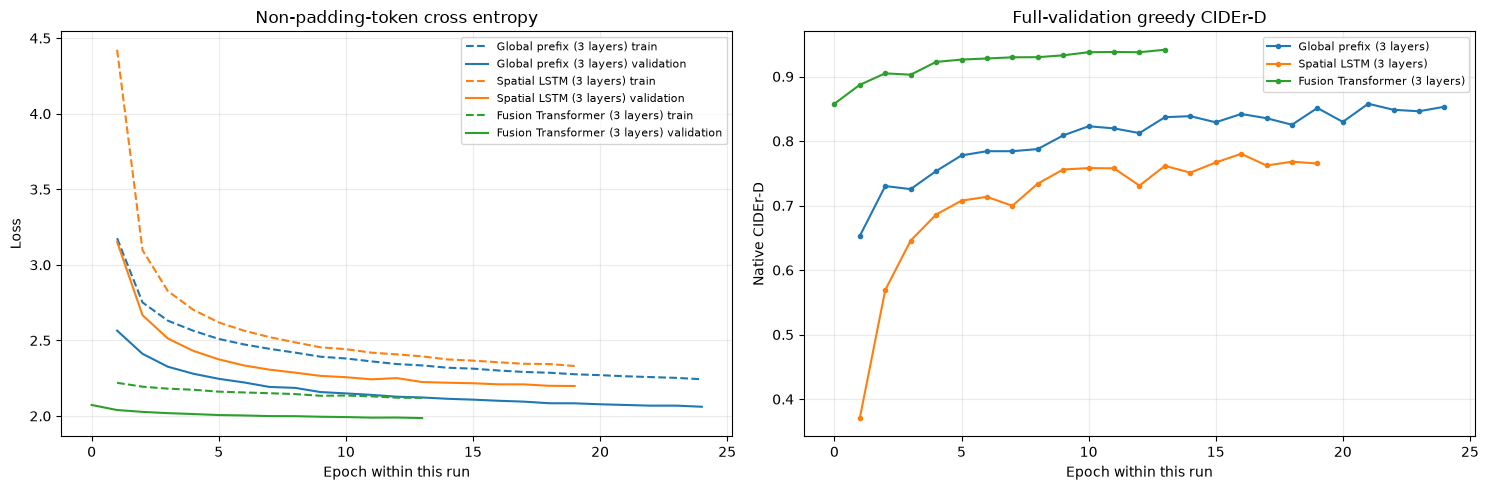

Fusion begins from a trained prefix checkpoint; its epoch axis counts the continuation stage only.
These curves show saved per-run progress. They do not isolate architecture effects or compare equal total training budgets.


In [27]:
if EXTRACT_REGION_FEATURES or RUN_FUSION_TRAINING:
    fusion_data=load_region_prepared_data(PROJECT_DIR,RAW_IMAGE_ROOT)
    checked_code=final_code_identity(notebook_path=NOTEBOOK_PATH,expected=EXPECTED_CODE_IDENTITY)
    if EXTRACT_REGION_FEATURES:
        extract_final_regions(fusion_data,PROJECT_DIR,RAW_IMAGE_ROOT,checked_code)
    if RUN_FUSION_TRAINING:
        fusion_training_result=start_final_training(fusion_data,PROJECT_DIR,checked_code,preflight_path=PREFLIGHT_PATH)
report_fusion(PROJECT_DIR)
report_learning_curves(PROJECT_DIR)


## 6. Decoding selection on validation

The final comparison fixes two checkpoints (epochs 11 and 13) and evaluates greedy plus widths 3/5/7 with penalties 0/0.3/0.6/0.9/1.2. All 32 settings use the same 5,000 validation images, batch 64, AMP and device. One traversal per width is shared across penalties because live beams are pruned by raw score. Finished captions keep separate rankings for each penalty. Generation time is counted once per width.

The primary choice was fixed before test: **epoch 11, beam size 5, length penalty 0 (no length normalization)**. Historical batch 16 comparisons are retained separately and do not enter this controlled selection. A newer greedy-best checkpoint need not be best under beam decoding. The saved predictions contain image IDs, token IDs and all human references.

In [28]:
@torch.no_grad()
def fusion_beam_search(
    model,grid_features,region_features,start_id,end_id,max_steps=33,
    region_mask=None,region_boxes=None,global_features=None,
    beam_size=3,length_penalty=0.6,
):
    """Return token lists without START/EOS/PAD, using frozen model weights.

    Keep up to K live non-EOS prefixes and K completed captions per image.
    Live prefixes at the same step are ranked by cumulative log probability.
    Completed/final candidates use score / ((5 + L) / 6)**alpha, where L
    excludes START and includes EOS when emitted. At the length limit, compare
    both completed captions and unfinished prefixes using that same formula.
    Beam size 1 deliberately uses the model's exact greedy implementation.
    """
    if type(beam_size) is not int or beam_size < 1:
        raise ValueError("beam_size must be a positive integer.")
    if type(max_steps) is not int or not 1 <= max_steps < model.max_positions:
        raise ValueError("max_steps must fit the word positions after the image prefix.")
    if not isinstance(length_penalty,(int,float)) or not math.isfinite(length_penalty) or length_penalty < 0:
        raise ValueError("length_penalty must be finite and nonnegative.")
    special = (model.pad_id,start_id,end_id)
    if any(type(value) is not int or value < 0 for value in special) or len(set(special)) != 3:
        raise ValueError("PAD, START and END must have distinct nonnegative integer IDs.")
    was_training = model.training
    model.eval()
    try:
        if beam_size == 1:
            return model.greedy(
                grid_features,region_features,start_id,end_id,max_steps=max_steps,
                region_mask=region_mask,region_boxes=region_boxes,global_features=global_features,
            )
        memory,memory_padding,image_token = model.prepare_memory(
            grid_features,region_features,region_mask,region_boxes,global_features,
        )
        batch_size = len(memory)
        if batch_size == 0:
            return []
        device = memory.device
        prefixes = torch.full((batch_size,1,1),start_id,dtype=torch.long,device=device)
        live_scores = torch.zeros(batch_size,1,dtype=torch.float32,device=device)
        finished_scores = torch.full((batch_size,beam_size),-torch.inf,device=device)
        finished_tokens = torch.full((batch_size,beam_size,max_steps + 1),model.pad_id,
                                     dtype=torch.long,device=device)
        finished_lengths = torch.zeros(batch_size,beam_size,dtype=torch.long,device=device)
        current_beams = 0
        legal_tokens = None
        live_length = 0

        for length in range(1,max_steps + 1):
            beams = prefixes.shape[1]
            if beams != current_beams:
                # Every beam for one image sees identical visual memory/masks.
                beam_memory = memory.repeat_interleave(beams,dim=0)
                beam_padding = memory_padding.repeat_interleave(beams,dim=0)
                beam_image = image_token.repeat_interleave(beams,dim=0)
                current_beams = beams
            logits = model.decode_memory(
                beam_memory,beam_padding,beam_image,prefixes.reshape(batch_size * beams,-1),
            )[:,-1]
            vocab_size = logits.shape[-1]
            if max(special) >= vocab_size:
                raise ValueError("Special token ID is outside the model vocabulary.")
            # Preserve the original model probabilities: mask AFTER log_softmax.
            log_probs = torch.log_softmax(logits.float(),dim=-1).reshape(batch_size,beams,vocab_size)
            if torch.isnan(log_probs).any():
                raise FloatingPointError("Nonfinite model probabilities during beam generation.")
            log_probs[:,:,model.pad_id] = -torch.inf
            log_probs[:,:,start_id] = -torch.inf

            # Store EOS candidates without removing other still-live alternatives.
            penalty = ((5 + length) / 6) ** length_penalty
            eos_scores = (live_scores + log_probs[:,:,end_id]) / penalty
            eos_tokens = torch.full((batch_size,beams,max_steps + 1),model.pad_id,
                                    dtype=torch.long,device=device)
            eos_tokens[:,:,:prefixes.shape[-1]] = prefixes
            eos_tokens[:,:,prefixes.shape[-1]] = end_id
            candidate_finished_scores = torch.cat([finished_scores,eos_scores],dim=1)
            candidate_finished_tokens = torch.cat([finished_tokens,eos_tokens],dim=1)
            candidate_finished_lengths = torch.cat([
                finished_lengths,torch.full((batch_size,beams),length,dtype=torch.long,device=device),
            ],dim=1)
            finished_scores,chosen = candidate_finished_scores.topk(beam_size,dim=1)
            finished_tokens = candidate_finished_tokens.gather(
                1,chosen.unsqueeze(-1).expand(-1,-1,max_steps + 1),
            )
            finished_lengths = candidate_finished_lengths.gather(1,chosen)

            if legal_tokens is None:
                vocabulary = torch.arange(vocab_size,device=device)
                legal_tokens = vocabulary[(vocabulary != model.pad_id) &
                                          (vocabulary != start_id) & (vocabulary != end_id)]
            if len(legal_tokens) == 0:
                live_scores.fill_(-torch.inf)
                break
            candidates = live_scores.unsqueeze(-1) + log_probs.index_select(-1,legal_tokens)
            next_beams = min(beam_size,beams * len(legal_tokens))
            live_scores,chosen = candidates.flatten(1).topk(next_beams,dim=1)
            parents = chosen // len(legal_tokens)
            next_tokens = legal_tokens[chosen % len(legal_tokens)]
            prefixes = torch.cat([
                prefixes.gather(1,parents.unsqueeze(-1).expand(-1,-1,prefixes.shape[-1])),
                next_tokens.unsqueeze(-1),
            ],dim=-1)
            live_length = length
            # Completed beams alone cannot justify early stopping under length normalization.
            if not torch.isfinite(live_scores).any():
                break

        live_penalty = ((5 + live_length) / 6) ** length_penalty
        final_scores = torch.cat([finished_scores,live_scores / live_penalty],dim=1)
        best_scores,selected = final_scores.max(dim=1)
        if not torch.isfinite(best_scores).all():
            raise FloatingPointError("No finite caption candidate survived beam generation.")
        selected = selected.tolist()
        finished_cpu = finished_tokens.cpu().tolist()
        lengths_cpu = finished_lengths.cpu().tolist()
        prefixes_cpu = prefixes.cpu().tolist()
        result = []
        for index,candidate in enumerate(selected):
            if candidate < beam_size:
                # Positions 1..L-1 are content; position L is EOS.
                length = lengths_cpu[index][candidate]
                result.append(finished_cpu[index][candidate][1:length])
            else:
                result.append(prefixes_cpu[index][candidate - beam_size][1:])
        return result
    finally:
        model.train(was_training)


In [29]:
def beam_eval_hash(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(",",":"),allow_nan=False).encode()).hexdigest()


def beam_eval_file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b""):
            digest.update(block)
    return digest.hexdigest()


def beam_eval_json(path,value):
    path = Path(path)
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary = path.with_suffix(path.suffix+".tmp")
    with temporary.open("w",encoding="utf-8") as stream:
        json.dump(value,stream,indent=2,ensure_ascii=False,allow_nan=False)
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)


def beam_eval_function_id(functions):
    sources = [ast.dump(ast.parse(textwrap.dedent(inspect.getsource(inspect.unwrap(function)))))
               for function in functions]
    return beam_eval_hash(sources)


@contextmanager
def beam_evaluation_lock(output_dir):
    path = Path(output_dir)/"evaluation.lock"
    token = uuid.uuid4().hex
    try:
        with path.open("x",encoding="utf-8") as stream:
            json.dump({"token":token,"pid":os.getpid(),"created_utc":datetime.now(timezone.utc).isoformat()},stream)
    except FileExistsError as error:
        raise RuntimeError(f"An evaluation lock exists: {path}. Check its PID; do not remove a live lock.") from error
    try:
        yield
    finally:
        if path.exists() and json.loads(path.read_text(encoding="utf-8")).get("token") == token:
            path.unlink()


def beam_validate_records(records,expected_ids,data,max_steps):
    if [record["image_id"] for record in records] != list(expected_ids):
        raise ValueError("Prediction IDs do not match the exact expected validation order.")
    forbidden = {data["ids"]["pad"],data["ids"]["start"],data["ids"]["end"]}
    vocabulary = data["id_to_token"]
    for record in records:
        tokens = record["token_ids"]
        if (not isinstance(tokens,list) or len(tokens) > max_steps or
                any(type(token) is not int or not 0 <= token < len(vocabulary) or token in forbidden for token in tokens)):
            raise ValueError("A generated caption has invalid IDs, special tokens or length.")
        if record["prediction"] != " ".join(vocabulary[token] for token in tokens):
            raise ValueError("Stored text differs from its generated token IDs.")
        if record["references"] != data["references"]["val"][record["image_id"]]:
            raise ValueError("A raw human reference set changed in a prediction chunk.")


def beam_validate_chunk(chunk,identity_hash,mode,first,last,expected_ids,data,max_steps):
    if (chunk.get("identity_sha256") != identity_hash or chunk.get("mode") != mode or
            chunk.get("first_index") != first or chunk.get("last_index") != last):
        raise ValueError("Prediction chunk belongs to a different snapshot/configuration/range.")
    seconds = chunk.get("generation_seconds")
    if not isinstance(seconds,(int,float)) or not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Prediction chunk has an invalid timer.")
    beam_validate_records(chunk["records"],expected_ids,data,max_steps)


def beam_load_completed_chunks(folder,identity_hash,mode,dataset,data,config):
    folder = Path(folder)
    chunk_dir = folder/"chunks"
    size = config["batch_size"]
    expected_names = {f"batch_{first:05d}_{min(first+size,len(dataset)):05d}.json"
                      for first in range(0,len(dataset),size)}
    if any(path.name not in expected_names for path in chunk_dir.glob("*.json")):
        raise ValueError("Unexpected prediction chunk filename; use the original evaluation configuration.")
    records,seconds,missing = [],0.0,False
    for first in range(0,len(dataset),size):
        last = min(first+size,len(dataset))
        path = chunk_dir/f"batch_{first:05d}_{last:05d}.json"
        if not path.exists():
            missing = True
            continue
        if missing:
            raise ValueError("A prediction chunk follows a missing earlier chunk; refusing to hide a gap.")
        chunk = json.loads(path.read_text(encoding="utf-8"))
        beam_validate_chunk(chunk,identity_hash,mode,first,last,dataset.image_ids[first:last],data,config["max_steps"])
        records.extend(chunk["records"])
        seconds += chunk["generation_seconds"]
    return records,seconds


@torch.no_grad()
def beam_evaluate_mode(model,dataset,data,config,device,evaluator,mode,output_dir,identity_hash,
                       max_new_batches=None,_after_chunk=None):
    """Resume atomic chunks; partial generation never produces a corpus metric."""
    beam_sizes = config.get("beam_sizes",[3])
    if dataset.split != "val" or mode not in ["greedy",*[f"beam{size}" for size in beam_sizes]]:
        raise ValueError("Use greedy or a configured beam width on the labeled validation split.")
    if max_new_batches is not None and (type(max_new_batches) is not int or max_new_batches < 1):
        raise ValueError("max_new_batches must be a positive optional work limit.")
    folder = Path(output_dir)/mode
    (folder/"chunks").mkdir(parents=True,exist_ok=True)
    records,generation_seconds = beam_load_completed_chunks(folder,identity_hash,mode,dataset,data,config)
    device = torch.device(device)
    use_amp = bool(config["amp"] and device.type == "cuda")
    model.eval()
    fusion_seed(config["seed"])
    loader = iter(fusion_loader(dataset,config["batch_size"],indices=list(range(len(records),len(dataset))),
                               seed=config["seed"],pin_memory=use_amp))
    new_batches = 0
    try:
        while len(records) < len(dataset):
            if max_new_batches is not None and new_batches >= max_new_batches:
                break
            if device.type == "cuda": torch.cuda.synchronize(device)
            started = time.perf_counter()
            batch = next(loader)
            moved = fusion_device_batch(batch,device)
            extras = {"region_mask":moved["region_mask"],"region_boxes":moved["region_boxes"],
                      "global_features":moved["global_features"]}
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=use_amp):
                if mode == "greedy":
                    tokens = model.greedy(moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                                          max_steps=config["max_steps"],**extras)
                else:
                    tokens = fusion_beam_search(model,moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                        max_steps=config["max_steps"],beam_size=int(mode[4:]),length_penalty=config["length_penalty"],**extras)
            if len(tokens) != len(batch["image_ids"]):
                raise ValueError("Decoder returned a different number of captions than images.")
            chunk_records = [{"image_id":int(image_id),"prediction":" ".join(data["id_to_token"][token] for token in row),
                              "token_ids":row,"references":references}
                             for image_id,row,references in zip(batch["image_ids"],tokens,batch["references"])]
            if device.type == "cuda": torch.cuda.synchronize(device)
            seconds = time.perf_counter()-started
            first,last = len(records),len(records)+len(chunk_records)
            chunk = {"identity_sha256":identity_hash,"mode":mode,"first_index":first,"last_index":last,
                     "generation_seconds":seconds,"records":chunk_records}
            beam_validate_chunk(chunk,identity_hash,mode,first,last,dataset.image_ids[first:last],data,config["max_steps"])
            beam_eval_json(folder/"chunks"/f"batch_{first:05d}_{last:05d}.json",chunk)
            records.extend(chunk_records)
            generation_seconds += seconds
            new_batches += 1
            beam_eval_json(folder/"progress.json",{"status":"generating","identity_sha256":identity_hash,
                "completed_images":len(records),"required_images":len(dataset),"generation_seconds":generation_seconds,
                "updated_utc":datetime.now(timezone.utc).isoformat()})
            if new_batches == 1 or new_batches % 20 == 0 or len(records) == len(dataset):
                speed = len(records)/max(generation_seconds,1e-9)
                print(f"{mode}: {len(records):,}/{len(dataset):,} | {speed:.1f} img/s | generation {generation_seconds:.1f} s",flush=True)
            if _after_chunk is not None: _after_chunk(chunk)
            del batch,moved,tokens
        if len(records) != len(dataset):
            partial = {"status":"partial","identity_sha256":identity_hash,"mode":mode,"completed_images":len(records),
                       "required_images":len(dataset),"generation_seconds":generation_seconds,"metrics_computed":False}
            beam_eval_json(folder/"progress.json",partial)
            return partial
        beam_validate_records(records,dataset.image_ids,data,config["max_steps"])
        predictions_hash = beam_eval_hash(records)
        predictions_path = folder/"validation_predictions.json"
        if predictions_path.exists():
            if beam_eval_hash(json.loads(predictions_path.read_text(encoding="utf-8"))) != predictions_hash:
                raise ValueError("Final prediction file differs from its validated chunks.")
        else:
            beam_eval_json(predictions_path,records)
        metrics_path = folder/"metrics.json"
        if metrics_path.exists():
            result = json.loads(metrics_path.read_text(encoding="utf-8"))
            if (result.get("identity_sha256") != identity_hash or result.get("predictions_sha256") != predictions_hash or
                    result.get("status") != "complete" or result.get("mode") != mode or result.get("images") != len(dataset) or
                    set(result.get("scores",{})) != {"bleu1","bleu4","cider_d"} or
                    not all(math.isfinite(float(value)) for value in result["scores"].values())):
                raise ValueError("Saved metrics do not match the exact current full prediction corpus.")
            return result
        started = time.perf_counter()
        scores = evaluator.score(records,expected_ids=dataset.image_ids)
        metric_seconds = time.perf_counter()-started
        if set(scores) != {"bleu1","bleu4","cider_d"} or not all(math.isfinite(float(value)) for value in scores.values()):
            raise ValueError("The verified scorer returned unexpected or nonfinite corpus scores.")
        result = {"status":"complete","identity_sha256":identity_hash,"mode":mode,"images":len(records),
                  "scores":scores,"generation_seconds":generation_seconds,"metric_seconds":metric_seconds,
                  "evaluation_seconds":generation_seconds+metric_seconds,"predictions_sha256":predictions_hash,
                  "average_words":sum(len(record["token_ids"]) for record in records)/len(records),
                  "predictions_file":str((folder/"validation_predictions.json").resolve()),"metrics_computed":True}
        beam_eval_json(metrics_path,result)
        beam_eval_json(folder/"progress.json",result)
        return result
    except BaseException as error:
        beam_eval_json(folder/"progress.json",{"status":"interrupted","identity_sha256":identity_hash,
            "completed_images":len(records),"required_images":len(dataset),"generation_seconds":generation_seconds,
            "error_type":type(error).__name__,"error":str(error),"metrics_computed":False})
        raise


def load_beam_snapshot(snapshot_dir,data,evaluator,dataset,code_identity):
    """Use only the copied full checkpoint; never combine live weights and live metadata."""
    snapshot_dir = Path(snapshot_dir)
    metadata = json.loads((snapshot_dir/"snapshot.json").read_text(encoding="utf-8"))
    path = snapshot_dir/"best.pt"
    expected_hash = metadata["full_checkpoint_sha256"]
    if beam_eval_file_sha(path) != expected_hash:
        raise ValueError("The pinned full checkpoint SHA256 changed.")
    payload = torch.load(path,map_location="cpu",weights_only=False)
    if beam_eval_file_sha(path) != expected_hash:
        raise ValueError("The checkpoint changed while it was being read.")
    identity,state = payload["identity"],payload["state"]
    assert payload["format_version"] == 1
    assert identity["data"] == data["provenance"] and identity["metrics"] == evaluator.metadata
    assert identity["validation_ids"] == data["split_ids"]["val"] == dataset.image_ids
    assert len(dataset) == 5000 and len(set(dataset.image_ids)) == 5000
    assert identity["train_ids"] == sorted(data["split_ids"]["train"]) and len(identity["train_ids"]) == 113287
    assert not set(dataset.image_ids)&(set(data["split_ids"]["train"])|set(data["split_ids"]["test"]))
    assert identity["grid_and_region_data"]["val"] == dataset.provenance
    trained = identity["config"]
    assert trained["code"]["models_sha256"] == code_identity["models_sha256"]
    assert trained["code"]["region_producer_code_id"] == code_identity["region_producer_code_id"]
    assert metadata["snapshot_epoch"] == state["epoch"] and metadata["best_epoch"] == state["best_epoch"]
    assert state["epoch"] == state["best_epoch"] and metadata["best_record"] == state["best_record"]
    if not all(bool(torch.isfinite(value).all()) for value in payload["model"].values() if value.is_floating_point()):
        raise FloatingPointError("Pinned checkpoint has nonfinite model weights.")
    return payload,metadata


def run_fusion_decoding_comparison(project_dir,snapshot_dir,output_dir,raw_root=None,code_identity=None,
                                   batch_size=16,amp=True,length_penalty=0.6,device=None,max_new_batches=None,
                                   beam_sizes=(3,5)):
    """Read-only evaluation. Defaults compare greedy, beam3 and beam5 on all 5,000 validation IDs."""
    if type(batch_size) is not int or batch_size < 1 or not math.isfinite(length_penalty) or length_penalty < 0:
        raise ValueError("Use a positive batch size and finite nonnegative length penalty.")
    if (not isinstance(beam_sizes,(list,tuple)) or not beam_sizes or
            any(type(size) is not int or size < 2 for size in beam_sizes) or len(beam_sizes) != len(set(beam_sizes))):
        raise ValueError("beam_sizes must contain distinct integer widths >=2, for example (3,5).")
    beam_sizes = list(beam_sizes)
    if code_identity is None:
        code_identity = globals().get("EXPECTED_CODE_IDENTITY")
    if not code_identity:
        raise ValueError("Pass the verified model/cache code identity from this notebook or runner.")
    project_dir,snapshot_dir,output_dir = Path(project_dir),Path(snapshot_dir),Path(output_dir)
    if output_dir.exists() and any(output_dir.iterdir()) and not (output_dir/"evaluation_identity.json").is_file():
        raise ValueError("Use a dedicated empty evaluation directory, or resume one with its saved identity.")
    output_dir.mkdir(parents=True,exist_ok=True)
    dataset = model = None
    with beam_evaluation_lock(output_dir):
        try:
            data = load_region_prepared_data(project_dir,raw_root)
            evaluator = MetricEvaluator(data["text_settings"])
            grids = load_final_grid_features(data,project_dir)
            regions = load_fusion_region_cache(data,project_dir/"cache/features/fasterrcnn_fusion_expanded_v1",
                                              producer_code_id=code_identity["region_producer_code_id"])
            dataset = FusionCaptionDataset(data,grids,regions,"val",seed=42)
            payload,snapshot = load_beam_snapshot(snapshot_dir,data,evaluator,dataset,code_identity)
            device = torch.device(device if device is not None else ("cuda:0" if torch.cuda.is_available() else "cpu"))
            details = {"device":str(device),"gpu":torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                       "torch":torch.__version__,"cuda_runtime":torch.version.cuda,"cpu_threads":torch.get_num_threads()}
            config = {"seed":42,"batch_size":batch_size,"amp":bool(amp),"amp_enabled":bool(amp and device.type == "cuda"),
                      "max_steps":33,"beam_sizes":beam_sizes,"length_penalty":length_penalty,
                      "length_penalty_formula":"((5+L)/6)^alpha; L excludes START and includes EOS when emitted",
                      "methods":["greedy",*[f"beam{size}" for size in beam_sizes]],
                      "selection":"Fixed beam-width comparison on validation; no model training and no test evaluation"}
            identity = {"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],
                        "snapshot_epoch":snapshot["snapshot_epoch"],"model_source_sha256":code_identity["models_sha256"],
                        "data":data["provenance"],"validation_ids":dataset.image_ids,"cache":dataset.provenance,
                        "scorer":evaluator.metadata,"config":config,"device":details,
                        "beam_implementation_id":beam_eval_function_id([fusion_beam_search]),
                        "evaluation_implementation_id":beam_eval_function_id([beam_validate_records,beam_validate_chunk,
                            beam_load_completed_chunks,beam_evaluate_mode])}
            identity_path = output_dir/"evaluation_identity.json"
            if identity_path.exists() and json.loads(identity_path.read_text(encoding="utf-8")) != identity:
                raise ValueError("Existing evaluation belongs to another snapshot/settings/device/code; use a new directory.")
            beam_eval_json(identity_path,identity)
            beam_eval_json(output_dir/"snapshot_metadata.json",snapshot)
            beam_eval_json(output_dir/"scorer.json",evaluator.metadata)
            beam_eval_json(output_dir/"validation_image_ids.json",dataset.image_ids)
            trained = payload["identity"]["config"]
            model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"],
                grid_feature_dim=trained["grid_feature_dim"],region_feature_dim=trained["region_feature_dim"],
                d_model=trained["d_model"],num_layers=trained["num_layers"],nhead=trained["nhead"],
                dim_feedforward=trained["dim_feedforward"],dropout=trained["dropout"],
                grid_size=trained["grid_size"],max_regions=trained["max_regions"],max_positions=34)
            model.load_state_dict(payload["model"],strict=True)
            del payload
            model = model.to(device).eval()
            model.requires_grad_(False)
            identity_hash = beam_eval_hash(identity)
            results = {mode:beam_evaluate_mode(model,dataset,data,config,device,evaluator,mode,output_dir,
                                              identity_hash,max_new_batches=max_new_batches)
                       for mode in config["methods"]}
            complete = all(result["status"] == "complete" for result in results.values())
            comparison = {"status":"complete" if complete else "partial","identity_sha256":identity_hash,
                "snapshot_epoch":snapshot["snapshot_epoch"],"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],
                "snapshot_scope":snapshot.get("scope","Pinned best at snapshot time; ongoing training can produce a later best."),
                "validation_images":5000,"device":details,"results":results,"test_evaluated":False,
                "model_training_performed":False,"original_checkpoints_modified":False,
                "timing_note":"Per-mode generation includes cache loading, device copies and decoding; scoring is separate. Model loading, artifact I/O and pauses are excluded. Main training continues on the same GPU, so these times are not an isolated architecture benchmark."}
            if complete:
                comparison["differences_from_greedy"] = {
                    mode:{key:result["scores"][key]-results["greedy"]["scores"][key]
                          for key in ["cider_d","bleu1","bleu4"]}
                    for mode,result in results.items() if mode != "greedy"}
                comparison["beam_deltas"] = comparison["differences_from_greedy"]
                comparison["selected_mode_by_validation_cider"] = max(
                    results,key=lambda mode:results[mode]["scores"]["cider_d"])
                # Keep the original beam3 field readable by the existing comparison display.
                if "beam3" in results:
                    comparison["beam_minus_greedy"] = comparison["differences_from_greedy"]["beam3"]
                temporary = output_dir/"comparison.csv.tmp"
                with temporary.open("w",newline="",encoding="utf-8") as stream:
                    writer = csv.DictWriter(stream,fieldnames=["mode","snapshot_epoch","images","bleu1","bleu4","cider_d",
                        "generation_seconds","metric_seconds","evaluation_seconds","average_words","device"])
                    writer.writeheader()
                    for mode,result in results.items():
                        writer.writerow({"mode":mode,"snapshot_epoch":snapshot["snapshot_epoch"],"images":result["images"],
                            **result["scores"],**{key:result[key] for key in ["generation_seconds","metric_seconds","evaluation_seconds","average_words"]},
                            "device":details["gpu"] or details["device"]})
                temporary.replace(output_dir/"comparison.csv")
            beam_eval_json(output_dir/"comparison.json",comparison)
            return comparison
        finally:
            if dataset is not None: dataset.close()
            model = None
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()


def decoding_file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b""):
            digest.update(block)
    return digest.hexdigest()


def save_decoding_snapshot(source_dir,snapshot_dir):
    """Create a new immutable snapshot; use a new folder for a later checkpoint."""
    source_dir,snapshot_dir = Path(source_dir),Path(snapshot_dir)
    snapshot_dir.mkdir(parents=True,exist_ok=False)
    source = source_dir/"best.pt"
    before = source.stat()
    destination = snapshot_dir/"best.pt"
    shutil.copyfile(source,destination)
    after = source.stat()
    if (before.st_size,before.st_mtime_ns) != (after.st_size,after.st_mtime_ns):
        raise RuntimeError("Best changed during copy. Keep this failed copy unused and retry in a new folder.")
    digest = decoding_file_sha(destination)
    if digest != decoding_file_sha(source):
        raise RuntimeError("Source and snapshot differ. Do not evaluate this copy.")
    payload = torch.load(destination,map_location="cpu",weights_only=False)
    state = payload["state"]
    assert state["best_epoch"] == state["epoch"]
    assert state["phase"] in ["epoch_done","finished"]
    if not all(bool(torch.isfinite(value).all()) for value in payload["model"].values()
               if isinstance(value,torch.Tensor) and value.is_floating_point()):
        raise FloatingPointError("Snapshot has a nonfinite model parameter.")
    weights = snapshot_dir/"best_weights.pt"
    torch.save(payload["model"],weights)
    original_predictions = source_dir/"predictions"/f"val_epoch_{state['best_epoch']:03d}.json"
    if original_predictions.is_file():
        shutil.copy2(original_predictions,snapshot_dir/"source_validation.json")
    metadata = {
        "full_checkpoint_sha256":digest,"weights_sha256":decoding_file_sha(weights),
        "original_best_path":str(source.resolve()),"copied_utc":datetime.now(timezone.utc).isoformat(),
        "snapshot_epoch":state["epoch"],"best_epoch":state["best_epoch"],
        "best_record":state["best_record"],"source_run":source_dir.name,
        "implementation_id":payload["identity"]["config"]["implementation_id"],
        "scope":"Best available at snapshot time; all decoding settings must use this same immutable snapshot.",
        "original_checkpoint_modified":False,"training_interrupted":False,
    }
    (snapshot_dir/"snapshot.json").write_text(json.dumps(metadata,indent=2)+"\n",encoding="utf-8")
    return metadata


In [30]:
@torch.no_grad()
def fusion_beam_search_many(
    model,grid_features,region_features,start_id,end_id,max_steps=33,
    region_mask=None,region_boxes=None,global_features=None,
    beam_size=3,length_penalties=(0.0,0.3,0.6,0.9,1.2),
):
    """Return {alpha: token lists}, without changing the original beam policy.

    Live prefixes are selected by raw cumulative log probability. Finished
    captions never remove live prefixes. Therefore the decoder traversal does
    not depend on alpha; only finished/final ranking does. Keep a separate
    finished top-K buffer for each alpha with the original topk input order.

    Equivalence assumes deterministic eval-mode logits for the same inputs.
    Floating-point/tie behavior can still depend on device and PyTorch kernels.
    This is a shared traversal per beam width, not across different widths.
    """
    if type(beam_size) is not int or beam_size < 1:
        raise ValueError("beam_size must be a positive integer.")
    if type(max_steps) is not int or not 1 <= max_steps < model.max_positions:
        raise ValueError("max_steps must fit the word positions after the image prefix.")
    if not isinstance(length_penalties,(list,tuple)) or not length_penalties:
        raise ValueError("length_penalties must be a nonempty list or tuple.")
    if any(not isinstance(alpha,(int,float)) or not math.isfinite(alpha) or alpha < 0
           for alpha in length_penalties):
        raise ValueError("Every length penalty must be finite and nonnegative.")
    alphas = [float(alpha) for alpha in length_penalties]
    if len(alphas) != len(set(alphas)):
        raise ValueError("Length penalties must be distinct.")
    special = (model.pad_id,start_id,end_id)
    if any(type(value) is not int or value < 0 for value in special) or len(set(special)) != 3:
        raise ValueError("PAD, START and END must have distinct nonnegative integer IDs.")
    was_training = model.training
    model.eval()
    try:
        if beam_size == 1:
            greedy = model.greedy(
                grid_features,region_features,start_id,end_id,max_steps=max_steps,
                region_mask=region_mask,region_boxes=region_boxes,global_features=global_features,
            )
            return {alpha: [list(tokens) for tokens in greedy] for alpha in alphas}
        memory,memory_padding,image_token = model.prepare_memory(
            grid_features,region_features,region_mask,region_boxes,global_features,
        )
        batch_size = len(memory)
        if batch_size == 0:
            return {alpha: [] for alpha in alphas}
        device = memory.device
        prefixes = torch.full((batch_size,1,1),start_id,dtype=torch.long,device=device)
        live_scores = torch.zeros(batch_size,1,dtype=torch.float32,device=device)
        finished = {
            alpha: (
                torch.full((batch_size,beam_size),-torch.inf,device=device),
                torch.full((batch_size,beam_size,max_steps + 1),model.pad_id,
                           dtype=torch.long,device=device),
                torch.zeros(batch_size,beam_size,dtype=torch.long,device=device),
            )
            for alpha in alphas
        }
        current_beams = 0
        legal_tokens = None
        live_length = 0

        for length in range(1,max_steps + 1):
            beams = prefixes.shape[1]
            if beams != current_beams:
                beam_memory = memory.repeat_interleave(beams,dim=0)
                beam_padding = memory_padding.repeat_interleave(beams,dim=0)
                beam_image = image_token.repeat_interleave(beams,dim=0)
                current_beams = beams
            logits = model.decode_memory(
                beam_memory,beam_padding,beam_image,prefixes.reshape(batch_size * beams,-1),
            )[:,-1]
            vocab_size = logits.shape[-1]
            if max(special) >= vocab_size:
                raise ValueError("Special token ID is outside the model vocabulary.")
            log_probs = torch.log_softmax(logits.float(),dim=-1).reshape(batch_size,beams,vocab_size)
            if torch.isnan(log_probs).any():
                raise FloatingPointError("Nonfinite model probabilities during beam generation.")
            log_probs[:,:,model.pad_id] = -torch.inf
            log_probs[:,:,start_id] = -torch.inf

            # Alpha does not change this EOS prefix or any live continuation.
            raw_eos_scores = live_scores + log_probs[:,:,end_id]
            eos_tokens = torch.full((batch_size,beams,max_steps + 1),model.pad_id,
                                    dtype=torch.long,device=device)
            eos_tokens[:,:,:prefixes.shape[-1]] = prefixes
            eos_tokens[:,:,prefixes.shape[-1]] = end_id
            eos_lengths = torch.full((batch_size,beams),length,dtype=torch.long,device=device)
            for alpha in alphas:
                finished_scores,finished_tokens,finished_lengths = finished[alpha]
                penalty = ((5 + length) / 6) ** alpha
                eos_scores = raw_eos_scores / penalty
                candidate_scores = torch.cat([finished_scores,eos_scores],dim=1)
                candidate_tokens = torch.cat([finished_tokens,eos_tokens],dim=1)
                candidate_lengths = torch.cat([finished_lengths,eos_lengths],dim=1)
                finished_scores,chosen = candidate_scores.topk(beam_size,dim=1)
                finished_tokens = candidate_tokens.gather(
                    1,chosen.unsqueeze(-1).expand(-1,-1,max_steps + 1),
                )
                finished_lengths = candidate_lengths.gather(1,chosen)
                finished[alpha] = (finished_scores,finished_tokens,finished_lengths)

            if legal_tokens is None:
                vocabulary = torch.arange(vocab_size,device=device)
                legal_tokens = vocabulary[(vocabulary != model.pad_id) &
                                          (vocabulary != start_id) & (vocabulary != end_id)]
            if len(legal_tokens) == 0:
                live_scores.fill_(-torch.inf)
                break
            candidates = live_scores.unsqueeze(-1) + log_probs.index_select(-1,legal_tokens)
            next_beams = min(beam_size,beams * len(legal_tokens))
            live_scores,chosen = candidates.flatten(1).topk(next_beams,dim=1)
            parents = chosen // len(legal_tokens)
            next_tokens = legal_tokens[chosen % len(legal_tokens)]
            prefixes = torch.cat([
                prefixes.gather(1,parents.unsqueeze(-1).expand(-1,-1,prefixes.shape[-1])),
                next_tokens.unsqueeze(-1),
            ],dim=-1)
            live_length = length
            if not torch.isfinite(live_scores).any():
                break

        prefixes_cpu = prefixes.cpu().tolist()
        results = {}
        for alpha in alphas:
            finished_scores,finished_tokens,finished_lengths = finished[alpha]
            live_penalty = ((5 + live_length) / 6) ** alpha
            final_scores = torch.cat([finished_scores,live_scores / live_penalty],dim=1)
            best_scores,selected = final_scores.max(dim=1)
            if not torch.isfinite(best_scores).all():
                raise FloatingPointError("No finite caption candidate survived beam generation.")
            selected = selected.tolist()
            finished_cpu = finished_tokens.cpu().tolist()
            lengths_cpu = finished_lengths.cpu().tolist()
            result = []
            for index,candidate in enumerate(selected):
                if candidate < beam_size:
                    length = lengths_cpu[index][candidate]
                    result.append(finished_cpu[index][candidate][1:length])
                else:
                    result.append(prefixes_cpu[index][candidate - beam_size][1:])
            results[alpha] = result
        return results
    finally:
        model.train(was_training)


In [31]:
def search_mode_name(width,alpha):
    return f"beam{width}_alpha{alpha:g}".replace(".","p")


def search_group_modes(group,config):
    if group == "greedy":
        return ["greedy"]
    if group not in [f"beam{width}" for width in config["beam_sizes"]]:
        raise ValueError("The generation group is not configured.")
    return [search_mode_name(int(group[4:]),alpha) for alpha in config["length_penalties"]]


def search_validate_chunk(chunk,identity_hash,group,first,last,dataset,data,config):
    if (chunk.get("identity_sha256") != identity_hash or chunk.get("group") != group or
            chunk.get("first_index") != first or chunk.get("last_index") != last):
        raise ValueError("Grouped prediction chunk belongs to a different snapshot/configuration/range.")
    seconds = chunk.get("generation_seconds")
    if not isinstance(seconds,(int,float)) or not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Invalid grouped generation timer.")
    if set(chunk.get("records_by_mode",{})) != set(search_group_modes(group,config)):
        raise ValueError("A grouped chunk must contain every configured alpha atomically.")
    for records in chunk["records_by_mode"].values():
        beam_validate_records(records,dataset.image_ids[first:last],data,config["max_steps"])
    if first == 0 and group == "beam3" and config["verify_reference"]:
        reference = chunk.get("reference_check",{})
        if reference.get("passed") is not True or reference.get("images") != last-first:
            raise ValueError("The first width3 chunk lacks its original-helper equivalence check.")


def search_load_chunks(folder,identity_hash,group,dataset,data,config):
    chunk_dir = Path(folder)/"chunks"
    size = config["batch_size"]
    names = {f"batch_{first:05d}_{min(first+size,len(dataset)):05d}.json" for first in range(0,len(dataset),size)}
    if any(path.name not in names for path in chunk_dir.glob("*.json")):
        raise ValueError("Unexpected grouped chunk name.")
    modes = search_group_modes(group,config)
    records = {mode:[] for mode in modes}
    seconds,missing,reference = 0.0,False,None
    for first in range(0,len(dataset),size):
        last = min(first+size,len(dataset))
        path = chunk_dir/f"batch_{first:05d}_{last:05d}.json"
        if not path.exists():
            missing = True
            continue
        if missing:
            raise ValueError("A grouped chunk follows a missing earlier chunk.")
        chunk = json.loads(path.read_text(encoding="utf-8"))
        search_validate_chunk(chunk,identity_hash,group,first,last,dataset,data,config)
        for mode in modes:
            records[mode].extend(chunk["records_by_mode"][mode])
        seconds += chunk["generation_seconds"]
        if first == 0: reference = chunk.get("reference_check")
    return records,seconds,reference


def search_score_variant(mode,group,records,shared_seconds,output_dir,identity_hash,dataset,data,config,evaluator):
    beam_validate_records(records,dataset.image_ids,data,config["max_steps"])
    folder = Path(output_dir)/"modes"/mode
    folder.mkdir(parents=True,exist_ok=True)
    prediction_hash = beam_eval_hash(records)
    prediction_path = folder/"validation_predictions.json"
    if prediction_path.exists():
        if beam_eval_hash(json.loads(prediction_path.read_text(encoding="utf-8"))) != prediction_hash:
            raise ValueError("Final predictions differ from validated grouped chunks.")
    else:
        beam_eval_json(prediction_path,records)
    metrics_path = folder/"metrics.json"
    if metrics_path.exists():
        saved = json.loads(metrics_path.read_text(encoding="utf-8"))
        if (saved.get("identity_sha256") != identity_hash or saved.get("predictions_sha256") != prediction_hash or
                saved.get("status") != "complete" or saved.get("mode") != mode or saved.get("generation_group") != group or
                saved.get("images") != len(dataset) or set(saved.get("scores",{})) != {"bleu1","bleu4","cider_d"} or
                not all(math.isfinite(float(score)) for score in saved["scores"].values())):
            raise ValueError("Saved metrics belong to a different full prediction corpus.")
        return saved
    started = time.perf_counter()
    scores = evaluator.score(records,expected_ids=dataset.image_ids)
    scoring_seconds = time.perf_counter()-started
    if set(scores) != {"bleu1","bleu4","cider_d"} or not all(math.isfinite(float(score)) for score in scores.values()):
        raise ValueError("Unexpected or nonfinite corpus scores.")
    result = {"status":"complete","identity_sha256":identity_hash,"mode":mode,"images":len(records),
              "generation_group":group,"shared_group_generation_seconds":shared_seconds,
              "individual_generation_seconds":None,"scoring_seconds":scoring_seconds,"scores":scores,
              "predictions_sha256":prediction_hash,"predictions_file":str(prediction_path.resolve()),
              "average_words":sum(len(record["token_ids"]) for record in records)/len(records),
              "timing_note":"Generation belongs to the shared width pass; do not sum it across alpha rows."}
    beam_eval_json(metrics_path,result)
    return result


@torch.no_grad()
def evaluate_search_group(model,dataset,data,config,device,evaluator,group,output_dir,identity_hash,
                           max_new_batches=None,after_chunk=None):
    """One traversal per width; all alpha outputs for each batch are committed together."""
    if dataset.split != "val":
        raise ValueError("Only the labeled validation split is evaluated.")
    if max_new_batches is not None and (type(max_new_batches) is not int or max_new_batches < 1):
        raise ValueError("max_new_batches must be a positive optional work limit.")
    modes = search_group_modes(group,config)
    folder = Path(output_dir)/"groups"/group
    (folder/"chunks").mkdir(parents=True,exist_ok=True)
    records,seconds,reference = search_load_chunks(folder,identity_hash,group,dataset,data,config)
    completed = len(records[modes[0]])
    device = torch.device(device)
    enabled = bool(config["amp"] and device.type == "cuda")
    model.eval()
    fusion_seed(config["seed"])
    loader = iter(fusion_loader(dataset,config["batch_size"],indices=list(range(completed,len(dataset))),
                               seed=config["seed"],pin_memory=enabled))
    batches = 0
    try:
        while completed < len(dataset):
            if max_new_batches is not None and batches >= max_new_batches: break
            if device.type == "cuda": torch.cuda.synchronize(device)
            started = time.perf_counter()
            batch = next(loader)
            moved = fusion_device_batch(batch,device)
            extras = {"region_mask":moved["region_mask"],"region_boxes":moved["region_boxes"],
                      "global_features":moved["global_features"]}
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=enabled):
                if group == "greedy":
                    predictions = {"greedy":model.greedy(moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                                                       max_steps=config["max_steps"],**extras)}
                else:
                    width = int(group[4:])
                    outputs = fusion_beam_search_many(model,moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                        max_steps=config["max_steps"],beam_size=width,length_penalties=config["length_penalties"],**extras)
                    if set(outputs) != set(config["length_penalties"]):
                        raise ValueError("Grouped beam search omitted or added a length penalty.")
                    predictions = {search_mode_name(width,alpha):outputs[alpha] for alpha in config["length_penalties"]}
            chunk_records = {}
            for mode,tokens in predictions.items():
                if len(tokens) != len(batch["image_ids"]): raise ValueError("Decoder caption count differs from image count.")
                chunk_records[mode] = [{"image_id":int(image_id),"token_ids":row,
                    "prediction":" ".join(data["id_to_token"][token] for token in row),"references":refs}
                    for image_id,row,refs in zip(batch["image_ids"],tokens,batch["references"])]
            if device.type == "cuda": torch.cuda.synchronize(device)
            elapsed = time.perf_counter()-started
            first,last = completed,completed+len(batch["image_ids"])
            if first == 0 and group == "beam3" and config["verify_reference"]:
                check_started = time.perf_counter()
                with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=enabled):
                    original = fusion_beam_search(model,moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                        max_steps=config["max_steps"],beam_size=3,length_penalty=0.6,**extras)
                if original != predictions[search_mode_name(3,0.6)]:
                    raise AssertionError("Grouped width3/alpha0.6 differs from the original beam helper on the same batch.")
                if device.type == "cuda": torch.cuda.synchronize(device)
                reference = {"passed":True,"images":last-first,"beam_size":3,"length_penalty":0.6,
                             "seconds":time.perf_counter()-check_started,"note":"Excluded from the shared generation timer; included in total wall time."}
                print("Real-batch grouped/original beam3 alpha0.6 equivalence passed.",flush=True)
            chunk = {"identity_sha256":identity_hash,"group":group,"first_index":first,"last_index":last,
                     "generation_seconds":elapsed,"records_by_mode":chunk_records,
                     "reference_check":reference if first == 0 else None}
            search_validate_chunk(chunk,identity_hash,group,first,last,dataset,data,config)
            beam_eval_json(folder/"chunks"/f"batch_{first:05d}_{last:05d}.json",chunk)
            for mode in modes: records[mode].extend(chunk_records[mode])
            completed,seconds,batches = last,seconds+elapsed,batches+1
            beam_eval_json(folder/"progress.json",{"status":"generating","identity_sha256":identity_hash,"group":group,
                "completed_images":completed,"required_images":len(dataset),"shared_generation_seconds":seconds,
                "modes":modes,"updated_utc":datetime.now(timezone.utc).isoformat()})
            if batches == 1 or batches % 10 == 0 or completed == len(dataset):
                print(f"{group} ({len(modes)} variants): {completed:,}/{len(dataset):,} | {completed/max(seconds,1e-9):.1f} img/s | shared {seconds:.1f} s",flush=True)
            if after_chunk is not None: after_chunk(chunk)
            del batch,moved,predictions,chunk_records
        if completed < len(dataset):
            partial = {"status":"partial","group":group,"completed_images":completed,"required_images":len(dataset),
                       "generation_seconds":seconds,"modes":modes,"metrics_computed":False,"reference_check":reference}
            beam_eval_json(folder/"progress.json",partial)
            return partial
        results = {}
        for mode in modes:
            results[mode] = search_score_variant(mode,group,records[mode],seconds,output_dir,identity_hash,dataset,data,config,evaluator)
            if after_chunk is not None: after_chunk(None)
        complete = {"status":"complete","group":group,"images":len(dataset),"generation_seconds":seconds,
                    "modes":modes,"results":results,"metrics_computed":True,"reference_check":reference}
        beam_eval_json(folder/"progress.json",complete)
        return complete
    except BaseException as error:
        beam_eval_json(folder/"progress.json",{"status":"interrupted","group":group,"completed_images":completed,
            "required_images":len(dataset),"shared_generation_seconds":seconds,"error_type":type(error).__name__,
            "error":str(error),"metrics_computed":False})
        raise


def run_fusion_decoding_search(project_dir,snapshot_dir,output_dir,raw_root=None,code_identity=None,
                               batch_size=64,beam_sizes=(3,5,7),length_penalties=(0.0,0.3,0.6,0.9,1.2),
                               amp=True,device=None,max_new_batches=None,verify_reference=True):
    if (type(batch_size) is not int or batch_size < 1 or not isinstance(beam_sizes,(tuple,list)) or not beam_sizes or
            any(type(width) is not int or width < 2 for width in beam_sizes) or len(set(beam_sizes)) != len(beam_sizes)):
        raise ValueError("Use a positive batch size and distinct integer beam widths >=2.")
    if (not isinstance(length_penalties,(tuple,list)) or not length_penalties or
            any(type(alpha) not in [int,float] or not math.isfinite(alpha) or alpha < 0 for alpha in length_penalties) or
            len(set(length_penalties)) != len(length_penalties)):
        raise ValueError("Use distinct finite nonnegative length penalties.")
    if verify_reference and (3 not in beam_sizes or 0.6 not in length_penalties):
        raise ValueError("The original-helper pilot requires width3 and alpha0.6 in the fixed search.")
    mode_names = [search_mode_name(width,alpha) for width in beam_sizes for alpha in length_penalties]
    if len(mode_names) != len(set(mode_names)):
        raise ValueError("Length penalties produce colliding output names; use clearly separated values.")
    code_identity = code_identity or globals().get("EXPECTED_CODE_IDENTITY")
    if not code_identity: raise ValueError("Pass the known model/cache code identity.")
    project_dir,snapshot_dir,output_dir = Path(project_dir),Path(snapshot_dir),Path(output_dir)
    if output_dir.exists() and any(output_dir.iterdir()) and not (output_dir/"evaluation_identity.json").exists():
        raise ValueError("Use a new dedicated output directory or resume its saved identity.")
    output_dir.mkdir(parents=True,exist_ok=True)
    started = time.perf_counter()
    dataset = model = None
    identity_hash = None
    previous_wall = 0.0
    timing_ready = False
    def save_timing(chunk=None):
        if timing_ready:
            beam_eval_json(output_dir/"timing.json",{"identity_sha256":identity_hash,
                "active_wall_seconds":previous_wall+time.perf_counter()-started,
                "note":"Includes data/model loading, shared generation, reference check, scoring and artifact I/O; excludes pauses between attempts."})
    with beam_evaluation_lock(output_dir):
        try:
            data = load_region_prepared_data(project_dir,raw_root)
            evaluator = MetricEvaluator(data["text_settings"])
            grids = load_final_grid_features(data,project_dir)
            regions = load_fusion_region_cache(data,project_dir/"cache/features/fasterrcnn_fusion_expanded_v1",
                                              producer_code_id=code_identity["region_producer_code_id"])
            dataset = FusionCaptionDataset(data,grids,regions,"val",seed=42)
            payload,snapshot = load_beam_snapshot(snapshot_dir,data,evaluator,dataset,code_identity)
            device = torch.device(device if device is not None else ("cuda:0" if torch.cuda.is_available() else "cpu"))
            details = {"device":str(device),"gpu":torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                       "torch":torch.__version__,"cuda_runtime":torch.version.cuda,"cpu_threads":torch.get_num_threads()}
            config = {"seed":42,"batch_size":batch_size,"amp":bool(amp),"amp_enabled":bool(amp and device.type == "cuda"),
                "max_steps":33,"beam_sizes":list(beam_sizes),"length_penalties":[float(alpha) for alpha in length_penalties],
                "verify_reference":bool(verify_reference),"groups":["greedy",*[f"beam{width}" for width in beam_sizes]],
                "length_penalty_formula":"((5+L)/6)^alpha; L excludes START and includes emitted EOS",
                "selection":"Fixed 16-variant validation decoding search; no model training or test evaluation"}
            identity = {"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],"snapshot_epoch":snapshot["snapshot_epoch"],
                "model_source_sha256":code_identity["models_sha256"],"data":data["provenance"],"validation_ids":dataset.image_ids,
                "cache":dataset.provenance,"scorer":evaluator.metadata,"config":config,"device":details,
                "beam_many_implementation_id":beam_eval_function_id([fusion_beam_search_many]),
                "original_beam_implementation_id":beam_eval_function_id([fusion_beam_search]),
                "evaluation_implementation_id":beam_eval_function_id([search_mode_name,search_group_modes,search_validate_chunk,
                    search_load_chunks,search_score_variant,evaluate_search_group,beam_validate_records])}
            identity_path = output_dir/"evaluation_identity.json"
            if identity_path.exists() and json.loads(identity_path.read_text(encoding="utf-8")) != identity:
                raise ValueError("Snapshot/search settings/device/code changed; use a different evaluation directory.")
            beam_eval_json(identity_path,identity)
            identity_hash = beam_eval_hash(identity)
            timing_path = output_dir/"timing.json"
            if timing_path.exists():
                saved = json.loads(timing_path.read_text(encoding="utf-8"))
                if saved["identity_sha256"] != identity_hash: raise ValueError("Timing belongs to another evaluation.")
                previous_wall = float(saved["active_wall_seconds"])
                if not math.isfinite(previous_wall) or previous_wall < 0:
                    raise ValueError("Saved evaluation wall time must be finite and nonnegative.")
            timing_ready = True
            beam_eval_json(output_dir/"snapshot_metadata.json",snapshot)
            beam_eval_json(output_dir/"scorer.json",evaluator.metadata)
            beam_eval_json(output_dir/"validation_image_ids.json",dataset.image_ids)
            trained = payload["identity"]["config"]
            model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"],
                grid_feature_dim=trained["grid_feature_dim"],region_feature_dim=trained["region_feature_dim"],
                d_model=trained["d_model"],num_layers=trained["num_layers"],nhead=trained["nhead"],
                dim_feedforward=trained["dim_feedforward"],dropout=trained["dropout"],grid_size=trained["grid_size"],
                max_regions=trained["max_regions"],max_positions=34)
            model.load_state_dict(payload["model"],strict=True)
            del payload
            model = model.to(device).eval().requires_grad_(False)
            groups = {group:evaluate_search_group(model,dataset,data,config,device,evaluator,group,output_dir,identity_hash,
                                                   max_new_batches=max_new_batches,after_chunk=save_timing)
                      for group in config["groups"]}
            complete = all(group["status"] == "complete" for group in groups.values())
            results = {mode:result for group in groups.values() for mode,result in group.get("results",{}).items()}
            comparison = {"status":"complete" if complete else "partial","identity_sha256":identity_hash,
                "snapshot_epoch":snapshot["snapshot_epoch"],"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],
                "validation_images":5000,"configured_variants":1+len(beam_sizes)*len(length_penalties),
                "groups":groups,"results":results,"device":details,
                "unique_generation_seconds":sum(group["generation_seconds"] for group in groups.values()),
                "total_scoring_seconds":sum(result["scoring_seconds"] for result in results.values()),
                "active_wall_seconds":previous_wall+time.perf_counter()-started,
                "timing_note":"Each width generation pass is counted once. Alpha variants share that pass; their repeated CSV timer column must not be summed. Wall time includes setup, scoring, reference check and I/O.",
                "test_evaluated":False,"model_training_performed":False,"original_checkpoints_modified":False}
            if complete:
                comparison["selected_mode_by_validation_cider"] = max(results,key=lambda mode:results[mode]["scores"]["cider_d"])
                comparison["differences_from_greedy"] = {mode:{key:result["scores"][key]-results["greedy"]["scores"][key]
                    for key in ["cider_d","bleu1","bleu4"]} for mode,result in results.items() if mode != "greedy"}
                temporary = output_dir/"comparison.csv.tmp"
                columns = ["mode","generation_group","snapshot_epoch","images","bleu1","bleu4","cider_d",
                           "shared_group_generation_seconds","scoring_seconds","average_words","device"]
                with temporary.open("w",newline="",encoding="utf-8") as stream:
                    writer = csv.DictWriter(stream,fieldnames=columns)
                    writer.writeheader()
                    for mode,result in results.items():
                        writer.writerow({"mode":mode,"generation_group":result["generation_group"],"snapshot_epoch":snapshot["snapshot_epoch"],
                            "images":result["images"],**result["scores"],"shared_group_generation_seconds":result["shared_group_generation_seconds"],
                            "scoring_seconds":result["scoring_seconds"],"average_words":result["average_words"],"device":details["gpu"] or details["device"]})
                temporary.replace(output_dir/"comparison.csv")
            beam_eval_json(output_dir/"comparison.json",comparison)
            save_timing()
            return comparison
        finally:
            if dataset is not None: dataset.close()
            model = None
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
            save_timing()


In [32]:
SEARCH_ROOT = PROJECT_DIR / "experiments" / "final_fusion_decoding_v1" / "epochs11_13_decoding_search"
SEARCH_JOBS = [
    ("epoch13",SEARCH_ROOT / "best_snapshot",SEARCH_ROOT / "validation_search"),
    ("epoch11",SEARCH_ROOT / "best_snapshot_epoch11",SEARCH_ROOT / "validation_search_epoch11"),
]
NEW_SEARCH_SNAPSHOT_DIR = SEARCH_ROOT / "new_best_snapshot"
CREATE_NEW_SEARCH_SNAPSHOT = False
RUN_DECODING_SEARCH = False
SEARCH_BEAM_WIDTHS = (3,5,7)
SEARCH_LENGTH_PENALTIES = (0.0,0.3,0.6,0.9,1.2)
SEARCH_BATCH_SIZE = 64
SEARCH_CPU_THREADS = 2


In [33]:
if RUN_DECODING_SEARCH:
    search_previous_threads = torch.get_num_threads()
    try:
        torch.set_num_threads(SEARCH_CPU_THREADS)
        decoding_searches = {}
        for search_name,search_snapshot_dir,search_output_dir in SEARCH_JOBS:
            print("Evaluating saved checkpoint:",search_name)
            decoding_searches[search_name] = run_fusion_decoding_search(
                PROJECT_DIR,search_snapshot_dir,search_output_dir,
                raw_root=RAW_IMAGE_ROOT,code_identity=EXPECTED_CODE_IDENTITY,
                batch_size=SEARCH_BATCH_SIZE,beam_sizes=SEARCH_BEAM_WIDTHS,
                length_penalties=SEARCH_LENGTH_PENALTIES,
                amp=True,device="cuda:0",verify_reference=True,
            )
    finally:
        torch.set_num_threads(search_previous_threads)
else:
    print("Decoding search is off. The final saved-search cell only reads existing results.")


Decoding search is off. The final saved-search cell only reads existing results.


Epoch 13 | full validation images: 5000 | unique generation seconds: 240.4 | active pipeline seconds: 342.6
Epoch 11 | full validation images: 5000 | unique generation seconds: 231.1 | active pipeline seconds: 324.0


Checkpoint epoch,Decoding,BLEU-1,BLEU-4,CIDEr-D,Mean words
11,beam5_alpha0,0.74132,0.31620,0.98013,10.15600
11,beam7_alpha0,0.73836,0.31548,0.97981,10.12080
11,beam5_alpha0p3,0.73755,0.31220,0.97915,10.37160
11,beam3_alpha0p3,0.74079,0.31135,0.97888,10.44100
11,beam7_alpha0p3,0.73423,0.31238,0.97860,10.32840
11,beam3_alpha0p9,0.73267,0.30408,0.97692,10.79000
11,beam3_alpha0,0.74138,0.31535,0.97635,10.17980
11,beam3_alpha0p6,0.73657,0.30697,0.97602,10.61040
13,beam7_alpha0,0.73793,0.31341,0.97515,10.13480
11,beam7_alpha0p6,0.72842,0.30762,0.97441,10.54340


Primary selection from these 32 validation settings: epoch 11, beam 5, alpha 0. All use batch 64 and AMP on the same RTX 4060 Laptop.
Each beam-width generation pass is shared across five penalties and counted only once. BLEU uses 0..1; CIDEr-D keeps its native scale.


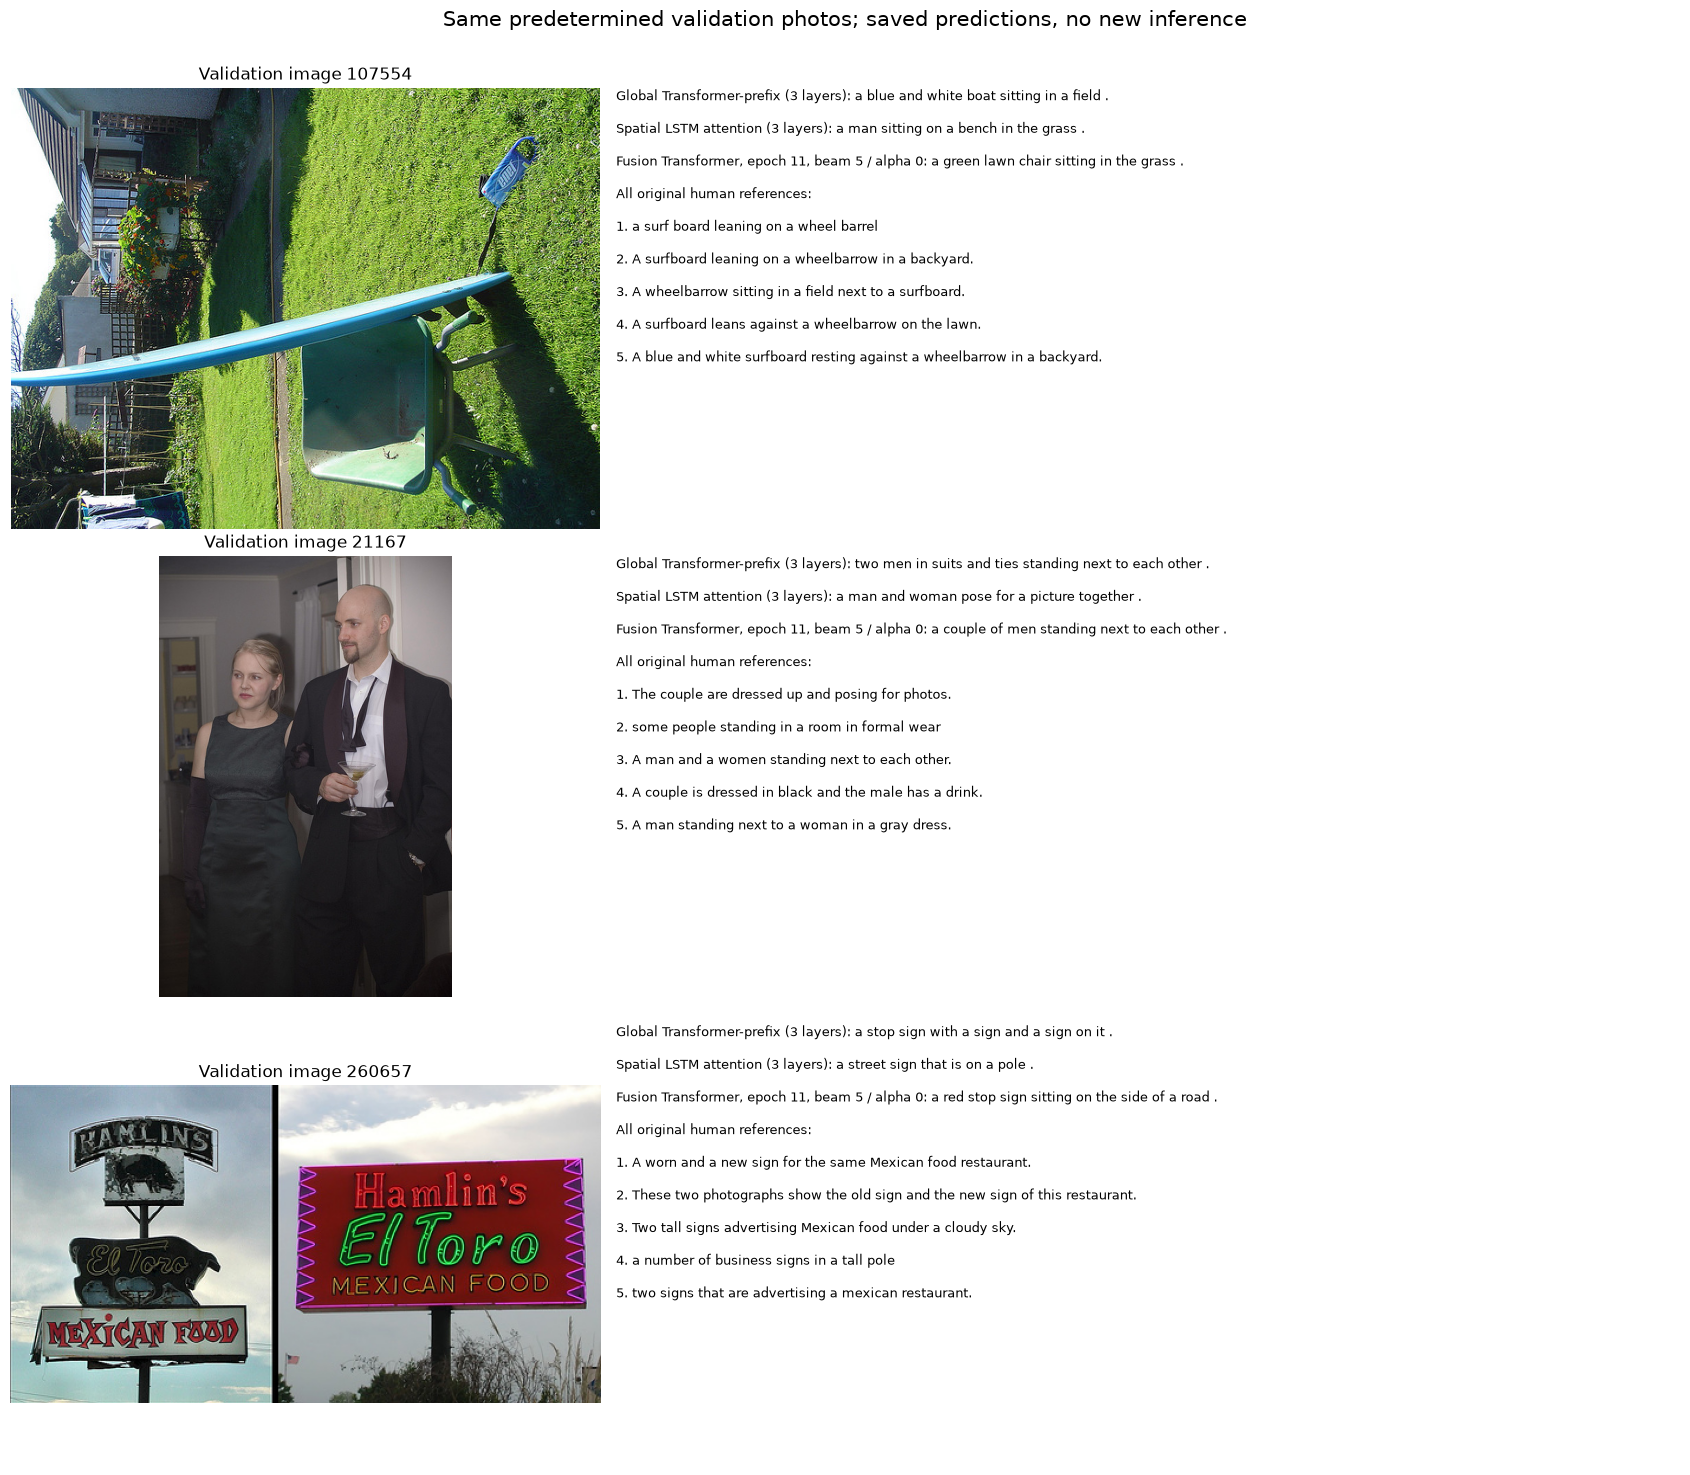

These fixed examples illustrate object and scene errors; three photos do not summarize the full-corpus quality.


In [34]:
report_decoding(PROJECT_DIR)
show_prediction_comparison(PROJECT_DIR,RAW_IMAGE_ROOT);


## 7. Final labeled test

Model and decoding were selected on validation; test metrics are reported for the primary choice and two nearby configurations. This split was excluded from caption training and validation selection; it was not literally never accessed, because an earlier unscored Qwen comparison package contained 100 of its images.

**Pretraining limitation:** all 5,000 labeled test images come from COCO train2017, the same source used for the pretrained detector's COCO detection data. The exact filtered detector training-image manifest was not reconstructed. This is held out from caption-decoder training, but not an independent source from detector pretraining. This matters when comparing with ImageNet-only encoders. The project tokenizer also differs from official COCO leaderboard tokenization.

In [35]:
def project_test_ids(data):
    ids = list(data["split_ids"]["test"])
    if len(ids) != 5000 or len(set(ids)) != 5000 or ids != sorted(ids):
        raise ValueError("Use the saved, sorted 5,000-image labeled project test.")
    if set(ids) & (set(data["split_ids"]["train"]) | set(data["split_ids"]["val"])):
        raise ValueError("The test overlaps training or validation.")
    if data["feature_sources"]["test"] != "train2017":
        raise ValueError("This test must retain its original train2017 image source.")
    if any(not data["references"]["test"].get(image_id) for image_id in ids):
        raise ValueError("Every test image needs its original human references.")
    return ids


def project_test_training_contract(data,project_dir,code_identity):
    path = Path(project_dir)/"cache/features/fasterrcnn_fusion_expanded_v1/cache_plan.json"
    plan = json.loads(path.read_text(encoding="utf-8"))
    config = plan["config"]
    if _fusion_hash(config) != plan["cache_key"]:
        raise ValueError("The original training-region cache plan changed.")
    for key in ["source_id","split_id","annotations_sha256"]:
        if config[key] != data["provenance"][key]:
            raise ValueError(f"Training-region data identity differs: {key}.")
    if config["producer_code_id"] != code_identity["region_producer_code_id"]:
        raise ValueError("The region extraction implementation changed.")
    if config["detector_contract"] != region_feature_contract():
        raise ValueError("Test extraction must use the original detector contract.")
    if config["weights_sha256"] != "258fb6c638b15964ddcdd1ae0748c5eef1be9e732750120cc857feed3faac384":
        raise ValueError("Unexpected detector weights.")
    return {"cache_key": plan["cache_key"],"config": config,
            "plan_sha256": _fusion_file_sha(path)}


def project_test_wrapper_id():
    functions = [project_test_ids,project_test_training_contract,project_test_cache_config,
                 load_project_test_region_cache,extract_project_test_regions]
    source = [ast.dump(ast.parse(textwrap.dedent(inspect.getsource(function)))) for function in functions]
    return _fusion_hash(source)


def project_test_cache_config(data,project_dir,code_identity,device,batch_size=1):
    ids = project_test_ids(data)
    original = project_test_training_contract(data,project_dir,code_identity)
    if type(batch_size) is not int or batch_size != original["config"]["batch_size"]:
        raise ValueError("Use batch size 1, matching the original detector extraction.")
    device = torch.device(device)
    return {
        "version": "fasterrcnn_fusion_labeled_test_v1","evaluation_split": "test",
        "image_source": "train2017","expected_images": 5000,
        "test_ids_sha256": _fusion_hash(ids),"data": data["provenance"],
        "original_training_cache_key": original["cache_key"],
        "original_training_plan_sha256": original["plan_sha256"],
        "producer_code_id": code_identity["region_producer_code_id"],
        "wrapper_implementation_id": project_test_wrapper_id(),
        "weights_sha256": original["config"]["weights_sha256"],
        "detector_contract": original["config"]["detector_contract"],
        "batch_size": batch_size,"device": str(device),
        "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "torch": torch.__version__,"torchvision": torchvision.__version__,
        "cuda_runtime": torch.version.cuda if device.type == "cuda" else None,
        "selection": "All saved labeled test IDs, sorted; no image or caption selection.",
        "pretraining_limitation": "COCO detector pretraining includes train2017. These images are held out from caption-decoder training, not from the complete pretrained visual system.",
    }


def load_project_test_region_cache(data,project_dir,cache_dir,code_identity,verify_hashes=True):
    ids = project_test_ids(data)
    directory = Path(cache_dir)
    plan = json.loads((directory/"cache_plan.json").read_text(encoding="utf-8"))
    config = plan["config"]
    key = _fusion_hash(config)
    original = project_test_training_contract(data,project_dir,code_identity)
    if (plan["cache_key"] != key or plan["planned_ids"] != ids or
            config["evaluation_split"] != "test" or config["image_source"] != "train2017" or
            config["test_ids_sha256"] != _fusion_hash(ids) or config["expected_images"] != 5000 or
            config["data"] != data["provenance"] or
            config["original_training_cache_key"] != original["cache_key"] or
            config["original_training_plan_sha256"] != original["plan_sha256"] or
            config["producer_code_id"] != code_identity["region_producer_code_id"] or
            config["wrapper_implementation_id"] != project_test_wrapper_id() or
            config["detector_contract"] != original["config"]["detector_contract"] or
            config["weights_sha256"] != original["config"]["weights_sha256"]):
        raise ValueError("The test-region cache has incompatible provenance.")
    paths = _fusion_paths(directory,"train2017")
    metadata = json.loads(paths["meta"].read_text(encoding="utf-8"))
    actual_ids = json.loads(paths["ids"].read_text(encoding="utf-8"))
    if (not metadata["complete"] or metadata["cache_key"] != key or
            metadata["config"] != config or metadata["processed"] != 5000 or
            actual_ids != ids or metadata["actual_ids_sha256"] != _fusion_hash(ids)):
        raise ValueError("The labeled test cache is incomplete or contains other image IDs.")
    arrays = {}
    try:
        for name,(shape,dtype) in _fusion_specs(5000).items():
            path = paths["final"][name]
            arrays[name] = np.load(path,mmap_mode="r",allow_pickle=False)
            if arrays[name].shape != shape or arrays[name].dtype != dtype:
                raise ValueError(f"Invalid test array: {name}.")
            if path.stat().st_size != metadata["arrays"][name]["bytes"]:
                raise ValueError(f"Test array size changed: {name}.")
            if verify_hashes and _fusion_file_sha(path) != metadata["arrays"][name]["sha256"]:
                raise ValueError(f"Test array checksum changed: {name}.")
        for first in range(0,5000,256):
            _fusion_validate_chunk({name: array[first:first+256] for name,array in arrays.items()})
    finally:
        _fusion_close(arrays)
    return {**{f"{name}_path": str(path) for name,path in paths["final"].items()},
            "image_ids_path": str(paths["ids"]),"image_ids": ids,"boxes_normalized": True,
            "shape": [5000,36,1024],"cache_key": key,"meta": metadata,
            "evaluation_split": "test","image_source": "train2017"}


def extract_project_test_regions(data,project_dir,cache_dir,raw_root,detector,
                                 code_identity,deadline_utc=None,batch_size=1):
    """All 5,000 are required. Interrupted partial arrays are resumable, never scored."""
    ids = project_test_ids(data)
    if detector.training or any(parameter.requires_grad for parameter in detector.parameters()):
        raise ValueError("The detector must remain frozen and in eval mode.")
    device = next(detector.parameters()).device
    config = project_test_cache_config(data,project_dir,code_identity,device,batch_size)
    if detector.region_feature_metadata["weights_sha256"] != config["weights_sha256"]:
        raise ValueError("Loaded detector weights differ from the training cache.")
    deadline = datetime.max.replace(tzinfo=timezone.utc) if deadline_utc is None else datetime.fromisoformat(str(deadline_utc).replace("Z","+00:00"))
    if deadline.tzinfo is None:
        raise ValueError("Extraction deadline must include a UTC offset.")
    directory = Path(cache_dir)
    original_dir = Path(project_dir)/"cache/features/fasterrcnn_fusion_expanded_v1"
    if directory.resolve() == original_dir.resolve():
        raise ValueError("Use a separate test cache namespace.")
    plan = {"config": config,"cache_key": _fusion_hash(config),"planned_ids": ids}
    directory.mkdir(parents=True,exist_ok=True)
    path = directory/"cache_plan.json"
    if path.exists():
        if json.loads(path.read_text(encoding="utf-8")) != plan:
            raise ValueError("Existing test cache belongs to another extraction configuration.")
    else:
        if any(directory.iterdir()):
            raise ValueError("Use an empty new test cache directory.")
        _fusion_json(path,plan)
    required = 2*sum(int(np.prod(shape))*dtype.itemsize for shape,dtype in _fusion_specs(5000).values())
    existing = sum(path.stat().st_size for path in directory.glob("*.npy"))
    if shutil.disk_usage(directory).free < max(0,required-existing)+2*1024**3:
        raise OSError("Insufficient space for test features, recovery arrays and a 2 GiB reserve.")
    _fusion_extract_source(data,detector,directory,raw_root,"train2017",ids,
                           deadline,batch_size,5000,config)
    result = load_project_test_region_cache(data,project_dir,directory,code_identity)
    _fusion_json(directory/"test_cache_report.json",{
        "status": "complete","images": 5000,"evaluation_split": "test","image_source": "train2017",
        "test_ids_sha256": _fusion_hash(ids),"cache_key": result["cache_key"],
        "all_array_hashes_and_masks_verified": True,
        "elapsed_seconds": result["meta"]["elapsed_seconds"],
        "statistics": result["meta"]["statistics"],"pretraining_limitation": config["pretraining_limitation"]})
    return result


def inspect_project_test_cache(project_dir,raw_root,cache_dir,code_identity):
    data = load_region_prepared_data(project_dir,raw_root)
    ids = project_test_ids(data)
    original = project_test_training_contract(data,project_dir,code_identity)
    grids = load_final_grid_features(data,project_dir)
    source = grids["train2017"]
    if not set(ids) <= set(source["image_ids"]) or not set(ids) <= set(source["global_image_ids"]):
        raise ValueError("Some test images are missing from the original global/spatial cache.")
    _fusion_annotation_records(data,"train2017",ids,raw_root)
    report = {"status": "ready_for_extraction","test_images": len(ids),"test_ids_sha256": _fusion_hash(ids),
              "image_source": "train2017","evaluation_split": "test","overlap_with_train_or_val": 0,
              "existing_global_and_grid_images": len(ids),"all_original_jpegs_present": True,
              "training_region_cache_key": original["cache_key"],"producer_code_id": code_identity["region_producer_code_id"],
              "wrapper_implementation_id": project_test_wrapper_id(),"cache_dir": str(Path(cache_dir)),
              "estimated_extraction_minutes": 8,"gpu_executed": False}
    if (Path(cache_dir)/"train2017_meta.json").exists():
        entry = load_project_test_region_cache(data,project_dir,cache_dir,code_identity)
        report.update(status="complete",cache_key=entry["cache_key"])
    return report


In [36]:
class FusionLabeledTestDataset(Dataset):
    """Read test image features only. Human captions are carried as scoring references."""
    def __init__(self,data,grid_files,region_entry):
        self.data = data
        self.image_ids = project_test_ids(data)
        if region_entry["evaluation_split"] != "test" or region_entry["image_ids"] != self.image_ids:
            raise ValueError("Use the dedicated complete test-region cache.")
        grid = grid_files["train2017"]
        self.grid_rows = {image_id: row for row,image_id in enumerate(grid["image_ids"])}
        self.global_rows = {image_id: row for row,image_id in enumerate(grid["global_image_ids"])}
        self.region_rows = {image_id: row for row,image_id in enumerate(region_entry["image_ids"])}
        if not all(image_id in self.grid_rows and image_id in self.global_rows for image_id in self.image_ids):
            raise ValueError("Missing test grid or original global feature.")
        paths = {"grid": grid["path"],"global_features": grid["global_path"],
                 "regions": region_entry["features_path"],"region_mask": region_entry["mask_path"],
                 "region_boxes": region_entry["normalized_boxes_path"]}
        self.arrays = {}
        try:
            for name,path in paths.items():
                self.arrays[name] = np.load(path,mmap_mode="r",allow_pickle=False)
            expected = {"grid": ((len(self.grid_rows),49,2048),np.float16),
                        "global_features": ((len(self.global_rows),2048),np.float32),
                        "regions": ((5000,36,1024),np.float16),
                        "region_mask": ((5000,36),np.bool_),"region_boxes": ((5000,36,4),np.float32)}
            for name,(shape,dtype) in expected.items():
                if self.arrays[name].shape != shape or self.arrays[name].dtype != dtype:
                    raise ValueError(f"Unexpected test feature array {name}.")
        except BaseException:
            self.close()
            raise
        self.provenance = {"evaluation_split": "test","image_source": "train2017",
            "test_ids_sha256": beam_eval_hash(self.image_ids),"grid_cache_key": grid["cache_key"],
            "global_cache_key": grid["global_cache_key"],"region_cache_key": region_entry["cache_key"],
            "grid_meta_sha256": grid["grid_meta_sha256"],"global_meta_sha256": grid["global_meta_sha256"],
            "region_arrays": region_entry["meta"]["arrays"],"region_config": region_entry["meta"]["config"],
            "paths": {name: str(Path(path).resolve()) for name,path in paths.items()}}

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self,index):
        image_id = self.image_ids[index]
        grid_row,global_row,region_row = self.grid_rows[image_id],self.global_rows[image_id],self.region_rows[image_id]
        item = {}
        for name,row in [("grid",grid_row),("global_features",global_row),("regions",region_row),
                          ("region_mask",region_row),("region_boxes",region_row)]:
            value = torch.from_numpy(self.arrays[name][row].copy())
            item[name] = value if name == "region_mask" else value.float()
        item["image_id"] = image_id
        item["references"] = self.data["references"]["test"][image_id]
        return item

    def close(self):
        for array in self.arrays.values():
            array._mmap.close()
        self.arrays = {}


def final_test_collate(items):
    result = {name: torch.stack([item[name] for item in items])
              for name in ["grid","global_features","regions","region_mask","region_boxes"]}
    result.update(image_ids=[item["image_id"] for item in items],
                  references=[item["references"] for item in items])
    return result


def final_test_manifest(path):
    path = Path(path)
    manifest = json.loads(path.read_text(encoding="utf-8"))
    if manifest["split"] != "saved_labeled_project_test" or manifest["expected_images"] != 5000:
        raise ValueError("The frozen candidate manifest must name the saved labeled test.")
    source = Path(manifest["selection_source"])
    if beam_eval_file_sha(source) != manifest["selection_source_sha256"]:
        raise ValueError("The original validation selection changed.")
    selection = json.loads(source.read_text(encoding="utf-8"))
    candidates = manifest["candidates"]
    if not 1 <= len(candidates) <= 3 or candidates[0]["role"] != "primary_validation_selected":
        raise ValueError("Freeze one validation-selected primary and at most two comparison candidates.")
    names = []
    previous_score = math.inf
    for index,row in enumerate(candidates):
        if row["role"] != ("primary_validation_selected" if index == 0 else "exploratory_comparator"):
            raise ValueError("Only the first candidate may be the fixed primary.")
        if type(row["beam_size"]) is not int or row["beam_size"] < 2:
            raise ValueError("Unexpected frozen beam width.")
        if not math.isfinite(row["length_penalty"]) or row["length_penalty"] < 0 or row["max_steps"] != 33:
            raise ValueError("Unexpected frozen generation settings.")
        if row["scores"]["cider_d"] > previous_score:
            raise ValueError("Candidates must retain their validation ranking.")
        previous_score = row["scores"]["cider_d"]
        names.append(f"epoch{row['snapshot_epoch']}_{row['mode']}")
    if len(names) != len(set(names)):
        raise ValueError("Duplicate candidate output names.")
    ranked = sorted(selection["candidates"],key=lambda row: row["scores"]["cider_d"],reverse=True)
    for candidate,selected in zip(candidates,ranked):
        if {key: value for key,value in candidate.items() if key != "role"} != selected:
            raise ValueError("The candidate manifest differs from the original top validation rows.")
    if {key: value for key,value in candidates[0].items() if key != "role"} != selection["selected"]:
        raise ValueError("The primary differs from the original validation-selected winner.")
    return manifest


def final_test_validate_records(records,expected_ids,data,max_steps=33):
    if [row["image_id"] for row in records] != list(expected_ids):
        raise ValueError("Test predictions do not match the exact saved test ID order.")
    vocabulary = data["id_to_token"]
    forbidden = {data["ids"][name] for name in ["pad","start","end"]}
    for row in records:
        tokens = row["token_ids"]
        if (not isinstance(tokens,list) or len(tokens) > max_steps or
                any(type(token) is not int or token in forbidden or not 0 <= token < len(vocabulary) for token in tokens)):
            raise ValueError("Invalid generated test token IDs.")
        if row["prediction"] != " ".join(vocabulary[token] for token in tokens):
            raise ValueError("Stored test text differs from its generated token IDs.")
        if row["references"] != data["references"]["test"][row["image_id"]]:
            raise ValueError("Test human references changed or were vocabulary-mapped.")


def final_test_load_snapshot(candidate,data,evaluator,grids,original_contract,code_identity):
    folder = Path(candidate["snapshot_folder"])
    metadata = json.loads((folder/"snapshot.json").read_text(encoding="utf-8"))
    path = folder/"best.pt"
    expected = candidate["checkpoint_sha256"]
    if metadata["full_checkpoint_sha256"] != expected or beam_eval_file_sha(path) != expected:
        raise ValueError("The pinned test candidate checkpoint changed.")
    payload = torch.load(path,map_location="cpu",weights_only=False)
    if beam_eval_file_sha(path) != expected:
        raise ValueError("Checkpoint changed while loading.")
    identity,state = payload["identity"],payload["state"]
    if (payload["format_version"] != 1 or identity["data"] != data["provenance"] or
            identity["metrics"] != evaluator.metadata or
            identity["train_ids"] != sorted(data["split_ids"]["train"]) or
            identity["validation_ids"] != data["split_ids"]["val"]):
        raise ValueError("Candidate used another dataset, split or scorer.")
    ids = project_test_ids(data)
    if set(ids) & (set(identity["train_ids"]) | set(identity["validation_ids"])):
        raise ValueError("Test exposure in caption decoder training or selection.")
    trained = identity["config"]
    if (trained["code"]["models_sha256"] != code_identity["models_sha256"] or
            trained["code"]["region_producer_code_id"] != code_identity["region_producer_code_id"] or
            identity["grid_and_region_data"]["train"]["grid_cache_key"] != grids["train2017"]["cache_key"] or
            identity["grid_and_region_data"]["train"]["region_cache_key"] != original_contract["cache_key"]):
        raise ValueError("Model implementation or visual feature contract differs from training.")
    if (state["epoch"] != state["best_epoch"] or state["epoch"] != candidate["snapshot_epoch"] or
            metadata["snapshot_epoch"] != state["epoch"] or metadata["best_epoch"] != state["best_epoch"] or
            metadata["best_record"] != state["best_record"]):
        raise ValueError("Pinned checkpoint epoch or best-record metadata differs.")
    if not all(bool(torch.isfinite(value).all()) for value in payload["model"].values() if value.is_floating_point()):
        raise FloatingPointError("Nonfinite checkpoint model weights.")
    return payload,metadata


def final_test_completed_chunks(folder,identity_sha,name,data,ids,batch_size,max_steps):
    chunk_dir = Path(folder)/"chunks"
    expected = {f"batch_{first:05d}_{min(first+batch_size,len(ids)):05d}.json"
                for first in range(0,len(ids),batch_size)}
    if any(path.name not in expected for path in chunk_dir.glob("*.json")):
        raise ValueError("Unexpected test chunk filename.")
    records,seconds,gap = [],0.0,False
    for first in range(0,len(ids),batch_size):
        last = min(first+batch_size,len(ids))
        path = chunk_dir/f"batch_{first:05d}_{last:05d}.json"
        if not path.exists():
            gap = True
            continue
        if gap:
            raise ValueError("Test chunks contain a gap.")
        chunk = json.loads(path.read_text(encoding="utf-8"))
        if (chunk["identity_sha256"] != identity_sha or chunk["candidate"] != name or
                chunk["first_index"] != first or chunk["last_index"] != last or
                not math.isfinite(chunk["generation_seconds"]) or chunk["generation_seconds"] < 0):
            raise ValueError("Test chunk identity, interval or timing differs.")
        final_test_validate_records(chunk["records"],ids[first:last],data,max_steps)
        records.extend(chunk["records"])
        seconds += chunk["generation_seconds"]
    return records,seconds


@torch.no_grad()
def final_test_evaluate_candidate(model,dataset,data,evaluator,candidate,config,
                                  device,output_dir,identity_sha,max_new_batches=None):
    name = f"epoch{candidate['snapshot_epoch']}_{candidate['mode']}"
    folder = Path(output_dir)/name
    (folder/"chunks").mkdir(parents=True,exist_ok=True)
    records,generation_seconds = final_test_completed_chunks(folder,identity_sha,name,data,
        dataset.image_ids,config["batch_size"],candidate["max_steps"])
    loader = DataLoader(Subset(dataset,range(len(records),len(dataset))),batch_size=config["batch_size"],
        shuffle=False,num_workers=0,collate_fn=final_test_collate,
        generator=torch.Generator().manual_seed(42),pin_memory=device.type == "cuda")
    model.eval()
    new_batches = 0
    iterator = iter(loader)
    while len(records) < len(dataset):
        if max_new_batches is not None and new_batches >= max_new_batches:
            break
        if device.type == "cuda": torch.cuda.synchronize(device)
        started = time.perf_counter()
        batch = next(iterator)
        moved = fusion_device_batch(batch,device)
        with torch.autocast(device_type=device.type,enabled=config["amp_enabled"]):
            tokens = fusion_beam_search(model,moved["grid"],moved["regions"],
                data["ids"]["start"],data["ids"]["end"],max_steps=candidate["max_steps"],
                region_mask=moved["region_mask"],region_boxes=moved["region_boxes"],
                global_features=moved["global_features"],beam_size=candidate["beam_size"],
                length_penalty=candidate["length_penalty"])
        if len(tokens) != len(batch["image_ids"]):
            raise ValueError("Different numbers of test images and generated captions.")
        rows = [{"image_id": int(image_id),"token_ids": row,
                 "prediction": " ".join(data["id_to_token"][token] for token in row),"references": refs}
                for image_id,row,refs in zip(batch["image_ids"],tokens,batch["references"])]
        if device.type == "cuda": torch.cuda.synchronize(device)
        seconds = time.perf_counter()-started
        first,last = len(records),len(records)+len(rows)
        final_test_validate_records(rows,dataset.image_ids[first:last],data,candidate["max_steps"])
        beam_eval_json(folder/"chunks"/f"batch_{first:05d}_{last:05d}.json",{
            "identity_sha256": identity_sha,"candidate": name,"first_index": first,"last_index": last,
            "generation_seconds": seconds,"records": rows})
        records.extend(rows)
        generation_seconds += seconds
        new_batches += 1
        beam_eval_json(folder/"progress.json",{"status": "generating","identity_sha256": identity_sha,
            "images": len(records),"required_images": len(dataset),"generation_seconds": generation_seconds,
            "metrics_computed": False})
        if new_batches == 1 or new_batches % 20 == 0 or len(records) == len(dataset):
            print(f"TEST {name}: {len(records):,}/{len(dataset):,} | generation {generation_seconds:.1f}s",flush=True)
        del batch,moved,tokens
    if len(records) != len(dataset):
        result = {"status": "partial","candidate": name,"images": len(records),
                  "required_images": len(dataset),"metrics_computed": False,"generation_seconds": generation_seconds}
        beam_eval_json(folder/"progress.json",result)
        return result
    final_test_validate_records(records,dataset.image_ids,data,candidate["max_steps"])
    if len(records) != 5000:
        raise ValueError("Never compute final test scores on a partial test set.")
    predictions_sha = beam_eval_hash(records)
    prediction_path = folder/"test_predictions.json"
    if prediction_path.exists():
        if beam_eval_hash(json.loads(prediction_path.read_text(encoding="utf-8"))) != predictions_sha:
            raise ValueError("Final test predictions differ from committed chunks.")
    else:
        beam_eval_json(prediction_path,records)
    metrics_path = folder/"metrics.json"
    if metrics_path.exists():
        result = json.loads(metrics_path.read_text(encoding="utf-8"))
        if (result["identity_sha256"] != identity_sha or result["predictions_sha256"] != predictions_sha or
                result["status"] != "complete" or result["candidate"] != name or result["images"] != 5000 or
                set(result["scores"]) != {"bleu1","bleu4","cider_d"} or
                not all(math.isfinite(float(value)) for value in result["scores"].values())):
            raise ValueError("Stored test metrics do not match this full corpus.")
        return result
    started = time.perf_counter()
    scores = evaluator.score(records,expected_ids=dataset.image_ids)
    if set(scores) != {"bleu1","bleu4","cider_d"} or not all(math.isfinite(float(value)) for value in scores.values()):
        raise ValueError("Unexpected or nonfinite test metrics.")
    result = {"status": "complete","candidate": name,"role": candidate["role"],"images": 5000,
              "identity_sha256": identity_sha,"scores": scores,"validation_scores": candidate["scores"],
              "generation_seconds": generation_seconds,"metric_seconds": time.perf_counter()-started,
              "predictions_sha256": predictions_sha,"predictions_file": str(prediction_path.resolve()),
              "metrics_computed": True}
    beam_eval_json(metrics_path,result)
    beam_eval_json(folder/"progress.json",result)
    return result


def run_fusion_final_test(project_dir,candidate_manifest,output_dir,raw_root=None,cache_dir=None,
                           code_identity=None,batch_size=64,amp=True,device=None,max_new_batches=None):
    """Score predeclared candidates; the primary model is never selected using test scores."""
    if type(batch_size) is not int or batch_size < 1:
        raise ValueError("Use a positive evaluation batch size.")
    if max_new_batches is not None and (type(max_new_batches) is not int or max_new_batches < 1):
        raise ValueError("max_new_batches must be a positive integer.")
    code_identity = code_identity or globals().get("EXPECTED_CODE_IDENTITY")
    if not code_identity:
        raise ValueError("Provide the verified Fusion model and producer code identity.")
    project_dir,output_dir = Path(project_dir),Path(output_dir)
    cache_dir = Path(cache_dir) if cache_dir is not None else project_dir/"cache/features/fasterrcnn_fusion_labeled_test_v1"
    manifest = final_test_manifest(candidate_manifest)
    if any(row["evaluation_batch_size"] != batch_size or row["amp"] != bool(amp) for row in manifest["candidates"]):
        raise ValueError("Use the same fixed batch size and AMP setting as the validation candidates.")
    if output_dir.exists() and any(output_dir.iterdir()) and not (output_dir/"evaluation_identity.json").is_file():
        raise ValueError("Use a new empty test-output directory or resume its saved identity.")
    output_dir.mkdir(parents=True,exist_ok=True)
    dataset = model = None
    started = time.perf_counter()
    with beam_evaluation_lock(output_dir):
        try:
            data = load_region_prepared_data(project_dir,raw_root)
            ids = project_test_ids(data)
            evaluator = MetricEvaluator(data["text_settings"])
            grids = load_final_grid_features(data,project_dir)
            original = project_test_training_contract(data,project_dir,code_identity)
            regions = load_project_test_region_cache(data,project_dir,cache_dir,code_identity,verify_hashes=True)
            dataset = FusionLabeledTestDataset(data,grids,regions)
            device = torch.device(device if device is not None else ("cuda:0" if torch.cuda.is_available() else "cpu"))
            details = {"device": str(device),"gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                       "torch": torch.__version__,"cuda_runtime": torch.version.cuda,"cpu_threads": torch.get_num_threads()}
            config = {"seed": 42,"batch_size": batch_size,"amp": bool(amp),
                      "amp_enabled": bool(amp and device.type == "cuda"),"split": "test","required_images": 5000,
                      "policy": "Candidates and primary frozen on validation before test. No test-based model selection."}
            identity = {"config": config,"candidates": manifest,"candidate_manifest_sha256": beam_eval_file_sha(candidate_manifest),
                        "data": data["provenance"],"test_ids": ids,"cache": dataset.provenance,
                        "scorer": evaluator.metadata,"device": details,"model_source_sha256": code_identity["models_sha256"],
                        "beam_implementation_id": beam_eval_function_id([fusion_beam_search]),
                        "test_implementation_id": beam_eval_function_id([FusionLabeledTestDataset.__init__,
                            FusionLabeledTestDataset.__len__,FusionLabeledTestDataset.__getitem__,
                            FusionLabeledTestDataset.close,final_test_collate,
                            final_test_manifest,final_test_validate_records,final_test_load_snapshot,
                            final_test_completed_chunks,final_test_evaluate_candidate,run_fusion_final_test])}
            identity_path = output_dir/"evaluation_identity.json"
            if identity_path.exists() and json.loads(identity_path.read_text(encoding="utf-8")) != identity:
                raise ValueError("Existing test output belongs to different data, candidates, code or device settings.")
            beam_eval_json(identity_path,identity)
            beam_eval_json(output_dir/"frozen_test_candidates.json",manifest)
            beam_eval_json(output_dir/"test_image_ids.json",ids)
            beam_eval_json(output_dir/"scorer.json",evaluator.metadata)
            identity_sha = beam_eval_hash(identity)
            results,loaded_sha = {},None
            for candidate in manifest["candidates"]:
                name = f"epoch{candidate['snapshot_epoch']}_{candidate['mode']}"
                if candidate["checkpoint_sha256"] != loaded_sha:
                    model = None
                    gc.collect()
                    if device.type == "cuda": torch.cuda.empty_cache()
                    payload,snapshot = final_test_load_snapshot(candidate,data,evaluator,grids,original,code_identity)
                    trained = payload["identity"]["config"]
                    fusion_seed(42)
                    model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"],
                        grid_feature_dim=trained["grid_feature_dim"],region_feature_dim=trained["region_feature_dim"],
                        d_model=trained["d_model"],num_layers=trained["num_layers"],nhead=trained["nhead"],
                        dim_feedforward=trained["dim_feedforward"],dropout=trained["dropout"],
                        grid_size=trained["grid_size"],max_regions=trained["max_regions"],max_positions=34)
                    model.load_state_dict(payload["model"],strict=True)
                    model.requires_grad_(False)
                    model = model.to(device).eval()
                    loaded_sha = candidate["checkpoint_sha256"]
                    del payload
                    beam_eval_json(output_dir/f"snapshot_epoch{candidate['snapshot_epoch']}.json",snapshot)
                fusion_seed(42)
                results[name] = final_test_evaluate_candidate(model,dataset,data,evaluator,candidate,config,
                    device,output_dir,identity_sha,max_new_batches=max_new_batches)
            complete = all(row["status"] == "complete" for row in results.values())
            primary = manifest["candidates"][0]
            primary_name = f"epoch{primary['snapshot_epoch']}_{primary['mode']}"
            summary = {"status": "complete" if complete else "partial","identity_sha256": identity_sha,
                "split": "saved_labeled_project_test","test_images": 5000,"results": results,
                "primary_selected_by_validation": primary_name,"test_based_reselection": False,
                "comparison_scope": "Exploratory comparison of three candidates fixed using validation before test inference.",
                "pretraining_limitation": manifest["pretraining_limitation"],"device": details,
                "this_invocation_wall_seconds": time.perf_counter()-started,
                "generation_seconds_sum": sum(row["generation_seconds"] for row in results.values()),
                "metric_seconds_sum": sum(row.get("metric_seconds",0.0) for row in results.values()),
                "timing_note": "Generation includes feature reads, copies and decoding. Saved cumulative candidate times exclude pauses; invocation wall time includes setup and verification.",
                "model_training_performed": False,"original_checkpoints_modified": False}
            beam_eval_json(output_dir/"test_comparison.json",summary)
            if complete:
                with (output_dir/"test_comparison.csv").open("w",newline="",encoding="utf-8") as stream:
                    fields = ["candidate","role","test_images","bleu1","bleu4","cider_d","validation_cider_d",
                              "generation_seconds","metric_seconds","device","gpu"]
                    writer = csv.DictWriter(stream,fieldnames=fields)
                    writer.writeheader()
                    for name,row in results.items():
                        writer.writerow({"candidate": name,"role": row["role"],"test_images": 5000,**row["scores"],
                            "validation_cider_d": row["validation_scores"]["cider_d"],
                            "generation_seconds": row["generation_seconds"],"metric_seconds": row["metric_seconds"],
                            "device": details["device"],"gpu": details["gpu"]})
            return summary
        finally:
            if dataset is not None: dataset.close()
            model = None
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()


In [37]:
FINAL_TEST_ROOT=PROJECT_DIR/"experiments"/"final_test_fusion_v1"
FINAL_TEST_MANIFEST=PROJECT_DIR/"submission_assets"/"frozen_test_candidates.json"
FINAL_TEST_RESULTS_DIR=FINAL_TEST_ROOT
if RUN_FINAL_TEST:
    test_previous_threads=torch.get_num_threads()
    try:
        torch.set_num_threads(2)
        final_test_result=run_fusion_final_test(
            PROJECT_DIR,FINAL_TEST_MANIFEST,FINAL_TEST_RESULTS_DIR,
            raw_root=RAW_IMAGE_ROOT,code_identity=EXPECTED_CODE_IDENTITY,
            batch_size=64,amp=True,device="cuda:0",
        )
    finally:
        torch.set_num_threads(test_previous_threads)


Fixed candidate,Role,Test BLEU-1,Test BLEU-4,Test CIDEr-D,Validation CIDEr-D,Generation seconds,Scoring seconds
epoch11_beam5_alpha0,primary_validation_selected,0.74916,0.32615,0.99839,0.98013,88.97164,10.76172
epoch11_beam7_alpha0,exploratory_comparator,0.74723,0.32505,0.99428,0.97981,104.85573,7.89257
epoch11_beam5_alpha0p3,exploratory_comparator,0.74471,0.32214,0.99763,0.97915,69.71364,4.94525


Model and decoding selected on validation: epoch11_beam5_alpha0 | Test metrics reported above.
The test uses the same COCO train2017 source as detector pretraining. Exact overlap with its original filtered training manifest was not reconstructed.
Device: NVIDIA GeForce RTX 4060 Laptop GPU | Invocation seconds: 303.9
Generation includes feature reads, copies and decoding. Saved cumulative candidate times exclude pauses; invocation wall time includes setup and verification.


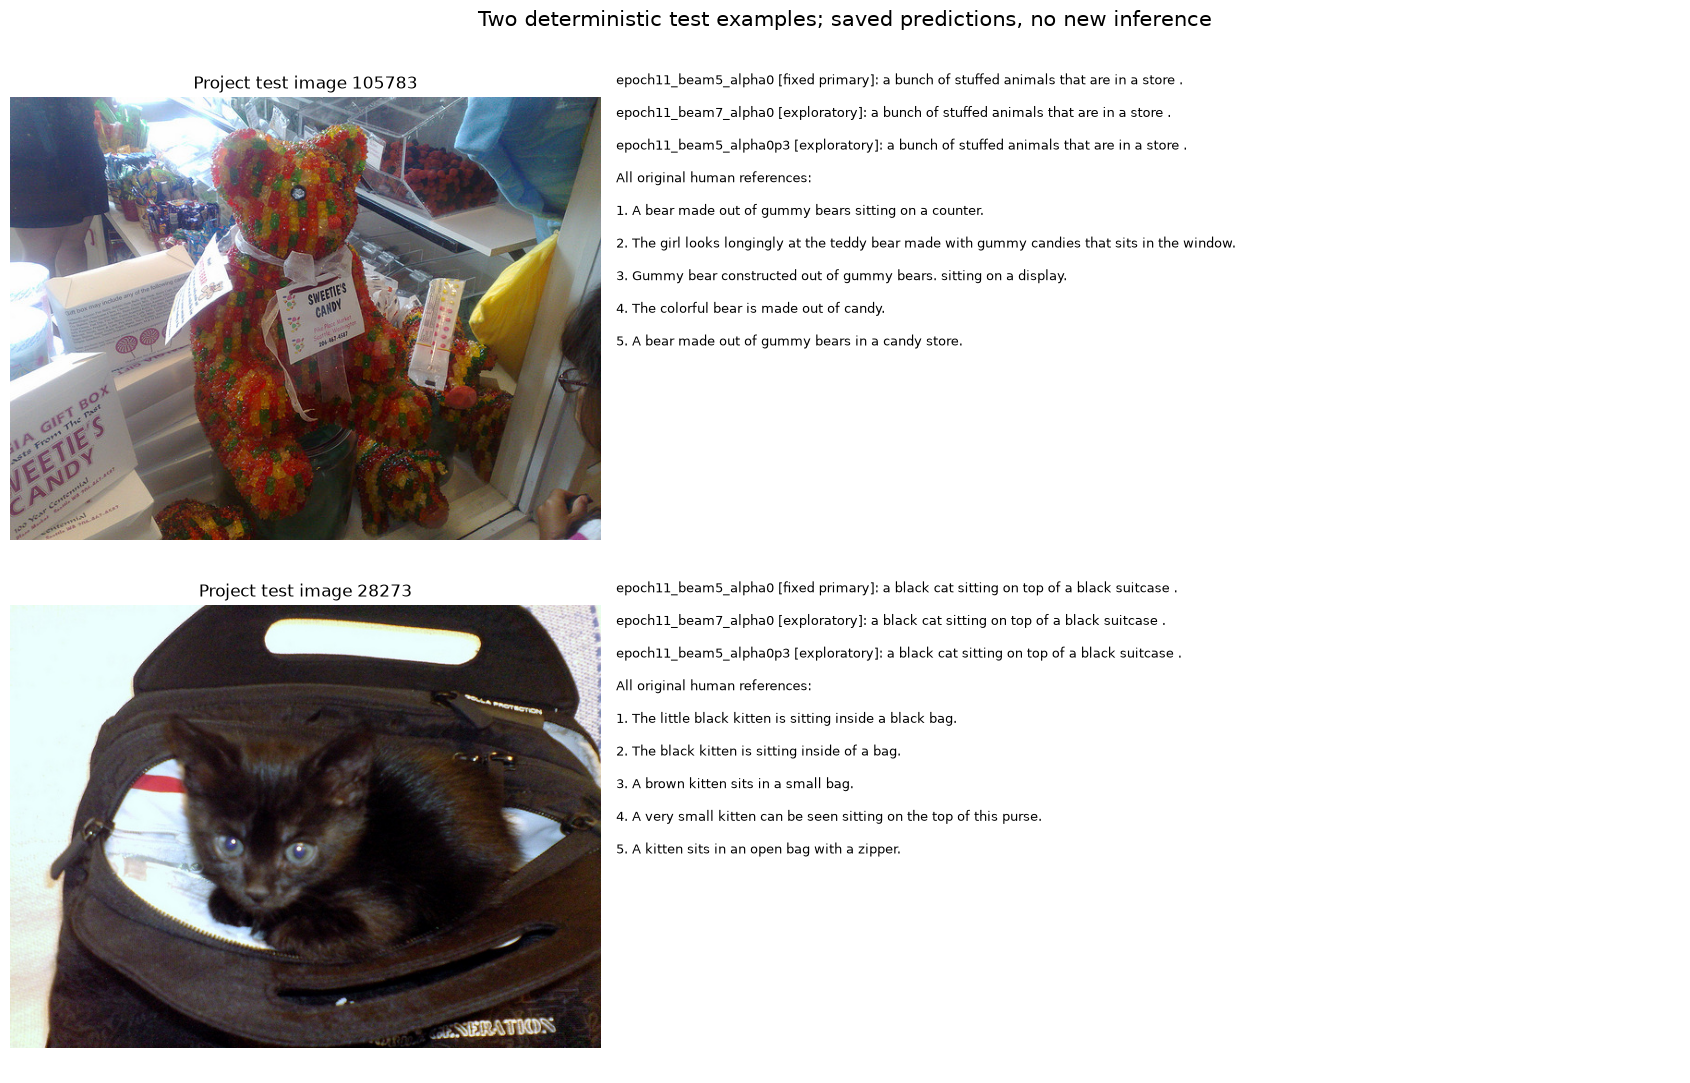

In [38]:
report_final_test(PROJECT_DIR,RAW_IMAGE_ROOT,FINAL_TEST_RESULTS_DIR);


### Verification and limitations

The original notebooks, feature caches and weights are preserved. The merged notebook keeps model ASTs and Fusion checkpoint fingerprints unchanged; baseline and spatial helpers use separate namespaces. CPU checks compared all 79 global configurations, both spatial configurations and the spatial model-source hash with the saved versions. Shared beam decoding was checked against the original algorithm, including real GPU batches. Report execution uses a fresh CPU-only Jupyter kernel; it does not retrain or regenerate captions.

Results are single-seed experiments. Different devices, warm starts, training durations and changes to both visual representation and normalization limit causal architecture comparisons. The interrupted spatial Transformer is not a completed comparison. Both Stage 5 runs have archived source, finite weights, complete histories and independently rescored validation predictions. Examples illustrate both successes and errors and cannot replace corpus metrics.

The saved tables and image outputs are embedded, so this notebook opens as one submission file. Running it again requires the original project data, caches and result files plus the recorded Python dependencies; multi-gigabyte datasets and checkpoints are not embedded in the notebook. No external Python helper module or original notebook is executed by this submission.

## 8. Analysis of model choices

This section explains what changed in our experiments. All quality comparisons below use **validation CIDEr-D**, on its native scale. Higher is better. The best epoch is the checkpoint with the highest validation CIDEr-D. The stop epoch is the last completed epoch before early stopping. With patience 3, the completed runs stopped three epochs after their best checkpoint.

We used one seed per configuration. These results describe our runs; they do not prove that the same ranking will hold for every dataset or seed. Fewer epochs alone do not mean better or faster learning.

### Attention: earlier stopping, but lower quality

| ResNet50 decoder | Visual input | Best epoch | Stop epoch | CIDEr-D |
|---|---|---:|---:|---:|
| LSTM, 3 layers | One global vector | 22 | 25 | 0.8081 |
| LSTM with spatial attention, 3 layers | 49 spatial vectors | 16 | 19 | 0.7802 |

The spatial attention model stopped **six epochs earlier**, but its CIDEr-D was **3.45% lower**. It reached a lower quality plateau. This is not evidence that it learned the task faster. The experiment also changed the visual input and the way the image was passed to the decoder, so it does not isolate attention alone.

The attention model had 18.66 million trainable parameters, compared with 17.61 million for the global-vector LSTM. Recorded training time increased from 36 minutes 41 seconds to 3 hours 37 minutes. Attention adds work over the 49 image positions at each word step. However, the laptop runs did not have tightly controlled workload conditions, so the full time difference cannot be attributed to architecture alone.

The separate spatial cross-attention Transformer completed only one epoch before interruption. It is not a completed comparison and cannot be used to judge the architecture.

### Depth: three layers worked best

All rows below use the same cached global ResNet50 features.

| Layers | LSTM CIDEr-D | LSTM best / stop | Transformer-prefix CIDEr-D | Transformer best / stop |
|---:|---:|---:|---:|---:|
| 1 | 0.7849 | 16 / 19 | 0.8047 | 6 / 9 |
| 2 | 0.8047 | 11 / 14 | 0.8085 | 5 / 8 |
| 3 | 0.8081 | 22 / 25 | 0.8578 | 21 / 24 |
| 4 | 0.7670 | 10 / 13 | 0.8387 | 16 / 19 |

Three layers gave the best quality for both decoders. For LSTM, the gain from two to three layers was small. For the Transformer, the third layer gave a larger improvement. A fourth layer added parameters but reduced quality.

Depth did not have a simple effect on epoch count. The three-layer LSTM needed 25 epochs, while the four-layer LSTM stopped after 13 with a worse score. The four-layer Transformer also stopped earlier than the three-layer version and scored lower. Earlier stopping can mean that improvement stopped early, rather than that the model learned more efficiently.

### Dropout and LayerNorm

Each row compares 15 matched pairs from the original grid: five CNNs and three decoder types. Within each pair, the encoder and decoder type stay the same. A positive epoch change means that the best checkpoint occurred later. These averages describe the tested runs, not a general speed advantage.

| Change from baseline | Higher CIDEr-D | Mean CIDEr-D change | Mean change in best epoch |
|---|---:|---:|---:|
| One layer to two layers | 10 / 15 | +0.0084 | +0.20 |
| Dropout 0.3 to 0.5 | 0 / 15 | -0.0415 | +0.53 |
| Visual projection LayerNorm | 12 / 15 | +0.0316 | +1.40 |
| Smaller hidden / model width | 0 / 15 | -0.0334 | +1.00 |

**Dropout 0.5 did not help.** It reduced CIDEr-D in all 15 comparisons. The best epoch occurred about half an epoch later on average, so the extra regularization did not give a useful quality or epoch-count benefit here. Dropout 0.3 was the better setting in this grid.

**LayerNorm helped RNN and LSTM more consistently than Transformer.** It improved all five RNN and all five LSTM combinations, but only two of five Transformer combinations. The overall gain was +0.0316 CIDEr-D, with the best checkpoint 1.4 epochs later on average. This is mainly evidence of better quality, not faster convergence.

The smaller configurations reduced capacity but scored lower in all 15 comparisons. RNN/LSTM hidden size changed from 512 to 256 while their word embeddings stayed at 512. For Transformer, both model and embedding width changed from 512 to 256.

The strongest LayerNorm effect appeared in the region-feature experiment:

| Faster R-CNN + LSTM attention | Best epoch | Stop epoch | CIDEr-D |
|---|---:|---:|---:|
| Original protocol | 1 | 4 | 0.0514 |
| LayerNorm after visual projection | 25 | 28 | 0.8185 |

The original model produced the same caption for all validation images. With LayerNorm, it continued improving and produced varied captions. The change added only 1,024 parameters. More training epochs were useful here: the normalized model kept learning instead of stopping at a poor plateau. The loop audit in Section 4 supports correct optimizer coverage and loss normalization, and the problem also appeared without AMP. It does not establish one complete explanation for the original failure.

### Fusion and decoding

The three-layer global Transformer-prefix reached validation CIDEr-D 0.8578. The fusion model reached 0.9415 with greedy decoding, a 9.75% increase. Fusion used both ResNet50 spatial vectors and Faster R-CNN region vectors.

The fusion run started from the prefix model's checkpoint at epoch 21. Its 13 completed epochs were **additional training**, and the run was stopped manually during epoch 14. Therefore, it did not learn from scratch in only 13 epochs. We did not train a matching prefix-only continuation, so we cannot separate the effect of extra training from the effect of fusion. Detector pretraining also differs from the original ImageNet CNN setup.

Beam search improved generation without more training. On the **same epoch-11 fusion checkpoint**, greedy decoding scored 0.9380 and beam size 5 with no length normalization scored 0.9801, an increase of about 4.49%. This is a decoding improvement using the same weights; it requires more work during generation.

### Final conclusions

- Spatial attention did not improve our LSTM result. It stopped earlier, but at lower quality.
- Three layers were the best tested depth for the global ResNet50 LSTM and Transformer. Four layers were not better.
- Dropout 0.3 worked better than 0.5 in all matched comparisons. Stronger regularization was not automatically useful.
- Visual LayerNorm consistently helped the recurrent decoders and was especially useful for the region-feature model. Its effect on Transformer was mixed.
- Fusion gave the strongest validation result, but it benefited from a trained starting model, extra training and different visual pretraining. It is a system-level improvement, not an isolated test of attention.
- Epoch count, training time and caption quality should be read together. Lower loss alone is also insufficient: both global and spatial LSTM validation losses kept falling after their best CIDEr-D epoch. This supports selecting checkpoints using caption quality.

The final model and decoding settings were selected on validation. The final test result is reported in Section 7, together with the detector-pretraining limitation.

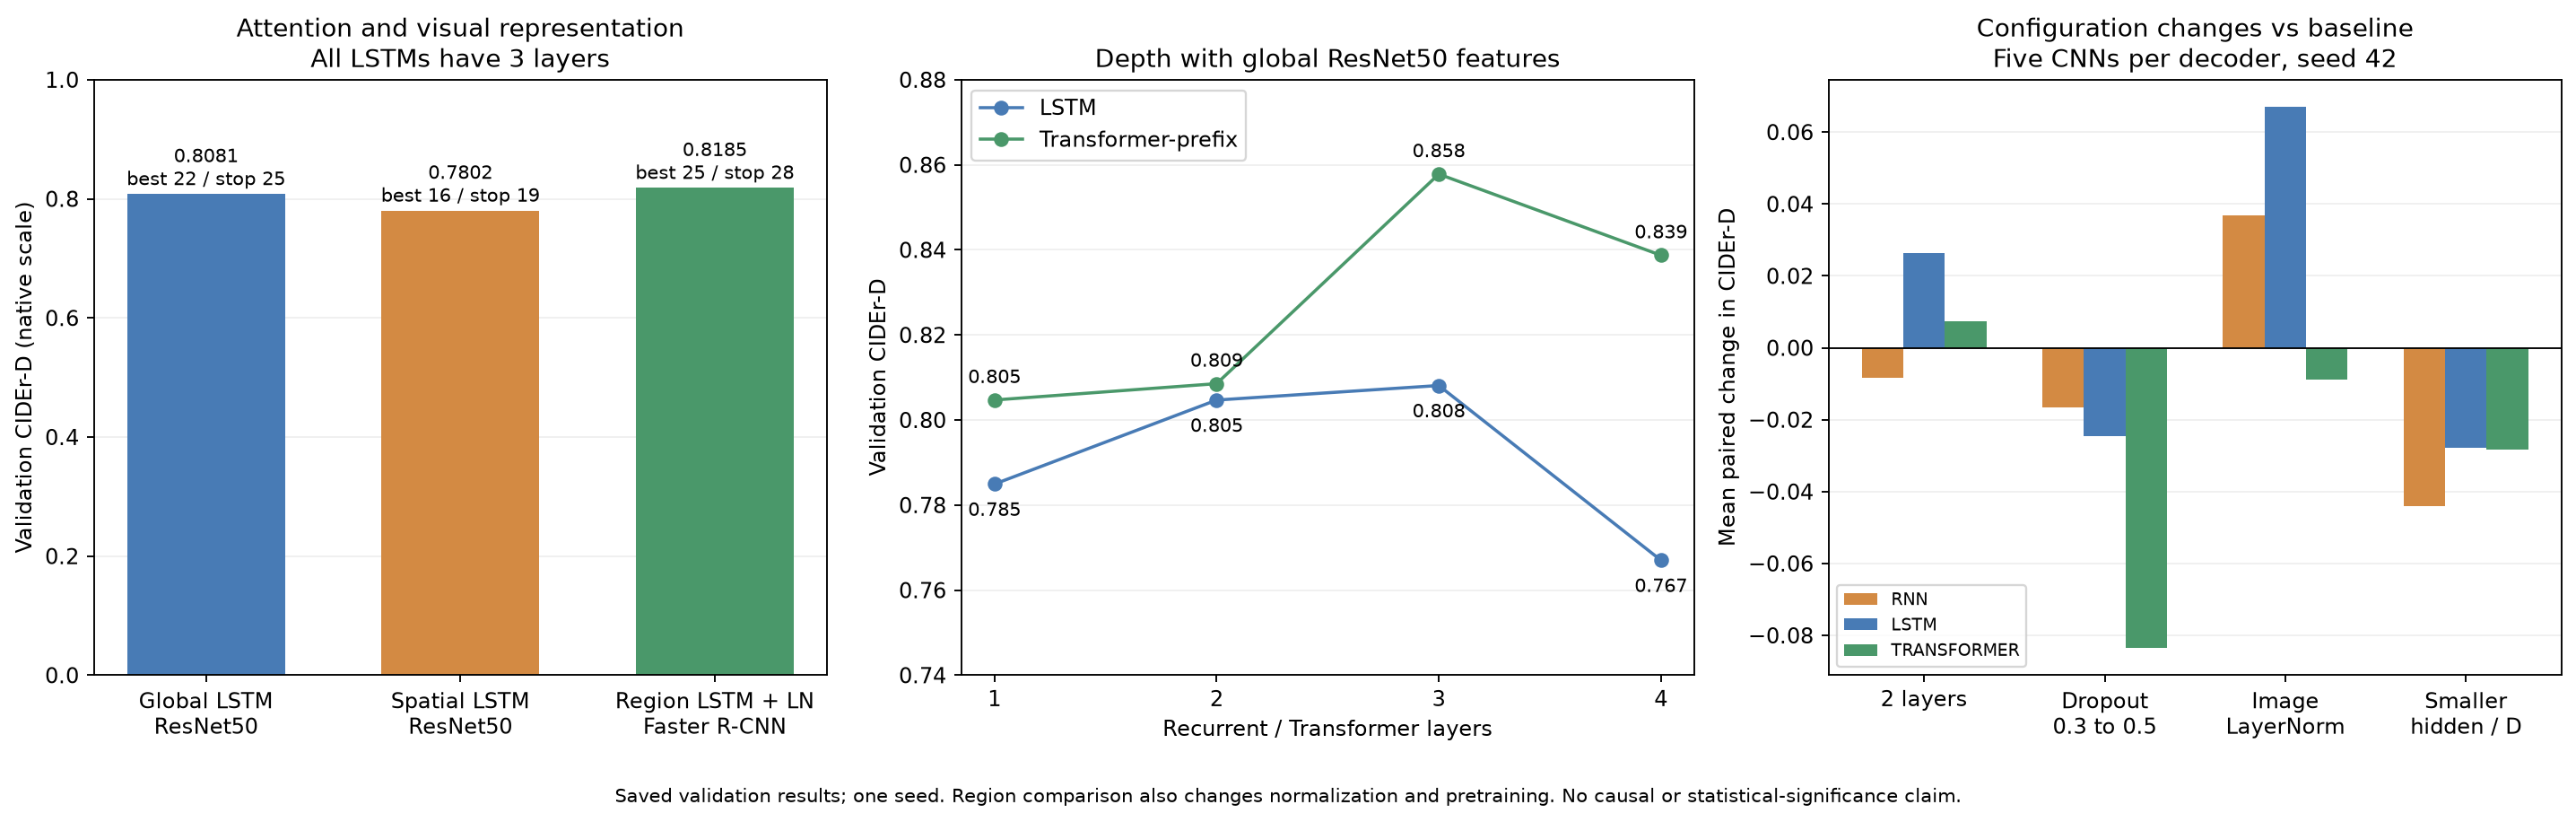